# Labo 4 : classifieurs linéaires et descente de gradient

IFT3395 / IFT6390A · mardi 27 octobre 2026, 14 h 30 à 16 h 30, salle 1140

### Ce notebook se lit comme un jeu de diapositives : une idée par cellule, en gros.

### Le code est caché ; vous pouvez l'ouvrir en cliquant sur « Afficher le code », mais ce n'est jamais obligatoire.

### Les icônes : 📖 un rappel de la notation en tête de section, 🔮 une prédiction à faire avant d'exécuter une cellule ou de bouger un curseur, 📊 comment lire une figure, 🌸 nos trois fleurs fil rouge A, B, C, 🧠 une réponse ou une vérification à cliquer, ↩️ une démo d'avant à rejouer avec un nouveau modèle, 🎨 le code couleur, ⏩ une cellule à lire chez soi (on la saute en séance).

### Chaque démo suit le même rituel : 📊 comment lire la figure, 🔮 une prédiction, la démo elle-même, puis 🧠 la réponse à cliquer.

### 🎨 Le code couleur du labo, le même dans toutes les figures.

<table width="100%">
<tr><th align="left" width="30%">couleur</th><th align="left" width="70%">ce qu'elle désigne</th></tr>
<tr><td valign="top"><font color="#2563eb">■</font> bleu</td><td valign="top">la classe $+1$ (versicolor) et la région où le classifieur prédit $+1$</td></tr>
<tr><td valign="top"><font color="#16a34a">■</font> vert</td><td valign="top">la classe $-1$ (setosa) et la région où il prédit $-1$</td></tr>
<tr><td valign="top"><font color="#dc2626">■</font> rouge</td><td valign="top">la frontière (trait plein) ; un cercle rouge vide entoure une fleur mal classée (une croix rouge la remplace quand il y a beaucoup de points : démos P, R, S, D, H)</td></tr>
<tr><td valign="top"><font color="#111827">■</font> noir</td><td valign="top">le vecteur $w$ (flèche) ; en tireté, les bords de la bande de marge du SVM</td></tr>
<tr><td valign="top"><font color="#6b7280">■</font> gris tireté</td><td valign="top">la frontière de départ, avant l'entraînement</td></tr>
<tr><td valign="top"><font color="#f5b400">■</font> or</td><td valign="top">le minimum, la cible (une étoile)</td></tr>
<tr><td valign="top"><font color="#111827">■</font> noir, <font color="#9333ea">■</font> violet, <font color="#ea580c">■</font> orange, <font color="#c026d3">■</font> magenta, <font color="#0891b2">■</font> sarcelle</td><td valign="top">les cinq pertes : erreur 0-1, régression linéaire, perceptron, SVM, logistique ; un classifieur entraîné prend la couleur de sa perte</td></tr>
</table>

Les fleurs d'entraînement sont des ronds pleins, les fleurs de test des triangles ; les points jouets des démos P, A et R sont des ronds ($y = +1$) et des carrés ($y = -1$).

### Exécutez d'abord la cellule de code ci-dessous (Exécution, puis Tout exécuter fonctionne aussi).

In [1]:
#@title Boîte à outils et code des démos. Exécutez cette cellule en premier, pas besoin de la lire. { display-mode: "form" }
import sys  # pour savoir si on tourne dans Colab
import os  # pour vérifier si un fichier existe sur le disque
import numpy as np  # calcul sur des tableaux
import matplotlib as mpl  # réglages globaux de matplotlib
import matplotlib.patheffects  # halo blanc derrière certains textes
import matplotlib.pyplot as plt  # figures
import ipywidgets as widgets  # curseurs et menus des démos
from IPython.display import display, clear_output, HTML  # affichage des panneaux, rafraîchissement, HTML
# les figures s'affichent directement sous les cellules
%matplotlib inline

np.set_printoptions(precision=2, suppress=True)  # tableaux affichés avec 2 décimales, sans notation scientifique
plt.rcParams.update({'font.size': 13, 'axes.titlesize': 14, 'axes.labelsize': 14, 'xtick.labelsize': 12,
                     'ytick.labelsize': 12, 'legend.fontsize': 12.5, 'figure.dpi': 100, 'figure.autolayout': False,
                     'mathtext.fontset': 'cm', 'axes.grid': False})  # grandes polices ; mise en page gérée figure par figure (constrained)
np.random.seed(2)  # graine fixée : tout le monde obtient exactement les mêmes résultats
IN_COLAB = 'google.colab' in sys.modules  # vrai si le notebook tourne dans Colab

# ----- Couleurs (les mêmes dans toutes les figures du labo) -----
BLEU = '#2563eb'  # classe y = +1 (versicolor)
VERT = '#16a34a'  # classe y = -1 (setosa)
ROUGE = '#dc2626'  # frontière de décision et fleurs mal classées
GRIS = '#6b7280'  # éléments secondaires (frontière initiale, repères)
NOIR = '#111827'  # vecteur w, texte
OR = '#f5b400'  # minimum, cible
VIOLET = '#9333ea'  # perte de la régression linéaire
ORANGE = '#ea580c'  # perte du perceptron
MAGENTA = '#c026d3'  # perte charnière (SVM) : un magenta franc, loin du rouge de la frontière
SARCELLE = '#0891b2'  # perte logistique
COULEURS_PERTES = {'erreur 0-1': 'black', 'régression linéaire': VIOLET, 'perceptron': ORANGE,
                   'SVM (charnière)': MAGENTA, 'logistique': SARCELLE}  # une couleur fixe par perte, dans toutes les figures
COULEURS_MODELES = {'LinearRegression': VIOLET, 'Perceptron': ORANGE, 'SVM': MAGENTA, 'LogisticRegression': SARCELLE}  # idem, par classe Python

# ----- Étiquettes d'axes (mathtext : la même notation que le texte) -----
ETIQ_X0 = '$x_0$ : longueur du pétale (std)'  # axe horizontal des figures de fleurs
ETIQ_X1 = '$x_1$ : largeur du pétale (std)'  # axe vertical des figures de fleurs
ETIQ_M = r'marge $m = y\,z$'  # axe horizontal des figures de pertes
ETIQ_PERTE = "perte d'une fleur $\\ell(m)$"  # axe vertical des figures de pertes
ETIQ_PENTE = "pente $\\ell'(m)$"  # axe vertical des figures de pentes
ETIQ_L = 'objectif $L(w)$'  # axe vertical des courbes d'apprentissage
ETIQ_T = 'itération $t$'  # axe horizontal des courbes d'apprentissage
ETIQ_FRONTIERE = 'frontière $w^\\top x = 0$'  # légende de la frontière (après l'astuce du 1)
ETIQ_FRONTIERE_B = 'frontière $w^\\top x + b = 0$'  # légende de la frontière avant l'astuce du 1 (section 0)
ETIQ_MARGE = 'bords de la bande de marge $w^\\top x = \\pm 1$'  # légende des bords de la bande de marge


def fmt_w(w, nom='w'):
    """Écrit w = (w0, w1, b) en mathtext avec deux décimales (pour un titre de figure)."""
    return f'${nom} = ({w[0]:.2f},\\ {w[1]:.2f},\\ {w[2]:.2f})$'  # chaîne mathtext


def txt_w(w, nom='w'):
    """Écrit w = (w0, w1, b) en texte brut avec deux décimales (pour les impressions sous les figures), sans « -0.00 »."""
    v = [0.0 if abs(float(t)) < 5e-3 else float(t) for t in w]  # pas de zéro négatif
    return f'{nom} = ({v[0]:.2f}, {v[1]:.2f}, {v[2]:.2f})'  # chaîne


def sigma(a):
    """Sigmoïde 1 / (1 + e^{-a}), calculée sans débordement."""
    return np.exp(-np.logaddexp(0, -a))  # = exp(-log(1 + e^{-a}))


# ----- Les cinq pertes et leurs pentes, en fonction de la marge m = y z (utilisées dans tout le labo) -----
PERTES = {
    'erreur 0-1': lambda m: (m < 0).astype(float),  # 1 si mal classé, 0 sinon
    'régression linéaire': lambda m: 0.5 * (m - 1) ** 2,  # 1/2 (m - 1)^2, égale à 1/2 (z - y)^2
    'perceptron': lambda m: np.maximum(0, -m),  # max(0, -m)
    'SVM (charnière)': lambda m: np.maximum(0, 1 - m),  # max(0, 1 - m)
    'logistique': lambda m: np.logaddexp(0, -m),  # log(1 + e^{-m}), calculé sans débordement
}
# Le scalaire l'(m) de chaque perte (dérivée par rapport à m) : le « coef » du code
COEFS = {
    'régression linéaire': lambda m: m - 1,  # dérivée de 1/2 (m - 1)^2
    'perceptron': lambda m: -(m < 0).astype(float),  # -1 pour les erreurs, 0 sinon
    'SVM (charnière)': lambda m: -(m < 1).astype(float),  # -1 si m < 1, 0 sinon
    'logistique': lambda m: -np.exp(-np.logaddexp(0, m)),  # -1 / (1 + e^m) = -sigma(-m)
}
FORMULES_PERTES = {'erreur 0-1': r'$\mathbb{1}\{m < 0\}$', 'régression linéaire': r'$\frac{1}{2}(m - 1)^2$',
                   'perceptron': r'$\max(0, -m)$', 'SVM (charnière)': r'$\max(0, 1 - m)$', 'logistique': r'$\log(1 + e^{-m})$'}  # pour les légendes
FORMULES_PENTES = {'régression linéaire': r'$m - 1$', 'perceptron': r'$-\mathbb{1}\{m < 0\}$',
                   'SVM (charnière)': r'$-\mathbb{1}\{m < 1\}$', 'logistique': r'$-1 / (1 + e^{m})$'}  # pour les légendes

# ----- Dix points jouets (démos A, P, R) : cinq de la classe +1, cinq de la classe -1 ; le dernier de chaque classe est « mal placé » -----
X_jouet = np.array([[1.2, 0.9], [2.0, 0.3], [0.5, 1.6], [1.7, 1.4], [-0.3, 0.9],
                    [-1.1, -0.7], [-1.8, 0.2], [-0.4, -1.5], [-1.5, -1.2], [0.6, -0.4]])  # coordonnées (x0, x1)
y_jouet = np.array([1, 1, 1, 1, 1, -1, -1, -1, -1, -1])  # étiquettes


# ----- Mise en page : figures à panneaux, légendes qui n'écrasent pas les panneaux -----
def figure(ncols=1, figsize=None, width_ratios=None, projections=None, nrows=1):
    """Crée une figure en mise en page « constrained » (rien ne se chevauche, les légendes extérieures ont leur place).
    Renvoie (fig, axes) ; axes est un seul objet si nrows * ncols = 1, sinon une liste (ligne par ligne).
    projections : liste (une entrée par panneau) de None ou '3d'."""
    if figsize is None:  # taille par défaut selon le nombre de panneaux
        figsize = {1: (7.5, 6), 2: (13, 5.2), 3: (16, 5), 4: (18, 5.2)}.get(ncols, (4.5 * ncols, 5)) if nrows == 1 else (13, 4.6 * nrows)
    fig = plt.figure(figsize=figsize, layout='constrained')  # mise en page automatique sans chevauchement
    gs = fig.add_gridspec(nrows, ncols, width_ratios=width_ratios)  # grille de panneaux
    axes = []  # panneaux créés
    for r in range(nrows):  # chaque ligne
        for c in range(ncols):  # chaque colonne
            k = r * ncols + c  # numéro du panneau
            proj = projections[k] if projections else None  # projection demandée
            axes.append(fig.add_subplot(gs[r, c], projection=proj) if proj else fig.add_subplot(gs[r, c]))  # panneau
    return fig, (axes[0] if len(axes) == 1 else axes)  # un seul panneau : on le renvoie directement


def legende(fig, axes=None, ncol=None, ou='bas', **kw):
    """Légende commune placée HORS des panneaux (en bas par défaut, ou 'droite'), sans les rapetisser.
    Rassemble les entrées de tous les panneaux donnés (ou de toute la figure) en supprimant les doublons."""
    axes = fig.axes if axes is None else (axes if isinstance(axes, (list, tuple)) else [axes])  # panneaux concernés
    poignees, noms = [], []  # entrées de légende
    for ax in axes:  # chaque panneau
        h, n = ax.get_legend_handles_labels()  # ses entrées
        for hh, nn in zip(h, n):  # chaque entrée
            if nn not in noms:  # pas de doublon
                poignees.append(hh); noms.append(nn)  # on garde
    if not poignees:  # rien à montrer
        return None
    if ou == 'droite':  # légende à droite
        return fig.legend(poignees, noms, loc='outside center right', frameon=False, **kw)  # colonne à droite
    return fig.legend(poignees, noms, loc='outside lower center', ncol=ncol or min(4, len(noms)), frameon=False, **kw)  # ligne(s) en bas


def boite(ax, texte, xy, couleur=GRIS, fond='white', taille=12.5, ha='center', va='center', coins=0.3, lw=1.5, zorder=10, **kw):
    """Écrit un texte dans une boîte à coins arrondis (schémas et annotations), en coordonnées des données."""
    return ax.text(xy[0], xy[1], texte, ha=ha, va=va, fontsize=taille, zorder=zorder,
                   bbox=dict(boxstyle=f'round,pad=0.5,rounding_size={coins}', fc=fond, ec=couleur, lw=lw), **kw)  # le texte encadré


def fleche(ax, depart, arrivee, couleur=NOIR, lw=2.5, style='->', ls='-', zorder=8, **kw):
    """Flèche entre deux points (coordonnées des données)."""
    return ax.annotate('', xy=arrivee, xytext=depart, zorder=zorder,
                       arrowprops=dict(arrowstyle=style, lw=lw, color=couleur, ls=ls, shrinkA=0, shrinkB=0), **kw)  # la flèche


def fleche_w(ax, w, longueur=1.0, couleur=NOIR, etiquette='$w$', lw=2.5):
    """Dessine w comme une flèche de longueur fixe posée sur la frontière (au point le plus proche de l'origine),
    perpendiculaire à celle-ci, pointant vers la région prédite +1."""
    norme = np.linalg.norm(w[:2])  # longueur de (w0, w1)
    if norme < 1e-9:  # w nul : pas de direction
        return
    pied = -w[2] * w[:2] / norme ** 2  # point de la frontière le plus proche de l'origine
    bout = pied + longueur * w[:2] / norme  # extrémité de la flèche
    fleche(ax, pied, bout, couleur=couleur, lw=lw)  # la flèche
    perp = np.array([-w[1], w[0]]) / norme  # direction perpendiculaire à la flèche, pour décaler l'étiquette
    ax.annotate(etiquette, xy=pied + 0.55 * (bout - pied), xytext=11 * perp, textcoords='offset points', fontsize=14, weight='bold',
                color=couleur, ha='center', va='center', zorder=9,
                path_effects=[mpl.patheffects.withStroke(linewidth=3, foreground='white')])  # son nom, à côté du milieu de la flèche (halo blanc, pas de boîte)


def preparer_axe_marge(ax, ylim=(-0.3, 4.5), titre='', ylabel=None, marge_svm=True):
    """Axe « perte en fonction de la marge » commun aux sections 2, 3 et 4 : zone m < 0 rosée, frontière m = 0 tiretée, bord m = 1 pointillé."""
    ax.axvspan(-10, 0, color=ROUGE, alpha=.06, zorder=0)  # zone « mal classée »
    ax.axvline(0, c=GRIS, ls='--', lw=1.2, zorder=1)  # m = 0 : la frontière
    if marge_svm:  # m = 1 : le bord de la marge (utile dès la perte charnière)
        ax.axvline(1, c=GRIS, ls=':', lw=1.2, zorder=1)  # bord de marge
    ax.axhline(0, c='black', lw=.8, zorder=1)  # perte nulle
    ax.set_xlim(-3, 3)  # cadre horizontal
    ax.set_ylim(*ylim)  # cadre vertical
    ax.set_xlabel(ETIQ_M)  # axe horizontal
    ax.set_ylabel(ETIQ_PERTE if ylabel is None else ylabel)  # axe vertical
    ax.set_title(titre)  # titre
    ax.grid(alpha=.3)  # grille légère


def panneau(fonction, **controles):
    """Affiche des contrôles (curseurs, menus) au-dessus d'une figure qui se redessine à chaque changement.
    Remplace @interact, dont les curseurs disparaissent au premier déplacement dans Colab."""
    for controle in controles.values():  # pour chaque curseur ou menu
        controle.style = {'description_width': '300px'}  # assez de place pour lire l'étiquette en entier
        controle.layout = widgets.Layout(width='700px')  # curseur long, donc plus précis
        controle.continuous_update = False  # on redessine au relâchement de la souris (plus fluide dans Colab)
    sortie = widgets.interactive_output(fonction, controles)  # zone où la figure est redessinée
    display(widgets.VBox(list(controles.values()) + [sortie]))  # les contrôles empilés, puis la figure


# ----- Cadre commun des figures de données (calculé à la demande, à partir de trainset et testset) -----
LIM = GX0 = GX1 = GRILLE = X_tr = y_tr = None  # remplis par _preparer_cadre
_cadre_pour = None  # identifiant du trainset pour lequel le cadre a été calculé


def _preparer_cadre():
    """Cadre carré commun, grille pour colorier les régions, et X_tr, y_tr (entrées et étiquettes d'entraînement)."""
    global LIM, GX0, GX1, GRILLE, X_tr, y_tr, _cadre_pour  # variables partagées par toutes les fonctions de dessin
    if _cadre_pour == id(trainset):  # déjà calculé pour ces données
        return  # rien à faire
    tout = np.vstack([trainset, testset])  # toutes les fleurs
    bas, haut = tout[:, :2].min() - 0.6, tout[:, :2].max() + 0.6  # bornes avec une petite marge
    LIM = (bas, haut)  # même cadre pour toutes les figures
    g = np.linspace(bas, haut, 250)  # grille régulière
    GX0, GX1 = np.meshgrid(g, g)  # coordonnées de la grille
    GRILLE = np.column_stack([GX0.ravel(), GX1.ravel(), np.ones(GX0.size)])  # points de grille avec la colonne de biais
    X_tr, y_tr = trainset[:, :-1], trainset[:, -1]  # entrées (avec le 1) et étiquettes d'entraînement
    _cadre_pour = id(trainset)  # mémorise pour quelles données

def dessiner_donnees(ax, theset, marker='o', suffixe='', taille=40, alpha=.8, noms=None):
    """Points d'un ensemble sur le panneau ax (noms : dict {1: ..., -1: ...} des espèces ; par défaut NOMS)."""
    noms = NOMS if noms is None else noms  # étiquettes de légende
    for etiquette, couleur in [(1, BLEU), (-1, VERT)]:  # les deux classes
        d = theset[theset[:, -1] == etiquette]  # exemples de cette classe
        ax.scatter(d[:, 0], d[:, 1], c=couleur, marker=marker, s=taille, alpha=alpha,
                   edgecolors=None if marker in ('x', '+') else 'white', linewidths=.5, label=noms[etiquette] + suffixe)  # nuage (contour blanc seulement pour les marqueurs pleins)


def segment_dans_cadre(w, xlim, ylim):
    """Les deux extrémités du segment de la droite w0 x0 + w1 x1 + b = 0 contenu dans le rectangle xlim × ylim
    (None si la droite ne le traverse pas). Sert aux panneaux 3D et aux vues de dessus."""
    a, b, c = float(w[0]), float(w[1]), float(w[2])  # coefficients
    pts = []  # intersections candidates avec les quatre bords
    if abs(b) > 1e-12:  # bords verticaux x0 = xlim
        for x0 in xlim:
            x1 = -(c + a * x0) / b
            if ylim[0] - 1e-9 <= x1 <= ylim[1] + 1e-9:
                pts.append((x0, x1))
    if abs(a) > 1e-12:  # bords horizontaux x1 = ylim
        for x1 in ylim:
            x0 = -(c + b * x1) / a
            if xlim[0] - 1e-9 <= x0 <= xlim[1] + 1e-9:
                pts.append((x0, x1))
    uniques = []  # on enlève les doublons (coins)
    for q in pts:
        if all(abs(q[0] - u[0]) > 1e-9 or abs(q[1] - u[1]) > 1e-9 for u in uniques):
            uniques.append(q)
    return (uniques[0], uniques[1]) if len(uniques) >= 2 else None  # deux extrémités


def courbes_apprentissage(ax, pertes, erreurs, t=None, titre="courbes d'apprentissage"):
    """Panneau standard : objectif L(w) (noir, axe gauche) et erreur d'entraînement en % (gris pointillé, axe droit),
    une par itération, avec un point sur chaque courbe à l'itération t. Renvoie l'axe droit."""
    pertes, erreurs = np.asarray(pertes, dtype=float), np.asarray(erreurs, dtype=float)  # tableaux
    it = np.arange(1, len(pertes) + 1)  # itérations 1..T (après chaque mise à jour)
    ax.plot(it, pertes, c=NOIR, lw=2.2, label='objectif $L(w^{(t)})$')  # perte
    ax.set_xlabel(ETIQ_T); ax.set_ylabel(ETIQ_L); ax.grid(alpha=.3); ax.set_title(titre)  # habillage
    axb = ax.twinx()  # axe de droite
    axb.plot(it, 100 * erreurs, c=GRIS, lw=2, ls=':', label="erreur d'entraînement (%)")  # erreur
    axb.set_ylabel("erreur d'entraînement (%)", color=GRIS)  # étiquette
    axb.set_ylim(-2, max(5.0, 1.25 * 100 * np.nanmax(erreurs)) if np.isfinite(erreurs).any() else 100)  # échelle adaptée
    if t is not None and 1 <= t <= len(pertes):  # repère de l'itération courante
        ax.plot(t, pertes[t - 1], 'o', c=NOIR, ms=8, zorder=5); axb.plot(t, 100 * erreurs[t - 1], 'o', c=GRIS, ms=8, zorder=5)  # points
        ax.axvline(t, c=GRIS, ls=':', lw=1)  # repère vertical
    return axb  # pour la légende


def dessiner_droite(ax, w, niveau=0.0, **style):
    """Trace la droite w0 x0 + w1 x1 + b = niveau (niveau 0 : frontière ; +1 et -1 : bords de la marge)."""
    _preparer_cadre()  # LIM doit être à jour
    if abs(w[1]) > 1e-12:  # cas général
        xx = np.array(LIM)  # extrémités du cadre
        ax.plot(xx, (niveau - w[2] - w[0] * xx) / w[1], **style)  # x1 en fonction de x0
    elif abs(w[0]) > 1e-12:  # droite verticale
        ax.axvline((niveau - w[2]) / w[0], **style)  # x0 constant


def dessiner_regions(ax, w, alpha=.10):
    """Colorie en bleu la région prédite +1 et en vert la région prédite -1."""
    _preparer_cadre()  # GRILLE doit être à jour
    z = (GRILLE @ w).reshape(GX0.shape)  # score sur toute la grille
    ax.contourf(GX0, GX1, z, levels=[-1e9, 0, 1e9], colors=[VERT, BLEU], alpha=alpha)  # deux couleurs pâles


def preparer_axes(ax, titre):
    """Cadre, repère orthonormé, noms d'axes et titre."""
    _preparer_cadre()  # LIM doit être à jour
    ax.set_xlim(LIM)  # cadre horizontal
    ax.set_ylim(LIM)  # cadre vertical
    ax.set_aspect('equal')  # repère orthonormé : les angles droits restent droits
    ax.set_xlabel(ETIQ_X0)  # axe horizontal
    ax.set_ylabel(ETIQ_X1)  # axe vertical
    ax.set_title(titre, fontsize=14)  # titre
    ax.grid(alpha=.3)  # grille légère

# ----- Vérifications -----

MODELES = {}  # les modèles entraînés par test_model, rangés par nom de classe

def verifier_gradient(modelclass, reg=0.1, eps=1e-6):
    """Compare model.gradient à des différences finies centrées calculées avec model.loss."""
    rng = np.random.RandomState(0)  # générateur local : ne dérange pas la graine globale
    X, y = trainset[:, :-1], trainset[:, -1]  # données d'entraînement
    model = modelclass(rng.randn(3), reg)  # poids tirés au hasard (pour éviter les cas particuliers)
    analytique = model.gradient(X, y)  # votre gradient
    if analytique is None or model.loss(X, y) is None:  # méthodes pas encore écrites
        print(f'{modelclass.__name__} : loss ou gradient renvoie None, rien à vérifier.')  # message
        return  # fin
    analytique = np.asarray(analytique, dtype=float)  # en tableau de réels
    numerique = np.zeros(3)  # gradient approché, coordonnée par coordonnée
    w = model.w.copy()  # point où l'on vérifie
    for j in range(3):  # pour chaque coordonnée de w
        e = np.zeros(3)  # vecteur de base e_j
        e[j] = eps  # petit déplacement dans la direction j
        model.w = w + e  # un peu à droite
        L_plus = model.loss(X, y)  # perte à droite
        model.w = w - e  # un peu à gauche
        L_moins = model.loss(X, y)  # perte à gauche
        numerique[j] = (L_plus - L_moins) / (2 * eps)  # pente centrée
    model.w = w  # on remet les poids
    ecart = np.linalg.norm(analytique - numerique) / max(1e-12, np.linalg.norm(analytique) + np.linalg.norm(numerique))  # écart relatif
    print(f'{modelclass.__name__} | gradient (votre code) : {analytique} | différences finies : {numerique} | écart relatif : {ecart:.1e}')  # comparaison
    print('  => gradient correct ✅' if ecart < 1e-4 else '  => PROBLÈME : le gradient ne correspond pas à la perte ❌')  # verdict


def pret(modelclass):
    """Vrai si la classe existe et si predict, loss, gradient et train donnent des valeurs utilisables."""
    try:  # n'importe quelle erreur veut dire « pas prêt »
        X, y = trainset[:, :-1], trainset[:, -1]  # données d'entraînement
        m = modelclass([0.5, -0.5, 0.1], 0.1)  # petit modèle d'essai
        z, L, g = m.predict(X), m.loss(X, y), m.gradient(X, y)  # les trois méthodes
        ok = (np.shape(z) == (len(y),) and np.any(z != 0) and L is not None and np.isfinite(L)
              and g is not None and np.shape(g) == (3,) and np.all(np.isfinite(g)))  # formes et valeurs sensées
        w_avant = m.w.copy()  # poids avant un pas d'entraînement
        m.train(trainset, 0.1, 1, verbose=False)  # un seul pas
        return bool(ok and not np.allclose(m.w, w_avant))  # train doit avoir bougé w
    except Exception:  # classe absente, méthode incomplète, erreur de forme...
        return False  # pas prêt


NOMS_MODELES = {'LinearRegression': 'régression linéaire', 'Perceptron': 'perceptron',
                'SVM': 'SVM', 'LogisticRegression': 'régression logistique'}  # noms affichés dans les menus
REGLAGES = {'LinearRegression': (0.1, 0.2), 'Perceptron': (0.0, 1.0),
            'SVM': (0.1, 1.0), 'LogisticRegression': (0.1, 0.2)}  # (reg, stepsize) utilisés par les tests officiels


def modeles_prets(noms=tuple(NOMS_MODELES)):
    """Dictionnaire {nom affiché: classe} des classes déjà écrites et fonctionnelles."""
    prets = {}  # résultat
    for nom in noms:  # chaque classe attendue
        classe = globals().get(nom)  # la classe, si elle a été définie dans le notebook
        if classe is not None and pret(classe):  # existe et fonctionne
            prets[NOMS_MODELES[nom]] = classe  # on l'ajoute au menu
    return prets  # dictionnaire, éventuellement vide


def entrainer(classe, n_steps=100, w0=(-3.0, 3.0, 0.1), reg=None, stepsize=None, data=None):
    """Entraîne une classe en silence avec les réglages des tests officiels ; renvoie (modèle, pertes, erreurs)."""
    reg_def, eta_def = REGLAGES[classe.__name__]  # réglages par défaut de cette classe
    model = classe(list(w0), reg_def if reg is None else reg)  # nouveau modèle
    data = trainset if data is None else data  # données d'entraînement par défaut
    pertes, erreurs = model.train(data, eta_def if stepsize is None else stepsize, n_steps, verbose=False)  # entraînement silencieux
    return model, pertes.astype(float), erreurs.astype(float)  # tout ce qu'il faut pour tracer


PAIRES = ['setosa (-1) contre versicolor (+1)', 'versicolor (-1) contre virginica (+1)']  # les deux problèmes proposés (démos I et F)
NOMS_PAIRES = {PAIRES[0]: {-1: 'setosa (y = -1)', 1: 'versicolor (y = +1)'},
               PAIRES[1]: {-1: 'versicolor (y = -1)', 1: 'virginica (y = +1)'}}  # noms des espèces de chaque paire (pour les légendes)


def noms_paire(paire):
    """Dict {1: nom, -1: nom} des espèces de la paire choisie (pour dessiner_donnees(..., noms=...))."""
    return NOMS_PAIRES[paire]


def paire_iris(paire):
    """Découpage train/test pour la paire d'espèces choisie (même graine que le reste du labo)."""
    etat = np.random.get_state()  # on sauvegarde l'état du générateur global
    np.random.seed(2)  # même graine que plus haut
    especes = [1, 2] if paire.startswith('setosa') else [2, 3]  # étiquettes du fichier
    tr, te = preprocess(iris, label_subset=especes, feature_subset=[2, 3], n_train=75)  # découpage
    np.random.set_state(etat)  # on remet le générateur comme avant
    return tr, te  # deux ensembles


from matplotlib.animation import FuncAnimation  # images successives d'une animation
from IPython.display import HTML  # lecteur d'animation intégré au notebook (bouton lecture, vitesse)
import matplotlib as mpl  # réglages globaux
mpl.rcParams['animation.embed_limit'] = 80  # Mo autorisés pour une animation intégrée (défaut : 20)

# ----- Outils 3D communs -----
from mpl_toolkits.mplot3d import Axes3D  # active les axes 3D de matplotlib
from mpl_toolkits.mplot3d.art3d import Line3DCollection  # paquets de segments 3D (les tiges)

gj = np.linspace(-3, 3, 200)  # grille pour colorier les régions des points jouets (vue de dessus)
GXJ0, GXJ1 = np.meshgrid(gj, gj)  # coordonnées
GRILLE_J = np.column_stack([GXJ0.ravel(), GXJ1.ravel(), np.ones(GXJ0.size)])  # avec la colonne de biais
gp = np.linspace(-2.6, 2.6, 27)  # grille (plus grossière) pour le plan incliné en 3D
GP0, GP1 = np.meshgrid(gp, gp)  # coordonnées du plan


def plan_incline(ax, X, y, w, zlim=4.0, titre='', cadre=2.6, marqueur_moins='o'):
    """Dessine en 3D le plan z = w0 x0 + w1 x1 + b au-dessus des points, le sol z = 0, la frontière au sol et la flèche w."""
    ax.clear()  # on redessine
    ax.computed_zorder = False  # on contrôle l'ordre de dessin : surface d'abord, points ensuite
    Z = w[0] * GP0 + w[1] * GP1 + w[2]  # hauteur du plan sur la grille
    Zm = np.where(np.abs(Z) <= zlim, Z, np.nan)  # on MASQUE ce qui dépasse du cadre (pas d'écrêtage : le plan reste un plan)
    couleurs = np.where(Z[..., None] >= 0, mpl.colors.to_rgba(BLEU, .28), mpl.colors.to_rgba(VERT, .28))  # bleu au-dessus du sol, vert en dessous
    ax.plot_surface(GP0, GP1, np.zeros_like(GP0), color='lightgray', alpha=.18, linewidth=0, shade=False, zorder=1)  # le sol z = 0
    ax.plot_surface(GP0, GP1, Zm, facecolors=couleurs, rstride=1, cstride=1, linewidth=0, edgecolor='none', antialiased=False, shade=False, zorder=2)  # le plan incliné
    seg = segment_dans_cadre(w, (-cadre, cadre), (-cadre, cadre))  # la frontière : intersection du plan et du sol, coupée au cadre
    if seg is not None:  # on trace toujours le segment visible
        ax.plot([seg[0][0], seg[1][0]], [seg[0][1], seg[1][1]], [0, 0], c=ROUGE, lw=3, zorder=6)  # frontière au sol
    norme = np.linalg.norm(w[:2])  # longueur de (w0, w1)
    if norme > 1e-9:  # la flèche w posée au sol, perpendiculaire à la frontière
        pied = -w[2] * w[:2] / norme ** 2  # point de la frontière le plus proche de l'origine
        if np.all(np.abs(pied) <= cadre):  # seulement si le pied est dans le cadre
            ax.quiver(pied[0], pied[1], 0, w[0] / norme, w[1] / norme, 0, color=NOIR, lw=2.5, arrow_length_ratio=.25, zorder=7)  # flèche de longueur 1
            ax.text(pied[0] + 1.15 * w[0] / norme, pied[1] + 1.15 * w[1] / norme, 0.05, '$w$', fontsize=13, weight='bold', zorder=8)  # étiquette
    z = X[:, :2] @ w[:2] + w[2]  # score de chaque point
    zc = np.clip(z, -zlim, zlim)  # dans le cadre (pour les tiges et les points)
    faux = y * z < 0  # mal classés
    for k, (xi, zi) in enumerate(zip(X, zc)):  # une tige verticale par point, dans la couleur de sa classe
        ax.plot([xi[0], xi[0]], [xi[1], xi[1]], [0, zi], c=(BLEU if y[k] > 0 else VERT), lw=1.4, ls=':', zorder=3)  # tige
    ax.scatter(X[:, 0], X[:, 1], np.zeros(len(X)), c='gray', s=16, depthshade=False, zorder=4)  # ombre de chaque point sur le sol
    for etiquette, couleur, mk in [(1, BLEU, 'o'), (-1, VERT, marqueur_moins)]:  # points soulevés à leur score
        d = y == etiquette  # cette classe
        ax.scatter(X[d, 0], X[d, 1], zc[d], c=couleur, marker=mk, s=80, edgecolors='black', linewidths=.8, depthshade=False, zorder=9)  # points
    ax.scatter(X[faux, 0], X[faux, 1], zc[faux], c=ROUGE, marker='x', s=150, linewidths=3, depthshade=False, zorder=10)  # croix rouges
    ax.set_xlim(-cadre, cadre); ax.set_ylim(-cadre, cadre); ax.set_zlim(-zlim, zlim)  # cadre
    ax.set_xlabel('$x_0$'); ax.set_ylabel('$x_1$'); ax.set_zlabel('score $z$')  # axes
    ax.view_init(elev=24, azim=-58)  # point de vue fixe
    ax.set_title(titre, fontsize=12.5)  # titre
    return z


def vue_de_dessus(ax, X, y, w, titre='', fleche=True, cadre=3.0, etiquette_frontiere=None, marqueur_moins='o', legende_fleche=False):
    """La même scène vue d'en haut : régions colorées, frontière, points et flèche w."""
    ax.clear()  # on redessine
    ax.contourf(GXJ0, GXJ1, (GRILLE_J @ w).reshape(GXJ0.shape), levels=[-1e9, 0, 1e9], colors=[VERT, BLEU], alpha=.12)  # régions
    for etiquette, couleur, mk, nom in [(1, BLEU, 'o', 'classe $y = +1$'), (-1, VERT, marqueur_moins, 'classe $y = -1$')]:  # les deux classes
        d = X[y == etiquette]  # points
        ax.scatter(d[:, 0], d[:, 1], c=couleur, marker=mk, s=70, edgecolors='white', zorder=5, label=nom)  # points
    z = X[:, :2] @ w[:2] + w[2]  # scores
    faux = y * z < 0  # mal classés
    if faux.any():  # croix rouges seulement s'il y en a (pas d'entrée de légende fantôme)
        ax.scatter(X[faux, 0], X[faux, 1], c=ROUGE, marker='x', s=110, linewidths=2.5, zorder=6, label='mal classé')  # croix rouges
    seg = segment_dans_cadre(w, (-cadre, cadre), (-cadre, cadre))  # frontière coupée au cadre
    if seg is not None:  # frontière
        ax.plot([seg[0][0], seg[1][0]], [seg[0][1], seg[1][1]], c=ROUGE, lw=2.5, label=etiquette_frontiere or 'frontière $z = 0$', zorder=4)  # droite
    if fleche:  # flèche w, posée sur la frontière, au point le plus proche de l'origine
        fleche_w(ax, w)  # helper commun (longueur 1, étiquette décalée)
        if legende_fleche:  # entrée de légende pour la flèche
            ax.plot([], [], c=NOIR, lw=2.5, label='flèche $w$ (perpendiculaire à la frontière)')  # entrée fantôme
    ax.set_xlim(-cadre, cadre); ax.set_ylim(-cadre, cadre); ax.set_aspect('equal'); ax.grid(alpha=.3)  # cadre
    ax.set_xlabel('$x_0$'); ax.set_ylabel('$x_1$')  # axes
    ax.set_title(titre, fontsize=12.5)  # titre
    return z


def sonde_perte(sonde, t, traj):
    """Perte du modèle de travail aux poids de l'itération t."""
    sonde.w = traj[t]  # poids à t
    return sonde.loss(X_tr, y_tr)  # perte à t


# ----- Scènes 3D interactives (Plotly) : l'étudiant fait tourner la scène à la souris une fois les curseurs réglés -----
import plotly.graph_objects as go  # figures 3D interactives


def camera_plotly(elev=24, azim=-58, r=2.0):
    """Point de vue initial d'une scène Plotly, donné comme dans matplotlib (élévation et azimut en degrés)."""
    e, a = np.deg2rad(elev), np.deg2rad(azim)  # en radians
    return dict(eye=dict(x=r * np.cos(e) * np.cos(a), y=r * np.cos(e) * np.sin(a), z=r * np.sin(e)), up=dict(x=0, y=0, z=1))  # œil et verticale


def scene_plotly(titre='', xlim=(-2.6, 2.6), ylim=(-2.6, 2.6), zlim=(-4, 4), etiquettes=('x₀', 'x₁', 'score z'), aspect=(1, 1, 0.8),
                 elev=24, azim=-58, largeur=780, hauteur=540):
    """Figure Plotly vide avec la mise en page commune des scènes 3D : cadre fixe, étiquettes d'axes, point de vue initial, légende en bas.
    Les textes sont en Unicode ou en HTML léger (<sub>, <sup>, <b>) : Plotly ne compose pas le LaTeX dans Colab."""
    fig = go.Figure()  # figure vide
    fig.update_layout(title=dict(text=titre, x=0.5, xanchor='center', font=dict(size=15)), width=largeur, height=hauteur, autosize=False,
                      margin=dict(l=0, r=0, t=60, b=0), paper_bgcolor='white', font=dict(family='DejaVu Sans, Arial, sans-serif', size=12),
                      legend=dict(orientation='h', yanchor='top', y=-0.01, xanchor='center', x=0.5, font=dict(size=12)),
                      scene=dict(xaxis=dict(title=etiquettes[0], range=list(xlim)), yaxis=dict(title=etiquettes[1], range=list(ylim)),
                                 zaxis=dict(title=etiquettes[2], range=list(zlim)), aspectmode='manual',
                                 aspectratio=dict(x=aspect[0], y=aspect[1], z=aspect[2]), camera=camera_plotly(elev, azim)))  # mise en page
    return fig  # à compléter avec fig.add_trace(...)


# ----- Démos 3D interactives : Plotly.js et curseurs en JavaScript, directement dans la sortie de la cellule -----
# Dans Colab, le widget « Output » d'ipywidgets n'exécute pas de JavaScript : une figure Plotly affichée à l'intérieur
# d'interactive_output reste vide. Les démos 3D sont donc des pages HTML autonomes : les données viennent de Python
# (converties en JSON), les curseurs et le dessin sont en JavaScript, et Plotly.react garde la caméra d'un réglage à l'autre.
import json  # données Python -> JSON pour le JavaScript
import uuid  # un identifiant par démo affichée

PLOTLY_JS_URL = 'https://cdn.plot.ly/plotly-2.35.2.min.js'  # plotly.js (la même version que celle que Colab charge)

JS_COMMUN = r"""
var L4 = window.L4 || (function(){  // helpers partagés par les démos (une seule fois par page)
  var C = {BLEU:'#2563eb', VERT:'#16a34a', ROUGE:'#dc2626', GRIS:'#6b7280', NOIR:'#111827', OR:'#f5b400', VIOLET:'#9333ea',
           ORANGE:'#ea580c', MAGENTA:'#c026d3', SARCELLE:'#0891b2', SOL:'#d1d5db'};  // la palette de 00_common.py
  var POLICE = 'font:13px "DejaVu Sans",Arial,sans-serif;';  // police des contrôles
  function el(tag, attrs, parent){  // crée un élément HTML avec ses attributs (text, html, style ou attribut)
    var e = document.createElement(tag);
    for (var k in (attrs || {})){ if (k === 'text') e.textContent = attrs[k]; else if (k === 'html') e.innerHTML = attrs[k];
      else if (k === 'style') e.style.cssText = attrs[k]; else e.setAttribute(k, attrs[k]); }
    if (parent) parent.appendChild(e);
    return e;
  }
  function ligne(root, label){  // une ligne « étiquette : contrôle »
    var l = el('div', {style:'display:flex;align-items:center;gap:10px;margin:3px 0;' + POLICE}, root);
    el('span', {text:label, style:'width:300px;text-align:right;flex:none'}, l);
    return l;
  }
  function curseur(root, o){  // o = {label, min, max, step, value, format(v), onchange(v)} ; renvoie l'input
    var l = ligne(root, o.label);
    var inp = el('input', {type:'range', min:o.min, max:o.max, step:o.step, value:o.value, style:'width:420px;flex:none'}, l);
    var val = el('span', {text:(o.format || String)(o.value), style:'min-width:80px'}, l);
    inp.addEventListener('input', function(){ val.textContent = (o.format || String)(+inp.value); if (o.onchange) o.onchange(+inp.value); });
    inp.lire = function(){ return +inp.value; };
    return inp;
  }
  function menu(root, o){  // o = {label, options:[...], value, onchange(v)} ; renvoie le select
    var l = ligne(root, o.label);
    var sel = el('select', {style:'min-width:220px;' + POLICE}, l);
    o.options.forEach(function(v){ var op = el('option', {value:v, text:v}, sel); if (v === o.value) op.selected = true; });
    sel.addEventListener('change', function(){ if (o.onchange) o.onchange(sel.value); });
    sel.lire = function(){ return sel.value; };
    return sel;
  }
  function texte(root){ return el('pre', {style:'font:12.5px monospace;margin:6px 0 0 0;white-space:pre-wrap'}, root); }  // zone de résumé (remplace les print)
  function panneau(root, hauteur){ return el('div', {style:'width:100%;height:' + (hauteur || 560) + 'px'}, root); }  // la figure Plotly
  function dessiner(div, data, layout){  // (re)dessine en gardant le point de vue réglé par l'étudiant (uirevision)
    layout = layout || {}; layout.uirevision = 'garder'; if (layout.scene) layout.scene.uirevision = 'garder';
    return Plotly.react(div, data, layout, {responsive:true, displaylogo:false, modeBarButtonsToRemove:['select2d', 'lasso2d']});
  }
  function linspace(a, b, n){ var r = []; for (var i = 0; i < n; i++) r.push(a + (b - a) * i / (n - 1)); return r; }
  function plan(w, g, zlim){  // z = w0 x0 + w1 x1 + w2 sur la grille g x g (lignes = x1, colonnes = x0) ; NaN hors de ±zlim ; signe pour la couleur
    var z = [], s = [];
    for (var i = 0; i < g.length; i++){ var zi = [], si = [];
      for (var j = 0; j < g.length; j++){ var v = w[0] * g[j] + w[1] * g[i] + w[2]; zi.push(Math.abs(v) <= zlim ? v : NaN); si.push(v >= 0 ? 1 : 0); }
      z.push(zi); s.push(si); }
    return {z:z, signe:s};
  }
  function segmentDansCadre(w, xlim, ylim){  // les deux points où la droite w0 x0 + w1 x1 + w2 = 0 coupe le cadre (null si elle ne le traverse pas)
    var pts = [], eps = 1e-12;
    if (Math.abs(w[1]) > eps) [xlim[0], xlim[1]].forEach(function(x){ var y = -(w[0] * x + w[2]) / w[1]; if (y >= ylim[0] - 1e-9 && y <= ylim[1] + 1e-9) pts.push([x, y]); });
    if (Math.abs(w[0]) > eps) [ylim[0], ylim[1]].forEach(function(y){ var x = -(w[1] * y + w[2]) / w[0]; if (x >= xlim[0] - 1e-9 && x <= xlim[1] + 1e-9) pts.push([x, y]); });
    var u = []; pts.forEach(function(p){ if (!u.some(function(q){ return Math.abs(q[0] - p[0]) < 1e-6 && Math.abs(q[1] - p[1]) < 1e-6; })) u.push(p); });
    return u.length >= 2 ? [u[0], u[1]] : null;
  }
  function pied(w){ var n2 = w[0] * w[0] + w[1] * w[1]; return n2 > 1e-18 ? [-w[2] * w[0] / n2, -w[2] * w[1] / n2] : null; }  // point de la frontière le plus proche de l'origine
  function demiPlan(w, cadre, signe){  // sommets du polygone du cadre [-cadre, cadre]^2 où signe * (w0 x0 + w1 x1 + w2) >= 0 (pour fill = 'toself')
    var coins = [[-cadre, -cadre], [cadre, -cadre], [cadre, cadre], [-cadre, cadre]], poly = [];
    for (var k = 0; k < 4; k++){ var a = coins[k], b = coins[(k + 1) % 4];
      var fa = signe * (w[0] * a[0] + w[1] * a[1] + w[2]), fb = signe * (w[0] * b[0] + w[1] * b[1] + w[2]);
      if (fa >= 0) poly.push(a);
      if ((fa >= 0) !== (fb >= 0)){ var t = fa / (fa - fb); poly.push([a[0] + t * (b[0] - a[0]), a[1] + t * (b[1] - a[1])]); } }
    return poly;
  }
  function fmt(x, d){ return (x >= 0 ? '+' : '') + (+x).toFixed(d === undefined ? 2 : d); }  // nombre signé à d décimales
  return {C:C, el:el, curseur:curseur, menu:menu, texte:texte, panneau:panneau, dessiner:dessiner, linspace:linspace, plan:plan,
          segmentDansCadre:segmentDansCadre, pied:pied, demiPlan:demiPlan, fmt:fmt};
})();
window.L4 = L4;
"""


def _json_js(obj):
    """Convertit (récursivement) tableaux numpy, nombres numpy et NaN en un littéral JavaScript (les flottants arrondis à 4 décimales)."""
    def conv(o):  # conversion récursive
        if isinstance(o, np.ndarray): return conv(o.tolist())
        if isinstance(o, (bool, np.bool_)): return bool(o)
        if isinstance(o, (int, np.integer)): return int(o)
        if isinstance(o, (float, np.floating)): return round(float(o), 4) if np.isfinite(o) else float(o)  # NaN/inf restent (valides en JS)
        if isinstance(o, dict): return {str(k): conv(v) for k, v in o.items()}
        if isinstance(o, (list, tuple)): return [conv(v) for v in o]
        return o
    return json.dumps(conv(obj), ensure_ascii=False)  # NaN -> NaN, inf -> Infinity : littéraux JavaScript valides


def _afficher_html(html):
    """Affiche un bloc HTML (séparé pour que les outils de rendu puissent capturer le HTML)."""
    display(HTML(html))  # sortie HTML de la cellule : Colab y exécute les scripts


def afficher_demo_js(js, donnees):
    """Affiche une démo interactive : conteneur HTML, données Python (D) et code JavaScript qui reçoit (root, D, Plotly, L4).
    plotly.js est chargé depuis le CDN si la page ne l'a pas déjà (en neutralisant require.js, qui l'enregistrerait comme module)."""
    ident = 'lab4-' + uuid.uuid4().hex[:8]  # identifiant unique du conteneur
    html = f'''<div id="{ident}" class="lab4-demo" style="width:100%"></div>
<script>
(function(){{
  var root = document.getElementById("{ident}");
  var D = {_json_js(donnees)};
  function go(){{ {JS_COMMUN}
    (function(root, D, Plotly, L4){{ {js} }})(root, D, window.Plotly, window.L4); }}
  if (window.Plotly) {{ go(); }} else {{
    var d = window.define; window.define = undefined;
    var s = document.createElement("script"); s.src = "{PLOTLY_JS_URL}";
    s.onload = function(){{ window.define = d; go(); }};
    document.head.appendChild(s);
  }}
}})();
</script>'''  # le JS de la démo tourne dans une fermeture : root, D, Plotly, L4
    _afficher_html(html)  # affichage


# ----- Fil rouge : trois fleurs qu'on suit du début à la fin -----
FLEURS_ABC = np.array([[1.6, 1.2, 1.0, 1], [-1.3, -0.9, 1.0, -1], [-1.6, 1.3, 1.0, 1]])  # A, B, C : (x0, x1, 1, y), comme sur la figure de la section 0
NOMS_ABC = ['A', 'B', 'C']  # leurs noms
W_MAIN = np.array([1.0, 1.0, -0.4])  # le w « à la main » de la section 0


def tableau_abc(w=W_MAIN):
    """Score et marge des trois fleurs pour un w donné."""
    print(f'w = (w₀, w₁, b) = ({w[0]:.2f}, {w[1]:.2f}, {w[2]:.2f})')  # rappel du w
    print(f"{'fleur':6s}{'x₀':>7s}{'x₁':>7s}{'y':>5s}{'score z':>10s}{'marge m':>10s}   verdict  (z = w⊤x, m = y z)")  # en-tête
    for nom, f in zip(NOMS_ABC, FLEURS_ABC):  # chaque fleur
        z = f[:3] @ w  # score
        m = f[3] * z  # marge
        verdict = 'bien classée' if m > 0 else 'MAL classée'  # lecture
        print(f'{nom:6s}{f[0]:7.1f}{f[1]:7.1f}{int(f[3]):+5d}{z:10.2f}{m:10.2f}   {verdict}')  # une ligne par fleur


def tableau_pertes_abc(w=W_MAIN):
    """Les quatre pertes (et l'erreur 0-1) de chacune des trois fleurs."""
    print(f'w = (w₀, w₁, b) = ({w[0]:.2f}, {w[1]:.2f}, {w[2]:.2f})   perte ℓ(m) de chaque fleur, selon la perte choisie')  # rappel
    print(f"{'fleur':6s}{'marge m':>9s}" + ''.join(f'{nom:>22s}' for nom in PERTES))  # en-tête
    for nom, f in zip(NOMS_ABC, FLEURS_ABC):  # chaque fleur
        m = f[3] * (f[:3] @ w)  # marge
        print(f'{nom:6s}{m:9.2f}' + ''.join(f'{float(PERTES[p](np.array(m))):22.3f}' for p in PERTES))  # une ligne
    print("Lecture : ℓ(m) = 0 veut dire « cette fleur ne coûte rien à cette perte ».")  # aide


def _z(v):
    """Évite d'afficher -0.00."""
    return 0.0 if abs(v) < 5e-3 else float(v)


def tableau_poussees_abc(w=W_MAIN):
    """La poussée ℓ'(m) y et le gradient ℓ'(m) y x de chaque fleur, pour chaque perte (équation (4))."""
    print(f'w = (w₀, w₁, b) = ({w[0]:.2f}, {w[1]:.2f}, {w[2]:.2f})   gradient d\'une fleur (4) : ∇_w ℓ = ℓ\'(m) y x   (un nombre, fois x)')  # rappel
    for p, coef in COEFS.items():  # chaque perte
        print(f'\n{p}')  # titre
        print(f"{'fleur':6s}{'m':>7s}{'ℓ(m)':>9s}{'ℓ\'(m)':>9s}{'ℓ\'(m) y':>10s}   ℓ'(m) y x = gradient de la fleur, composantes (w₀, w₁, b)")  # en-tête
        for nom, f in zip(NOMS_ABC, FLEURS_ABC):  # chaque fleur
            m = f[3] * (f[:3] @ w)  # marge
            c = float(coef(np.array(m)))  # l'(m)
            g = c * f[3] * f[:3]  # gradient de cette fleur seule
            print(f'{nom:6s}{m:7.2f}{float(PERTES[p](np.array(m))):9.3f}{_z(c):9.2f}{_z(c * f[3]):10.2f}   ({_z(g[0]):+.2f}, {_z(g[1]):+.2f}, {_z(g[2]):+.2f})')  # une ligne
    print("\nLecture : la descente (6) fait w ← w − η · (moyenne de ces vecteurs + λ w). Un vecteur nul = une fleur qui ne pousse pas.")  # aide


def dessiner_abc(ax, w=W_MAIN):
    """Place A, B, C sur un panneau, avec le w donné."""
    for nom, f in zip(NOMS_ABC, FLEURS_ABC):  # chaque fleur
        couleur = BLEU if f[3] > 0 else VERT  # couleur de la vraie classe
        ax.scatter(f[0], f[1], s=160, c=couleur, edgecolors='black', zorder=5)  # le point
        ax.annotate(nom, (f[0], f[1]), xytext=(8, 8), textcoords='offset points', fontsize=15, weight='bold')  # étiquette
        if f[3] * (f[:3] @ w) < 0:  # mal classée
            ax.scatter(f[0], f[1], s=420, facecolors='none', edgecolors=ROUGE, lw=2, zorder=4)  # cercle rouge


# ===== Démo A : l'erreur 0-1 est en escalier =====
ECHELLE_A = 1.5  # r = ||(w0, w1)|| : la longueur de w dans cette démo (fixée ; seul l'angle theta bouge)

thetas_A = np.linspace(0, 360, 721)  # angles testés pour tracer les courbes (pas de 0.5 degré)
PERTES_A = ['erreur 0-1', 'SVM (charnière)', 'logistique']  # la courbe noire, puis les deux pertes de remplacement (section 3)
NOMS_A = {'erreur 0-1': "taux d'erreur $\\mathrm{Err}(w)$", 'SVM (charnière)': 'perte charnière du SVM (section 3)',
          'logistique': 'perte logistique (section 3)'}  # noms dans la légende


def w_A(theta_deg):
    """w = r (cos theta, sin theta), avec r = 1.5 et b = 0 : la frontière passe par l'origine."""
    t = np.radians(theta_deg)  # angle en radians
    return ECHELLE_A * np.array([np.cos(t), np.sin(t)])  # (w0, w1)


def moyennes_jouet(theta_deg):
    """Taux d'erreur Err(w), charnière moyenne et logistique moyenne sur les dix points, pour w = 1.5 (cos theta, sin theta)."""
    m = y_jouet * (X_jouet @ w_A(theta_deg))  # marges m_i = y_i w^\top x_i des dix points
    return [PERTES[nom](m).mean() for nom in PERTES_A]  # trois moyennes (1/10) sum_i l(m_i)


courbes_A = np.array([moyennes_jouet(t) for t in thetas_A])  # tableau (721, 3), calculé une seule fois

# Les angles où une prédiction bascule (un saut de l'escalier) : w perpendiculaire à x_i, soit theta = angle(x_i) +- 90°
SAUTS_A = np.sort(np.concatenate([(np.degrees(np.arctan2(X_jouet[:, 1], X_jouet[:, 0])) + d) % 360 for d in (90, -90)]))  # 20 angles


def _palier_A(theta):
    """Les deux sauts qui encadrent theta (bornes du palier courant), ou None si theta est à moins de 0.5° d'un saut."""
    ecart = np.abs((SAUTS_A - theta + 180) % 360 - 180)  # distance angulaire à chaque saut
    if ecart.min() <= 0.5:  # theta tombe sur un saut
        return None  # pas de palier
    avant = SAUTS_A[SAUTS_A < theta]  # sauts à gauche
    apres = SAUTS_A[SAUTS_A > theta]  # sauts à droite
    return (avant.max() if len(avant) else SAUTS_A.max() - 360), (apres.min() if len(apres) else SAUTS_A.min() + 360)  # bornes


def _demo_A(theta, lisses):  # appelée à chaque changement d'un contrôle du panneau
    w = w_A(theta)  # poids courants (w0, w1), b = 0
    m = y_jouet * (X_jouet @ w)  # marges des dix points
    faux = m < 0  # points mal classés
    fig, (ax0, ax1) = figure(2, width_ratios=[1, 1.4])  # deux panneaux : les points à gauche, les courbes à droite
    # Panneau de gauche : les points, la frontière qui tourne, la flèche w
    ax0.scatter(*X_jouet[y_jouet > 0].T, c=BLEU, s=70, edgecolors='white', zorder=4, label='classe $y = +1$')  # ronds bleus
    ax0.scatter(*X_jouet[y_jouet < 0].T, c=VERT, s=70, marker='s', edgecolors='white', zorder=4, label='classe $y = -1$')  # carrés verts
    if faux.any():  # au moins un point du mauvais côté
        ax0.scatter(*X_jouet[faux].T, s=260, facecolors='none', edgecolors=ROUGE, lw=2, zorder=5, label='mal classé')  # cercles rouges vides
    direction = np.array([-w[1], w[0]]) / ECHELLE_A  # direction de la frontière (perpendiculaire à w)
    ax0.plot(*np.outer([-4, 4], direction).T, c=ROUGE, lw=2.5, zorder=3, label=ETIQ_FRONTIERE)  # la frontière passe par l'origine (b = 0)
    fleche_w(ax0, np.append(w, 0.0), longueur=ECHELLE_A)  # flèche w, de vraie longueur r = 1.5, posée à l'origine
    ax0.plot([], [], c=NOIR, lw=2.5, label='flèche $w$ (perpendiculaire)')  # entrée de légende pour la flèche
    ax0.set_xlim(-2.6, 2.6); ax0.set_ylim(-2.6, 2.6)  # cadre fixe
    ax0.set_aspect('equal')  # repère orthonormé : w paraît bien perpendiculaire à la frontière
    ax0.set_xlabel('$x_0$'); ax0.set_ylabel('$x_1$')  # axes (points jouets, sans unité)
    ax0.grid(alpha=.3)  # grille légère
    ax0.set_title(f'$\\theta$ = {theta:.0f}° : {int(faux.sum())} erreurs sur 10, $\\mathrm{{Err}}(w)$ = {faux.mean():.1f}')  # titre informatif
    # Panneau de droite : Err(w) en fonction de l'angle (et, si la case est cochée, deux pertes de remplacement)
    courant = moyennes_jouet(theta)  # les trois valeurs à l'angle courant
    for j, nom in enumerate(PERTES_A):  # une courbe par perte
        if j > 0 and not lisses:  # les pertes de remplacement ne s'affichent que si la case est cochée
            continue  # on saute
        ax1.plot(thetas_A, courbes_A[:, j], c=COULEURS_PERTES[nom], lw=3 if j == 0 else 2, zorder=4 - j, label=NOMS_A[nom])  # courbe complète
        ax1.plot(theta, courant[j], 'o', c=COULEURS_PERTES[nom], ms=9, zorder=6)  # point courant
    ax1.axvline(theta, c=GRIS, ls=':', zorder=2)  # repère vertical à l'angle courant
    ax1.vlines(SAUTS_A, -0.05 if not lisses else -0.1, 0.0, colors=GRIS, lw=1, zorder=2, label='angles où une prédiction bascule (sauts)')  # petits traits sous l'axe
    if not lisses:  # annotations de l'escalier (seulement quand il est seul : sinon elles chevauchent les courbes)
        boite(ax1, 'palier : pente 0', (70, 0.5), couleur=GRIS, taille=12)  # un palier (entre 56° et 84°, Err = 0)
        fleche(ax1, (70, 0.44), (70, 0.03), couleur=GRIS, lw=1.5)  # vers le palier
        ax1.annotate('saut : la pente\nn\'existe pas', xy=(198.5, 0.85), xytext=(185, 0.42), ha='center', va='center', fontsize=12, color=GRIS, zorder=10,
                     bbox=dict(boxstyle='round,pad=0.5,rounding_size=0.3', fc='white', ec=GRIS, lw=1.5), arrowprops=dict(arrowstyle='->', color=GRIS, lw=1.5))  # un saut
    ax1.set_xlabel('angle $\\theta$ de $w$ (degrés)')  # axe horizontal
    ax1.set_ylabel('perte moyenne $\\frac{1}{10}\\sum_i \\ell(m_i)$ sur les 10 points' if lisses else "taux d'erreur $\\mathrm{Err}(w)$")  # axe vertical
    ax1.set_xlim(0, 360); ax1.set_ylim(-0.1 if lisses else -0.05, 3.2 if lisses else 1.15)  # tout le tour ; cadre vertical selon les courbes
    ax1.set_xticks(range(0, 361, 60))  # graduations tous les 60°
    ax1.grid(alpha=.3)  # grille légère
    ax1.set_title("L'erreur 0-1 est un escalier : plate, puis un saut" if not lisses else 'Les pertes de remplacement ont une pente, pas l\'escalier')  # message principal
    legende(fig, ncol=4)  # légende commune, sous les panneaux
    plt.show()  # affiche la figure
    print(f'θ = {theta:.0f}° : w = (w0, w1) = 1.5 (cos θ, sin θ) = ({w[0]:+.2f}, {w[1]:+.2f}), b = 0 | Err(w) = {int(faux.sum())}/10 = {faux.mean():.1f}')  # état courant
    palier = _palier_A(theta)  # bornes du palier courant, ou None sur un saut
    if palier is None:  # theta est sur un saut
        print("θ est sur un saut de l'escalier (une prédiction bascule) : la pente de Err n'existe pas.")  # cas du saut
    else:  # sur un palier
        print(f'Palier de {palier[0]:.1f}° à {palier[1]:.1f}° : la pente de Err par rapport à θ vaut 0 exactement, la descente ne saurait pas où aller.')  # cas du palier
    if lisses:  # pentes des deux pertes de remplacement (différence centrée sur 1°)
        avant, apres = np.array(moyennes_jouet(theta - 0.5)), np.array(moyennes_jouet(theta + 0.5))  # valeurs juste avant et juste après
        pentes = apres - avant  # pente approchée (variation par degré)
        print(f'Pentes par degré en θ = {theta:.0f}° : charnière {pentes[1]:+.4f}, logistique {pentes[2]:+.4f} : elles disent dans quel sens tourner.')  # les deux pentes


def demo_A():
    """Démo A : l'erreur 0-1 est en escalier ; les pertes de remplacement (section 3) ont une pente."""
    _preparer_cadre()  # cadre, grille et X_tr, y_tr à partir des données courantes
    panneau(_demo_A, theta=widgets.FloatSlider(value=140, min=0, max=360, step=1, description='angle θ de w (degrés)'),
            lisses=widgets.Checkbox(value=False, description='montrer aussi deux pertes de remplacement (section 3)'))  # un curseur, une case à cocher


# ===== Démo B : perte et pente d'une seule fleur, selon sa marge m =====
mm_B = np.linspace(-3, 3, 1201)  # grille de marges pour tracer les courbes

def phrase_B(m):
    """Une phrase qui résume la situation de la fleur."""
    if m < 0:  # mal classée
        return 'm < 0 : fleur MAL classée. Les quatre pentes sont négatives : chaque perte voudrait une marge plus grande.'  # cas 1
    if m < 1:  # bien classée mais dans la bande de marge
        return '0 <= m < 1 : bien classée mais DANS la bande de marge. Le perceptron ne demande plus rien ; le SVM et la logistique voudraient encore une marge plus grande.'  # cas 2
    if m == 1:  # pile sur le bord de la bande
        return 'm = 1 : pile sur le bord de la bande de marge. La régression linéaire est satisfaite (0), le SVM aussi (0), la logistique paie encore 0.31.'  # cas 3
    return 'm > 1 : bien classée avec de la marge. Le SVM ne demande plus rien, la logistique presque plus, mais la régression linéaire a une pente POSITIVE : elle voudrait une marge plus PETITE.'  # cas 4


def _segments_B(ax, nom, coin):
    """Trace la pente d'une perte en escalier (perceptron : coin en 0 ; SVM : coin en 1) sans trait vertical au coin,
    avec un point plein (valeur 0, prise par le code) et un point vide (valeur -1, l'autre pente)."""
    coul = COULEURS_PERTES[nom]  # couleur de la perte
    style = dict(ls='--', lw=4) if nom == 'perceptron' else dict(ls='-', lw=2.4)  # le perceptron en tireté épais, sous le SVM
    ax.plot([-3, coin], [-1, -1], c=coul, zorder=3, label=f'{nom} : ' + FORMULES_PENTES[nom], **style)  # pente -1 avant le coin
    ax.plot([coin, 3], [0, 0], c=coul, zorder=3, **style)  # pente 0 après le coin
    ax.plot(coin, 0, 'o', c=coul, ms=8, mec='black', zorder=5)  # point plein : la valeur prise par le code au coin
    ax.plot(coin, -1, 'o', mfc='white', mec=coul, ms=8, mew=2, zorder=5)  # point vide : l'autre pente


def _demo_B(m):  # appelée à chaque changement d'un contrôle du panneau
    fig, (ax0, ax1) = figure(2)  # deux panneaux : la perte à gauche, sa pente à droite
    for nom, perte in PERTES.items():  # panneau de gauche : les cinq courbes de perte
        marche = nom == 'erreur 0-1'  # la marche est épaisse
        ax0.plot(mm_B, perte(mm_B), lw=4 if marche else 2.4, ls='--' if nom == 'perceptron' else '-', c=COULEURS_PERTES[nom], zorder=3,
                 label=('erreur 0-1 (la marche) : ' if marche else f'{nom} : ') + FORMULES_PERTES[nom])  # courbe
        ax0.plot(m, perte(np.array(m)), 'o', c=COULEURS_PERTES[nom], ms=9, mec='black', zorder=6)  # point courant
    preparer_axe_marge(ax0, titre='Ce que paie la fleur : $\\ell(m)$')  # cadre commun (zone m < 0, repères m = 0 et m = 1)
    ax1.plot([-3, 3], [0, 0], c='black', lw=2.5, zorder=3, label='erreur 0-1 : pente 0 partout (n\'existe pas en $m = 0$)')  # la marche a une pente nulle
    ax1.plot(0, 0, 'o', mfc='white', mec='black', ms=8, mew=2, zorder=5)  # point vide : pas de pente au saut
    ax1.plot(mm_B, COEFS['régression linéaire'](mm_B), lw=2.4, c=VIOLET, zorder=4, label='régression linéaire : ' + FORMULES_PENTES['régression linéaire'])  # pente m - 1
    _segments_B(ax1, 'perceptron', 0)  # pente du perceptron, coin en 0
    _segments_B(ax1, 'SVM (charnière)', 1)  # pente du SVM, coin en 1
    ax1.plot(mm_B, COEFS['logistique'](mm_B), lw=2.4, c=SARCELLE, zorder=4, label='logistique : ' + FORMULES_PENTES['logistique'])  # pente -sigma(-m)
    for nom, coef in COEFS.items():  # points courants sur les quatre pentes
        ax1.plot(m, coef(np.array(m)), 'o', c=COULEURS_PERTES[nom], ms=9, mec='black', zorder=6)  # point courant
    preparer_axe_marge(ax1, ylim=(-2.2, 2.2), titre='Sa pente $\\ell\'(m)$ (négative = voudrait une marge plus grande)', ylabel=ETIQ_PENTE)  # même cadre
    for ax in (ax0, ax1):  # repères communs aux deux panneaux
        ax.axvline(m, c=GRIS, ls=':', lw=1.5, zorder=2)  # la marge courante
        for nom_f, f in zip(NOMS_ABC, FLEURS_ABC):  # A, B, C du fil rouge (avec le w à la main)
            mf = float(f[3] * (f[:3] @ W_MAIN))  # leur marge
            ax.text(mf + {'A': -0.14, 'B': 0.14, 'C': 0.0}[nom_f], ax.get_ylim()[1] - 0.06 * (ax.get_ylim()[1] - ax.get_ylim()[0]), nom_f, color=BLEU if f[3] > 0 else VERT, ha='center', va='center', fontsize=11, weight='bold',
                    bbox=dict(boxstyle='circle,pad=0.2', fc='white', ec=ROUGE if mf < 0 else (BLEU if f[3] > 0 else VERT), lw=1.3))  # leur lettre, en haut
    legende(fig, ncol=4)  # légende commune, en bas
    plt.show()  # affiche
    pertes = {nom: float(PERTES[nom](np.array(m))) for nom in PERTES}  # les cinq pertes à cette marge
    pentes = {nom: float(COEFS[nom](np.array(m))) for nom in COEFS}  # les quatre pentes (+ 0.0 ci-dessous : pour ne pas afficher -0.00)
    print(f'm = {m:+.2f} | ℓ(m) : ' + ' ; '.join(f'{nom} {v:.2f}' for nom, v in pertes.items()))  # ligne 1 : les pertes
    print(f"           | ℓ'(m) : erreur 0-1 0 ; " + ' ; '.join(f'{nom} {v + 0.0:+.2f}' for nom, v in pentes.items()))  # ligne 2 : les pentes
    print(phrase_B(m))  # ligne 3 : interprétation


def demo_B():
    """Démo B : perte et pente d'une fleur selon sa marge m."""
    _preparer_cadre()  # cadre, grille et X_tr, y_tr à partir des données courantes
    panneau(_demo_B, m=widgets.FloatSlider(value=-1.0, min=-3, max=3, step=0.05, description='marge m = y z de la fleur'))  # un curseur


# ===== Démo C =====
def _s02_coupe_cadre(w, niveau):
    """Vrai si la droite w0 x0 + w1 x1 + b = niveau traverse le cadre carré LIM (sinon, inutile de la mettre dans la légende)."""
    coins = np.array([[LIM[0], LIM[0], 1], [LIM[0], LIM[1], 1], [LIM[1], LIM[0], 1], [LIM[1], LIM[1], 1]])  # les quatre coins du cadre
    valeurs = coins @ w - niveau  # signe de (w @ x - niveau) à chaque coin
    return bool(valeurs.min() < 0 < valeurs.max())  # la droite passe entre deux coins de signes opposés


def _demo_C(w_0, w_1, b, echelle):  # appelée à chaque changement d'un contrôle du panneau
    w = echelle * np.array([w_0, w_1, b])  # poids effectifs w = (w0, w1, b)
    z = X_tr @ w  # scores z_i = w @ x_i des 75 fleurs
    m = y_tr * z  # marges m_i = y_i z_i
    fig, (ax0, ax1) = figure(2, width_ratios=[1.15, 1])  # deux panneaux (mise en page constrained)
    dessiner_regions(ax0, w)  # régions prédites +1 (bleutée) et -1 (verdâtre)
    dessiner_donnees(ax0, trainset)  # les 75 fleurs d'entraînement
    ax0.scatter(*X_tr[m < 0, :2].T, s=200, facecolors='none', edgecolors=ROUGE, lw=2, label='fleur mal classée ($m < 0$)' if (m < 0).any() else None)  # cercle rouge vide (dans la légende seulement s'il y en a)
    dessiner_droite(ax0, w, 0, c=ROUGE, lw=2.5, label=ETIQ_FRONTIERE if _s02_coupe_cadre(w, 0) else None)  # frontière z = w @ x = 0
    dessiner_droite(ax0, w, 1, c=NOIR, ls='--', lw=1.2, label=ETIQ_MARGE if _s02_coupe_cadre(w, 1) or _s02_coupe_cadre(w, -1) else None)  # bord de la bande de marge côté +1
    dessiner_droite(ax0, w, -1, c=NOIR, ls='--', lw=1.2)  # bord de la bande de marge côté -1
    fleche_w(ax0, w)  # la flèche w (longueur 1 sur le dessin), posée sur la frontière
    dessiner_abc(ax0, w)  # les fleurs A, B, C du fil rouge, entourées de rouge si ce w les classe mal
    ax0.scatter([], [], s=160, c='white', edgecolors='black', label='fleurs A, B, C (fil rouge)')  # entrée de légende pour A, B, C
    norme = np.linalg.norm(w[:2])  # ||(w0, w1)|| : longueur réelle de la flèche
    preparer_axes(ax0, fmt_w(w) + f' : {100 * np.mean(m < 0):.0f} % d\'erreur')  # titre : w = (w0, w1, b) et taux d'erreur
    noms = list(PERTES)  # les cinq pertes
    valeurs = [PERTES[nom](m).mean() for nom in noms]  # perte moyenne (1/n) sum_i l(m_i) sur les 75 fleurs
    barres = ax1.barh(noms, valeurs, color=[COULEURS_PERTES[nom] for nom in noms])  # barres horizontales
    for barre, v in zip(barres, valeurs):  # étiquette numérique au bout de chaque barre
        if v > 3:  # barre plus longue que le cadre : on la tronque et on l'écrit dedans
            barre.set_width(3)  # tronquée au bord
            ax1.text(2.95, barre.get_y() + barre.get_height() / 2, f'{v:.3f} ▶', va='center', ha='right', color='white', weight='bold')  # valeur, à l'intérieur
        else:  # cas normal
            ax1.text(barre.get_width() + 0.05, barre.get_y() + barre.get_height() / 2, '0' if v == 0 else f'{v:.3f}', va='center')  # valeur, au bout
    ax1.set_xlim(0, 3)  # cadre horizontal fixe : les barres restent comparables d'un w à l'autre
    ax1.invert_yaxis()  # erreur 0-1 en haut
    ax1.set_xlabel('perte moyenne $\\frac{1}{n}\\sum_{i=1}^{n} \\ell(m_i)$ (sans régularisation)')  # axe
    ax1.set_title('Perte moyenne des 75 fleurs pour ce $w$,\nsans régularisation (définitions à la section 3)', fontsize=14)  # titre
    ax1.grid(alpha=.3, axis='x')  # grille verticale
    legende(fig, ax0, ncol=3)  # légende commune, en bas, hors du panneau
    plt.show()  # affiche
    z_abc = FLEURS_ABC[:, :3] @ w  # scores de A, B, C pour ce w
    print(f'{int((m < 0).sum())} fleurs mal classées sur {len(m)} (m_i < 0) ; 🌸 ' + ' ; '.join(f'{nom} : z = {zz:.2f}, m = {f[3] * zz:.2f}' for nom, zz, f in zip(NOMS_ABC, z_abc, FLEURS_ABC)))  # bilan et fil rouge
    if norme > 1e-9:  # distances seulement si (w0, w1) n'est pas nul
        i = int(np.argmin(np.abs(m)))  # la fleur dont le score est le plus petit en valeur absolue : la plus proche de la frontière
        dist = abs(m[i]) / norme  # sa distance à la frontière : |m_i| / ||(w0, w1)||
        cote = 'du mauvais côté' if m[i] < 0 else 'du bon côté'  # lecture en mots
        print(f'Fleur la plus proche de la frontière : à {dist:.2f} ({cote}), marge m = {m[i]:.2f}')  # distance et marge
        print(f'‖(w0, w1)‖ = {norme:.2f} (la flèche dessinée est normalisée à 1) ; w = (w0, w1, b) = ({w[0]:.2f}, {w[1]:.2f}, {w[2]:.2f})')  # norme réelle
    else:  # w0 = w1 = 0
        print(f'w0 = w1 = 0 : pas de frontière, le score vaut b = {w[2]:.2f} partout, tout est prédit {"+1" if w[2] >= 0 else "-1"}.')  # cas dégénéré


def demo_C():
    """Démo C : placer une frontière à la main."""
    _preparer_cadre()  # cadre, grille et X_tr, y_tr à partir des données courantes
    panneau(_demo_C,
            w_0=widgets.FloatSlider(value=1.0, min=-3, max=3, step=0.05, description='w₀ : poids de la longueur x₀'),
            w_1=widgets.FloatSlider(value=-1.0, min=-3, max=3, step=0.05, description='w₁ : poids de la largeur x₁'),
            b=widgets.FloatSlider(value=1.0, min=-3, max=3, step=0.05, description='w₂ = b : biais'),
            echelle=widgets.FloatSlider(value=1.0, min=0.1, max=3, step=0.05, description='échelle (multiplie w₀, w₁, b)'))  # quatre curseurs


# ===== Démo D : le tir à la corde en direct, rejouer l'entraînement une flèche par fleur (curseurs modèle, itération t) =====
_cache_D = {}  # entraînements et tractions déjà calculés (vidé à chaque appel de demo_D())


def _s07_tractions(classe, w):
    """Pour chaque fleur i, la traction -l'(m_i) y_i (x_i0, x_i1) (forme (n, 2)) et le signe de l'(m_i) (forme (n,))."""
    sonde = classe(w, 0.0)  # copie sans régularisation : gradient d'une fleur seule = l'(m_i) y_i x_i
    grads = np.array([sonde.gradient(X_tr[i:i + 1], y_tr[i:i + 1]) for i in range(len(y_tr))])  # (n, 3)
    pentes = grads[:, 2] * y_tr  # l'(m_i) = (l'(m_i) y_i x_i2) y_i, car x_i2 = 1 et y_i^2 = 1
    return -grads[:, :2], pentes  # tractions et pentes


def _demo_D(modele, t, prets=None):  # appelée à chaque changement d'un contrôle du panneau
    classe = (PRETS_D if prets is None else prets)[modele]  # la classe choisie
    if classe.__name__ not in _cache_D:  # premier passage pour ce modèle : on entraîne et on calcule toutes les tractions une fois
        model, pertes, erreurs = entrainer(classe)  # on entraîne une fois (réglages de la section)
        tout = [_s07_tractions(classe, wt) for wt in model.historique]  # (tractions, pentes) à chacune des 101 itérations
        force_max = max(np.linalg.norm(tr, axis=1).max() for tr, _ in tout)  # plus grande traction sur tout l'entraînement
        resultante_max = max(np.linalg.norm(tr.mean(axis=0)) for tr, _ in tout)  # plus grande résultante
        facteur = min([1, 2, 5, 10, 20, 50], key=lambda f: abs(f * resultante_max / max(force_max, 1e-9) - 1.7))  # facteur rond : la plus grande résultante mesure ~ 2 unités
        _cache_D[classe.__name__] = (model, pertes, erreurs, max(force_max, 1e-9), facteur, tout)  # résultats mémorisés
    model, pertes, erreurs, force_max, facteur, tout = _cache_D[classe.__name__]  # résultats mémorisés
    w = model.historique[t]  # w^(t)
    tractions, pentes = tout[t]  # une traction par fleur, à l'itération t
    m = y_tr * (X_tr @ w)  # marges à l'itération t
    actifs = np.linalg.norm(tractions, axis=1) > 1e-10  # fleurs qui tirent encore
    resultante = tractions.mean(axis=0)  # = -(1/n) somme des l'(m_i) y_i x_i = -grad L (sans lambda), deux premières composantes
    echelle = force_max / 1.2  # échelle FIXE par modèle : la plus grande traction mesure 1.2 unité du cadre
    fig, (ax0, ax1) = figure(2, figsize=(13, 5.6), width_ratios=[1.15, 1])  # fleurs, courbes
    dessiner_regions(ax0, w)  # régions
    dessiner_donnees(ax0, trainset, alpha=.55)  # fleurs (estompées, les flèches passent devant)
    q = None  # le dernier quiver tracé (pour l'étalon)
    for masque, couleur in [((pentes < 0) & actifs, GRIS), ((pentes > 0) & actifs, NOIR)]:  # tire la frontière vers elle (gris) / la repousse (noir), comme fig_tir_corde
        if masque.any():  # au moins une fleur dans ce cas
            q = ax0.quiver(X_tr[masque, 0], X_tr[masque, 1], tractions[masque, 0], tractions[masque, 1], color=couleur,
                           angles='xy', scale_units='xy', scale=echelle, width=.006, headwidth=4, alpha=.9, zorder=6)  # une flèche par fleur
    if q is not None:  # flèche-étalon dans un coin
        etalon = 1 if 1 / echelle >= 0.25 else (2 if 2 / echelle >= 0.25 else 5)  # « force 1 » si elle se voit, sinon 2 ou 5
        ax0.quiverkey(q, 0.86, 0.08, etalon, f'force {etalon}', labelpos='S', coordinates='axes', color=NOIR, fontproperties={'size': 11})  # étalon
    if (m < 0).any():  # croix rouges seulement s'il y a des erreurs
        ax0.scatter(*X_tr[m < 0, :2].T, marker='x', c=ROUGE, s=110, linewidths=2.5, zorder=7, label='mal classée')  # erreurs
    dessiner_droite(ax0, model.historique[0], 0, c=GRIS, ls='--', lw=1.5, label='frontière initiale', zorder=4)  # départ
    dessiner_droite(ax0, w, 0, c=ROUGE, lw=2.5, label=f'frontière à $t = {t}$', zorder=5)  # frontière courante
    norme = np.linalg.norm(w[:2])  # pour poser la résultante au pied de la frontière
    norme_res = np.linalg.norm(resultante)  # longueur de la résultante
    if norme > 1e-9 and norme_res > 1e-10:  # la résultante, OR épaisse, au pied de la frontière (comme la somme des tractions de la section 4)
        facteur = min([1, 2, 5, 10, 20, 50, 100], key=lambda f: abs(f * norme_res / echelle - 1.0))  # facteur rond choisi à chaque t : la flèche mesure environ 1 unité
        pied = -w[2] * w[:2] / norme ** 2  # point de la frontière le plus proche de l'origine
        fleche(ax0, pied, pied + facteur * resultante / echelle, couleur=OR, lw=4, zorder=9)  # agrandie d'un facteur rond (écrit dans la légende)
        ax0.plot([], [], c=OR, lw=4, label=f'somme des tractions : la direction de $-\\nabla_w L$ (sans $\\lambda$), agrandie $\\times {facteur}$')  # entrée de légende
    ax0.plot([], [], c=GRIS, lw=2, marker='>', label="traction d'une fleur $-\\ell'(m_i)\\,y_i\\,x_i$ : tire la frontière vers elle ($\\ell'(m_i) < 0$)")  # entrées de légende des flèches
    if (pentes > 0).any():  # seulement si une fleur repousse
        ax0.plot([], [], c=NOIR, lw=2, marker='>', label="en noir : la repousse ($\\ell'(m_i) > 0$)")  # idem
    preparer_axes(ax0, f'{modele}, $t = {t}$ : ' + fmt_w(w))  # titre
    courbes_apprentissage(ax1, pertes, erreurs, t)  # courbes d'apprentissage avec le point à t
    legende(fig, ncol=3)  # légende commune, sous les panneaux
    plt.show()  # affiche
    print(f't = {t} | erreur d\'entraînement = {100 * np.mean(m < 0):.1f} % | fleurs qui tirent encore : {int(actifs.sum())} sur {len(y_tr)} | ‖résultante‖ = {np.linalg.norm(resultante):.3f}')  # résumé


def demo_D():
    """Démo D : rejouer l'entraînement, une flèche par fleur."""
    global PRETS_D  # aussi partagé par variable globale (appels directs à _demo_D)
    _preparer_cadre()  # cadre, grille et X_tr, y_tr à partir des données courantes
    _cache_D.clear()  # on repart de zéro : une classe corrigée puis réexécutée est réentraînée
    PRETS_D = prets = modeles_prets()  # classes terminées à ce stade (menu reconstruit à chaque appel)
    if not prets:  # rien de prêt
        print('Aucune classe prête : exécutez la cellule « Code : LinearRegression » (section 6), puis réexécutez cette cellule.'); return
    _s07_message_modeles(prets, list(NOMS_MODELES))  # ce que contient le menu
    panneau(lambda modele, t: _demo_D(modele, t, prets), modele=widgets.Dropdown(options=list(prets), description='modèle'),
            t=widgets.IntSlider(value=5, min=0, max=100, step=1, description='itération t'))  # menu et curseur


# ===== Démo E : le pas eta, la même descente que la démo S vue d'en haut (curseurs modèle, pas eta) =====
def _demo_E(modele, eta, prets=None):  # appelée à chaque changement d'un contrôle du panneau
    classe = (PRETS_E if prets is None else prets)[modele]  # la classe choisie
    traj, biais, A0, A1, L, hauteurs, pertes, erreurs, t_div, w_etoile = _preparer_S(classe, eta)  # même cache que la démo S
    fin = t_div if t_div else len(pertes)  # dernière itération tracée (coupée à la divergence)
    it, Lt = np.arange(1, fin + 1), pertes[:fin]  # itérations 1..fin et leur objectif
    fig, (ax0, ax1) = figure(2, figsize=(13, 5.4), width_ratios=[1.1, 1])  # courbe de L, carte
    lineaire = Lt.max() / max(Lt.min(), 1e-12) < 10  # échelle linéaire si L varie de moins d'un facteur 10
    ax0.plot(it, Lt, c=NOIR, lw=2.2, label='objectif $L(w^{(t)})$')  # la courbe
    if not lineaire:  # échelle log lisible : repères majeurs seulement
        ax0.set_yscale('log'); ax0.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())  # pas de « 1.6 × 10⁰ »
        ax0.yaxis.set_major_locator(mpl.ticker.LogLocator(base=10, numticks=12)); ax0.yaxis.set_major_formatter(mpl.ticker.LogFormatterSciNotation(base=10))  # 10^k
    ax0.set_xlabel(ETIQ_T); ax0.set_ylabel('objectif $L(w^{(t)})$' + ('' if lineaire else ' (échelle log)')); ax0.grid(alpha=.3, which='major')  # axes
    ax0.set_xlim(0, 101)  # cadre horizontal commun
    if t_div:  # divergence : on l'écrit
        ax0.plot(it[-1], Lt[-1], 'o', c=ROUGE, ms=8, zorder=5)  # dernier point
        boite(ax0, f'divergence à $t = {t_div}$ :\n$L$ dépasse $10^3$, chaque itération\nsaute par-dessus le fond, plus loin', (0.72, 0.22), couleur=ROUGE, transform=ax0.transAxes)  # boîte, dans le coin libre
    if classe.__name__ == 'LinearRegression':  # seuil connu
        seuil = _s07_minimum_reglin(REGLAGES['LinearRegression'][0])[2]  # eta_max = 2 / mu_max
        ax0.set_title(f'$\\eta$ = {eta} ; divergence au-delà de $\\eta_{{\\max}} = 2/\\mu_{{\\max}} \\approx {seuil:.2f}$', fontsize=13, color=ROUGE if eta > seuil else NOIR)  # titre
    else:  # pas de seuil exact pour la logistique
        ax0.set_title(f'{modele}, $\\eta$ = {eta}', fontsize=13)  # titre
    with np.errstate(all='ignore'):  # log d'un objectif éventuellement énorme
        ax1.contour(A0, A1, np.log(L + 1e-9), levels=25, colors=GRIS, linewidths=.7, alpha=.8, linestyles='solid')  # lignes de niveau (de log L), uniformes, toutes pleines
    visibles = np.isfinite(traj[:, :2]).all(axis=1) & np.all(np.abs(traj[:, :2]) < 4, axis=1)  # points du trajet dans le cadre
    k_sortie = int(np.argmin(visibles)) if not visibles.all() else len(traj)  # premier point hors du cadre (le trajet s'arrête là, pas de segment fantôme)
    tv = traj[:k_sortie, :2]  # trajet jusqu'à la sortie
    ax1.plot(tv[:, 0], tv[:, 1], '-o', c=NOIR, ms=3, lw=1.2, label='trajet de $(w_0, w_1)$, un point par itération')  # trajet
    ax1.plot(*traj[0, :2], 's', c=GRIS, mec=NOIR, ms=9, label='départ $w^{(0)}$')  # point de départ
    if classe.__name__ == 'LinearRegression':  # on connaît le minimum exact
        ax1.plot(*w_etoile[:2], '*', c=OR, mec=NOIR, ms=18, label='$w^*$ (minimum exact)', zorder=6)  # cible
        if visibles[-1]:  # position finale
            ax1.plot(*traj[-1, :2], 'o', c=OR, mec=NOIR, ms=9, label='$w^{(100)}$ (après 100 itérations)', zorder=7)  # bille à l'arrivée
    elif visibles[-1]:  # logistique : pas de minimum exact, on marque l'arrivée
        ax1.plot(*traj[-1, :2], '*', c='white', mec=OR, mew=2.5, ms=18, label='$w^{(100)}$ (après 100 itérations)', zorder=7)  # étoile creuse
    if not visibles[-1]:  # le trajet sort du cadre
        k = int(np.argmin(visibles)) - 1  # dernier point visible
        if k >= 0:  # une flèche vers la sortie
            d = traj[k + 1, :2] - traj[k, :2]; d = d / max(np.linalg.norm(d), 1e-12)  # direction de sortie
            fleche(ax1, traj[k, :2], traj[k, :2] + 0.8 * d, couleur=ROUGE, lw=2)  # flèche
            boite(ax1, 'sort du cadre', traj[k, :2] + 1.1 * d, couleur=ROUGE, taille=11)  # étiquette
    ax1.set_xlim(-4, 4); ax1.set_ylim(-4, 4); ax1.set_aspect('equal')  # cadre et repère orthonormé
    ax1.set_xlabel('$w_0$'); ax1.set_ylabel('$w_1$')  # axes
    ax1.set_title(f'lignes de niveau de $L(w_0, w_1, b)$, $b = {biais:.2f}$ fixé', fontsize=13)  # titre
    legende(fig, ncol=3)  # légende commune, sous les panneaux
    plt.show()  # affiche
    if t_div:  # la perte a explosé
        seuil_txt = f' : η dépasse η_max = 2/μ_max ≈ {seuil:.2f}' if classe.__name__ == 'LinearRegression' else ''  # le seuil, s'il est connu
        print(f'η = {eta} : DIVERGENCE à t = {t_div} (L > 1000){seuil_txt} ; chaque itération dépasse le fond de plus en plus.')  # diagnostic
    elif classe.__name__ == 'LinearRegression':  # comparaison avec le minimum exact
        print(f'η = {eta} | w⁽¹⁰⁰⁾ = {_s07_txt_w(traj[-1])} | L(w⁽¹⁰⁰⁾) = {pertes[-1]:.4f} | erreur = {100 * erreurs[-1]:.0f} % | ‖w⁽¹⁰⁰⁾ − w*‖ = {np.linalg.norm(traj[-1] - w_etoile):.3f}')  # état
    else:  # logistique
        print(f'η = {eta} | w⁽¹⁰⁰⁾ = {_s07_txt_w(traj[-1])} | L(w⁽¹⁰⁰⁾) = {pertes[-1]:.4f} | erreur = {100 * erreurs[-1]:.0f} %')  # état


def demo_E():
    """Démo E : le pas eta, convergence et divergence (vue d'en haut)."""
    global H, SEUIL_ETA, W_ETOILE, PRETS_E  # valeurs partagées (la section 6 les cite)
    H, mu_max, SEUIL_ETA, W_ETOILE = _s07_minimum_reglin(REGLAGES['LinearRegression'][0])  # hessienne, seuil eta_max, minimum exact
    _cache_S.clear()  # on repart de zéro : une classe corrigée puis réexécutée est réentraînée
    PRETS_E = prets = modeles_prets(('LinearRegression', 'LogisticRegression'))  # les deux modèles lisses, s'ils sont prêts (menu reconstruit à chaque appel)
    if not prets:  # rien de prêt
        print('Aucune classe prête : exécutez la cellule « Code : LinearRegression » (section 6), puis réexécutez cette cellule.'); return
    _s07_message_modeles(prets, ['LinearRegression', 'LogisticRegression'])  # ce que contient le menu
    panneau(lambda modele, eta: _demo_E(modele, eta, prets), modele=widgets.Dropdown(options=list(prets), description='modèle'),
            eta=widgets.SelectionSlider(options=ETAS_07, value=0.2, description='pas η (le pas de (6))'))  # menu et curseur


# ===== Démo F : bilan des quatre méthodes =====
def _demo_F(paire, n_steps):  # appelée à chaque changement d'un contrôle du panneau
    tr, te = paire_iris(paire)  # découpage de la paire choisie
    Xa, ya, Xt, yt = tr[:, :-1], tr[:, -1], te[:, :-1], te[:, -1]  # entrées et étiquettes
    noms = noms_paire(paire)  # noms des deux espèces de cette paire (légende)
    tout = np.vstack([tr, te])[:, :2]  # toutes les fleurs de la paire
    lim = (tout.min() - 0.6, tout.max() + 0.6)  # cadre carré adapté à la paire
    g = np.linspace(lim[0], lim[1], 200)  # grille pour colorier les régions
    gx0, gx1 = np.meshgrid(g, g)  # coordonnées de la grille
    grille = np.column_stack([gx0.ravel(), gx1.ravel(), np.ones(gx0.size)])  # avec la colonne de 1
    prets = modeles_prets()  # classes terminées
    fig, axes = figure(4, figsize=(18, 6.2))  # quatre panneaux en ligne, légende commune en bas
    lignes = []  # tableau imprimé sous la figure
    for ax, (nom_classe, nom) in zip(axes, NOMS_MODELES.items()):  # un panneau par méthode
        if nom not in prets:  # pas encore écrite
            ax.text(.5, .5, f'{nom} :\npas encore prête', ha='center', va='center', transform=ax.transAxes)  # message
            ax.set_axis_off()  # panneau vide
            continue  # suivante
        model, pertes, erreurs = entrainer(prets[nom], n_steps=n_steps, data=tr)  # entraînement silencieux (lambda, eta de chaque section)
        w = model.w  # poids finaux
        norme = np.linalg.norm(w[:2])  # ||(w0, w1)||
        gamma = np.min(ya * (Xa @ w)) / norme  # marge géométrique minimale : min_i m_i / ||(w0, w1)||
        err_tr, err_te = np.mean((Xa @ w) * ya < 0), np.mean((Xt @ w) * yt < 0)  # erreurs
        ax.contourf(gx0, gx1, (grille @ w).reshape(gx0.shape), levels=[-1e9, 0, 1e9], colors=[VERT, BLEU], alpha=.10)  # régions
        ax.set_xlim(lim); ax.set_ylim(lim)  # cadre fixé avant de tracer les droites
        dessiner_donnees(ax, tr, marker='x', suffixe=' (entraînement)', taille=30, noms=noms)  # croix : entraînement
        dessiner_donnees(ax, te, marker='^', suffixe=' (test)', taille=30, noms=noms)  # triangles : test
        couleur = COULEURS_MODELES[nom_classe]  # la couleur de la méthode
        _s10_segment(ax, w, lim, lim, c=couleur, lw=4, zorder=4)  # frontière, dans la couleur de la méthode
        if nom_classe == 'SVM':  # bords de la bande de marge du SVM
            for niveau in (1, -1):  # score = +1 et -1
                _s10_segment(ax, np.array([w[0], w[1], w[2] - niveau]), lim, lim, c=NOIR, ls='--', lw=1.2, zorder=4, label=ETIQ_MARGE if niveau == 1 else None)  # bord
        ax.set_aspect('equal')  # repère orthonormé
        ax.grid(alpha=.3)  # grille
        ax.set_title(f'{nom}\ntrain {100 * err_tr:.0f} %, test {100 * err_te:.0f} %, $\\gamma$ = {gamma:+.3f}', fontsize=12.5, color=couleur)  # titre
        lignes.append(f'{nom:22s} | {100 * err_tr:5.1f} % | {100 * err_te:5.1f} % | {norme:9.2f} | {gamma:+.4f}')  # ligne du tableau
    for k, ax in enumerate(axes):  # étiquettes d'axes
        ax.set_xlabel(ETIQ_X0)  # sur les quatre
        if k == 0:  # seulement sur le premier
            ax.set_ylabel(ETIQ_X1)  # axe vertical
    fig.suptitle(f'{paire} — quatre frontières après $T$ = {n_steps} itérations', fontsize=15)  # titre général
    legende(fig, ncol=3)  # légende commune, hors des panneaux
    plt.show()  # affiche
    print(f"{'méthode':22s} | {'train':>7s} | {'test':>7s} | {'‖(w₀,w₁)‖':>9s} | γ (marge géométrique min.)")  # en-tête du tableau
    print('\n'.join(lignes))  # une ligne par méthode


def demo_F():
    """Démo F : les quatre méthodes côte à côte."""
    _preparer_cadre()  # cadre, grille et X_tr, y_tr à partir des données courantes
    panneau(_demo_F, paire=widgets.Dropdown(options=PAIRES, description='paire d\'espèces'),
            n_steps=widgets.SelectionSlider(options=[100, 300, 1000], value=100, description='T : nombre d\'itérations'))  # menu et curseur


# ===== Démo G : lambda, la bande de marge et les vecteurs de support (et, en section 9, la carte des probabilités) =====
from matplotlib.colors import LinearSegmentedColormap  # dégradé vert -> blanc -> bleu de la carte des probabilités

CMAP_PROBA = LinearSegmentedColormap.from_list('setosa_versicolor', [VERT, 'white', BLEU])  # P = 0 vert (setosa), 0.5 blanc, 1 bleu (versicolor)
MENU_G = None  # le menu « modèle » de la démo (reconstruit à chaque redessin : la logistique y apparaît dès qu'elle existe)


def _demo_G(modele, lam):  # appelée à chaque changement d'un contrôle du panneau
    global PRETS_G  # classes disponibles
    prets = modeles_prets(('SVM', 'LogisticRegression'))  # on revérifie à chaque redessin quelles classes existent
    if prets and list(prets) != list(MENU_G.options):  # une nouvelle classe est apparue (la logistique, section 9)
        PRETS_G = prets  # on met à jour
        MENU_G.options = list(prets)  # et le menu avec
    classe = PRETS_G[modele]  # la classe choisie
    eta = 1.0 if classe.__name__ == 'SVM' else 0.5  # pas eta adapté à chaque modèle
    model, pertes, erreurs = entrainer(classe, n_steps=1000, reg=lam, stepsize=eta)  # 1000 itérations : on est sûr d'avoir convergé
    w = model.w  # poids finaux
    m = y_tr * (X_tr @ w)  # marges finales m_i
    norme = np.linalg.norm(w[:2])  # ||(w0, w1)||
    nom_perte = 'SVM (charnière)' if classe.__name__ == 'SVM' else 'logistique'  # la perte de ce modèle
    perte_moy = float(PERTES[nom_perte](m).mean())  # perte moyenne (sans régularisation) : (1/n) somme l(m_i)
    regul = 0.5 * lam * float(np.sum(w ** 2))  # lambda/2 ||w||^2 (biais compris, comme dans le code)
    fig, ax = figure(1)  # un panneau
    if classe.__name__ == 'SVM':  # vue SVM : la bande de marge et les vecteurs de support
        dessiner_regions(ax, w)  # régions
        support = m <= 1 + 1e-3  # vecteurs de support : m_i <= 1 (sur le bord ou dans la bande)
        dessiner_donnees(ax, trainset)  # les fleurs
        ax.scatter(*X_tr[support, :2].T, s=220, facecolors='none', edgecolors=NOIR, lw=1.8, zorder=6,
                   label=f'vecteurs de support ($m_i \\leq 1$) : {int(support.sum())}')  # entourés de noir
        faux = m < 0  # fleurs mal classées
        if faux.any():  # cercles rouges vides (pas d'entrée de légende fantôme)
            ax.scatter(*X_tr[faux, :2].T, s=130, facecolors='none', edgecolors=ROUGE, lw=1.8, zorder=7, label='fleur mal classée')  # entourées de rouge
        dessiner_droite(ax, w, 0, c=ROUGE, lw=2.5, label=ETIQ_FRONTIERE, zorder=4)  # frontière
        if 1 / norme < LIM[1] - LIM[0]:  # les bords sont dans le cadre : on les trace et on cote la largeur
            dessiner_droite(ax, w, 1, c=NOIR, ls='--', lw=1.3, label=ETIQ_MARGE, zorder=4)  # bord z = +1
            dessiner_droite(ax, w, -1, c=NOIR, ls='--', lw=1.3, zorder=4)  # bord z = -1
            _s09_double_fleche(ax, w, -1.3, f'largeur $2/\\|(w_0, w_1)\\| = {2 / norme:.2f}$')  # double flèche cotée, reliée à sa cote
        trop_large = ' (plus large que le cadre)' if 2 / norme > LIM[1] - LIM[0] else ''  # quand lambda écrase w
        titre = (f'SVM, $\\lambda = {lam:.2f}$ : largeur de la bande $2/\\|(w_0, w_1)\\| = {2 / norme:.2f}$' + trop_large
                 + '\n1000 itérations, $\\eta = 1$')  # titre
        etat = f'vecteurs de support : {int(support.sum())}'  # pour la ligne imprimée
    else:  # vue logistique : la carte des probabilités
        proba = sigma(GRILLE @ w).reshape(GX0.shape)  # P(y = +1 | x) = sigma(z) sur toute la grille
        image = ax.contourf(GX0, GX1, proba, levels=np.linspace(0, 1, 21), cmap=CMAP_PROBA, vmin=0, vmax=1)  # dégradé vert -> blanc -> bleu
        lignes = ax.contour(GX0, GX1, proba, levels=[0.1, 0.5, 0.9], colors=[NOIR, ROUGE, NOIR],
                            linestyles=['--', '-', '--'], linewidths=[1.3, 2.5, 1.3], zorder=4)  # trois courbes de niveau
        ax.clabel(lignes, fmt={0.1: '10 %', 0.5: '50 %', 0.9: '90 %'}, fontsize=12)  # étiquettes des courbes
        ax.plot([], [], c=ROUGE, lw=2.5, label=ETIQ_FRONTIERE + ' (niveau 50 %)')  # entrée de légende de la frontière
        ax.plot([], [], c=NOIR, ls='--', lw=1.3, label='niveaux 10 % et 90 %')  # entrée de légende des deux autres niveaux
        fig.colorbar(image, ax=ax, shrink=.85, ticks=[0, 0.25, 0.5, 0.75, 1], label=r'$P(y=+1\mid x)=\sigma(w^\top x)$')  # barre de couleurs
        dessiner_donnees(ax, trainset)  # les fleurs
        largeur = 2 * np.log(9) / norme  # distance entre les courbes 10 % et 90 % : sigma(a) = 0.9 pour a = log 9
        titre = (f'logistique, $\\lambda = {lam:.2f}$ : zone 10 %-90 % large de {largeur:.2f}'
                 + '\n1000 itérations, $\\eta = 0.5$')  # titre
        etat = f'largeur de la zone 10 %-90 % = {largeur:.2f}'  # pour la ligne imprimée
    preparer_axes(ax, titre)  # cadre, axes et titre
    legende(fig, ncol=3)  # légende commune, sous le panneau
    plt.show()  # affiche
    print(f'λ = {lam:.2f} | w = ({w[0]:.2f}, {w[1]:.2f}, {w[2]:.2f}) | ‖(w₀, w₁)‖ = {norme:.2f} | erreur d\'entraînement = {100 * np.mean(m < 0):.0f} %')  # état
    print(f'perte moyenne (1/n) Σ ℓ(mᵢ) = {perte_moy:.3f} | λ/2 ‖w‖² = {regul:.3f} | L(w) = {pertes[-1]:.3f} | {etat}')  # les deux termes de (3)
    if 'régression logistique' not in PRETS_G:  # la logistique n'existe pas encore
        print('Menu « modèle » : la régression logistique y apparaîtra après la section 9 (bougez un curseur ou réexécutez la cellule).')  # aide


def demo_G():
    """Démo G : lambda, la bande de marge et les vecteurs de support."""
    global PRETS_G, MENU_G  # valeurs partagées avec la fonction de dessin
    _preparer_cadre()  # cadre, grille et X_tr, y_tr à partir des données courantes
    PRETS_G = modeles_prets(('SVM', 'LogisticRegression'))  # les deux modèles concernés, s'ils sont prêts
    if PRETS_G:  # au moins un prêt
        MENU_G = widgets.Dropdown(options=list(PRETS_G), description='modèle')  # menu (complété à chaque redessin)
        panneau(_demo_G, modele=MENU_G,
                lam=widgets.FloatLogSlider(value=0.1, base=10, min=-2, max=0, step=0.05, description='λ : force de la régularisation (échelle log)'))  # menu et curseur
    else:  # rien de prêt
        print('Exécutez d\'abord la cellule « Code : SVM » (section 8), puis réexécutez cette cellule.')  # message


# ===== Démo H : seize points de départ, perceptron contre SVM =====
ANGLES_H = np.arange(0, 360, 22.5)  # 16 angles theta^(0) du point de départ

_cache_H = {}  # poids finaux déjà calculés


def w_depart_H(angle):
    """Le point de départ w^(0) = (3 cos theta^(0), 3 sin theta^(0), 0.1) pour un angle theta^(0) en degrés."""
    return np.array([3 * np.cos(np.radians(angle)), 3 * np.sin(np.radians(angle)), 0.1])  # norme 3, biais 0.1


def finales_H(nom):
    """Poids finaux du modèle nom (Perceptron ou SVM) pour chacun des 16 points de départ (réglages du labo, T = 100)."""
    if nom not in _cache_H:  # premier passage
        classe = globals()[nom]  # la classe
        _cache_H[nom] = [entrainer(classe, w0=w_depart_H(a))[0].w for a in ANGLES_H]  # 16 entraînements
    return _cache_H[nom]  # liste de 16 vecteurs w


def _demo_H(angle):  # appelée à chaque changement d'un contrôle du panneau
    k = int(np.argmin(np.abs(ANGLES_H - angle)))  # point de départ le plus proche de l'angle choisi
    X_te, y_te = testset[:, :-1], testset[:, -1]  # données de test
    w_init = w_depart_H(ANGLES_H[k])  # le point de départ choisi
    fig, axes = figure(2, figsize=(13, 5.8))  # deux panneaux
    lignes = []  # résumé chiffré, imprimé sous la figure
    for ax, nom, titre in [(axes[0], 'Perceptron', 'perceptron ($\\lambda = 0$, $\\eta = 1$)'),
                           (axes[1], 'SVM', 'SVM ($\\lambda = 0.1$, $\\eta = 1$)')]:  # un panneau par modèle
        poids = finales_H(nom)  # 16 poids finaux
        erreurs_test = [np.mean((X_te @ w) * y_te < 0) for w in poids]  # erreur de test de chacun
        dessiner_donnees(ax, trainset, marker='x', suffixe=' (entraînement)')  # entraînement : croix
        dessiner_donnees(ax, testset, marker='^', suffixe=' (test)')  # test : triangles
        for w, e in zip(poids, erreurs_test):  # les 16 frontières finales, en traits fins colorés par leur erreur de test
            dessiner_droite(ax, w, 0, c=GRIS if e == 0 else ROUGE, lw=1, alpha=.55, zorder=3,
                            label='frontière finale, erreur de test 0 %' if e == 0 else 'frontière finale, erreur de test > 0 %')  # trait fin
        dessiner_droite(ax, w_init, 0, c=GRIS, ls='--', lw=1.5, zorder=3, label='frontière initiale du départ choisi')  # départ
        fleche_w(ax, w_init, couleur=GRIS, etiquette='$w^{(0)}$')  # la flèche w^(0) : son angle est theta^(0)
        dessiner_droite(ax, poids[k], 0, c=ROUGE, lw=3, zorder=5, label='frontière finale du départ choisi')  # arrivée
        faux = (X_te @ poids[k]) * y_te < 0  # fleurs de test mal classées par cette frontière
        if faux.any():  # croix rouges (pas d'entrée de légende fantôme)
            ax.scatter(X_te[faux, 0], X_te[faux, 1], marker='x', c=ROUGE, s=130, linewidths=2.5, zorder=7, label='fleur de test mal classée')  # croix
        etendue = (f'de {100 * min(erreurs_test):.0f} % à {100 * max(erreurs_test):.0f} % selon le départ' if max(erreurs_test) > min(erreurs_test)
                   else f'{100 * min(erreurs_test):.0f} % pour les 16 départs')  # résumé des 16 erreurs de test
        preparer_axes(ax, f'{titre} : 16 départs $w^{{(0)}} = (3\\cos\\theta^{(0)},\\ 3\\sin\\theta^{(0)},\\ 0.1)$\nerreur de test {etendue}')  # titre
        w = poids[k]  # poids finaux du départ choisi
        lignes.append(f'{nom:10s} | θ₀ = {ANGLES_H[k]:5.1f}° | w final = ({w[0]:.2f}, {w[1]:.2f}, {w[2]:.2f}) | erreur de test = {100 * erreurs_test[k]:.0f} %')  # une ligne
    legende(fig, ncol=4)  # une seule légende commune, sous les panneaux
    plt.show()  # affiche
    print('\n'.join(lignes))  # deux lignes : perceptron puis SVM


def demo_H():
    """Démo H : seize points de départ, perceptron contre SVM."""
    _preparer_cadre()  # cadre, grille et X_tr, y_tr à partir des données courantes
    if pret(globals().get('Perceptron')) and pret(globals().get('SVM')):  # les deux classes sont nécessaires
        panneau(_demo_H, angle=widgets.FloatSlider(value=135, min=0, max=337.5, step=22.5, description='θ⁽⁰⁾ : angle de w au départ (°)'))  # un curseur
    else:  # il manque une classe
        print('Exécutez d\'abord les cellules « Code : Perceptron » (section 7) et « Code : SVM » (section 8), puis réexécutez cette cellule.')  # message


# ===== Démo I : des fleurs trop bien classées (régression linéaire contre logistique) =====
DECALAGES_I = np.array([[0, 0], [.3, .1], [-.2, .3], [.1, -.3], [-.3, -.2], [.4, .4], [-.4, 0], [0, .4], [.2, -.1], [-.1, -.4]])  # petit nuage de 10 positions

def _demo_I(paire, k, px, py):  # appelée à chaque changement d'un contrôle du panneau
    tr, _ = paire_iris(paire)  # données de base
    ajout = np.column_stack([px + DECALAGES_I[:k, 0], py + DECALAGES_I[:k, 1], np.ones(k), np.ones(k)])  # k points y = +1 avec biais
    tr_plus = np.vstack([tr, ajout])  # données augmentées
    X0, y0 = tr[:, :-1], tr[:, -1]  # données d'origine (pour mesurer l'erreur)
    xlim = (LIM[0], max(LIM[1], px + 1.2))  # cadre élargi à droite s'il le faut, pour voir les points ajoutés
    ylim = (LIM[0], max(LIM[1], py + 1.2))  # cadre élargi en haut s'il le faut
    fig, ax = figure(1, figsize=(11, 6.4))  # un panneau, la légende ira à droite
    ax.set_xlim(xlim); ax.set_ylim(ylim)  # cadre fixé AVANT de tracer les droites
    dessiner_donnees(ax, tr, noms=noms_paire(paire))  # points d'origine, avec les noms de la paire choisie
    if k > 0:  # points ajoutés
        ax.scatter(ajout[:, 0], ajout[:, 1], marker='*', s=240, c=BLEU, edgecolors='black', zorder=5, label=(f'{k} points ajoutés' if k > 1 else '1 point ajouté') + ', $y = +1$')  # étoiles
    rotations, marges, lignes = {}, {}, []  # rotation de chaque méthode, marge des points ajoutés, résumé texte
    for nom in ['régression linéaire', 'régression logistique']:  # les deux modèles
        if nom not in PRETS_I:  # classe pas encore prête
            continue  # on saute
        classe = PRETS_I[nom]  # la classe
        couleur = COULEURS_MODELES[classe.__name__]  # violet pour la régression linéaire, sarcelle pour la logistique
        avant = entrainer(classe, n_steps=1000, reg=0.01, stepsize=0.2, data=tr)[0].w  # sans les points ajoutés
        apres = entrainer(classe, n_steps=1000, reg=0.01, stepsize=0.2, data=tr_plus)[0].w  # avec
        _s10_segment(ax, avant, xlim, ylim, c=couleur, ls='--', lw=1.8, zorder=3, label=f'{nom}, sans ajout')  # frontière d'origine
        _s10_segment(ax, apres, xlim, ylim, c=couleur, lw=3, zorder=4, label=f'{nom}, avec ajout')  # frontière après ajout
        rotations[nom] = _s10_arc_rotation(ax, avant, apres, couleur, rayon=0.9, cote=0) if nom.endswith('linéaire') else _s10_arc_rotation(ax, avant, apres, couleur, rayon=0.5, cote=180)  # arc d'angle et valeur (la logistique de l'autre côté du pivot, pour ne pas se chevaucher)
        marges[nom] = float(np.mean(ajout[:, :3] @ avant)) if k > 0 else float('nan')  # marge moyenne (y = +1) des points ajoutés, AVANT l'ajout
        lignes.append(f'{nom:22s} : w = ({avant[0]:+.2f}, {avant[1]:+.2f}, {avant[2]:+.2f}) → ({apres[0]:+.2f}, {apres[1]:+.2f}, {apres[2]:+.2f}) | rotation de (w₀, w₁) : {rotations[nom]:+5.1f}° | '
                      f"erreur sur les fleurs d'origine : {100 * np.mean((X0 @ avant) * y0 < 0):.1f} % → {100 * np.mean((X0 @ apres) * y0 < 0):.1f} %")  # chiffres
    ax.set_aspect('equal')  # repère orthonormé : les angles se lisent
    ax.set_xlabel(ETIQ_X0); ax.set_ylabel(ETIQ_X1); ax.grid(alpha=.3)  # axes
    if len(rotations) == 2:  # les deux méthodes
        titre = f"la régression linéaire pivote de {rotations['régression linéaire']:+.0f}°, la logistique de {rotations['régression logistique']:+.0f}°"
    else:  # une seule
        titre = ', '.join(f'{nom} : rotation de {r:+.0f}°' for nom, r in rotations.items())
    ax.set_title(titre, fontsize=14)  # titre : ce qu'il faut voir
    legende(fig, ou='droite')  # légende commune, hors du panneau
    plt.show()  # affiche
    print('\n'.join(lignes))  # résumé chiffré (une ligne par méthode)
    if k > 0 and marges:  # marge des points ajoutés, avant l'ajout
        print('marge m des points ajoutés avant l\'ajout : ' + ', '.join(f'm ≈ {v:.1f} ({nom})' for nom, v in marges.items())
              + ' — dix fleurs comme la fleur A de la section 4 (m = 2.4), en bien plus loin')  # lien avec le fil rouge


def demo_I():
    """Démo I : des points trop bien classés."""
    global PRETS_I  # valeurs partagées avec la fonction de dessin
    _preparer_cadre()  # cadre, grille et X_tr, y_tr à partir des données courantes
    PRETS_I = modeles_prets(('LinearRegression', 'LogisticRegression'))  # les deux modèles comparés
    if PRETS_I:  # au moins un prêt
        panneau(_demo_I, paire=widgets.Dropdown(options=PAIRES, description='paire d\'espèces'),
                k=widgets.IntSlider(value=10, min=0, max=10, description='nombre de points ajoutés'),
                px=widgets.FloatSlider(value=6.0, min=0, max=8, step=0.25, description='x₀ du groupe ajouté'),
                py=widgets.FloatSlider(value=2.0, min=-1, max=5, step=0.25, description='x₁ du groupe ajouté'))  # menu et curseurs
    else:  # rien de prêt
        print('Terminez les questions 2 et 5, puis réexécutez cette cellule.')  # message


# ===== Démo K : la taille du mini-lot k (bonus : descente stochastique par mini-lots) =====
TAILLES_K = [1, 5, 25, 75]  # les quatre tailles de mini-lot comparées (k = 75 : la descente par lot complet de la section 5)
N_EPOQUES_K = 30  # nombre d'époques tracées (un passage sur les 75 fleurs = une époque)
SEUIL_DIV_K = 1e3  # au-delà de cette valeur de L, on dit que la descente diverge et on coupe la courbe
COULEURS_K = {k: c for k, c in zip(TAILLES_K[:-1], plt.cm.viridis(np.linspace(.15, .9, 4)))}  # palette séquentielle (k est ordonné) pour k = 1, 5, 25
COULEURS_K[75] = NOIR  # k = 75 = la descente par lot complet, en noir


def _s11_minimum_reglin(reg):
    """Minimum exact w* de la régression linéaire : gradient nul <=> (X^T X / n + lambda I) w* = X^T y / n. Renvoie w*."""
    H = X_tr.T @ X_tr / len(y_tr) + reg * np.eye(3)  # hessienne de L
    return np.linalg.solve(H, X_tr.T @ y_tr / len(y_tr))  # w*


def _s11_coupe(pertes):
    """Indice de la première époque où L dépasse le seuil de divergence (None si jamais) ; NaN et infini comptent comme dépassement."""
    mauvais = ~np.isfinite(pertes) | (pertes > SEUIL_DIV_K)  # époques « hors cadre »
    return int(np.argmax(mauvais)) if mauvais.any() else None  # première époque hors cadre (0 = la première)


def _demo_K(modele, k_choisi, eta):  # appelée à chaque changement d'un contrôle du panneau
    classe = PRETS_K[modele]  # la classe choisie
    reg = REGLAGES[classe.__name__][0]  # lambda : la régularisation des réglages du labo pour cette classe
    fig, (ax0, ax1) = figure(2, figsize=(13, 5.4))  # deux panneaux : L(w) par époque, erreur par époque
    epoques = np.arange(1, N_EPOQUES_K + 1)  # époques 1..30
    finales, divergences, err_max = {}, {}, 0.0  # L après 30 époques, époque de divergence (par k), plus grande erreur tracée
    for k in TAILLES_K:  # quatre tailles de lot
        model = classe([-3.0, 3.0, 0.1], reg)  # même point de départ w^(0) que test_model
        with np.errstate(all='ignore'):  # en cas de divergence, pas d'avertissements de débordement
            pertes, erreurs = train_sgd(model, trainset, eta, N_EPOQUES_K, k)  # 30 époques
        if len(pertes) == 0 or pertes[0] is None:  # fonction pas encore complétée
            print('train_sgd ne renvoie rien : complétez-la.')  # message
            plt.close(fig)  # on ferme la figure vide
            return  # fin
        pertes, erreurs = pertes.astype(float), erreurs.astype(float)  # tableaux de réels
        coupe = _s11_coupe(pertes)  # première époque où L > 10^3 (None si la descente reste sage)
        fin = N_EPOQUES_K if coupe is None else coupe  # dernière époque tracée (exclue si divergence)
        couleur, epais = COULEURS_K[k], (3.4 if k == k_choisi else (2.4 if k == 75 else 1.6))  # la taille choisie en trait épais ; k = 75 (lot complet) un peu plus épais que les autres
        iterations = int(np.ceil(len(trainset) / k))  # itérations par époque (75 fleurs : 75, 15, 3, 1)
        etiquette = f'$k$ = {k} ({iterations} itération{"s" if iterations > 1 else ""} par époque)'  # entrée de légende
        if fin > 0:  # il y a quelque chose à tracer
            ax0.semilogy(epoques[:fin], np.clip(pertes[:fin], 1e-6, None), c=couleur, lw=epais, label=etiquette, zorder=4 if k == k_choisi else 3)  # objectif
            ax1.plot(epoques[:fin], 100 * erreurs[:fin], c=couleur, lw=epais, zorder=4 if k == k_choisi else 3)  # erreur
            err_max = max(err_max, float(np.nanmax(100 * erreurs[:fin])))  # pour l'échelle de l'erreur
        else:  # divergence dès la première époque : rien à tracer, mais une entrée de légende
            ax0.plot([], [], c=couleur, lw=epais, label=etiquette)  # entrée de légende
        if coupe is not None:  # on l'écrit
            divergences[k] = coupe + 1  # numéro (à partir de 1) de l'époque où L dépasse 10^3
            x_texte = max(fin, 1)  # où poser l'annotation (au dernier point tracé)
            a_gauche = x_texte > N_EPOQUES_K / 2  # près du bord droit : on écrit vers la gauche
            ax0.annotate(f'$k$ = {k} diverge dès l\'époque {coupe + 1}', xy=(x_texte, min(pertes[fin - 1] if fin > 0 else SEUIL_DIV_K, SEUIL_DIV_K)),
                         xytext=(-10 if a_gauche else 10, -14 - 16 * TAILLES_K.index(k)), textcoords='offset points', fontsize=11.5, color=ROUGE,
                         ha='right' if a_gauche else 'left', va='top', zorder=8, bbox=dict(boxstyle='round,pad=0.3', fc='white', ec=ROUGE, lw=1.2))  # annotation
        finales[k] = pertes[-1] if coupe is None else np.inf  # L après 30 époques (infini si divergence)
    if classe.__name__ == 'LinearRegression':  # le minimum exact est connu : repère en or
        sonde = classe(_s11_minimum_reglin(reg), reg)  # modèle posé en w*
        L_etoile = float(sonde.loss(X_tr, y_tr))  # L(w*)
        ax0.axhline(L_etoile, c=OR, ls=':', lw=2.2, zorder=2, label=f'minimum exact $L(w^*)$ = {L_etoile:.3f}')  # repère
    else:  # pas de formule : rien à tracer
        L_etoile = None
    ax0.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())  # pas de « 6 × 10⁻¹ » : repères majeurs seulement
    ax0.set_xlabel('époque (un passage sur les 75 fleurs)'); ax0.set_ylabel('objectif $L(w)$ sur les 75 fleurs (échelle log)'); ax0.grid(alpha=.3, which='major')  # axes
    ax0.set_xlim(0, N_EPOQUES_K + 1)  # cadre horizontal
    ax0.set_title(f'{modele}, $\\eta$ = {eta:.3f}' + (' : une descente diverge' if divergences else ''), fontsize=13, color=ROUGE if divergences else NOIR)  # titre (rouge si divergence)
    ax1.set_xlabel('époque (un passage sur les 75 fleurs)'); ax1.set_ylabel("erreur d'entraînement (%)"); ax1.grid(alpha=.3)  # axes
    ax1.set_xlim(0, N_EPOQUES_K + 1); ax1.set_ylim(-2, min(103.0, max(5.0, 1.25 * err_max)))  # cadre adapté aux courbes tracées (jamais au-delà de 100 %)
    ax1.set_title("même nombre de fleurs vues, nombre d'itérations différent", fontsize=13)  # titre
    legende(fig, ncol=3)  # légende commune, sous les panneaux
    plt.show()  # affiche
    etat = ' | '.join(f'k = {k} : ' + ('diverge' if np.isinf(finales[k]) else f'{finales[k]:.3f}') for k in TAILLES_K)  # L finale par k
    print(f'η = {eta:.3f} | L(w) après {N_EPOQUES_K} époques : {etat}' + (f' | minimum exact L(w*) = {L_etoile:.3f}' if L_etoile is not None else ''))  # une ligne


def demo_K():
    """Démo K : la taille du mini-lot k (menu reconstruit à chaque exécution de la cellule)."""
    global PRETS_K  # valeurs partagées avec la fonction de dessin
    _preparer_cadre()  # cadre, grille et X_tr, y_tr à partir des données courantes
    if 'train_sgd' not in globals():  # la cellule du code n'a pas été exécutée
        print('Exécutez d\'abord la cellule « Code : la descente par mini-lots » juste au-dessus, puis réexécutez cette cellule.')  # message
        return  # fin
    PRETS_K = modeles_prets(('LinearRegression', 'SVM', 'LogisticRegression'))  # modèles prêts (le perceptron n'a pas de lambda : on le laisse de côté)
    if not PRETS_K:  # rien de prêt
        print('Aucune classe prête : exécutez la cellule « Code : LinearRegression » (section 6), puis réexécutez cette cellule.')  # message
        return  # fin
    manquants = [n for n in ('SVM', 'LogisticRegression') if NOMS_MODELES[n] not in PRETS_K]  # classes pas encore écrites
    print('Modèles disponibles : ' + ', '.join(PRETS_K) + (' ; réexécutez cette cellule après les sections 8 et 9 pour ajouter : ' + ', '.join(NOMS_MODELES[n] for n in manquants) + '.' if manquants else '.'))  # ce que contient le menu
    panneau(_demo_K, modele=widgets.Dropdown(options=list(PRETS_K), description='modèle'),
            k_choisi=widgets.Dropdown(options=TAILLES_K, value=5, description='k : taille du mini-lot mise en évidence (trait épais)'),
            eta=widgets.FloatLogSlider(value=0.05, base=10, min=-3, max=0, step=0.05, description='pas η (échelle log, le pas de (6))'))  # menus et curseur


# ----- Démo P : le score est une hauteur (le plan incliné), curseurs theta et b en JavaScript (Plotly.js, dans la sortie de la cellule) -----
JS_P = r"""
// Démo P : le plan incliné z = w0 x0 + w1 x1 + b au-dessus des dix points jouets ; deux curseurs (angle θ de w, biais b).
// Une seule figure Plotly : la scène 3D à gauche (domaine x 0.07–0.6) et la vue de dessus à droite (axes x/y, domaine x 0.665–1).
// D = {X (10 x 2), y (10), zlim, cadre3d, cadre2d, layout (mise en page commune de scene_plotly)}.
var C = L4.C, X = D.X, y = D.y, n = X.length, ZLIM = D.zlim, CADRE3 = D.cadre3d, CADRE2 = D.cadre2d;
var g = L4.linspace(-CADRE3, CADRE3, 27);                  // grille du plan (27 x 27)
var Z0 = 0.03;                                             // frontière et flèche légèrement au-dessus du sol (sinon le sol les cache par endroits)
var PLAT = {ambient:.9, diffuse:.2, specular:.02, roughness:.9, fresnel:.02};  // éclairage plat : couleurs uniformes, pas de reflet
function rgba(hex, a){ return 'rgba(' + parseInt(hex.slice(1, 3), 16) + ',' + parseInt(hex.slice(3, 5), 16) + ',' + parseInt(hex.slice(5, 7), 16) + ',' + a + ')'; }
function colonne(idx, f){ return idx.map(f); }             // une colonne (x, y, z, texte) à partir d'indices de points

// Les contrôles d'abord (ordre d'affichage : curseurs, figure, résumé), puis le panneau de la figure et la zone de résumé.
var cTheta = L4.curseur(root, {label:'angle θ de w (degrés)', min:0, max:360, step:5, value:30, format:function(v){ return v + '°'; }, onchange:dessine});
var cB = L4.curseur(root, {label:'biais b', min:-2, max:2, step:0.2, value:0.4, format:function(v){ return L4.fmt(v, 1); }, onchange:dessine});
var fig = L4.panneau(root, 540), txt = L4.texte(root);

function dessine(){
  // --- l'état : w = (cos θ, sin θ, b), le score de chaque point, les mal classés (y et z de signes opposés)
  var angle = cTheta.lire(), b = cB.lire(), th = angle * Math.PI / 180;
  var w = [Math.cos(th), Math.sin(th), b];                 // (w0, w1) de longueur 1, biais b réglable
  var z = X.map(function(p){ return w[0] * p[0] + w[1] * p[1] + w[2]; });              // score de chaque point
  var zc = z.map(function(v){ return Math.max(-ZLIM, Math.min(ZLIM, v)); });           // écrêté au cadre vertical (tiges et points)
  var faux = [], classes = {'1':[], '-1':[]};
  for (var k = 0; k < n; k++){ if (y[k] * z[k] < 0) faux.push(k); classes[y[k] > 0 ? '1' : '-1'].push(k); }
  var etiq = X.map(function(p, k){ return 'x₀ = ' + L4.fmt(p[0]) + ', x₁ = ' + L4.fmt(p[1]) + '<br>y = ' + (y[k] > 0 ? '+1' : '−1') +
                                          '<br>score z = ' + L4.fmt(z[k]) + (y[k] * z[k] < 0 ? '<br><b>mal classé</b>' : ''); });  // survol (2 décimales)
  var HOV = '%{text}<extra></extra>';                      // le survol montre l'étiquette composée, sans le nom de la trace
  var data = [];

  // --- scène 3D : le sol z = 0 (gris, sans survol) et le plan incliné (bleu au-dessus du sol, vert en dessous, masqué hors de ±zlim)
  data.push({type:'surface', x:[-CADRE3, CADRE3], y:[-CADRE3, CADRE3], z:[[0, 0], [0, 0]], surfacecolor:[[0, 0], [0, 0]], colorscale:[[0, C.SOL], [1, C.SOL]],
             cmin:0, cmax:1, opacity:.25, showscale:false, hoverinfo:'skip', showlegend:false, lighting:PLAT, name:'sol z = 0'});
  var P = L4.plan(w, g, ZLIM);
  data.push({type:'surface', x:g, y:g, z:P.z, surfacecolor:P.signe, colorscale:[[0, C.VERT], [1, C.BLEU]], cmin:0, cmax:1, opacity:.35, showscale:false,
             hoverinfo:'skip', showlegend:false, lighting:PLAT, name:'plan z = w₀x₀ + w₁x₁ + b'});

  // --- la frontière au sol (le plan coupe le sol), coupée au cadre ; partagée avec la vue de dessus dans la légende (legendgroup)
  var seg3 = L4.segmentDansCadre(w, [-CADRE3, CADRE3], [-CADRE3, CADRE3]);
  data.push({type:'scatter3d', mode:'lines', x:seg3 ? [seg3[0][0], seg3[1][0]] : [], y:seg3 ? [seg3[0][1], seg3[1][1]] : [], z:[Z0, Z0],
             line:{color:C.ROUGE, width:9}, hoverinfo:'skip', legendgroup:'frontiere', showlegend:false, visible:!!seg3, name:'frontière z = 0'});

  // --- la flèche w posée au sol (pied = point de la frontière le plus proche de l'origine, longueur 1, cône à la pointe) et son nom
  var pied = L4.pied(w) || [0, 0], dir = [w[0], w[1]];    // (w0, w1) est déjà de longueur 1
  var fleche = Math.abs(pied[0]) <= CADRE3 && Math.abs(pied[1]) <= CADRE3;   // seulement si le pied est dans le cadre
  var bout = [pied[0] + dir[0], pied[1] + dir[1]];
  data.push({type:'scatter3d', mode:'lines', x:[pied[0], bout[0]], y:[pied[1], bout[1]], z:[Z0, Z0], line:{color:C.NOIR, width:7}, hoverinfo:'skip',
             legendgroup:'w', showlegend:true, legendrank:5, visible:fleche, name:'flèche w (perpendiculaire à la frontière)'});
  data.push({type:'cone', x:[bout[0]], y:[bout[1]], z:[Z0], u:[dir[0]], v:[dir[1]], w:[0], anchor:'tip', sizemode:'absolute', sizeref:.3,
             colorscale:[[0, C.NOIR], [1, C.NOIR]], showscale:false, hoverinfo:'skip', showlegend:false, legendgroup:'w', visible:fleche,
             lighting:{ambient:.95, diffuse:.1, specular:0}, name:'pointe de la flèche w'});
  data.push({type:'scatter3d', mode:'text', x:[pied[0] + 1.3 * dir[0]], y:[pied[1] + 1.3 * dir[1]], z:[0.05], text:['<b>w</b>'], textfont:{size:16, color:C.NOIR},
             textposition:'middle center', hoverinfo:'skip', showlegend:false, legendgroup:'w', visible:fleche, name:'w'});

  // --- les tiges pointillées (couleur de la classe), les ombres grises au sol (elles portent le survol du point), les points soulevés à leur score
  [['1', C.BLEU, 'circle', 'classe y = +1', 1], ['-1', C.VERT, 'square', 'classe y = −1', 2]].forEach(function(c){
    var idx = classes[c[0]], xs = [], ys = [], zs = [];
    idx.forEach(function(k){ xs.push(X[k][0], X[k][0], null); ys.push(X[k][1], X[k][1], null); zs.push(0, zc[k], null); });  // un segment par point
    data.push({type:'scatter3d', mode:'lines', x:xs, y:ys, z:zs, line:{color:c[1], width:3, dash:'dot'}, hoverinfo:'skip', showlegend:false,
               legendgroup:c[3], name:'tiges ' + c[3]});
  });
  data.push({type:'scatter3d', mode:'markers', x:colonne(X, function(p){ return p[0]; }), y:colonne(X, function(p){ return p[1]; }),
             z:X.map(function(){ return 0.02; }), marker:{size:4, color:'#9ca3af'}, text:etiq, hovertemplate:HOV, showlegend:false, name:'ombres'});
  [['1', C.BLEU, 'circle', 'classe y = +1', 1], ['-1', C.VERT, 'square', 'classe y = −1', 2]].forEach(function(c){
    var idx = classes[c[0]];
    data.push({type:'scatter3d', mode:'markers', x:colonne(idx, function(k){ return X[k][0]; }), y:colonne(idx, function(k){ return X[k][1]; }),
               z:colonne(idx, function(k){ return zc[k]; }), marker:{size:7, color:c[1], symbol:c[2], line:{color:'black', width:1}},
               text:colonne(idx, function(k){ return etiq[k]; }), hovertemplate:HOV, legendgroup:c[3], showlegend:false, name:c[3]});
  });
  data.push({type:'scatter3d', mode:'markers', x:colonne(faux, function(k){ return X[k][0]; }), y:colonne(faux, function(k){ return X[k][1]; }),
             z:colonne(faux, function(k){ return zc[k]; }), marker:{size:6, color:C.ROUGE, symbol:'x', line:{color:C.ROUGE, width:2}},
             text:colonne(faux, function(k){ return etiq[k]; }), hovertemplate:HOV, legendgroup:'faux', showlegend:false, visible:faux.length > 0,
             name:'mal classé'});

  // --- vue de dessus : les deux régions (demi-plans), la frontière, les points, les croix des mal classés
  [[1, C.BLEU], [-1, C.VERT]].forEach(function(c){
    var poly = L4.demiPlan(w, CADRE2, c[0]);
    data.push({type:'scatter', mode:'lines', x:colonne(poly, function(p){ return p[0]; }), y:colonne(poly, function(p){ return p[1]; }), fill:'toself',
               fillcolor:rgba(c[1], .12), line:{width:0}, hoverinfo:'skip', showlegend:false, name:'région prédite ' + (c[0] > 0 ? '+1' : '−1')});
  });
  var seg2 = L4.segmentDansCadre(w, [-CADRE2, CADRE2], [-CADRE2, CADRE2]);
  data.push({type:'scatter', mode:'lines', x:seg2 ? [seg2[0][0], seg2[1][0]] : [], y:seg2 ? [seg2[0][1], seg2[1][1]] : [], line:{color:C.ROUGE, width:3},
             hoverinfo:'skip', legendgroup:'frontiere', showlegend:true, legendrank:4, visible:!!seg2, name:'frontière z = 0, c.-à-d. w₀x₀ + w₁x₁ + b = 0'});
  [['1', C.BLEU, 'circle', 'classe y = +1', 1], ['-1', C.VERT, 'square', 'classe y = −1', 2]].forEach(function(c){
    var idx = classes[c[0]];
    data.push({type:'scatter', mode:'markers', x:colonne(idx, function(k){ return X[k][0]; }), y:colonne(idx, function(k){ return X[k][1]; }),
               marker:{size:11, color:c[1], symbol:c[2], line:{color:'white', width:1}}, text:colonne(idx, function(k){ return etiq[k]; }),
               hovertemplate:HOV, legendgroup:c[3], showlegend:true, legendrank:c[4], name:c[3]});
  });
  data.push({type:'scatter', mode:'markers', x:colonne(faux, function(k){ return X[k][0]; }), y:colonne(faux, function(k){ return X[k][1]; }),
             marker:{size:13, color:C.ROUGE, symbol:'x-thin', line:{color:C.ROUGE, width:2.5}}, text:colonne(faux, function(k){ return etiq[k]; }),
             hovertemplate:HOV, legendgroup:'faux', showlegend:faux.length > 0, legendrank:3, visible:faux.length > 0, name:'mal classé (y et z de signes opposés)'});

  // --- mise en page : la commune de scene_plotly, complétée (domaines, axes de la vue de dessus, titres, flèche w en annotation)
  var layout = JSON.parse(JSON.stringify(D.layout));
  delete layout.width; delete layout.autosize; layout.height = 540;    // toute la largeur de la colonne (responsive) ; 540 px de haut : la boîte 3D
  // est limitée par la hauteur (champ vertical fixe de la caméra), ce qui laisse de la place à gauche pour l'étiquette « score z »
  layout.margin = {l:0, r:10, t:50, b:0};                              // la légende agrandit la marge du bas d'elle-même
  layout.title = {text:'le plan incliné : z = w<sup>⊤</sup>x + b   (θ = ' + angle + '°, b = ' + L4.fmt(b, 1) + ')', x:0.28, xanchor:'center', font:{size:15}};
  layout.scene.domain = {x:[0.04, 0.6], y:[0, 1]};
  layout.xaxis = {domain:[0.665, 1], range:[-CADRE2, CADRE2], constrain:'domain', title:{text:'x₀'}, dtick:1, zeroline:false};
  layout.yaxis = {domain:[0, 1], range:[-CADRE2, CADRE2], scaleanchor:'x', scaleratio:1, constrain:'domain', title:{text:'x₁'}, dtick:1, zeroline:false};
  layout.legend = {orientation:'h', x:0.5, xanchor:'center', y:-0.02, yanchor:'top', font:{size:12}, traceorder:'normal'};
  layout.annotations = [{text:'vue de dessus : ' + faux.length + ' / 10 mal classés', xref:'x domain', x:0.5, xanchor:'center', yref:'y domain', y:1, yanchor:'bottom',
                         yshift:8, showarrow:false, font:{size:15}}];
  if (fleche && Math.abs(pied[0]) <= CADRE2 && Math.abs(pied[1]) <= CADRE2){   // la flèche w (annotation) et son nom, décalé perpendiculairement
    var perp = [-dir[1], dir[0]], mil = [pied[0] + .55 * dir[0], pied[1] + .55 * dir[1]];
    layout.annotations.push({x:bout[0], y:bout[1], ax:pied[0], ay:pied[1], xref:'x', yref:'y', axref:'x', ayref:'y', showarrow:true, arrowhead:2, arrowsize:1.1,
                             arrowwidth:2.5, arrowcolor:C.NOIR, text:''});
    layout.annotations.push({x:mil[0], y:mil[1], xref:'x', yref:'y', xshift:13 * perp[0], yshift:13 * perp[1], text:'<b>w</b>', showarrow:false,
                             font:{size:15, color:C.NOIR}, bgcolor:'rgba(255,255,255,.75)', borderpad:1});
  }
  L4.dessiner(fig, data, layout);

  // --- le résumé (les deux lignes imprimées sous la figure)
  var detail = faux.map(function(k){ return '(' + L4.fmt(X[k][0], 1) + ', ' + L4.fmt(X[k][1], 1) + ') : y = ' + (y[k] > 0 ? '+1' : '-1') + ', z = ' + L4.fmt(z[k]); }).join(' ; ');
  txt.textContent = 'θ = ' + angle + '°, b = ' + L4.fmt(b, 1) + ' : w = (w0, w1) = (cos θ, sin θ) = (' + L4.fmt(w[0]) + ', ' + L4.fmt(w[1]) + '), score z = w0 x0 + w1 x1 + b\n' +
                    faux.length + ' / 10 points mal classés (y et z de signes opposés)' + (faux.length ? ' : ' + detail : '');
}
dessine();
"""  # le JavaScript de la démo P (exécuté dans la fermeture (root, D, Plotly, L4) par afficher_demo_js)


def demo_P():
    """Le plan incliné du score : les dix points jouets, l'angle theta de w et le biais b réglables, en 3D et vu d'en haut (Plotly.js)."""
    zlim, cadre3d, cadre2d = 4.5, 2.6, 3.0  # cadre vertical du plan, cadre de la scène 3D, cadre de la vue de dessus
    layout = scene_plotly(xlim=(-cadre3d, cadre3d), ylim=(-cadre3d, cadre3d), zlim=(-zlim, zlim), elev=24, azim=-58).to_plotly_json()['layout']  # mise en page commune
    donnees = {'X': X_jouet[:, :2], 'y': y_jouet, 'zlim': zlim, 'cadre3d': cadre3d, 'cadre2d': cadre2d, 'layout': layout}  # tout ce que le JS dessine
    afficher_demo_js(JS_P, donnees)  # curseurs, figure et résumé dans la sortie de la cellule


# ----- Démo R : le perceptron corrige un point à la fois (le plan pivote), étape par étape ; curseur JavaScript, scène Plotly.js -----
ETA_R = 0.5  # le pas eta de la démo R (annoncé dans le texte et dans les titres)


def _etapes_R(w_depart=(-1.5, 0.5, -0.5), eta=ETA_R, max_corrections=12):
    """Rejoue la règle de Rosenblatt w <- w + eta y x sur les dix points jouets ; trois étapes par correction.
    Chaque étape est (w avant, numéro du point fautif ou None, w après, phase) ;
    phase : -1 = départ, 0/1/2 = les trois étapes d'une correction, 3 = arrêt (plus aucune erreur)."""
    X = np.column_stack([X_jouet, np.ones(len(X_jouet))]); y = y_jouet  # points jouets avec la colonne de 1 : x = (x0, x1, 1)
    w = np.array(w_depart, dtype=float)  # poids courants w = (w0, w1, b)
    etapes = [(w.copy(), None, w.copy(), -1)]  # état de départ
    corrections = 0; i = 0; tours_sans_erreur = 0  # compteurs
    while corrections < max_corrections and tours_sans_erreur < len(y):  # jusqu'à un tour complet sans erreur, ou plafond
        if y[i] * (X[i] @ w) < 0:  # mal classé : m_i = y_i w^⊤ x_i < 0 (m_i = 0 compte comme bien classé, comme partout dans le labo)
            w_apres = w + eta * y[i] * X[i]  # règle de mise à jour : w <- w + eta y x = w - eta l'(m) y x avec l'(m) = -1
            etapes += [(w.copy(), i, w_apres.copy(), 0), (w.copy(), i, w_apres.copy(), 1),
                       (w_apres.copy(), i, w_apres.copy(), 2)]  # les trois étapes de cette correction
            w = w_apres; corrections += 1; tours_sans_erreur = 0  # on applique
        else:  # bien classé
            tours_sans_erreur += 1  # un de plus
        i = (i + 1) % len(y)  # point suivant
    etapes.append((w.copy(), None, w.copy(), 3))  # état final
    return X, y, etapes


X_R, y_R, ETAPES_R = _etapes_R()  # calculées une fois
N_CORR_R = (len(ETAPES_R) - 2) // 3  # nombre de corrections (4 avec eta = 0.5)


def _n(x, spec='+.2f'):
    """Un nombre pour un titre Plotly : formaté avec `spec`, le signe moins typographique (−) à la place du trait d'union."""
    return f'{x:{spec}}'.replace('-', '−')  # Plotly affiche le texte tel quel (pas de LaTeX) : on soigne le signe


def _fmt_w_u(w):
    """Écrit w = (w0, w1, b) avec deux décimales, en Unicode (pour un titre Plotly ; fmt_w est la version mathtext)."""
    return f'w = ({_n(w[0], ".2f")}, {_n(w[1], ".2f")}, {_n(w[2], ".2f")})'  # chaîne Unicode


def _s08_somme_vecteurs(w, x, y_i):
    """Étape 2, vue de dessus : la géométrie de la somme de vecteurs au pied de la frontière ; w (vraie longueur de (w0, w1), NOIR),
    puis eta y x au bout de w (OR), puis le nouveau w (NOIR tireté) ; le point lui-même est montré comme vecteur x (pointillé OR
    depuis l'origine). Renvoie les points, les étiquettes (texte, position, décalage en pixels, couleur) et le texte de la boîte ;
    le JavaScript de la démo trace les flèches."""
    norme = np.linalg.norm(w[:2])  # longueur de (w0, w1)
    pied = -w[2] * w[:2] / norme ** 2  # point de la frontière le plus proche de l'origine : la flèche w part toujours de là
    v = ETA_R * y_i * x[:2]  # eta y x, deux premières composantes
    bout_w = pied + w[:2]  # bout de w
    bout_nouveau = bout_w + v  # bout du nouveau w
    perp_w = np.array([-w[1], w[0]]) / norme  # perpendiculaire à w
    cote_w = -np.sign(perp_w @ (bout_nouveau - pied)) or 1.0  # côté opposé au nouveau w
    dir_v = v / max(np.linalg.norm(v), 1e-9)  # direction de eta y x
    perp_v = np.array([-dir_v[1], dir_v[0]])  # perpendiculaire à eta y x
    cote_v = -np.sign(perp_v @ (pied - bout_w)) or 1.0  # côté opposé au nouveau w
    direction = (bout_nouveau - pied) / max(np.linalg.norm(bout_nouveau - pied), 1e-9)  # direction du nouveau w
    perp_n = np.array([-direction[1], direction[0]])  # perpendiculaire au nouveau w
    cote_n = -np.sign(perp_n @ (bout_w - pied)) or 1.0  # côté opposé à l'ancien w
    perp_x = np.array([-x[1], x[0]]) / max(np.linalg.norm(x[:2]), 1e-9)  # perpendiculaire au vecteur x
    etiquettes = [dict(texte='w', xy=pied + 0.5 * w[:2], decalage=14 * cote_w * perp_w, couleur=NOIR),
                  dict(texte='η y x', xy=bout_w + 0.5 * v, decalage=16 * cote_v * perp_v, couleur=OR),
                  dict(texte='nouveau w', xy=bout_nouveau, decalage=24 * direction + 18 * cote_n * perp_n, couleur=NOIR),
                  dict(texte='x', xy=0.5 * x[:2], decalage=12 * perp_x, couleur=OR)]  # chacune du côté extérieur du triangle (w, eta y x, nouveau w)
    quoi = 'le point lui-même' if y_i > 0 else "l'opposé du point"  # y x = x si y = +1, -x si y = -1
    boite = f'doré : η y x = {quoi},<br>réduit de moitié (η = {ETA_R})'  # lecture, dans le coin libre du panneau
    return dict(pied=pied, bout_w=bout_w, bout_nouveau=bout_nouveau, x=x[:2], etiquettes=etiquettes, boite=boite)  # pour D.etapes[k].somme


def _s08_distance_min(X, y, w):
    """À l'arrêt : la distance de la frontière au point le plus proche ; renvoie (distance, numéro du point, pied de la perpendiculaire)."""
    norme = np.linalg.norm(w[:2])  # longueur de (w0, w1)
    z = X @ w  # scores
    d = np.abs(z) / norme  # distance de chaque point à la frontière : |z| / ||(w0, w1)||
    k = int(np.argmin(d))  # le plus proche
    pied = X[k, :2] - (z[k] / norme ** 2) * w[:2]  # projection du point sur la frontière
    return float(d[k]), k, pied


def _s08_titres(phase, n, N, w, y_i, m_avant, m_apres):
    """Les titres des deux panneaux (3D, vue de dessus) selon la phase, en Unicode et HTML léger (Plotly ne compose pas le LaTeX)."""
    if phase == -1:  # départ
        return 'départ : le plan z = w<sup>⊤</sup>x et sa frontière au sol', 'départ, vue de dessus : ' + _fmt_w_u(w)
    if phase == 3:  # arrêt
        return "plus aucune erreur : le perceptron s'arrête", 'vue de dessus : la frontière finale frôle un point'
    if phase == 0:  # étape 1 : le point fautif
        return (f'correction {n}/{N}, étape 1 : le point entouré est du mauvais côté du sol',
                f'correction {n}/{N}, étape 1 :<br>point fautif entouré (y = {_n(y_i, "+d")}, m = {_n(m_avant)})')
    if phase == 1:  # étape 2 : la somme de vecteurs
        return (f'correction {n}/{N}, étape 2 : on va faire w ← w + η y x (η = {ETA_R})',
                f'correction {n}/{N}, étape 2 : w ← w + η y x,<br>la somme de vecteurs au pied de la frontière<br>(η = {ETA_R}, y = {_n(y_i, "+d")})')
    t3 = f'correction {n}/{N}, étape 3 : le plan a pivoté, la frontière avec lui'  # le titre de droite dit la VÉRITÉ sur m après
    if m_apres >= 0:  # bien classé (m >= 0, comme partout dans le labo)
        return t3, f'correction {n}/{N}, étape 3 :<br>le point est passé du bon côté (m = {_n(m_apres)})'
    return t3, f'correction {n}/{N}, étape 3 :<br>le point reste mal classé (m = {_n(m_apres)}),<br>il faudra une autre correction'


def _demo_R(etape):
    """Tout ce que la vue de l'étape `etape` a de numérique ou de textuel : poids à dessiner, point fautif, scores, titres, résumé,
    marges avant/après, somme de vecteurs (étape 2), distance minimale (arrêt). Calculé ici ; le JavaScript ne fait que dessiner."""
    X, y = X_R, y_R  # points jouets, x = (x0, x1, 1)
    w_avant, i, w_apres, phase = ETAPES_R[etape]  # état
    w = w_avant if phase < 2 else w_apres  # poids à dessiner
    n = (etape - 1) // 3 + 1  # numéro de la correction
    N = N_CORR_R  # nombre total de corrections
    z = X @ w  # score de chaque point sous le plan dessiné
    faux = y * z < 0  # mal classés
    m_avant = m_apres = None  # marges du point fautif avant et après la correction
    if phase in (0, 1, 2):  # une correction en cours
        w_avant = ETAPES_R[etape - 1][0] if phase == 2 else w_avant  # à l'étape 3, les poids « avant » sont ceux de l'étape précédente
        m_avant = float(y[i] * (X[i] @ w_avant)); m_apres = float(y[i] * (X[i] @ w_apres))  # m = y w^⊤ x
    t3, t2 = _s08_titres(phase, n, N, w, int(y[i]) if i is not None else 0, m_avant, m_apres)  # titres
    etat = 'départ' if phase == -1 else ('arrêt' if phase == 3 else f'correction {n}/{N}, étape {phase + 1}/3')  # où on en est (affiché à côté du curseur)
    erreurs = int(faux.sum())  # nombre de points mal classés
    resume = [f'{etat} | w = (w0, w1, b) = ({w[0]:+.2f}, {w[1]:+.2f}, {w[2]:+.2f}) | erreurs : {erreurs} / 10 | η = {ETA_R}']  # résumé (ex-print)
    E = dict(phase=int(phase), etat=etat, w=w, i=i, z=z, faux=faux, titre3d=t3, titre2d=t2, m_avant=m_avant, m_apres=m_apres,
             tige_rouge=bool(i is not None and y[i] * z[i] < 0))  # l'état à dessiner (tige du point fautif ROUGE s'il est mal classé sous ce plan)
    if phase in (0, 1):  # détail du point fautif et de la correction à venir
        gain = ETA_R * float(X[i] @ X[i])  # eta ||x||^2 : de combien la marge va monter
        resume.append(f'point fautif : x = ({X[i, 0]:+.1f}, {X[i, 1]:+.1f}, 1), y = {int(y[i]):+d}, m = y z = {m_avant:+.2f}  →  '
                      f'w + η y x = ({w_apres[0]:+.2f}, {w_apres[1]:+.2f}, {w_apres[2]:+.2f}), '
                      f'm passera à {m_avant:+.2f} + η ‖x‖² = {m_avant:+.2f} + {gain:.2f} = {m_apres:+.2f}')  # le calcul
    elif phase == 2:  # bilan de la correction
        verdict = 'bien classé' if m_apres >= 0 else 'encore mal classé, une autre correction viendra'  # le verdict
        resume.append(f'point corrigé : m est passé de {m_avant:+.2f} à {m_apres:+.2f} (+ η ‖x‖² = {m_apres - m_avant:.2f}) : {verdict}')  # bilan
    elif phase == 3:  # pont vers la démo H
        d_min, k, pied = _s08_distance_min(X, y, w)  # le point le plus proche de la frontière finale
        E['dmin'] = dict(d=d_min, k=k, pied=pied)  # le pointillé à dessiner
        resume.append(f'distance min. à la frontière = {d_min:.2f} (point ({X[k, 0]:+.1f}, {X[k, 1]:+.1f})) : '
                      "le perceptron s'arrête à la première frontière sans erreur, pas au milieu du couloir (démo H)")  # lecture
    if phase == 1:  # la somme de vecteurs, vue de dessus
        E['somme'] = _s08_somme_vecteurs(w, X[i], y[i])  # w, eta y x, nouveau w
    E['resume'] = resume  # les lignes du résumé
    return E


JS_R = r"""
// ----- Démo R (JavaScript) : un curseur « étape », une scène 3D (le plan incliné) et la vue de dessus ; tout le calcul vient de D.etapes -----
var C = L4.C, X = D.X, y = D.y, ZLIM = 5.0, CADRE3 = 2.6, CADRE2 = 3.0, HAUTEUR = 640, MARGE = {l:0, r:12, t:66, b:80};  // r:12 : la graduation « 3 » du bord droit de x₀ n'est pas masquée (Plotly cache les étiquettes qui dépassent du div)
var g = L4.linspace(-CADRE3, CADRE3, 27);  // grille du plan incliné
// les contrôles d'abord, puis la figure, puis le résumé
var curseur = L4.curseur(root, {label:'étape', min:0, max:D.etapes.length - 1, step:1, value:0,
                                format:function(v){ return D.etapes[v].etat; }, onchange:dessine});
var fig = L4.panneau(root, HAUTEUR), txt = L4.texte(root);

// petits outils : couleur translucide, signe, nombre avec le moins typographique, texte de survol d'un point
function rgba(hex, a){ return 'rgba(' + parseInt(hex.slice(1, 3), 16) + ',' + parseInt(hex.slice(3, 5), 16) + ',' + parseInt(hex.slice(5, 7), 16) + ',' + a + ')'; }
function fmtU(x, d){ return L4.fmt(x, d).replace('-', '−'); }
function infoPoint(E, j){
  return 'x = (' + fmtU(X[j][0], 1) + ', ' + fmtU(X[j][1], 1) + '), y = ' + (y[j] > 0 ? '+1' : '−1') +
         '<br>z = ' + fmtU(E.z[j]) + ', m = y z = ' + fmtU(y[j] * E.z[j]);
}
function col(j){ return y[j] > 0 ? C.BLEU : C.VERT; }

// ----- la scène 3D : sol, plan incliné, frontière au sol, flèche w, tiges, ombres, points soulevés, croix, point fautif -----
function scene3d(E, data, annScene){
  var w = E.w, P = L4.plan(w, g, ZLIM);
  var zeros = g.map(function(){ return g.map(function(){ return 0; }); });
  var zc = E.z.map(function(v){ return Math.max(-ZLIM, Math.min(ZLIM, v)); });  // hauteurs dans le cadre
  data.push({type:'surface', x:g, y:g, z:zeros, colorscale:[[0, C.SOL], [1, C.SOL]], showscale:false, opacity:.25,
             hoverinfo:'skip', showlegend:false, name:'sol z = 0', lighting:{ambient:.95, diffuse:.2, specular:0}});
  data.push({type:'surface', x:g, y:g, z:P.z, surfacecolor:P.signe, colorscale:[[0, C.VERT], [1, C.BLEU]], cmin:0, cmax:1, opacity:.35,
             showscale:false, showlegend:false, name:'plan', lighting:{ambient:.9, diffuse:.3, specular:.05, roughness:.9},
             hovertemplate:'x₀ = %{x:.2f}<br>x₁ = %{y:.2f}<br>z = %{z:.2f}<extra>le plan</extra>'});
  var seg = L4.segmentDansCadre(w, [-CADRE3, CADRE3], [-CADRE3, CADRE3]);
  if (seg) data.push({type:'scatter3d', mode:'lines', x:[seg[0][0], seg[1][0]], y:[seg[0][1], seg[1][1]], z:[0, 0],
                      line:{color:C.ROUGE, width:8}, hoverinfo:'skip', showlegend:false, name:'frontière'});
  // les ombres au sol, puis les tiges pointillées (une trace par classe, segments séparés par null)
  data.push({type:'scatter3d', mode:'markers', x:X.map(function(p){ return p[0]; }), y:X.map(function(p){ return p[1]; }),
             z:X.map(function(){ return 0; }), marker:{size:3.5, color:'#9ca3af'}, hoverinfo:'skip', showlegend:false});
  [1, -1].forEach(function(cl){
    var xs = [], ys = [], zs = [];
    X.forEach(function(p, j){ if (y[j] !== cl) return; xs.push(p[0], p[0], null); ys.push(p[1], p[1], null); zs.push(0, zc[j], null); });
    data.push({type:'scatter3d', mode:'lines', x:xs, y:ys, z:zs, line:{color:cl > 0 ? C.BLEU : C.VERT, width:3, dash:'dot'},
               hoverinfo:'skip', showlegend:false});
  });
  // la flèche w posée au sol (longueur 1, perpendiculaire à la frontière), si son pied est dans le cadre
  var nrm = Math.hypot(w[0], w[1]), pied = L4.pied(w);
  if (pied && Math.abs(pied[0]) <= CADRE3 && Math.abs(pied[1]) <= CADRE3){
    var u = [w[0] / nrm, w[1] / nrm];
    data.push({type:'scatter3d', mode:'lines', x:[pied[0], pied[0] + .75 * u[0]], y:[pied[1], pied[1] + .75 * u[1]], z:[0, 0],
               line:{color:C.NOIR, width:6}, hoverinfo:'skip', showlegend:false});
    data.push({type:'cone', x:[pied[0] + u[0]], y:[pied[1] + u[1]], z:[0], u:[u[0]], v:[u[1]], w:[0], sizemode:'absolute', sizeref:.32,
               anchor:'tip', colorscale:[[0, C.NOIR], [1, C.NOIR]], showscale:false, hoverinfo:'skip', showlegend:false});
    annScene.push({x:pied[0] + 1.15 * u[0], y:pied[1] + 1.15 * u[1], z:.05, text:'<b>w</b>', showarrow:false, font:{size:14, color:C.NOIR}});
  }
  // les points soulevés à leur score (contour noir), les croix rouges des mal classés
  [1, -1].forEach(function(cl){
    var idx = []; y.forEach(function(v, j){ if (v === cl) idx.push(j); });
    data.push({type:'scatter3d', mode:'markers', x:idx.map(function(j){ return X[j][0]; }), y:idx.map(function(j){ return X[j][1]; }),
               z:idx.map(function(j){ return zc[j]; }), marker:{symbol:'circle', size:8.5, color:cl > 0 ? C.BLEU : C.VERT, line:{color:C.NOIR, width:1}},
               text:idx.map(function(j){ return infoPoint(E, j); }), hovertemplate:'%{text}<extra></extra>', showlegend:false});
  });
  var faux = []; E.faux.forEach(function(f, j){ if (f) faux.push(j); });
  if (faux.length) data.push({type:'scatter3d', mode:'markers', x:faux.map(function(j){ return X[j][0]; }), y:faux.map(function(j){ return X[j][1]; }),
                              z:faux.map(function(j){ return zc[j]; }), marker:{symbol:'x', size:4, color:C.ROUGE},
                              hoverinfo:'skip', showlegend:false});
  // le point fautif : tige épaisse (ROUGE s'il est mal classé, NOIR sinon) et gros cercle creux noir
  if (E.i !== null){
    var p = X[E.i], zi = zc[E.i];
    data.push({type:'scatter3d', mode:'lines', x:[p[0], p[0]], y:[p[1], p[1]], z:[0, zi], line:{color:E.tige_rouge ? C.ROUGE : C.NOIR, width:9},
               hoverinfo:'skip', showlegend:false});
    data.push({type:'scatter3d', mode:'markers', x:[p[0]], y:[p[1]], z:[zi], marker:{symbol:'circle-open', size:16, color:C.NOIR, line:{color:C.NOIR, width:3}},
               text:[infoPoint(E, E.i)], hovertemplate:'point fautif<br>%{text}<extra></extra>', showlegend:false});
  }
}

// ----- la vue de dessus : régions, frontière, points, croix, point fautif entouré, flèche w ou somme de vecteurs, distance minimale -----
function fleche2d(data, ann, a, b, o){  // o = {couleur, largeur, tiret, nom} : le fût est une trace (entrée de légende), la pointe une annotation
  data.push({type:'scatter', mode:'lines', x:[a[0], b[0]], y:[a[1], b[1]], line:{color:o.couleur, width:o.largeur, dash:o.tiret || 'solid'},
             name:o.nom || '', showlegend:!!o.nom, hoverinfo:'skip'});
  ann.push({x:b[0], y:b[1], ax:a[0] + .88 * (b[0] - a[0]), ay:a[1] + .88 * (b[1] - a[1]), xref:'x', yref:'y', axref:'x', ayref:'y',
            showarrow:true, arrowhead:2, arrowsize:1.1, arrowwidth:o.largeur, arrowcolor:o.couleur, text:''});
}
function etiquette(ann, texte, xy, dx, dy, couleur, taille){  // étiquette d'un vecteur, sur fond blanc translucide, décalée en pixels
  ann.push({x:xy[0], y:xy[1], xref:'x', yref:'y', text:'<b>' + texte + '</b>', showarrow:false, xshift:dx, yshift:dy,
            font:{size:taille || 13, color:couleur}, bgcolor:'rgba(255,255,255,.78)', borderpad:2});
}
function vue2d(E, data, ann){
  var w = E.w;
  [[1, C.BLEU], [-1, C.VERT]].forEach(function(c){  // les deux régions (demi-plans)
    var poly = L4.demiPlan(w, CADRE2, c[0]);
    if (poly.length < 3) return;
    poly = poly.concat([poly[0]]);
    data.push({type:'scatter', mode:'lines', x:poly.map(function(p){ return p[0]; }), y:poly.map(function(p){ return p[1]; }), fill:'toself',
               fillcolor:rgba(c[1], .12), line:{width:0}, hoverinfo:'skip', showlegend:false});
  });
  [[1, C.BLEU, 'classe y = +1'], [-1, C.VERT, 'classe y = −1']].forEach(function(c){  // les points
    var idx = []; y.forEach(function(v, j){ if (v === c[0]) idx.push(j); });
    data.push({type:'scatter', mode:'markers', x:idx.map(function(j){ return X[j][0]; }), y:idx.map(function(j){ return X[j][1]; }),
               marker:{symbol:'circle', size:10, color:c[1], line:{color:'white', width:1.5}}, name:c[2],
               text:idx.map(function(j){ return infoPoint(E, j); }), hovertemplate:'%{text}<extra></extra>'});
  });
  var faux = []; E.faux.forEach(function(f, j){ if (f) faux.push(j); });
  if (faux.length) data.push({type:'scatter', mode:'markers', x:faux.map(function(j){ return X[j][0]; }), y:faux.map(function(j){ return X[j][1]; }),
                              marker:{symbol:'x-thin', size:12, line:{color:C.ROUGE, width:2.5}}, name:'mal classé', hoverinfo:'skip'});
  var seg = L4.segmentDansCadre(w, [-CADRE2, CADRE2], [-CADRE2, CADRE2]);
  if (seg) data.push({type:'scatter', mode:'lines', x:[seg[0][0], seg[1][0]], y:[seg[0][1], seg[1][1]], line:{color:C.ROUGE, width:3},
                      name:'frontière z = 0', hoverinfo:'skip'});
  if (E.i !== null) data.push({type:'scatter', mode:'markers', x:[X[E.i][0]], y:[X[E.i][1]], marker:{symbol:'circle-open', size:26, line:{color:C.NOIR, width:2.5}, color:C.NOIR},
                               name:'point fautif (entouré)', hoverinfo:'skip'});
  var nrm = Math.hypot(w[0], w[1]), pied = L4.pied(w);
  if (E.phase !== 1 && pied){  // la flèche w de longueur 1, posée sur la frontière, et son nom
    var u = [w[0] / nrm, w[1] / nrm], bout = [pied[0] + u[0], pied[1] + u[1]];
    fleche2d(data, ann, pied, bout, {couleur:C.NOIR, largeur:2.5, nom:'flèche w (longueur 1,<br>perpendiculaire à la frontière)'});
    etiquette(ann, 'w', [pied[0] + .55 * u[0], pied[1] + .55 * u[1]], -11 * u[1], 11 * u[0], C.NOIR, 14);
  }
  if (E.phase === 1){  // la somme de vecteurs au pied de la frontière
    var S = E.somme;
    data.push({type:'scatter', mode:'lines', x:[0, S.x[0]], y:[0, S.x[1]], line:{color:C.OR, width:2.2, dash:'dot'}, hoverinfo:'skip', showlegend:false});
    fleche2d(data, ann, S.pied, S.bout_w, {couleur:C.NOIR, largeur:3, nom:'w : ses composantes (w₀, w₁)'});
    fleche2d(data, ann, S.bout_w, S.bout_nouveau, {couleur:C.OR, largeur:3, nom:'η y x ajouté au bout de w'});
    fleche2d(data, ann, S.pied, S.bout_nouveau, {couleur:C.NOIR, largeur:2.5, tiret:'dash', nom:'nouveau w'});
    S.etiquettes.forEach(function(e){ etiquette(ann, e.texte, e.xy, e.decalage[0], e.decalage[1], e.couleur); });
    ann.push({x:CADRE2 - .12, y:-CADRE2 + .12, xref:'x', yref:'y', xanchor:'right', yanchor:'bottom', text:S.boite, showarrow:false, align:'center',
              font:{size:12, color:C.NOIR}, bgcolor:'white', bordercolor:C.OR, borderwidth:1.5, borderpad:4});
  }
  if (E.phase === 3){  // à l'arrêt : le pointillé entre la frontière et le point le plus proche, entouré
    var M = E.dmin, pk = X[M.k];
    data.push({type:'scatter', mode:'lines', x:[pk[0], M.pied[0]], y:[pk[1], M.pied[1]], line:{color:C.NOIR, width:2.5, dash:'dot'},
               name:'distance min. à la frontière = ' + M.d.toFixed(2), hoverinfo:'skip'});
    data.push({type:'scatter', mode:'markers', x:[pk[0]], y:[pk[1]], marker:{symbol:'circle-open', size:26, line:{color:C.NOIR, width:2}, color:C.NOIR},
               hoverinfo:'skip', showlegend:false});
  }
}

// ----- mise en page et dessin d'une étape -----
function dessine(k){
  var E = D.etapes[k], data = [], ann = [], annScene = [];
  scene3d(E, data, annScene); vue2d(E, data, ann);
  var layout = JSON.parse(JSON.stringify(D.layout));
  var W = fig.clientWidth || 1000, Hp = HAUTEUR - MARGE.t - MARGE.b, xdom = [0.62, 1.0];
  var fr = Math.min((xdom[1] - xdom[0]) * W / Hp, 1);  // la vue de dessus est carrée : sa hauteur (fraction) suit sa largeur en pixels
  layout.title = {text:''}; layout.height = HAUTEUR; layout.margin = MARGE; layout.showlegend = true; layout.plot_bgcolor = 'white';
  // la scène prend la bande vide jusqu'au panneau de droite (0.60 au lieu de 0.56) : le décalage en pixels d'un point par rapport au centre du panneau ne dépend
  // que de la hauteur du panneau et de la distance caméra, donc élargir le panneau déplace son centre de 20 px vers la droite et dégage le titre « score z »
  layout.scene.domain = {x:[0, 0.60], y:[0, 1]};
  // la caméra commune, reculée : ×1.10 à 1000 px (l'axe « score z » et ses graduations gardent une marge à gauche, la graduation 2 de x₀ reste visible
  // en bas) et d'autant plus que la colonne est étroite (le champ vertical de la caméra Plotly est fixe : une scène moins large coupe ses côtés) ;
  // uirevision garde ensuite la caméra réglée par l'étudiant tant que W ne change pas
  var f = 1.10 * Math.max(1, 1000 / W);
  ['x', 'y', 'z'].forEach(function(k){ layout.scene.camera.eye[k] *= f; });
  // le titre « score z » est le titre natif de l'axe z (celui de scene_plotly, comme au lot P) : il reste accroché à l'axe quand l'étudiant fait tourner
  // la scène, là où une annotation ancrée à un coin de la boîte s'en détachait ; Plotly l'écrit parfois de haut en bas (angle projeté de l'axe), on l'accepte
  layout.scene.annotations = annScene;
  var axe = {range:[-CADRE2, CADRE2], showgrid:true, gridcolor:'#e5e7eb', zeroline:false, showline:true, linecolor:'#9ca3af', mirror:true,
             ticks:'outside', tickcolor:'#9ca3af', tickvals:[-3, -2, -1, 0, 1, 2, 3], constrain:'domain'};
  layout.xaxis = Object.assign({domain:xdom, title:{text:'x₀', standoff:6}, constraintoward:'center'}, axe);
  layout.yaxis = Object.assign({domain:[1 - fr, 1], title:{text:'x₁', standoff:6}, scaleanchor:'x', scaleratio:1, constraintoward:'top'}, axe);
  ann.push({text:E.titre3d, xref:'paper', yref:'paper', x:0.28, y:1, yshift:8, xanchor:'center', yanchor:'bottom', showarrow:false, font:{size:13}});
  ann.push({text:E.titre2d, xref:'paper', yref:'paper', x:0.81, y:1, yshift:8, xanchor:'center', yanchor:'bottom', showarrow:false, font:{size:13}});
  layout.annotations = ann;
  L4.dessiner(fig, data, layout);
  txt.textContent = E.resume.join('\n');
}
dessine(0);
"""  # le JavaScript de la démo R (reçoit root, D, Plotly, L4)


def demo_R():
    """La démo R : le curseur « étape » (JavaScript) et la figure Plotly ; les données de chaque étape sont calculées ici, en Python."""
    layout = scene_plotly('', zlim=(-5.0, 5.0)).to_plotly_json()['layout']  # mise en page 3D commune (cadre ±2.6, z ∈ ±5, point de vue)
    layout.pop('width', None); layout.pop('autosize', None)  # la figure prend toute la largeur de la cellule
    etapes = [_demo_R(k) for k in range(len(ETAPES_R))]  # tout le calcul, pour chaque étape
    afficher_demo_js(JS_R, dict(X=X_R[:, :2], y=y_R, eta=ETA_R, etapes=etapes, layout=layout))  # affichage


# ===== Démo S : la bille sur la surface de l'objectif, une itération à la fois (menu modèle, curseurs pas eta et itération t, en JavaScript) =====
ETAS_07 = [0.01, 0.05, 0.2, 0.5, 0.9, 1.0, 1.5]  # les valeurs du pas eta proposées par les démos S et E (les mêmes)
_cache_S = {}  # surfaces et trajets déjà calculés (partagés par les démos S et E ; vidé à chaque appel de demo_S() ou demo_E())


def _s07_txt_w(w):
    """Écrit w = (w0, w1, b) avec deux décimales pour une impression (sans « -0.00 »)."""
    return '(' + ', '.join(f'{0.0 if abs(v) < 5e-3 else float(v):+.2f}' for v in w) + ')'  # trois nombres signés


def _s07_minimum_reglin(reg=0.1):
    """Minimum exact w* de la régression linéaire (gradient nul) et seuil de divergence 2 / mu_max.
    Renvoie (H, mu_max, seuil eta_max, w*) ; H = X^T X / n + lambda I est la hessienne de L."""
    _preparer_cadre()  # X_tr, y_tr
    H = X_tr.T @ X_tr / len(y_tr) + reg * np.eye(3)  # hessienne de L (les courbures)
    mu_max = np.linalg.eigvalsh(H).max()  # plus grande courbure
    w_etoile = np.linalg.solve(H, X_tr.T @ y_tr / len(y_tr))  # gradient nul <=> H w* = X^T y / n
    return H, mu_max, 2 / mu_max, w_etoile  # tout ce que la section 6 cite


def _s07_message_modeles(prets, attendus):
    """Une ligne « Modèles disponibles : … » et, s'il en manque, la section après laquelle réexécuter la cellule."""
    sections = {'Perceptron': 7, 'SVM': 8, 'LogisticRegression': 9}  # où chaque classe est écrite
    manquants = [n for n in attendus if NOMS_MODELES[n] not in prets and n in sections]  # pas encore prêts
    texte = 'Modèles disponibles : ' + ', '.join(prets)  # ceux du menu
    if manquants:  # il en manque
        texte += f' ; réexécutez cette cellule après la section {sections[manquants[0]]} pour ajouter : ' + ', '.join(NOMS_MODELES[n] for n in manquants) + '.'  # consigne
    print(texte)  # une ligne


def _preparer_S(classe, eta):
    """Entraîne la classe avec ce pas (100 itérations, comme test_model) et calcule la coupe L(w0, w1, b fixé) une seule fois."""
    cle = (classe.__name__, eta)  # une surface par réglage
    if cle in _cache_S:  # déjà fait
        return _cache_S[cle]  # résultat mémorisé
    _preparer_cadre()  # X_tr, y_tr
    with np.errstate(all='ignore'):  # en cas de divergence, pas d'avertissement de débordement
        model, pertes, erreurs = entrainer(classe, n_steps=100, stepsize=eta)  # T = 100 itérations
    traj = np.array(model.historique)  # (101, 3) : w^(0), ..., w^(100)
    finis = np.isfinite(pertes) & (pertes < 1e3)  # itérations avant la divergence éventuelle
    t_div = int(np.argmin(finis)) + 1 if not finis.all() else None  # première itération où L > 1000 (None si jamais)
    biais = traj[t_div - 1, 2] if t_div else traj[-1, 2]  # biais fixé pour la coupe : celui du dernier pas fini
    a = np.linspace(-4, 4, 65)  # grille (65 points : assez fin pour le bol, léger pour la page de la démo S)
    A0, A1 = np.meshgrid(a, a)  # grille 2D
    sonde = classe([0.0, 0.0, 0.0], model.reg)  # modèle de travail
    L = np.zeros_like(A0)  # L sur la grille
    for i in range(A0.shape[0]):  # chaque ligne
        for j in range(A0.shape[1]):  # chaque colonne
            sonde.w = np.array([A0[i, j], A1[i, j], biais]); L[i, j] = sonde.loss(X_tr, y_tr)  # objectif en ce point
    with np.errstate(all='ignore'):  # idem pour les poids divergents
        hauteurs = np.array([sonde_perte(sonde, t, traj) for t in range(len(traj))])  # L le long du trajet (biais réel)
    if classe.__name__ == 'LinearRegression':  # on connaît le minimum exact
        w_etoile = _s07_minimum_reglin(model.reg)[3]  # w*
    else:  # sinon : le creux de la coupe
        k = np.unravel_index(np.argmin(L), L.shape)  # indice du minimum sur la grille
        w_etoile = np.array([A0[k], A1[k], biais])  # point le plus bas de la coupe
    _cache_S[cle] = (traj, biais, A0, A1, L, hauteurs, pertes, erreurs, t_div, w_etoile)  # mémorise
    return _cache_S[cle]  # le même tuple qu'avant (la démo E le lit aussi)


def _s07_cas_S(classe, eta):
    """Tout ce que le JavaScript de la démo S dessine pour un modèle et un pas : la coupe L (65 × 65), le trajet, les hauteurs,
    les courbes d'apprentissage, le minimum, et les quantités dérivées (plafond zmax, hauteur hs du bol au-dessus de w*,
    visibilité de la bille à chaque t, déplacements, premier pas). Le bol coupé au plafond (Lc) est recalculé en JavaScript à partir de L et zmax."""
    traj, biais, A0, A1, L, hauteurs, pertes, erreurs, t_div, w_etoile = _preparer_S(classe, eta)  # données (mises en cache)
    zmax = float(min(hauteurs[0] * 2.2, 50))  # plafond du cadre
    hs = min(zmax, float(L[np.unravel_index(np.argmin(np.hypot(A0 - w_etoile[0], A1 - w_etoile[1])), L.shape)]))  # hauteur de la coupe au-dessus du minimum
    with np.errstate(all='ignore'):  # poids divergents (inf, nan) : comparaisons silencieuses
        vis = np.isfinite(hauteurs) & np.all(np.abs(traj[:, :2]) < 4, axis=1) & (hauteurs < zmax)  # (101,) : la bille est dans le cadre à l'itération t
        depl = np.linalg.norm(np.diff(traj, axis=0), axis=1)  # (100,) : ‖w^(t) − w^(t−1)‖, le déplacement de chaque itération
    g = classe(traj[0], REGLAGES[classe.__name__][0]).gradient(X_tr, y_tr)  # gradient au départ
    pas0 = -eta * g[:2]  # premier pas -eta grad L(w^(0)) (ses deux premières composantes, au sol)
    return {'L': L, 'traj': traj, 'hauteurs': hauteurs, 'pertes': pertes, 'erreurs': erreurs, 't_div': t_div, 'w_etoile': w_etoile, 'biais': float(biais),
            'zmax': zmax, 'hs': hs, 'vis': vis, 'depl': depl, 'pas0': pas0}  # un dictionnaire par cas (modèle, eta)


JS_S = r"""
// Démo S : la bille sur la coupe L(w₀, w₁, b) de l'objectif ; menu « modèle », curseur « pas η » (index dans ETAS_07), curseur « itération t ».
// Une seule figure Plotly : (ligne 1) la scène 3D à gauche (domaine x 0–0.6) et les fleurs à droite (axes x/y) ;
// (ligne 2) les courbes d'apprentissage (axes x2/y2, et y3 à droite pour l'erreur). Le JS ne fait que dessiner : tout est calculé en Python.
// D = {cas[modèle][η] = {L (65 x 65), traj (101 x 3), hauteurs (101), pertes (100), erreurs (100), t_div, w_etoile, biais, zmax, hs, vis (101), depl (100), pas0},
//      modeles, etas, etas_txt, grille (65), X (75 x 3), y (75), lim (cadre des fleurs), noms (légende des classes), layout (mise en page de scene_plotly)}.
var C = L4.C, G = D.grille, X = D.X, Y = D.y, n = X.length, LIM = D.lim, HOV = '%{text}<extra></extra>';
var PLAT = {ambient:.8, diffuse:.4, specular:.05, roughness:.9, fresnel:.02};   // éclairage doux : le bol reste clair, sans reflet
var BOLS = {};                                                                   // les bols lissés déjà construits (un par cas)
function rgba(hex, a){ return 'rgba(' + parseInt(hex.slice(1, 3), 16) + ',' + parseInt(hex.slice(3, 5), 16) + ',' + parseInt(hex.slice(5, 7), 16) + ',' + a + ')'; }
function col(arr, f){ return arr.map(f); }                                       // une colonne (x, y, z, texte) à partir d'une liste
function txtW(w){ return '(' + w.map(function(v){ return L4.fmt(Math.abs(v) < 5e-3 ? 0 : v, 2); }).join(', ') + ')'; }  // w = (w0, w1, b), comme _s07_txt_w
function boule(cx, cy, cz, r, rz){                                              // maillage d'une sphère (rayon r en w0, w1 ; rz en L) pour mesh3d : la bille
  var NT = 18, NP = 10, x = [], y = [], z = [], i = [], j = [], k = [];
  for (var p = 0; p <= NP; p++){ var ph = -Math.PI / 2 + Math.PI * p / NP;
    for (var q = 0; q < NT; q++){ var th = 2 * Math.PI * q / NT; x.push(cx + r * Math.cos(ph) * Math.cos(th)); y.push(cy + r * Math.cos(ph) * Math.sin(th)); z.push(cz + rz * Math.sin(ph)); } }
  for (var p = 0; p < NP; p++) for (var q = 0; q < NT; q++){ var a = p * NT + q, b = p * NT + (q + 1) % NT, c = a + NT, d = b + NT;
    i.push(a, b); j.push(b, d); k.push(c, c); }
  return {x:x, y:y, z:z, i:i, j:j, k:k};
}
function demiPlanCadre(w, lo, hi, signe){                                        // polygone du cadre [lo, hi]² où signe (w0 x0 + w1 x1 + b) >= 0 (comme L4.demiPlan, cadre non centré)
  var coins = [[lo, lo], [hi, lo], [hi, hi], [lo, hi]], poly = [];
  for (var k = 0; k < 4; k++){ var a = coins[k], b = coins[(k + 1) % 4];
    var fa = signe * (w[0] * a[0] + w[1] * a[1] + w[2]), fb = signe * (w[0] * b[0] + w[1] * b[1] + w[2]);
    if (fa >= 0) poly.push(a);
    if ((fa >= 0) !== (fb >= 0)){ var s = fa / (fa - fb); poly.push([a[0] + s * (b[0] - a[0]), a[1] + s * (b[1] - a[1])]); } }
  return poly;
}
function bolLisse(L, zmax){                                                      // le bol coupé au plafond zmax, bord lissé (comme l'ancien _s07_bol_lisse) :
  var m = G.length, x = [], y = [], z = [], dedans = [];                        // chaque point de grille hors du cadre voisin d'un point dedans est ramené,
  for (var i = 0; i < m; i++) dedans.push(L[i].map(function(v){ return v <= zmax; }));  // par interpolation linéaire, sur la courbe L = zmax (sinon : escalier)
  for (var i = 0; i < m; i++){ var xi = [], yi = [], zi = [];
    for (var j = 0; j < m; j++){
      if (dedans[i][j]){ xi.push(G[j]); yi.push(G[i]); zi.push(L[i][j]); continue; }
      var sx = 0, sy = 0, k = 0;
      [[i - 1, j], [i + 1, j], [i, j - 1], [i, j + 1]].forEach(function(v){ var a = v[0], b = v[1];
        if (a < 0 || b < 0 || a >= m || b >= m || !dedans[a][b]) return;
        var f = (zmax - L[a][b]) / Math.max(L[i][j] - L[a][b], 1e-12);      // fraction du chemin voisin -> point où L atteint zmax
        sx += G[b] + f * (G[j] - G[b]); sy += G[a] + f * (G[i] - G[a]); k++; });
      if (k){ xi.push(sx / k); yi.push(sy / k); zi.push(zmax); } else { xi.push(G[j]); yi.push(G[i]); zi.push(NaN); } }
    x.push(xi); y.push(yi); z.push(zi); }
  return {x:x, y:y, z:z};
}

// Les contrôles d'abord (ordre d'affichage : menu, curseurs, figure, résumé), puis le panneau de la figure et la zone de résumé.
var cModele = L4.menu(root, {label:'modèle', options:D.modeles, value:D.modeles[0], onchange:dessine});
var cEta = L4.curseur(root, {label:'pas η (le pas de (6))', min:0, max:D.etas.length - 1, step:1, value:Math.max(0, D.etas.indexOf(0.5)),
                             format:function(i){ return D.etas_txt[i]; }, onchange:dessine});
var cT = L4.curseur(root, {label:'itération t', min:0, max:100, step:1, value:0, onchange:dessine});
var fig = L4.panneau(root, 880), txt = L4.texte(root);

function dessine(){
  // --- l'état : le cas (modèle, η), l'itération t, w^(t), la bille est-elle dans le cadre, le w dessiné sur les fleurs (celui du départ si la bille est sortie)
  var modele = cModele.lire(), ie = cEta.lire(), t = cT.lire(), etaTxt = D.etas_txt[ie], K = D.cas[modele][etaTxt];
  var traj = K.traj, H = K.hauteurs, zmax = K.zmax, eps = 0.012 * zmax;       // eps : léger soulèvement au-dessus du bol et du sol
  t = Math.min(t, traj.length - 1);
  var w = traj[t], vis = K.vis[t], wd = vis ? w : traj[0];
  var z = X.map(function(p){ return wd[0] * p[0] + wd[1] * p[1] + wd[2]; });   // score de chaque fleur
  var faux = [], classes = {'1':[], '-1':[]};
  for (var k = 0; k < n; k++){ if (Y[k] * z[k] < 0) faux.push(k); classes[Y[k] > 0 ? '1' : '-1'].push(k); }
  var err = 100 * faux.length / n;                                            // taux d'erreur (%)
  var etiq = X.map(function(p, k){ return 'x₀ = ' + L4.fmt(p[0]) + ', x₁ = ' + L4.fmt(p[1]) + '<br>y = ' + (Y[k] > 0 ? '+1' : '−1') +
                                          '<br>score z = ' + L4.fmt(z[k]) + (Y[k] * z[k] < 0 ? '<br><b>mal classée</b>' : ''); });  // survol (2 décimales)
  var data = [];

  // --- scène 3D : le bol (coupe à b fixé, coupé au plafond zmax), ses lignes de niveau sur le bol et projetées au sol
  data.push({type:'surface', x:G, y:G, z:K.L, colorscale:'Blues', cmin:-0.6 * zmax, cmax:1.6 * zmax, opacity:.55, showscale:false,
             contours:{z:{show:true, usecolormap:false, color:C.GRIS, width:1, project:{z:true}, start:0, end:zmax, size:zmax / 10, highlight:false},
                       x:{highlight:false}, y:{highlight:false}}, lighting:PLAT, name:'la coupe L(w₀, w₁, b)', showlegend:false,
             hovertemplate:'w₀ = %{x:.2f}<br>w₁ = %{y:.2f}<br>L = %{z:.2f}<extra></extra>'});

  // --- le minimum w* : losange OR au sol et sur le bol
  var ws = K.w_etoile;
  data.push({type:'scatter3d', mode:'markers', x:[ws[0], ws[0]], y:[ws[1], ws[1]], z:[eps, K.hs + eps],
             marker:{size:9, color:C.OR, symbol:'diamond', line:{color:C.NOIR, width:1.5}}, name:'minimum w<sup>*</sup> (au sol et sur le bol)', legendrank:1,
             hovertemplate:'minimum w*<br>w₀ = %{x:.2f}<br>w₁ = %{y:.2f}<extra></extra>'});

  // --- le trajet w^(0), …, w^(t) (les points dans le cadre), un point par itération, et sa projection grise au sol
  var it = []; for (var k = 0; k <= t; k++) if (K.vis[k]) it.push(k);
  if (t > 0 && it.length > 1){
    data.push({type:'scatter3d', mode:'lines', x:col(it, function(k){ return traj[k][0]; }), y:col(it, function(k){ return traj[k][1]; }),
               z:col(it, function(){ return eps; }), line:{color:C.GRIS, width:3}, name:'trajet au sol (sa projection)', legendrank:3, hoverinfo:'skip'});
    data.push({type:'scatter3d', mode:'lines+markers', x:col(it, function(k){ return traj[k][0]; }), y:col(it, function(k){ return traj[k][1]; }),
               z:col(it, function(k){ return H[k] + eps; }), line:{color:C.NOIR, width:4}, marker:{size:3.5, color:C.NOIR},
               customdata:col(it, function(k){ return [k, H[k]]; }), name:'trajet w<sup>(0)</sup>, …, w<sup>(t)</sup> (un point par itération)', legendrank:2,
               hovertemplate:'t = %{customdata[0]}<br>w₀ = %{x:.2f}<br>w₁ = %{y:.2f}<br>L = %{customdata[1]:.3f}<extra></extra>'});
  }

  // --- le départ w^(0) : carré gris (seulement s'il est distinct de la bille, c.-à-d. si t > 0)
  if (t > 0) data.push({type:'scatter3d', mode:'markers', x:[traj[0][0]], y:[traj[0][1]], z:[Math.min(H[0], zmax) + eps],
             marker:{size:8, color:C.GRIS, symbol:'square', line:{color:C.NOIR, width:1.5}}, name:'départ w<sup>(0)</sup>', legendrank:4,
             hovertemplate:'départ, t = 0<br>w₀ = %{x:.2f}<br>w₁ = %{y:.2f}<br>L = ' + H[0].toFixed(3) + '<extra></extra>'});

  // --- à t = 0 : la flèche du premier pas −η ∇L(w^(0)) posée au sol (trait + cône noir à la pointe, longueur de la pointe proportionnée au pas)
  var d = K.pas0, longueur = Math.sqrt(d[0] * d[0] + d[1] * d[1]);
  if (t === 0 && longueur > 1e-9){
    var tete = Math.min(0.6, Math.max(0.25, 0.5 * longueur)), zf = 0.5 * tete;   // pointe proportionnée au pas (le cône mesure sizeref, diamètre ≈ 0.53 sizeref) ; posée juste au-dessus du sol
    var p0 = [traj[0][0], traj[0][1]], p1 = [p0[0] + d[0], p0[1] + d[1]], u = [d[0] / longueur, d[1] / longueur];  // u : direction unitaire (le cône mesure alors sizeref)
    data.push({type:'scatter3d', mode:'lines', x:[p0[0], p1[0]], y:[p0[1], p1[1]], z:[zf, zf], line:{color:C.NOIR, width:5},
               name:'premier pas −η ∇<sub>w</sub>L(w<sup>(0)</sup>) (au sol)', legendrank:5, legendgroup:'pas',
               hovertemplate:'premier pas, longueur ' + longueur.toFixed(2) + '<br>w₀ = %{x:.2f}<br>w₁ = %{y:.2f}<extra></extra>'});
    data.push({type:'cone', x:[p1[0]], y:[p1[1]], z:[zf], u:[u[0]], v:[u[1]], w:[0], sizemode:'absolute', sizeref:tete, anchor:'tip',
               colorscale:[[0, C.NOIR], [1, C.NOIR]], showscale:false, lighting:{ambient:.9, diffuse:.2, specular:0}, hoverinfo:'skip', showlegend:false,
               legendgroup:'pas', name:'pointe du premier pas'});
  }

  // --- la bille w^(t) (si elle est dans le cadre) : gros marqueur OR à contour noir, et sa tige pointillée jusqu'au sol
  if (vis){
    var r = 0.19, rz = r * zmax / 6, b = boule(w[0], w[1], H[t] + rz, r, rz);  // une vraie sphère (mesh3d) posée sur le bol : un marqueur plat serait à moitié caché par la paroi raide ; rz : rayon vertical, pour qu'elle paraisse ronde
    data.push({type:'scatter3d', mode:'lines', x:[w[0], w[0]], y:[w[1], w[1]], z:[eps, H[t] + rz], line:{color:C.NOIR, width:2, dash:'dot'},
               hoverinfo:'skip', showlegend:false, name:'tige de la bille'});
    data.push({type:'mesh3d', x:b.x, y:b.y, z:b.z, i:b.i, j:b.j, k:b.k, color:C.OR, flatshading:false, lighting:{ambient:.6, diffuse:.7, specular:.25, roughness:.6, fresnel:.1},
               lightposition:{x:-1000, y:-1000, z:3000}, name:'la bille : w<sup>(t)</sup>', showlegend:true, legendrank:6,
               hovertemplate:'la bille, t = ' + t + '<br>w₀ = ' + w[0].toFixed(2) + '<br>w₁ = ' + w[1].toFixed(2) + '<br>L = ' + H[t].toFixed(3) + '<extra></extra>'});
  }

  // --- les fleurs : les deux régions (demi-plans), la frontière de départ (grise, tiretée, si t > 0), la frontière à t (rouge), les fleurs, les croix
  [[1, C.BLEU], [-1, C.VERT]].forEach(function(c){
    var poly = demiPlanCadre(wd, LIM[0], LIM[1], c[0]);
    data.push({type:'scatter', mode:'lines', x:col(poly, function(p){ return p[0]; }), y:col(poly, function(p){ return p[1]; }), fill:'toself',
               fillcolor:rgba(c[1], .12), line:{width:0}, hoverinfo:'skip', showlegend:false, name:'région prédite ' + (c[0] > 0 ? '+1' : '−1')});
  });
  var seg0 = L4.segmentDansCadre(traj[0], LIM, LIM), segT = vis ? L4.segmentDansCadre(w, LIM, LIM) : null;
  if (t > 0 && seg0)
    data.push({type:'scatter', mode:'lines', x:[seg0[0][0], seg0[1][0]], y:[seg0[0][1], seg0[1][1]], line:{color:C.GRIS, width:1.5, dash:'dash'},
               hoverinfo:'skip', name:'frontière de départ', legendrank:13});
  if (segT)
    data.push({type:'scatter', mode:'lines', x:[segT[0][0], segT[1][0]], y:[segT[0][1], segT[1][1]], line:{color:C.ROUGE, width:3},
               hoverinfo:'skip', name:'frontière à t = ' + t, legendrank:14});
  [['1', C.BLEU, D.noms['1'], 10], ['-1', C.VERT, D.noms['-1'], 11]].forEach(function(c){
    var idx = classes[c[0]];
    data.push({type:'scatter', mode:'markers', x:col(idx, function(k){ return X[k][0]; }), y:col(idx, function(k){ return X[k][1]; }),
               marker:{size:8, color:c[1], opacity:.8, line:{color:'white', width:.5}}, text:col(idx, function(k){ return etiq[k]; }),
               hovertemplate:HOV, name:c[2], legendrank:c[3]});
  });
  data.push({type:'scatter', mode:'markers', x:col(faux, function(k){ return X[k][0]; }), y:col(faux, function(k){ return X[k][1]; }),
             marker:{size:12, color:C.ROUGE, symbol:'x-thin', line:{color:C.ROUGE, width:2.5}}, text:col(faux, function(k){ return etiq[k]; }),
             hovertemplate:HOV, name:'mal classée', legendrank:12, visible:faux.length > 0, showlegend:faux.length > 0});

  // --- les courbes d'apprentissage : L(w^(t)) (noir, axe gauche) et l'erreur (%) (gris pointillé, axe droit), coupées à la divergence, repères à t
  var fin = K.t_div ? K.t_div : K.pertes.length, its = [], Lt = [], Et = [];
  for (var k = 1; k <= fin; k++){ its.push(k); Lt.push(K.pertes[k - 1]); Et.push(100 * K.erreurs[k - 1]); }
  data.push({type:'scatter', mode:'lines', x:its, y:Lt, xaxis:'x2', yaxis:'y2', line:{color:C.NOIR, width:2.2}, name:'objectif L(w<sup>(t)</sup>)', legendrank:20,
             hovertemplate:'t = %{x}<br>L = %{y:.4f}<extra></extra>'});
  data.push({type:'scatter', mode:'lines', x:its, y:Et, xaxis:'x2', yaxis:'y3', line:{color:C.GRIS, width:2, dash:'dot'}, name:"erreur d'entraînement (%)", legendrank:21,
             hovertemplate:'t = %{x}<br>erreur = %{y:.0f} %<extra></extra>'});
  var repere = t >= 1 && t <= fin;                                             // un point sur chaque courbe et une ligne verticale à l'itération courante
  if (repere){
    data.push({type:'scatter', mode:'markers', x:[t], y:[Lt[t - 1]], xaxis:'x2', yaxis:'y2', marker:{size:9, color:C.NOIR}, showlegend:false, hoverinfo:'skip', name:'L à t'});
    data.push({type:'scatter', mode:'markers', x:[t], y:[Et[t - 1]], xaxis:'x2', yaxis:'y3', marker:{size:9, color:C.GRIS}, showlegend:false, hoverinfo:'skip', name:'erreur à t'});
  }
  var errMax = 0; Et.forEach(function(v){ if (isFinite(v) && v > errMax) errMax = v; });

  // --- les titres (les trois cas de la scène : départ, bille dans le cadre, bille sortie ; les trois cas des fleurs)
  var titre3d, titreFleurs;
  if (t === 0) titre3d = 't = 0 : départ, L(w<sup>(0)</sup>) = ' + H[0].toFixed(3) + '<br>la bille va descendre dans la direction de la flèche';
  else if (vis) titre3d = 't = ' + t + ' : L(w<sup>(t)</sup>) = ' + H[t].toFixed(3) + '<br>(coupe à b = ' + K.biais.toFixed(2) + ' fixé, η = ' + etaTxt + ')';
  else titre3d = 't = ' + t + ' : la bille est sortie du cadre<br>(divergence : η = ' + etaTxt + ' est trop grand)';
  if (!vis) titreFleurs = 't = ' + t + ' : w<sup>(' + t + ')</sup> est hors du cadre (divergence)<br>on montre la frontière de départ (' + err.toFixed(0) + " % d'erreur)";
  else if (t === 0) titreFleurs = 't = 0 : la frontière courante est<br>la frontière de départ (' + err.toFixed(0) + " % d'erreur)";
  else titreFleurs = 'la frontière à t = ' + t + ' : ' + err.toFixed(0) + " % d'erreur";

  // --- mise en page : la commune de scene_plotly, complétée (domaines, axes des fleurs et des courbes, titres par annotations, légende en bas)
  var layout = JSON.parse(JSON.stringify(D.layout));
  delete layout.width; delete layout.autosize; layout.height = 880;           // toute la largeur de la colonne (responsive) ; deux lignes de panneaux
  layout.margin = {l:10, r:10, t:62, b:118};                                  // en bas : l'axe « itération t » puis la légende (trois lignes)
  layout.title = {text:''};
  layout.scene.domain = {x:[0, 0.6], y:[0.31, 1]};
  layout.scene.zaxis.range = [0, zmax];                                       // le plafond dépend du cas
  var GRILLE = {showgrid:true, gridcolor:'#e5e7eb', zeroline:false, showline:true, linecolor:'#9ca3af', mirror:true, ticks:'outside', tickcolor:'#9ca3af'};
  layout.plot_bgcolor = 'white';
  layout.xaxis = Object.assign({domain:[0.655, 0.995], range:[LIM[0], LIM[1]], constrain:'domain', title:{text:'x₀ : longueur du pétale (std)'}, dtick:0.5}, GRILLE);
  layout.yaxis = Object.assign({domain:[0.42, 0.96], range:[LIM[0], LIM[1]], scaleanchor:'x', scaleratio:1, constrain:'domain', title:{text:'x₁ : largeur du pétale (std)'}, dtick:0.5}, GRILLE);
  layout.xaxis2 = Object.assign({domain:[0.07, 0.93], anchor:'y2', title:{text:'itération t'}, range:[0, fin + 1]}, GRILLE);
  layout.yaxis2 = Object.assign({domain:[0, 0.24], anchor:'x2', title:{text:'objectif L(w<sup>(t)</sup>)'}, rangemode:'tozero'}, GRILLE);
  layout.yaxis3 = {domain:[0, 0.24], overlaying:'y2', side:'right', anchor:'x2', title:{text:"erreur d'entraînement (%)", font:{color:C.GRIS}},
                   tickfont:{color:C.GRIS}, range:[-2, Math.max(5, 1.25 * errMax)], tickmode:'auto', nticks:6, showgrid:false, zeroline:false};
  layout.legend = {orientation:'h', x:0.5, xanchor:'center', y:-0.075, yanchor:'top', font:{size:12}, traceorder:'normal'};
  layout.annotations = [
    {text:titre3d, xref:'paper', x:0.3, xanchor:'center', yref:'paper', y:1, yanchor:'bottom', yshift:4, showarrow:false, font:{size:14}, align:'center'},
    {text:titreFleurs, xref:'x domain', x:0.5, xanchor:'center', yref:'y domain', y:1, yanchor:'bottom', yshift:6, showarrow:false, font:{size:14}, align:'center'},
    {text:'objectif L(w<sup>(t)</sup>) à chaque itération', xref:'x2 domain', x:0.5, xanchor:'center', yref:'y2 domain', y:1, yanchor:'bottom', yshift:4, showarrow:false, font:{size:14}}];
  if (K.t_div)                                                                // divergence : on l'écrit dans le panneau des courbes
    layout.annotations.push({text:'divergence à t = ' + K.t_div + ' :<br>L dépasse 10<sup>3</sup>', xref:'x2 domain', x:0.3, yref:'y2 domain', y:0.82, showarrow:false,
                             font:{size:12.5, color:C.ROUGE}, bordercolor:C.ROUGE, borderwidth:1.5, borderpad:5, bgcolor:'white', align:'center'});
  layout.shapes = repere ? [{type:'line', xref:'x2', yref:'y2 domain', x0:t, x1:t, y0:0, y1:1, line:{color:C.GRIS, width:1, dash:'dot'}}] : [];
  L4.dessiner(fig, data, layout);

  // --- le résumé (les lignes imprimées sous la figure)
  var lignes = [];
  if (vis) lignes.push('t = ' + t + ' | w⁽ᵗ⁾ = ' + txtW(w) + ' | L(w⁽ᵗ⁾) = ' + H[t].toFixed(4) + ' | erreur = ' + err.toFixed(0) + ' % | η = ' + etaTxt);
  else lignes.push('t = ' + t + ' | η = ' + etaTxt + ' : la descente a divergé (L > 1000 dès t = ' + K.t_div + ') ; la démo E explique le seuil η_max.');
  if (t > 0 && vis) lignes.push('‖w⁽ᵗ⁾ − w⁽ᵗ⁻¹⁾‖ = ' + K.depl[t - 1].toFixed(3) + " : le dernier pas du randonneur (il raccourcit quand la pente s'adoucit)");
  txt.textContent = lignes.join('\n');
}
dessine();
"""  # le JavaScript de la démo S (exécuté dans la fermeture (root, D, Plotly, L4) par afficher_demo_js)


def demo_S():
    """Démo S : la bille sur la surface de l'objectif, une itération à la fois (menu modèle, curseurs pas eta et itération t, en JavaScript)."""
    global PRETS_S  # aussi partagé par variable globale (comme avant : le menu des modèles prêts)
    _cache_S.clear()  # on repart de zéro : une classe corrigée puis réexécutée est réentraînée
    PRETS_S = prets = modeles_prets(['LinearRegression', 'LogisticRegression', 'SVM'])  # classes déjà écrites (menu reconstruit à chaque appel)
    if not prets:  # rien de prêt
        print('Aucune classe prête : exécutez la cellule « Code : LinearRegression » (section 6), puis réexécutez cette cellule.'); return  # consigne, et rien à dessiner
    _s07_message_modeles(prets, ['LinearRegression', 'SVM', 'LogisticRegression'])  # ce que contient le menu
    cas = {nom: {str(eta): _s07_cas_S(classe, eta) for eta in ETAS_07} for nom, classe in prets.items()}  # tout est calculé ici : le JS ne fait que dessiner
    layout = scene_plotly(xlim=(-4, 4), ylim=(-4, 4), zlim=(0, 1), etiquettes=('w₀', 'w₁', 'L(w)'), aspect=(1, 1, 0.75), elev=42, azim=-40).to_plotly_json()['layout']  # mise en page commune (le plafond z est réglé par cas en JS)
    donnees = {'cas': cas, 'modeles': list(prets), 'etas': ETAS_07, 'etas_txt': [str(eta) for eta in ETAS_07], 'grille': np.linspace(-4, 4, 65),
               'X': X_tr, 'y': y_tr, 'lim': [float(LIM[0]), float(LIM[1])], 'noms': {'1': NOMS[1], '-1': NOMS[-1]}, 'layout': layout}  # tout ce que le JS dessine
    afficher_demo_js(JS_S, donnees)  # menu, curseurs, figure et résumé dans la sortie de la cellule


# ===== Figures statiques de la section 0 (le modèle) =====
from matplotlib.patches import Rectangle, FancyBboxPatch  # flèches entre deux panneaux, cases des schémas

_S01_LIM = (-3.5, 3.5)  # cadre carré de la figure A, B, C (avant le chargement des 75 fleurs)


def _s01_regions(ax, w, lim=_S01_LIM, alpha=.10):
    """Colorie en bleu la région prédite +1 et en vert la région prédite -1, sur une grille locale (sans trainset)."""
    g = np.linspace(lim[0], lim[1], 250)  # grille régulière
    g0, g1 = np.meshgrid(g, g)  # coordonnées
    z = w[0] * g0 + w[1] * g1 + w[2]  # score sur toute la grille
    ax.contourf(g0, g1, z, levels=[-1e9, 0, 1e9], colors=[VERT, BLEU], alpha=alpha)  # deux couleurs pâles


def _s01_droite(ax, w, lim=_S01_LIM, **style):
    """Trace la droite w0 x0 + w1 x1 + b = 0 d'un bord à l'autre du cadre (sans trainset)."""
    if abs(w[1]) > 1e-12:  # cas général
        xx = np.array(lim)  # extrémités du cadre
        ax.plot(xx, -(w[2] + w[0] * xx) / w[1], **style)  # x1 en fonction de x0
    elif abs(w[0]) > 1e-12:  # droite verticale
        ax.axvline(-w[2] / w[0], **style)  # x0 constant


def _s01_cadre(ax, lim=_S01_LIM, titre=''):
    """Cadre carré, repère orthonormé, axes en mathtext (même habillage que preparer_axes, sans trainset)."""
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect('equal')  # repère orthonormé
    ax.set_xlabel(ETIQ_X0); ax.set_ylabel(ETIQ_X1)  # axes
    ax.set_title(titre, fontsize=14); ax.grid(alpha=.3)  # titre et grille


def _s01_nuage(rng, centre, ecart, n):
    """n points gaussiens autour d'un centre (données jouets)."""
    return centre + ecart * rng.randn(n, 2)  # (n, 2)


def fig_situations():
    """Trois nuages de points jouets : séparable (une droite suffit), chevauchement (erreurs inévitables), courbe (aucune droite)."""
    rng = np.random.RandomState(0)  # générateur local : les mêmes points à chaque exécution
    fig, axes = figure(3, figsize=(16, 5.6))  # trois panneaux
    titres = ['Séparable :\nune droite suffit', 'Chevauchement : une droite fait\nquelques erreurs, inévitables',
              'Non linéaire : aucune droite\nne marche (cours de demain)']  # deux lignes partout
    # panneau 1 : deux nuages bien séparés ; panneau 2 : deux nuages qui se chevauchent
    nuages = [(_s01_nuage(rng, (1.6, 1.4), 0.5, 40), _s01_nuage(rng, (-1.5, -1.1), 0.5, 40)),
              (_s01_nuage(rng, (0.9, 0.7), 1.0, 45), _s01_nuage(rng, (-0.9, -0.7), 1.0, 45))]  # (classe +1, classe -1)
    for ax, (P, N), titre in zip(axes[:2], nuages, titres[:2]):  # les deux premiers panneaux
        ax.scatter(P[:, 0], P[:, 1], c=BLEU, s=40, edgecolors='white', linewidths=.5, zorder=3, label='classe $+1$')  # ronds bleus
        ax.scatter(N[:, 0], N[:, 1], c=VERT, s=40, edgecolors='white', linewidths=.5, zorder=3, label='classe $-1$')  # ronds verts
        d = P.mean(axis=0) - N.mean(axis=0)  # direction entre les deux centres
        w = np.array([d[0], d[1], -d @ (P.mean(axis=0) + N.mean(axis=0)) / 2])  # frontière : médiatrice des deux centres
        _s01_droite(ax, w, lim=(-4, 4), c=ROUGE, lw=3, zorder=4, label='une frontière linéaire')  # trait rouge plein
        X = np.vstack([P, N]); y = np.r_[np.ones(len(P)), -np.ones(len(N))]  # tous les points et leurs classes
        faux = y * (X[:, :2] @ w[:2] + w[2]) < 0  # points du mauvais côté de la droite
        ax.scatter(X[faux, 0], X[faux, 1], s=150, facecolors='none', edgecolors=ROUGE, lw=1.8, zorder=5, label='mal classé')  # cercles rouges vides
        ax.set_title(titre, fontsize=14)  # titre
    # panneau 3 : un disque de classe +1 entouré d'un anneau de classe -1
    ax = axes[2]  # troisième panneau
    r = 0.9 * np.sqrt(rng.rand(40)); a = 2 * np.pi * rng.rand(40)  # rayons et angles du disque
    ax.scatter(r * np.cos(a), r * np.sin(a), c=BLEU, s=40, edgecolors='white', linewidths=.5, zorder=3)  # disque bleu
    r = 1.8 + 0.6 * rng.rand(60); a = 2 * np.pi * rng.rand(60)  # anneau
    ax.scatter(r * np.cos(a), r * np.sin(a), c=VERT, s=40, edgecolors='white', linewidths=.5, zorder=3)  # anneau vert
    t = np.linspace(0, 2 * np.pi, 200)  # la vraie frontière : un cercle
    ax.plot(1.35 * np.cos(t), 1.35 * np.sin(t), c=ROUGE, lw=3, ls='--', zorder=4, label='la vraie frontière (courbe)')  # tireté rouge
    ax.set_title(titres[2], fontsize=14)  # titre
    for ax in axes:  # habillage commun
        ax.set_xlim(-3.2, 3.2); ax.set_ylim(-3.2, 3.2); ax.set_aspect('equal')  # même cadre carré
        ax.set_xticks([]); ax.set_yticks([])  # données jouets : pas de graduations
        ax.set_xlabel('$x_0$'); ax.set_ylabel('$x_1$')  # axes
    legende(fig, ncol=5)  # légende commune, sous les panneaux
    plt.show()  # affiche


def fig_recette(final=False):
    """Schéma : la recette en quatre étapes (données, modèle, perte, descente), générée par le code.
    final=True : la même recette avec les notations de la fin du labo (pour le récap)."""
    fig, ax = figure(1, figsize=(14, 4.0))  # un panneau large
    ax.set_xlim(0, 14); ax.set_ylim(-0.3, 4.1); ax.set_axis_off()  # cadre sans axes
    score = 'score $z = w^\\top x$ (1)' if final else 'score $z = w^\\top x + b$'  # avant ou après l'astuce du 1
    poids = '$w = (w_0, w_1, b)$' if final else '$w_0$, $w_1$, $b$'  # les trois nombres
    descente = ('partir d\'un $w$ quelconque,\n$w \\leftarrow w - \\eta\\,\\nabla_w L$ (6),\nrépéter $T = 100$ fois' if final
                else 'partir d\'un $w$ quelconque,\nsuivre la pente de $L$,\nrépéter 100 fois')  # la descente
    perte = ('objectif $L(w)$ (3) : moyenne\ndes pertes $\\ell(m_i)$ des fleurs\n+ régularisation ; petit = bon' if final
             else 'un objectif $L(w)$ :\nune note d\'erreur pour\nchaque $w$ possible, petite = bon')  # la perte
    etapes = [('1. Les données', 'les $n = 75$ fleurs\nd\'entraînement :\n$(x_i,\\ y_i)$, $i = 1, \\dots, n$', VERT),
              ('2. Le modèle', f'{score}\nclasse $\\hat y = \\mathrm{{sign}}(z)$\n3 nombres à trouver : {poids}', BLEU),
              ('3. La perte', perte, VIOLET),
              ('4. La descente', descente, OR)]  # titre, corps, couleur du titre
    xs = [1.9, 5.3, 8.7, 12.1]  # centres des boîtes
    demi, bas, haut = 1.5, 1.15, 3.85  # demi-largeur et bords verticaux des boîtes (toutes de la même taille)
    for (titre, corps, couleur), x in zip(etapes, xs):  # chaque étape : boîte neutre, titre en couleur
        ax.add_patch(FancyBboxPatch((x - demi, bas), 2 * demi, haut - bas, boxstyle='round,pad=0,rounding_size=0.25', fc='white', ec=GRIS, lw=1.8, zorder=2))  # la boîte (grise)
        ax.text(x, haut - 0.42, titre, ha='center', va='center', fontsize=14.5, weight='bold', color=couleur, zorder=3)  # le titre, en couleur
        ax.text(x, (bas + haut) / 2 - 0.3, corps, ha='center', va='center', fontsize=12.5, zorder=3, linespacing=1.5)  # le corps
    for x0, x1 in zip(xs[:-1], xs[1:]):  # flèches entre les boîtes
        fleche(ax, (x0 + demi + 0.05, 2.5), (x1 - demi - 0.05, 2.5), couleur=NOIR, lw=2.5)  # flèche
    boite(ax, 'Résultat : le $w$ qui rend $L(w)$ la plus petite possible sur les 75 fleurs d\'entraînement ; on vérifie ensuite sur 25 fleurs jamais vues.',
          (7, 0.3), couleur=OR, fond='#fffbe6', taille=12.5, lw=2)  # la conclusion
    plt.show()  # affiche


def fig_abc():
    """Les trois fleurs du fil rouge, les régions prédites, la frontière w0 x0 + w1 x1 + b = 0 et la flèche w (avant le chargement des données)."""
    w = W_MAIN  # le w « à la main » de la section 0 : (1, 1, -0.4)
    fig, ax = figure(1, figsize=(9.5, 7.6))  # un panneau
    _s01_regions(ax, w)  # régions colorées jusqu'aux bords
    _s01_droite(ax, w, c=ROUGE, lw=3, zorder=3, label='frontière : $w^\\top x + b = 0$')  # la frontière
    fleche_w(ax, w)  # la flèche w, perpendiculaire à la frontière, vers la région +1
    dessiner_abc(ax, w)  # A, B, C (C entourée de rouge)
    ax.scatter([], [], s=160, c=BLEU, edgecolors='black', label='versicolor ($y = +1$)')  # entrées de légende
    ax.scatter([], [], s=160, c=VERT, edgecolors='black', label='setosa ($y = -1$)')  # idem
    ax.scatter([], [], s=200, facecolors='none', edgecolors=ROUGE, lw=2, label='mal classée')  # idem
    ax.plot([], [], c=NOIR, lw=2.5, label='flèche $w = (w_0, w_1)$')  # idem (la flèche)
    encadres = [('A', (1.6, 1.2), (2.55, 2.75), '$y = +1$\nscore $z = w^\\top x + b = +2.4$\n$\\hat y = +1$ : bien classée', GRIS),
                ('B', (-1.3, -0.9), (-2.15, -2.45), '$y = -1$\nscore $z = w^\\top x + b = -2.6$\n$\\hat y = -1$ : bien classée', GRIS),
                ('C', (-1.6, 1.3), (-1.75, 2.75), '$y = +1$\nscore $z = w^\\top x + b = -0.7$\n$\\hat y = -1$ : MAL classée', ROUGE)]  # un encadré par fleur
    for nom, pt, pos, texte, couleur in encadres:  # chaque encadré, relié à sa fleur
        ax.annotate(f'{nom} : {texte}', xy=pt, xytext=pos, ha='center', va='center', fontsize=12, zorder=10,
                    bbox=dict(boxstyle='round,pad=0.5,rounding_size=0.3', fc='white', ec=couleur, lw=1.8),
                    arrowprops=dict(arrowstyle='-', color=GRIS, lw=1.2, shrinkB=10))  # boîte + trait vers la fleur
    ax.text(2.6, 0.5, 'région prédite $+1$', color=BLEU, fontsize=14, ha='center')  # nom de la région bleue
    ax.text(1.2, -3.1, 'région prédite $-1$', color=VERT, fontsize=14, ha='center')  # nom de la région verte
    boite(ax, '$w_0 = 1$,  $w_1 = 1$,  $b = -0.4$', (-2.35, -0.35), couleur=NOIR, fond='white', taille=12.5)  # le w utilisé
    _s01_cadre(ax, titre='Le signe du score décide la classe\n(les 75 fleurs arrivent à la section 1)')  # cadre et axes
    legende(fig, ncol=3)  # légende commune
    plt.show()  # affiche


def fig_axe_marge():
    """Deux droites graduées superposées : le score z de A, B, C en haut, la marge m = y z en bas ; B change de signe parce que y = -1."""
    fig, ax = figure(1, figsize=(13, 5.8))  # un panneau
    ax.set_xlim(-4.3, 4.3); ax.set_ylim(-1.45, 2.55); ax.set_axis_off()  # cadre sans axes : on dessine les deux droites à la main
    Y_Z, Y_M, DEMI = 1.5, 0.0, 0.3  # hauteur de la droite des scores, de la droite des marges, demi-épaisseur des bandes
    ax.fill_between([-4.2, 0], Y_Z - DEMI, Y_Z + DEMI, color=VERT, alpha=.10, zorder=0)  # score négatif : prédit -1
    ax.fill_between([0, 4.2], Y_Z - DEMI, Y_Z + DEMI, color=BLEU, alpha=.10, zorder=0)  # score positif : prédit +1
    ax.fill_between([-4.2, 0], Y_M - DEMI, Y_M + DEMI, color=ROUGE, alpha=.07, zorder=0)  # marge négative : mal classée
    ax.fill_between([0, 4.2], Y_M - DEMI, Y_M + DEMI, color=GRIS, alpha=.07, zorder=0)  # marge positive : bien classée
    for yy, nom in [(Y_Z, 'score $z = w^\\top x + b$'), (Y_M, ETIQ_M)]:  # les deux droites graduées
        ax.plot([-4.2, 4.2], [yy, yy], c='black', lw=1, zorder=1)  # la droite
        ax.plot([0, 0], [yy - DEMI, yy + DEMI], c=GRIS, ls='--', lw=1.2, zorder=1)  # le zéro
        for k in range(-4, 5):  # graduations
            ax.plot([k, k], [yy - 0.06, yy + 0.06], c='black', lw=1, zorder=1)  # le trait
            ax.text(k, yy - DEMI - 0.05, f'{k:+d}' if k else '0', ha='center', va='top', fontsize=11.5, color=GRIS)  # le nombre
        ax.text(4.25, yy + DEMI + 0.03, nom, ha='right', va='bottom', fontsize=13.5, weight='bold')  # le nom de la droite
    ax.text(-2.1, Y_Z + DEMI + 0.03, 'score négatif : $\\hat y = -1$ (setosa)', color=VERT, ha='center', va='bottom', fontsize=12.5)  # lecture
    ax.text(1.4, Y_Z + DEMI + 0.03, 'score positif : $\\hat y = +1$ (versicolor)', color=BLEU, ha='center', va='bottom', fontsize=12.5)  # lecture
    ax.text(-2.1, Y_M + DEMI + 0.03, '$m < 0$ : mal classée', color=ROUGE, ha='center', va='bottom', fontsize=12.5)  # lecture
    ax.text(1.0, Y_M + DEMI + 0.03, '$m \\geq 0$ : bien classée', color=NOIR, ha='center', va='bottom', fontsize=12.5)  # lecture
    fleurs = [('A', 2.4, +1, BLEU, +0.11), ('B', -2.6, -1, VERT, -0.11), ('C', -0.7, +1, BLEU, 0.0)]  # nom, score, y, couleur, décalage sur la droite des marges
    for nom, z, y, couleur, dy in fleurs:  # chaque fleur
        m = y * z  # la marge
        ax.scatter(z, Y_Z, s=200, c=couleur, edgecolors='black', zorder=5)  # le point sur la droite des scores
        ax.annotate(f'{nom} : $z_{nom} = {z:+.1f}$', (z, Y_Z), xytext=(0, 12), textcoords='offset points', ha='center', fontsize=13, weight='bold', zorder=6)  # étiquette
        ax.scatter(m, Y_M + dy, s=200, c=couleur, edgecolors='black', zorder=5)  # le point sur la droite des marges
        if m < 0:  # mal classée : cercle rouge vide, sur les deux droites
            ax.scatter(m, Y_M + dy, s=520, facecolors='none', edgecolors=ROUGE, lw=2, zorder=4)  # cercle
            ax.scatter(z, Y_Z, s=520, facecolors='none', edgecolors=ROUGE, lw=2, zorder=4)  # cercle
        etiquette = f'{nom} : $m_{nom} = y_{nom}\\,z_{nom} = ({y:+d})({z:+.1f}) = {m:+.1f}$'  # le calcul de la marge
        if dy <= 0:  # étiquette sous la droite des marges (B et C)
            ax.text(m, Y_M - DEMI - 0.3, etiquette, ha='center', va='top', fontsize=12.5, weight='bold', zorder=6)  # étiquette
        else:  # A : étiquette au-dessus, décalée à gauche pour laisser passer les flèches
            ax.text(4.2, Y_M + DEMI + 0.34, etiquette, ha='right', va='bottom', fontsize=12.5, weight='bold', zorder=6)  # étiquette
        fleche(ax, (z, Y_Z - DEMI), (m, Y_M + DEMI + abs(dy)), couleur=NOIR if y > 0 else VERT, lw=2.2, ls='-' if y > 0 else '--', zorder=3)  # flèche score -> marge
        if y > 0:  # A et C restent en place
            ax.text(z + 0.08, 1.0 if nom == 'A' else 0.58, f'fois $y_{nom} = +1$', ha='left', va='center', fontsize=12, color=NOIR)  # le facteur
    ax.text(-2.45, 0.95, 'fois $y_B = -1$ : B traverse', ha='left', va='top', fontsize=12, color=VERT)  # le facteur de B
    ax.text(0, -1.25, 'La marge d\'une fleur, c\'est son score multiplié par sa vraie classe : $m = y\\,z$ (2).   B passe du côté positif parce que $y_B = -1$ ; C reste négative : mal classée.',
            ha='center', va='center', fontsize=12.5, bbox=dict(boxstyle='round,pad=0.4', fc='#fffbe6', ec=OR, lw=1.8))  # lecture
    ax.set_title('Du score $z$ à la marge $m = y\\,z$ : le signe de $z$ est la classe prédite, le signe de $m$ dit si elle est la bonne', fontsize=14)  # titre
    plt.show()  # affiche


def fig_colonne_un():
    """Schéma : la colonne de 1 ajoutée à x fait entrer b dans w ; à côté, les lignes de A, B, C comme le code les rangera."""
    fig, (ax0, ax1) = figure(2, figsize=(13.5, 4.9), width_ratios=[1.2, 1])  # deux panneaux
    for ax in (ax0, ax1):  # schémas sans axes
        ax.set_axis_off()  # pas de cadre
    # --- panneau de gauche : produit terme à terme, avec la case 1 ---
    ax0.set_xlim(0, 10); ax0.set_ylim(0, 6)  # cadre
    cols = [3.6, 5.3, 7.0]  # abscisses des trois cases
    lignes = [(5.05, '$w = ($', ['$w_0$', '$w_1$', '$b$'], NOIR), (3.55, '$x = ($', ['$x_0$', '$x_1$', '$1$'], NOIR)]  # les deux vecteurs
    for yy, nom, cases, couleur in lignes:  # chaque vecteur
        ax0.text(2.5, yy, nom, ha='right', va='center', fontsize=17)  # « w = ( »
        ax0.text(7.9, yy, '$)$', ha='left', va='center', fontsize=17)  # « ) »
        for x, case in zip(cols, cases):  # chaque composante
            fond = mpl.colors.to_rgba(OR, .25) if case == '$1$' else 'white'  # la case 1 est surlignée en or
            ax0.add_patch(Rectangle((x - 0.65, yy - 0.42), 1.3, 0.84, fc=fond, ec=couleur, lw=1.6, zorder=2))  # la case
            ax0.text(x, yy, case, ha='center', va='center', fontsize=17, zorder=3)  # son contenu
    ax0.add_patch(Rectangle((cols[2] - 0.65, 3.55 - 0.42), 1.3, 0.84, fc='none', ec=OR, lw=3, zorder=4))  # contour or de la case 1
    ax0.annotate('ajoutée', xy=(cols[2], 3.55 - 0.45), xytext=(cols[2] + 1.6, 2.65), fontsize=12.5, color=OR, ha='center',
                 arrowprops=dict(arrowstyle='->', color=OR, lw=1.8))  # « ajoutée »
    ax0.annotate('rangé dans $w$', xy=(cols[2], 5.05 + 0.45), xytext=(cols[2] + 1.6, 5.75), fontsize=12.5, color=OR, ha='center',
                 arrowprops=dict(arrowstyle='->', color=OR, lw=1.8))  # « rangé dans w »
    ax0.text(4.3, 4.3, 'produit terme à terme, puis somme :', ha='center', va='center', fontsize=12, color=GRIS)  # consigne
    ax0.text(5.3, 1.85, '$z = w_0\\,x_0 + w_1\\,x_1 + b = w^\\top x$', ha='center', va='center', fontsize=16,
             bbox=dict(boxstyle='round,pad=0.45', fc='#fffbe6', ec=OR, lw=2))  # le score, nouvelle écriture
    ax0.text(5.3, 0.75, 'la dernière composante vaut $b$ fois $1$, c\'est-à-dire $b$ : le biais est devenu un poids comme les autres',
             ha='center', va='center', fontsize=11.5, color=GRIS)  # explication
    fleche(ax0, (5.3, 3.0), (5.3, 2.45), couleur=NOIR, lw=2)  # flèche vers le score
    ax0.set_title('L\'astuce : un 1 au bout de $x$, et $b$ devient la 3$^e$ composante de $w$', fontsize=13.5)  # titre
    # --- panneau de droite : les lignes de A, B, C telles que le code les range ---
    ax1.set_xlim(0, 10); ax1.set_ylim(0, 6)  # cadre
    entetes = ['$x_0$', '$x_1$', '$1$', '$y$']; xs = [2.6, 4.2, 5.8, 7.4]  # colonnes du tableau
    ax1.add_patch(Rectangle((xs[2] - 0.75, 2.15), 1.5, 3.55, fc=mpl.colors.to_rgba(OR, .25), ec=OR, lw=2.5, zorder=1))  # colonne de 1 surlignée
    for x, e in zip(xs, entetes):  # en-têtes
        ax1.text(x, 5.25, e, ha='center', va='center', fontsize=16, weight='bold', zorder=3)  # nom de colonne
    ax1.plot([1.4, 8.4], [4.8, 4.8], c=NOIR, lw=1.2, zorder=3)  # trait sous l'en-tête
    for k, (nom, f) in enumerate(zip(NOMS_ABC, FLEURS_ABC)):  # une ligne par fleur du fil rouge
        yy = 4.3 - 0.85 * k  # ordonnée de la ligne
        ax1.text(1.5, yy, nom, ha='center', va='center', fontsize=15, weight='bold', color=BLEU if f[3] > 0 else VERT, zorder=3)  # nom de la fleur
        for x, v in zip(xs, [f'${f[0]:+.1f}$', f'${f[1]:+.1f}$', '$1$', f'${int(f[3]):+d}$']):  # chaque valeur
            ax1.text(x, yy, v, ha='center', va='center', fontsize=15, zorder=3)  # la valeur
    ax1.plot([1.9, 6.5], [1.8, 1.8], c=NOIR, lw=2.2)  # trait sous les trois colonnes de X
    ax1.text(3.7, 1.35, 'X = trainset[:, :-1]', ha='center', va='center', fontsize=11, family='monospace')  # X
    ax1.text(3.7, 0.75, 'la matrice $X$ : une ligne $x_i$ par fleur', ha='center', va='center', fontsize=11.5, color=GRIS)  # lecture
    ax1.text(xs[3], 1.8, '$\\downarrow$', ha='center', va='center', fontsize=14)  # flèche vers y
    ax1.text(8.1, 1.35, 'y = trainset[:, -1]', ha='center', va='center', fontsize=11, family='monospace')  # y
    ax1.text(8.1, 0.75, 'les $y_i$', ha='center', va='center', fontsize=11.5, color=GRIS)  # lecture
    ax1.set_title('Les lignes de A, B et C dans le tableau trainset :\nune fleur = une ligne $(x_0,\\ x_1,\\ 1,\\ y)$', fontsize=13.5)  # titre
    plt.show()  # affiche


# ===== Figures statiques de la section 1 (les fleurs) =====
def _s02_mu_s():
    """Moyenne mu = (mu_0, mu_1) et écart-type s = (s_0, s_1) de l'entraînement, en cm, retrouvés sans relancer preprocess :
    les 100 fleurs en cm et les 100 fleurs standardisées sont le même nuage, à une transformation affine près par axe."""
    cm = iris[np.isin(iris[:, -1], [1, 2])][:, [2, 3]]  # les 100 fleurs setosa + versicolor, en cm (longueur, largeur du pétale)
    std = np.vstack([trainset, testset])[:, :2]  # les mêmes 100 fleurs, standardisées
    s = cm.std(axis=0) / std.std(axis=0)  # écart-type (cm) / écart-type (std) = s_j
    mu = cm.mean(axis=0) - s * std.mean(axis=0)  # moyenne (cm) - s_j * moyenne (std) = mu_j
    return cm, mu, s  # le nuage en cm, mu = (mu_0, mu_1), s = (s_0, s_1)


def _s02_indices_train():
    """Indices (parmi les 100 fleurs) des 75 fleurs d'entraînement : on rejoue le mélange de preprocess avec la graine 2."""
    etat = np.random.get_state()  # on sauvegarde l'état du générateur global
    np.random.seed(2)  # même graine que juste avant preprocess
    inds = np.arange(100)  # 100 fleurs
    np.random.shuffle(inds)  # même mélange que dans preprocess
    np.random.set_state(etat)  # on remet le générateur comme avant
    return inds[:75], inds[75:]  # entraînement, test


def fig_standardisation():
    """Les 100 fleurs en centimètres (à gauche) et standardisées (à droite), avec A, B, C dans les deux repères,
    la moyenne (croix) et le contour « un écart-type » (ellipse en cm, cercle après standardisation)."""
    cm, mu, s = _s02_mu_s()  # nuage en cm, moyenne et écart-type de l'entraînement
    std = (cm - mu) / s  # le même nuage standardisé (= trainset et testset, dans l'ordre du fichier)
    etiq = np.where(iris[np.isin(iris[:, -1], [1, 2])][:, -1] == 1, -1, 1)  # étiquettes y : setosa -> -1, versicolor -> +1
    tr, te = _s02_indices_train()  # qui est à l'entraînement, qui est au test
    masque_tr = np.zeros(100, bool); masque_tr[tr] = True  # vrai pour les 75 fleurs d'entraînement
    if not np.allclose(np.sort(std[tr], axis=0), np.sort(trainset[:, :2], axis=0)):  # le mélange n'a pas été reproduit
        masque_tr[:] = True  # on dessine alors tout en ronds, sans distinguer le test
    fig, (ax0, ax1) = figure(2)  # deux panneaux : cm à gauche, standardisé à droite
    for ax, pts in [(ax0, cm), (ax1, std)]:  # même dessin dans les deux repères
        for y, couleur in [(1, BLEU), (-1, VERT)]:  # les deux classes
            d = pts[(etiq == y) & masque_tr]  # fleurs d'entraînement de cette classe
            ax.scatter(d[:, 0], d[:, 1], c=couleur, marker='x', s=40, alpha=.8, linewidths=1.2, label=NOMS[y] + ' (entraînement)')  # croix, comme la figure suivante
            d = pts[(etiq == y) & ~masque_tr]  # fleurs de test de cette classe
            ax.scatter(d[:, 0], d[:, 1], c=couleur, marker='^', s=55, alpha=.8, edgecolors='white', linewidths=.5, label=NOMS[y] + ' (test)')  # triangles
    ax0.plot(*mu, 'P', c=NOIR, ms=11, zorder=6, label='moyenne $(\\mu_0, \\mu_1)$ des 75 fleurs d\'entraînement')  # la moyenne, en cm
    ax1.plot(0, 0, 'P', c=NOIR, ms=11, zorder=6)  # la moyenne devient (0, 0)
    angle = np.linspace(0, 2 * np.pi, 200)  # pour tracer le contour « un écart-type »
    ax0.plot(mu[0] + s[0] * np.cos(angle), mu[1] + s[1] * np.sin(angle), c=NOIR, ls='--', lw=1.5, label='un écart-type $(s_0, s_1)$ autour de la moyenne')  # ellipse en cm
    ax1.plot(np.cos(angle), np.sin(angle), c=NOIR, ls='--', lw=1.5)  # cercle de rayon 1 après standardisation
    abc_cm = FLEURS_ABC[:, :2] * s + mu  # A, B, C ramenées en cm (inverse de la standardisation)
    for ax, pts in [(ax0, abc_cm), (ax1, FLEURS_ABC[:, :2])]:  # A, B, C dans les deux repères
        for nom, p, f in zip(NOMS_ABC, pts, FLEURS_ABC):  # chaque fleur
            ax.scatter(p[0], p[1], s=160, c=BLEU if f[3] > 0 else VERT, edgecolors='black', zorder=5)  # gros rond à bord noir
            ax.annotate(nom, (p[0], p[1]), xytext=(8, 8), textcoords='offset points', fontsize=15, weight='bold')  # sa lettre
    ax0.set_xlabel('longueur du pétale (cm)'); ax0.set_ylabel('largeur du pétale (cm)')  # axes en cm
    ax0.set_title('En centimètres : les deux axes n\'ont pas la même échelle')  # ce qu'on doit voir
    ax0.set_xlim(0, 6.6); ax0.set_ylim(-0.1, 2.1); ax0.grid(alpha=.3)  # cadre en cm
    preparer_axes(ax1, 'Standardisé : moyenne 0 et écart-type 1 sur chaque axe')  # cadre commun du labo, axes $x_0$, $x_1$
    for ax, p, texte, ou in [(ax0, abc_cm[0], f'A = ({abc_cm[0, 0]:.2f} cm, {abc_cm[0, 1]:.2f} cm)', (6.4, 0.6)),
                             (ax1, FLEURS_ABC[0, :2], f'A = ({FLEURS_ABC[0, 0]:.1f}, {FLEURS_ABC[0, 1]:.1f})', (2.2, -0.35))]:  # la fleur A chiffrée dans les deux repères
        ax.annotate(texte, xy=p, xytext=ou, ha='right', va='center', fontsize=11.5, zorder=7,
                    bbox=dict(boxstyle='round,pad=0.4', fc='white', ec=BLEU, lw=1.5), arrowprops=dict(arrowstyle='-', color=BLEU, lw=1.2, shrinkB=8))  # ses coordonnées, reliées au point
    fig.suptitle('Standardiser : $x_j \\leftarrow (x_j - \\mu_j) / s_j$, avec $\\mu_j$ et $s_j$ calculés sur les 75 fleurs d\'entraînement', fontsize=14)  # la formule
    ax0.scatter([], [], s=160, c='white', edgecolors='black', label='fleurs A, B, C (fil rouge)')  # entrée de légende
    legende(fig, ncol=4)  # légende commune, en bas
    plt.show()  # affiche
    print(f'Entraînement (75 fleurs) : mu = ({mu[0]:.2f} cm, {mu[1]:.2f} cm), s = ({s[0]:.2f} cm, {s[1]:.2f} cm)')  # les quatre nombres de la standardisation
    for nom, p, f in zip(NOMS_ABC, abc_cm, FLEURS_ABC):  # A, B, C : en cm puis standardisées
        print(f'🌸 {nom} : ({p[0]:.2f} cm, {p[1]:.2f} cm)  ->  x = ({f[0]:.1f}, {f[1]:.1f}, 1), y = {int(f[3]):+d}', end='   ')  # une fleur
    print()  # fin de ligne


# ===== Figures statiques de la section 2 (l'erreur 0-1) =====
ETIQ_ERR01 = "erreur d'une fleur $\\ell_{0\\mathrm{-}1}(m)$"  # axe vertical de la marche (même famille que ETIQ_PERTE)


def _s03_marche(ax, lw=3.5, couleur='black', label=None, zorder=3):
    """Trace la marche l_{0-1}(m) = 1{m < 0} : 1 à gauche de 0, 0 à droite, avec le point ouvert (m = 0 n'est pas une erreur)."""
    ax.plot([-3, 0, 0, 3], [1, 1, 0, 0], c=couleur, lw=lw, solid_capstyle='butt', zorder=zorder, label=label)  # les deux paliers et le saut
    ax.scatter([0], [1], s=70, facecolors='white', edgecolors=couleur, lw=2, zorder=zorder + 1)  # point ouvert : en m = 0 on ne paie pas 1
    ax.scatter([0], [0], s=70, c=couleur, zorder=zorder + 1)  # point plein : en m = 0 la fleur est comptée bien classée


def fig_marche():
    """L'erreur 0-1 d'une seule fleur en fonction de sa marge m : une marche (1 si m < 0, 0 sinon), avec les fleurs A, B, C
    du fil rouge placées dessus (w de la section 0), les deux paliers de pente 0 et le saut sans pente."""
    fig, ax = figure(1, figsize=(9.5, 5.6))  # un panneau, un peu plus large qu'un carré : la marche est longue et plate
    preparer_axe_marge(ax, ylim=(-0.3, 1.8), marge_svm=False, ylabel=ETIQ_ERR01,
                       titre="Pour une fleur, l'erreur 0-1 est une marche : $\\ell_{0\\mathrm{-}1}(m) = \\mathbb{1}\\{m < 0\\}$")  # cadre commun des figures de pertes (sans le bord m = 1)
    _s03_marche(ax, label='erreur 0-1 d\'une fleur : 1 si $m < 0$, 0 sinon')  # la marche noire épaisse
    ax.text(-1.5, 1.62, 'mal classée ($m < 0$)', ha='center', va='center', fontsize=13, color=ROUGE)  # zone de gauche
    ax.text(1.5, 1.62, 'bien classée ($m \\geq 0$)', ha='center', va='center', fontsize=13, color=NOIR)  # zone de droite
    boite(ax, 'plat : pente 0', (-1.5, 1.25), couleur=GRIS, taille=12.5)  # palier de gauche
    boite(ax, 'plat : pente 0', (0.9, 0.22), couleur=GRIS, taille=12.5)  # palier de droite
    ax.annotate('saut en $m = 0$ : pas de pente', xy=(0.03, 0.5), xytext=(1.25, 1.1), ha='center', va='center', fontsize=12.5, color=GRIS, zorder=10,
                bbox=dict(boxstyle='round,pad=0.5,rounding_size=0.3', fc='white', ec=GRIS, lw=1.5),
                arrowprops=dict(arrowstyle='->', color=GRIS, lw=1.5, shrinkB=2))  # le saut
    # Les fleurs A, B, C du fil rouge, avec le w de la section 0 : leur marge, puis leur erreur 0-1
    marges = {nom: float(f[3] * (f[:3] @ W_MAIN)) for nom, f in zip(NOMS_ABC, FLEURS_ABC)}  # m = y w^\top x de chaque fleur
    erreurs = {nom: float(PERTES['erreur 0-1'](np.array(m))) for nom, m in marges.items()}  # l_{0-1}(m) = 1{m < 0}
    decalages = {'A': (-18, 10), 'B': (9, 10), 'C': (10, 10)}  # position de la lettre (points), A et B étant voisines
    for nom, f in zip(NOMS_ABC, FLEURS_ABC):  # chaque fleur
        m, e = marges[nom], erreurs[nom]  # sa marge, son erreur
        ax.scatter(m, e, s=160, c=BLEU if f[3] > 0 else VERT, edgecolors='black', zorder=6, label='fleurs A, B, C du fil rouge' if nom == 'A' else None)  # gros rond à bord noir
        ax.annotate(nom, (m, e), xytext=decalages[nom], textcoords='offset points', fontsize=15, weight='bold', zorder=7)  # sa lettre
        if m < 0:  # mal classée
            ax.scatter(m, e, s=420, facecolors='none', edgecolors=ROUGE, lw=2, zorder=5, label='mal classée (cercle rouge)')  # cercle rouge
    ax.annotate(f'A : $m = {marges["A"]:.1f}$ et B : $m = {marges["B"]:.1f}$\nbien classées : erreur 0', xy=(2.45, 0.06), xytext=(1.75, 0.72), ha='center', va='center', fontsize=12.5, zorder=10,
                bbox=dict(boxstyle='round,pad=0.5,rounding_size=0.3', fc='white', ec=BLEU, lw=1.5), arrowprops=dict(arrowstyle='->', color=BLEU, lw=1.5, shrinkB=10))  # A et B, chiffrées
    ax.annotate(f'C : $m = {marges["C"]:.1f}$\nmal classée : erreur 1', xy=(marges['C'], 0.95), xytext=(-1.9, 0.55), ha='center', va='center', fontsize=12.5, zorder=10,
                bbox=dict(boxstyle='round,pad=0.5,rounding_size=0.3', fc='white', ec=ROUGE, lw=1.5), arrowprops=dict(arrowstyle='->', color=ROUGE, lw=1.5, shrinkB=14))  # C, chiffrée
    legende(fig, ncol=3)  # légende commune, sous le panneau
    plt.show()  # affiche
    print('Avec le w de la section 0, ' + fmt_w(W_MAIN).replace('$', '').replace('\\ ', ' ') + ' :  '
          + ' | '.join(f'🌸 {nom} : m = {marges[nom]:+.1f}, ℓ0-1(m) = {int(erreurs[nom])}' for nom in NOMS_ABC))  # les trois fleurs chiffrées


# ===== Figures statiques de la section 3 (les quatre pertes de remplacement) =====
MM_S04 = np.linspace(-3, 3, 1201)  # grille de marges m pour tracer les courbes de perte


def _s04_abc():
    """Les trois fleurs du fil rouge : (nom, marge m avec le w à la main, couleur de la vraie classe, mal classée ?)."""
    fleurs = []  # résultat
    for nom, f in zip(NOMS_ABC, FLEURS_ABC):  # chaque fleur A, B, C
        m = float(f[3] * (f[:3] @ W_MAIN))  # marge m = y z avec w = W_MAIN
        fleurs.append((nom, m, BLEU if f[3] > 0 else VERT, m < 0))  # nom, marge, couleur, mal classée
    return fleurs  # [('A', 2.4, BLEU, False), ('B', 2.6, VERT, False), ('C', -0.7, BLEU, True)]


def _s04_point_abc(ax, nom, m, v, couleur, mal, xy_texte, texte=None):
    """Place une fleur du fil rouge sur une courbe (gros rond à bord noir, cercle rouge si mal classée) avec son étiquette reliée par un trait."""
    ax.scatter(m, v, s=160, c=couleur, edgecolors='black', zorder=6)  # la fleur
    if mal:  # mal classée : cercle rouge vide
        ax.scatter(m, v, s=420, facecolors='none', edgecolors=ROUGE, lw=2, zorder=5)  # le cercle
    ax.annotate(texte if texte else f'{nom} : $m = {m:.1f}$, perte {v:.2f}', xy=(m, v), xytext=xy_texte, fontsize=12, ha='center', va='center', zorder=7,
                bbox=dict(boxstyle='round,pad=0.35', fc='white', ec=couleur, lw=1.5), arrowprops=dict(arrowstyle='-', color=couleur, lw=1.2, shrinkB=9))  # l'étiquette


def fig_perte(nom):
    """Un panneau : la perte `nom` en fonction de la marge m (en sa couleur), la marche 0-1 en gris en fond,
    les fleurs A, B, C du fil rouge sur la courbe avec leurs valeurs, et l'annotation propre à cette perte."""
    perte = PERTES[nom]  # la fonction de perte
    couleur = COULEURS_PERTES[nom]  # sa couleur, la même dans tout le labo
    fig, ax = figure(1, figsize=(9, 5.6))  # un panneau
    if nom != 'erreur 0-1':  # la marche en fond, pour voir que la courbe reste au-dessus
        ax.plot(MM_S04, PERTES['erreur 0-1'](MM_S04), c=GRIS, lw=2.5, alpha=.8, zorder=2, label='erreur 0-1 (la marche) : ' + FORMULES_PERTES['erreur 0-1'])  # la marche
    ax.plot(MM_S04, perte(MM_S04), c=couleur, lw=3, zorder=3, label=f'{nom} : {FORMULES_PERTES[nom]}')  # la courbe
    preparer_axe_marge(ax, titre=f'{nom} : $\\ell(m) = ' + FORMULES_PERTES[nom].strip('$') + '$', marge_svm=nom in ('régression linéaire', 'SVM (charnière)'))  # cadre commun
    ax.text(-1.5, 4.15, 'mal classée ($m < 0$)', color=ROUGE, ha='center', fontsize=12.5)  # lecture de la zone rosée
    ax.text(1.5, 4.15, 'bien classée ($m \\geq 0$)', color=NOIR, ha='center', fontsize=12.5)  # lecture de la zone blanche
    positions = {'A': (1.3, 3.0), 'B': (2.95, 3.65), 'C': (-0.7, 3.65)}  # où écrire les étiquettes (coordonnées des données)
    for nom_f, m, coul, mal in _s04_abc():  # A, B, C sur la courbe
        xy = positions[nom_f]  # position de l'étiquette
        _s04_point_abc(ax, nom_f, m, float(perte(np.array(m))), coul, mal, xy)  # le point et son étiquette
    if nom == 'régression linéaire':  # annotation propre : le minimum en m = 1
        ax.plot(1, 0, '*', c=OR, ms=18, mec='black', zorder=6)  # l'étoile du minimum
        ax.text(0.95, 1.45, 'minimum en $m = 1$ :\nremonte des deux côtés', color=couleur, ha='right', va='bottom', fontsize=12)  # lecture
    elif nom == 'perceptron':  # nulle dès m >= 0
        ax.text(0.12, 0.3, 'nulle dès $m \\geq 0$', color=couleur, ha='left', fontsize=12.5)  # lecture
        ax.text(-2.9, 0.45, 'pente $-1$ : la perte\ngrandit avec l\'erreur', color=couleur, ha='left', va='bottom', fontsize=12)  # lecture
    elif nom == 'SVM (charnière)':  # nulle dès m >= 1 ; la bande de marge
        ax.axvspan(-1, 1, color=couleur, alpha=.07, zorder=0)  # la bande de marge -1 < m < 1
        ax.text(0.5, 2.3, 'bande de marge $-1 < m < 1$', color=couleur, ha='center', va='center', rotation=90, fontsize=12)  # lecture, à la verticale dans la bande
        ax.text(1.1, 0.3, 'nulle dès $m \\geq 1$', color=couleur, ha='left', fontsize=12.5)  # lecture
    elif nom == 'logistique':  # ne touche jamais 0
        ax.text(-2.9, 0.4, 'ne touche jamais 0 :\nà $m = 2$, encore 0.13', color=couleur, ha='left', va='bottom', fontsize=12)  # lecture
    legende(fig, ncol=2)  # légende commune, en bas
    plt.show()  # affiche


def fig_cinq_pertes():
    """Un panneau : la marche 0-1 (noire, épaisse) et les quatre pertes de remplacement superposées, avec A, B, C en repères verticaux."""
    fig, ax = figure(1, figsize=(10.5, 6))  # un panneau large
    for nom, perte in PERTES.items():  # les cinq courbes
        marche = nom == 'erreur 0-1'  # la marche est épaisse, les autres plus fines
        ax.plot(MM_S04, perte(MM_S04), c=COULEURS_PERTES[nom], lw=4.5 if marche else 2.4, ls='--' if nom == 'perceptron' else '-', zorder=3 if marche else 4,
                label=('erreur 0-1 (la marche) : ' if marche else f'{nom} : ') + FORMULES_PERTES[nom])  # courbe ; le perceptron en tireté pour le distinguer du SVM
    preparer_axe_marge(ax, titre='Seule la charnière reste partout au-dessus de la marche')  # cadre commun
    for nom, m, couleur, mal in _s04_abc():  # A, B, C en repères verticaux
        ax.axvline(m, c=couleur, ls=':', lw=1.8, zorder=2)  # le repère
        ax.text(m, 4.25, nom, color=couleur, ha='center', va='center', fontsize=14, weight='bold',
                bbox=dict(boxstyle='circle,pad=0.25', fc='white', ec=ROUGE if mal else couleur, lw=2 if mal else 1.5))  # sa lettre (cercle rouge si mal classée)
    for (nom, m, couleur, mal), (x, y, ha) in zip(_s04_abc(), [(2.3, 3.75, 'right'), (2.3, 3.4, 'right'), (-0.6, 3.75, 'left')]):  # leurs marges, écrites à côté
        ax.text(x, y, f'{nom} : $m = {m:.1f}$', color=couleur, ha=ha, va='center', fontsize=11.5)  # sa marge
    ax.text(-1.85, 0.08, 'ici la marche vaut 1 : seule la\ncharnière (magenta) reste au-dessus ;\nles trois autres passent dessous près de 0', color=NOIR, ha='center', va='bottom', fontsize=11)  # lecture à gauche
    ax.annotate('logistique en $m = 0$ :\n$\\log 2 \\approx 0.69$, sous la marche', xy=(0, np.log(2)), xytext=(0.9, 1.1), fontsize=11.5, ha='left', va='center', color=SARCELLE,
                arrowprops=dict(arrowstyle='-', color=SARCELLE, lw=1.2, shrinkB=4))  # le point le plus visible sous la marche
    ax.text(1.55, 2.3, 'ici la marche vaut 0 :\nles quatre courbes sont $\\geq 0$', color=NOIR, ha='center', va='bottom', fontsize=12)  # lecture à droite
    legende(fig, ncol=3)  # légende commune, en bas
    plt.show()  # affiche


def _s04_L_logistique(w0, w1, b, lam):
    """L(w) de la perte logistique, pour w = (w0, w1, b) (w0 et w1 peuvent être des grilles), avec la régularisation lambda."""
    z = w0[..., None] * X_tr[:, 0] + w1[..., None] * X_tr[:, 1] + b  # scores z_i = w0 x0 + w1 x1 + b sur toute la grille
    m = y_tr * z  # marges m_i = y_i z_i
    return PERTES['logistique'](m).mean(axis=-1) + 0.5 * lam * (w0 ** 2 + w1 ** 2 + b ** 2)  # (1/n) sum_i l(m_i) + (lambda/2) ||w||^2


def _s04_min_logistique(b, lam, w=(0.0, 0.0)):
    """Minimum (w0*, w1*) de L (logistique, biais fixé, lambda > 0) par quelques itérations de Newton en deux dimensions."""
    w = np.array(w, dtype=float)  # point courant
    for _ in range(50):  # Newton converge en quelques itérations (L est convexe)
        m = y_tr * (X_tr[:, :2] @ w + b)  # marges
        p = sigma(-m)  # -l'(m_i) = sigma(-m_i)
        g = -(p * y_tr) @ X_tr[:, :2] / len(y_tr) + lam * w  # gradient par rapport à (w0, w1)
        q = sigma(m) * p  # l''(m_i) = sigma(m_i) sigma(-m_i)
        H = (X_tr[:, :2] * q[:, None]).T @ X_tr[:, :2] / len(y_tr) + lam * np.eye(2)  # hessienne 2 x 2
        pas = np.linalg.solve(H, g)  # direction de Newton
        w = w - pas  # mise à jour
        if np.linalg.norm(pas) < 1e-10:  # convergé
            break
    return w  # le minimum


def fig_effet_lambda():
    """Trois panneaux : lignes de niveau de L(w0, w1) (perte logistique, biais fixé à b = 0.08) pour lambda = 0, 0.1 et 1 ;
    le minimum (étoile) se rapproche de l'origine (croix) quand lambda grandit ; pour lambda = 0 il part à l'infini."""
    _preparer_cadre()  # X_tr, y_tr à partir des données courantes
    b = 0.08  # biais fixé (la valeur apprise par les tests du labo, à peu près)
    lams = [0.0, 0.1, 1.0]  # les trois forces de régularisation
    lim = (-1.5, 4.5)  # cadre commun (w0, w1)
    g = np.linspace(*lim, 161)  # grille
    W0, W1 = np.meshgrid(g, g)  # coordonnées de la grille
    fig, axes = figure(3, figsize=(16, 5.4))  # trois panneaux
    for ax, lam in zip(axes, lams):  # chaque lambda
        L = _s04_L_logistique(W0, W1, b, lam)  # L sur toute la grille
        niveaux = np.quantile(L, np.linspace(0.005, 0.97, 14))  # quatorze lignes de niveau, serrées près du fond
        ax.contourf(W0, W1, L, levels=np.quantile(L, np.linspace(0, 1, 40)), cmap='Greys', alpha=.55, zorder=0)  # fond : clair = bas
        ax.contour(W0, W1, L, levels=niveaux, colors=[GRIS], linewidths=1, zorder=1)  # lignes de niveau
        ax.plot(0, 0, 'x', c=NOIR, ms=12, mew=2.5, zorder=5, label='origine $w = 0$ (le bout de l\'élastique)')  # l'origine
        if lam > 0:  # minimum fini
            w_min = _s04_min_logistique(b, lam)  # (w0*, w1*)
            ax.plot(*w_min, '*', c=OR, ms=20, mec='black', zorder=6, label='minimum de $L$')  # l'étoile
            fleche(ax, (w_min[0], w_min[1]), (0.0, 0.0), couleur=OR, lw=2.5, ls='--')  # l'élastique tire vers l'origine
            ax.set_title(f'$\\lambda={lam:g}$ : minimum en $(w_0, w_1) = ({w_min[0]:.2f}, {w_min[1]:.2f})$', fontsize=13.5)  # titre chiffré
            ax.text(0.5 * w_min[0] + 0.3, 0.5 * w_min[1] - 0.5, 'l\'élastique $\\lambda w$\nramène vers 0', color='#b8860b', fontsize=12, ha='left', va='top', bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=.8))  # lecture
        else:  # lambda = 0 : les fleurs sont séparables, L baisse sans fin le long de la vallée
            k = np.unravel_index(np.argmin(L), L.shape)  # point le plus bas de la grille (sur le bord)
            depart = np.array([W0[k], W1[k]]) * 0.45  # un point dans la vallée
            fleche(ax, depart, (0.9 * W0[k], 0.9 * W1[k]), couleur=OR, lw=3)  # la vallée descend vers l'infini (pas d'étoile : pas de minimum)
            ax.text(depart[0] - 0.15, depart[1] - 0.15, 'le minimum part à l\'infini :\n$L \\to 0$ quand $w$ grossit', color='#b8860b', fontsize=12, ha='right', va='top', bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=.85))  # lecture
            ax.set_title('$\\lambda=0$ : pas de minimum, la vallée descend sans fin', fontsize=13.5)  # titre
        ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect('equal')  # cadre carré
        ax.set_xlabel('$w_0$'); ax.set_ylabel('$w_1$'); ax.grid(alpha=.3)  # axes
    fig.suptitle('Lignes de niveau de $L(w) = \\frac{1}{n}\\sum_i \\ell(m_i) + \\frac{\\lambda}{2}\\|w\\|^2$ (perte logistique, biais fixé à $b = 0.08$) : plus $\\lambda$ est grand, plus le minimum est proche de 0', fontsize=13.5)  # ce qu'on doit voir
    legende(fig, ncol=2)  # légende commune
    plt.show()  # affiche
    for lam in lams[1:]:  # deux lignes chiffrées
        w_min = _s04_min_logistique(b, lam)  # le minimum
        print(f'λ = {lam:g} : minimum en (w0, w1) = ({w_min[0]:.2f}, {w_min[1]:.2f}), ‖(w0, w1)‖ = {np.linalg.norm(w_min):.2f}')  # une ligne par lambda


# ===== Figures statiques de la section 4 (le gradient) =====
MM_S05 = np.linspace(-3, 3, 1201)  # grille de marges m pour tracer les pertes et leurs pentes
W_CORDE = np.array([0.8, 0.8, 0.1])  # le w du tir à la corde (dix points jouets : 1 erreur, 1 point dans la bande de marge)
TITRES_PENTES_S05 = {'régression linéaire': "sa pente $\\ell'(m) = m - 1$", 'perceptron': "sa pente $\\ell'(m) = -\\mathbb{1}\\{m < 0\\}$",
                     'SVM (charnière)': "sa pente $\\ell'(m) = -\\mathbb{1}\\{m < 1\\}$",
                     'logistique': "sa pente $\\ell'(m) = -\\dfrac{1}{1 + e^{m}} = -\\sigma(-m)$"}  # titres des panneaux de pente (mathtext)
COINS_S05 = {'perceptron': 0.0, 'SVM (charnière)': 1.0}  # où la pente saute de -1 à 0 (le point anguleux)


def _s05_abc():
    """Les trois fleurs du fil rouge : (nom, marge m avec le w à la main, couleur de la vraie classe, mal classée ?)."""
    fleurs = []  # résultat
    for nom, f in zip(NOMS_ABC, FLEURS_ABC):  # chaque fleur A, B, C
        m = float(f[3] * (f[:3] @ W_MAIN))  # marge m = y w'x avec w = W_MAIN (w' = w transposé)
        fleurs.append((nom, m, BLEU if f[3] > 0 else VERT, m < 0))  # nom, marge, couleur, mal classée
    return fleurs  # [('A', 2.4, BLEU, False), ('B', 2.6, VERT, False), ('C', -0.7, BLEU, True)]


def _s05_point(ax, nom, m, v, couleur, mal, xy_texte, texte):
    """Une fleur du fil rouge posée sur une courbe (gros rond à bord noir, cercle rouge si mal classée), avec son étiquette reliée par un trait."""
    ax.scatter(m, v, s=160, c=couleur, edgecolors='black', zorder=6)  # la fleur
    if mal:  # mal classée : cercle rouge vide
        ax.scatter(m, v, s=420, facecolors='none', edgecolors=ROUGE, lw=2, zorder=5)  # le cercle
    ax.annotate(texte, xy=(m, v), xytext=xy_texte, fontsize=11.5, ha='center', va='center', zorder=7,
                bbox=dict(boxstyle='round,pad=0.35', fc='white', ec=couleur, lw=1.5), arrowprops=dict(arrowstyle='-', color=couleur, lw=1.2, shrinkB=9))  # l'étiquette


def _s05_pente_escalier(ax, nom, lw=2.6, ls='-', label=None, zorder=3):
    """La pente d'une perte en escalier (perceptron : coin en 0 ; SVM : coin en 1), SANS trait vertical au coin :
    un point plein en 0 (la valeur prise par le code, inégalité stricte) et un point vide en -1 (l'autre pente)."""
    coul, coin = COULEURS_PERTES[nom], COINS_S05[nom]  # couleur et abscisse du coin
    ax.plot([-3, coin], [-1, -1], c=coul, lw=lw, ls=ls, zorder=zorder, label=label, solid_capstyle='butt')  # pente -1 avant le coin
    ax.plot([coin, 3], [0, 0], c=coul, lw=lw, ls=ls, zorder=zorder, solid_capstyle='butt')  # pente 0 après le coin
    ax.plot(coin, 0, 'o', c=coul, ms=9, mec='black', zorder=zorder + 2)  # point plein : au coin, le code prend 0
    ax.plot(coin, -1, 'o', mfc='white', mec=coul, ms=9, mew=2, zorder=zorder + 2)  # point vide : l'autre pente, non prise


def _s05_lecture_pente(nom, m, v):
    """Le texte de l'étiquette d'une fleur sur le panneau de pente : sa valeur et ce qu'elle fait à w."""
    v = 0.0 if abs(v) < 5e-3 else v  # évite d'afficher -0.00
    if v == 0:  # pente nulle
        verbe = 'ne pousse pas'
    elif v < 0:  # pente négative
        verbe = 'pousse en avant' if v < -0.3 else 'pousse à peine'
    else:  # pente positive
        verbe = 'tire en arrière'
    return f"{nom} : $\\ell'({m:.1f}) = {v:+.2f}$\n{verbe}".replace("= +0.00", "= 0")  # deux lignes (0 sans signe)


def fig_pente(nom):
    """Deux panneaux : à gauche la perte `nom` (sa couleur, la marche 0-1 en gris en fond), à droite sa pente l'(m) ;
    les fleurs A, B, C du fil rouge sur les deux courbes avec leurs valeurs ; au coin (perceptron, SVM) : point plein en 0, point vide en -1."""
    perte, pente, couleur = PERTES[nom], COEFS[nom], COULEURS_PERTES[nom]  # la perte, sa pente, sa couleur
    marge_svm = nom in ('régression linéaire', 'SVM (charnière)')  # le repère m = 1 n'est utile que pour ces deux-là
    fig, (ax0, ax1) = figure(2, figsize=(14, 5.8))  # deux panneaux
    # ----- panneau de gauche : la perte -----
    ax0.plot(MM_S05, PERTES['erreur 0-1'](MM_S05), c=GRIS, lw=2.5, alpha=.8, zorder=2, label='erreur 0-1 (la marche) : ' + FORMULES_PERTES['erreur 0-1'])  # la marche en fond
    ax0.plot(MM_S05, perte(MM_S05), c=couleur, lw=3, zorder=3, label=f'{nom} : {FORMULES_PERTES[nom]}')  # la courbe
    preparer_axe_marge(ax0, titre=f'{nom} : la perte $\\ell(m) = ' + FORMULES_PERTES[nom].strip('$') + '$', marge_svm=marge_svm)  # cadre commun
    ax0.text(-1.5, 4.15, 'mal classée ($m < 0$)', color=ROUGE, ha='center', fontsize=12)  # lecture de la zone rosée
    ax0.text(1.5, 4.15, 'bien classée ($m \\geq 0$)', color=NOIR, ha='center', fontsize=12)  # lecture de la zone blanche
    pos0 = {'A': (0.9, 2.75), 'B': (2.55, 3.55), 'C': (-1.05, 3.4)}  # où écrire les étiquettes des fleurs (coordonnées des données)
    for nom_f, m, coul, mal in _s05_abc():  # A, B, C sur la perte
        v = float(perte(np.array(m)))  # la perte de cette fleur
        _s05_point(ax0, nom_f, m, v, coul, mal, pos0[nom_f], f'{nom_f} : $m = {m:.1f}$, perte {v:.2f}')  # le point et son étiquette
    # ----- panneau de droite : la pente -----
    if nom in COINS_S05:  # escalier : perceptron, SVM
        _s05_pente_escalier(ax1, nom, lw=3, label=f'{nom} : ' + FORMULES_PENTES[nom])  # les deux paliers et les deux points du coin
        coin = COINS_S05[nom]  # abscisse du coin
        ax1.annotate('coin : on prend 0\n(point plein)', xy=(coin, 0), xytext=(coin + 1.0, -1.45), ha='center', va='center', fontsize=11.5, color=couleur, zorder=7,
                     bbox=dict(boxstyle='round,pad=0.35', fc='white', ec=couleur, lw=1.3), arrowprops=dict(arrowstyle='->', color=couleur, lw=1.3, shrinkB=8))  # la convention au coin
    else:  # courbe lisse : régression linéaire, logistique
        ax1.plot(MM_S05, pente(MM_S05), c=couleur, lw=3, zorder=3, label=f'{nom} : ' + FORMULES_PENTES[nom])  # la pente
    preparer_axe_marge(ax1, ylim=(-2.2, 2.2), titre=TITRES_PENTES_S05[nom], ylabel=ETIQ_PENTE, marge_svm=marge_svm)  # même cadre que la perte
    ax1.text(-1.5, 1.95, 'pente $< 0$ : pousse $w$ en avant', color=NOIR, ha='center', fontsize=11.5)  # lecture du bas
    ax1.text(1.5, -1.95, 'pente $> 0$ : tire $w$ en arrière', color=NOIR, ha='center', fontsize=11.5)  # lecture du haut
    pos1 = {'régression linéaire': {'A': (0.75, 1.5), 'B': (2.35, -0.75), 'C': (-1.9, -0.55)},
            'perceptron': {'A': (0.85, 1.35), 'B': (2.15, 0.7), 'C': (-1.85, -1.65)},
            'SVM (charnière)': {'A': (0.85, 1.35), 'B': (2.15, 0.7), 'C': (-1.85, -1.65)},
            'logistique': {'A': (1.1, 1.15), 'B': (2.3, 0.65), 'C': (-1.9, -1.5)}}[nom]  # positions des étiquettes, par perte
    for nom_f, m, coul, mal in _s05_abc():  # A, B, C sur la pente
        v = float(pente(np.array(m)))  # la pente en cette fleur
        _s05_point(ax1, nom_f, m, v, coul, mal, pos1[nom_f], _s05_lecture_pente(nom_f, m, v))  # le point et son étiquette
    if nom == 'régression linéaire':  # l'étoile : pente nulle en m = 1
        ax1.plot(1, 0, '*', c=OR, ms=18, mec='black', zorder=6, label="$\\ell'(1) = 0$ : ne pousse plus (minimum de la perte)")  # l'étoile
    elif nom == 'logistique':  # la valeur à la frontière et le sens de probabilité
        ax1.plot(0, -0.5, 'o', c=couleur, ms=9, mec='black', zorder=6)  # le point l'(0) = -0.5
        ax1.annotate("$\\ell'(0) = -0.5$ : sur la frontière,\nune chance sur deux", xy=(0, -0.5), xytext=(1.35, -1.35), ha='center', va='center', fontsize=11.5, color=couleur, zorder=7,
                     bbox=dict(boxstyle='round,pad=0.35', fc='white', ec=couleur, lw=1.3), arrowprops=dict(arrowstyle='->', color=couleur, lw=1.3, shrinkB=8))  # lecture
        boite(ax1, 'entre $-1$ et 0 : moins la probabilité\ndonnée à la mauvaise classe (section 9)', (-1.65, 1.4), couleur=couleur, taille=11)  # le sens (section 9)
    legende(fig, ncol=3)  # légende commune, en bas
    plt.show()  # affiche


def fig_pentes_superposees():
    """Un panneau : les quatre pentes l'(m) superposées (perceptron en tireté épais sous le SVM), les points plein/vide aux coins,
    et les fleurs A, B, C en repères verticaux : le nombre devant y x, pour chaque perte."""
    fig, ax = figure(1, figsize=(10.5, 6))  # un panneau large
    ax.plot(MM_S05, COEFS['régression linéaire'](MM_S05), c=VIOLET, lw=2.6, zorder=4, label='régression linéaire : ' + FORMULES_PENTES['régression linéaire'])  # m - 1
    _s05_pente_escalier(ax, 'perceptron', lw=4.5, ls='--', label='perceptron : ' + FORMULES_PENTES['perceptron'], zorder=3)  # tireté épais, dessous
    _s05_pente_escalier(ax, 'SVM (charnière)', lw=2.6, label='SVM (charnière) : ' + FORMULES_PENTES['SVM (charnière)'], zorder=4)  # trait plein, dessus
    ax.plot(MM_S05, COEFS['logistique'](MM_S05), c=SARCELLE, lw=2.6, zorder=4, label='logistique : ' + FORMULES_PENTES['logistique'])  # -1 / (1 + e^m)
    preparer_axe_marge(ax, ylim=(-2.2, 2.2), ylabel=ETIQ_PENTE, titre="Le gradient d'une fleur est $\\ell'(m)\\,y\\,x$ (4) : voici les quatre pentes $\\ell'(m)$")  # cadre commun
    for nom, m, couleur, mal in _s05_abc():  # A, B, C en repères verticaux
        ax.axvline(m, c=couleur, ls=':', lw=1.8, zorder=2)  # le repère
        ax.text(m, 1.95 if nom != 'B' else 1.25, nom, color=couleur, ha='center', va='center', fontsize=14, weight='bold',
                bbox=dict(boxstyle='circle,pad=0.25', fc='white', ec=ROUGE if mal else couleur, lw=2 if mal else 1.5))  # sa lettre (cercle rouge si mal classée)
    ax.text(-1.75, -1.55, 'à gauche de 0, les quatre pentes sont négatives :\ntoute fleur mal classée pousse $w$ en avant', color=NOIR, ha='center', va='center', fontsize=11.5)  # lecture à gauche
    ax.text(2.05, -0.75, 'à droite de 1, seule la régression linéaire\nest positive : A et B tirent en arrière', color=VIOLET, ha='center', va='center', fontsize=11.5)  # lecture à droite
    ax.text(0.5, -1.5, 'perceptron : 0 dès $m \\geq 0$\nSVM : 0 seulement dès $m \\geq 1$', color=MAGENTA, ha='center', va='center', fontsize=11.5)  # lecture du milieu
    legende(fig, ncol=2)  # légende commune, en bas
    plt.show()  # affiche


def fig_sous_gradient():
    """Mini-figure : la charnière max(0, 1 - m) et, au coin m = 1, un éventail de droites de pente -1 à 0 : toutes « conviennent »
    (sous-gradient) ; le code prend la pente 0."""
    fig, ax = figure(1, figsize=(8, 5))  # un panneau
    mm = np.linspace(-1, 3, 401)  # cadre horizontal
    ax.plot(mm, PERTES['SVM (charnière)'](mm), c=MAGENTA, lw=3.2, zorder=4, label='SVM (charnière) : ' + FORMULES_PERTES['SVM (charnière)'])  # la charnière
    for k, s in enumerate(np.linspace(-1, 0, 6)):  # six droites passant par le coin, de pente -1 à 0
        choisie = abs(s) < 1e-9  # la pente 0 est celle du code
        ax.plot([0.2, 2.4], [s * (0.2 - 1), s * (2.4 - 1)], c=OR if choisie else GRIS, lw=3 if choisie else 1.4, ls='-' if choisie else '--', alpha=1 if choisie else .8, zorder=5 if choisie else 3,
                label=('pente 0 : celle que prend le code' if choisie else ('toutes les pentes entre $-1$ et 0 conviennent (sous-gradient)' if k == 0 else None)))  # une droite
    ax.plot(1, 0, 'o', c=MAGENTA, ms=10, mec='black', zorder=6)  # le coin
    ax.set_xlim(-1, 3); ax.set_ylim(-0.9, 2.2)  # cadre
    ax.axhline(0, c='black', lw=.8, zorder=1); ax.axvline(1, c=GRIS, ls=':', lw=1.2, zorder=1)  # perte nulle, bord de la bande
    ax.set_xlabel(ETIQ_M); ax.set_ylabel(ETIQ_PERTE); ax.grid(alpha=.3)  # axes
    ax.set_title('Au coin ($m = 1$), toutes ces pentes conviennent ; le code prend 0', fontsize=13.5)  # titre
    ax.text(0.15, 1.35, 'à gauche :\npente $-1$', color=MAGENTA, ha='center', va='center', fontsize=12)  # lecture gauche
    ax.text(2.2, 0.28, 'à droite :\npente 0', color=MAGENTA, ha='center', va='center', fontsize=12)  # lecture droite
    legende(fig, ncol=1)  # légende commune, en bas
    plt.show()  # affiche


def fig_tir_corde():
    """Quatre panneaux (une perte chacun) : les dix points jouets, la frontière de w = W_CORDE, la flèche w, et sur chaque point
    actif une flèche grise de direction -l'(m_i) y_i (x_i0, x_i1), longueur proportionnelle à |l'(m_i)| (même échelle partout) ;
    la somme des flèches (la direction de -grad L, sans lambda) en or, partant de la pointe de w. Pas besoin des données du labo."""
    X = np.column_stack([X_jouet, np.ones(len(X_jouet))]); y = y_jouet; w = W_CORDE  # les dix points (avec le 1), leurs étiquettes, le w
    m = y * (X @ w)  # marges m_i = y_i w'x_i
    ordre = ['perceptron', 'SVM (charnière)', 'logistique', 'régression linéaire']  # du plus sélectif au plus surprenant
    titres = {'perceptron': 'perceptron : seules les erreurs tirent', 'SVM (charnière)': 'SVM : les erreurs et la bande de marge tirent',
              'logistique': 'logistique : toutes tirent, faiblement', 'régression linéaire': 'régression linéaire : les trop bien\nclassées tirent en arrière'}  # ce qu'on doit voir
    echelle = 0.38  # longueur de flèche par unité de |l'(m_i)| |x_i| (la même dans les quatre panneaux)
    lim = (-3.4, 3.4)  # cadre carré commun
    g = np.linspace(*lim, 200); G0, G1 = np.meshgrid(g, g)  # grille pour colorier les régions
    fig, axes = figure(4, figsize=(19, 5.9))  # quatre panneaux
    sommes = {}  # la somme des tractions, par perte
    for ax, nom in zip(axes, ordre):  # chaque perte
        coul = COULEURS_PERTES[nom]  # la couleur de la perte
        pentes = COEFS[nom](m)  # l'(m_i) de chaque point
        ax.contourf(G0, G1, w[0] * G0 + w[1] * G1 + w[2], levels=[-1e9, 0, 1e9], colors=[VERT, BLEU], alpha=.10)  # régions prédites
        seg = segment_dans_cadre(w, lim, lim)  # la frontière dans le cadre
        ax.plot(*zip(*seg), c=ROUGE, lw=2.5, zorder=3, label=ETIQ_FRONTIERE)  # frontière
        if nom == 'SVM (charnière)':  # les bords de la bande, là où ils comptent
            for niveau in (1, -1):  # w'x = +1 et -1
                s = segment_dans_cadre(np.array([w[0], w[1], w[2] - niveau]), lim, lim)  # la droite w'x = niveau
                ax.plot(*zip(*s), c=NOIR, lw=1.3, ls='--', zorder=3, label=ETIQ_MARGE if niveau == 1 else None)  # bord
        for etiquette, marqueur, couleur_c, nom_c in [(1, 'o', BLEU, 'classe $y = +1$'), (-1, 's', VERT, 'classe $y = -1$')]:  # les deux classes
            d = X_jouet[y == etiquette]  # les points de cette classe
            ax.scatter(d[:, 0], d[:, 1], c=couleur_c, marker=marqueur, s=70, edgecolors='white', linewidths=.6, zorder=5, label=nom_c)  # les points
        mal = m < 0  # mal classés
        ax.scatter(X_jouet[mal, 0], X_jouet[mal, 1], s=260, facecolors='none', edgecolors=ROUGE, lw=2, zorder=4, label='mal classé ($m < 0$)')  # cercle rouge
        somme = np.zeros(2)  # la somme des tractions (composantes w0, w1)
        premiere = True  # pour n'étiqueter qu'une flèche
        for i in range(len(y)):  # chaque point
            traction = -pentes[i] * y[i] * X_jouet[i]  # -l'(m_i) y_i (x_i0, x_i1) : direction et force de sa traction sur w
            somme += traction  # on accumule
            if abs(pentes[i]) < 1e-9:  # pente nulle : ce point ne tire pas
                continue
            fleche(ax, X_jouet[i], X_jouet[i] + echelle * traction, couleur=GRIS, lw=2.2, zorder=6)  # sa flèche
            if premiere:  # une entrée de légende
                ax.plot([], [], c=GRIS, lw=2.2, label="traction d'un point : $-\\ell'(m_i)\\,y_i\\,x_i$ (longueur $\\propto |\\ell'(m_i)|$)")  # entrée
                premiere = False
        sommes[nom] = somme  # pour les impressions
        fleche_w(ax, w, longueur=1.0)  # la flèche w, posée sur la frontière
        norme = np.linalg.norm(w[:2]); pointe = -w[2] * w[:2] / norme ** 2 + w[:2] / norme  # la pointe de la flèche w
        if np.linalg.norm(somme) > 1e-9:  # la somme, en or, depuis la pointe de w
            fleche(ax, pointe, pointe + echelle * somme, couleur=OR, lw=3.5, zorder=7)  # la résultante
            ax.plot([], [], c=OR, lw=3.5, label='somme des tractions : la direction de $-\\nabla_w L$ (sans $\\lambda$)')  # entrée de légende
        n_actifs = int(np.sum(np.abs(pentes) > 1e-9))  # combien de points tirent
        ax.set_title(titres[nom] + f'\n({n_actifs} point{"s" if n_actifs > 1 else ""} sur 10 tire{"nt" if n_actifs > 1 else ""})', fontsize=12.5, color=coul)  # titre coloré
        ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect('equal'); ax.grid(alpha=.3)  # cadre carré
        ax.set_xlabel('$x_0$'); ax.set_ylabel('$x_1$' if nom == ordre[0] else '')  # axes
    fig.suptitle('Le tir à la corde : chaque point actif tire $w$ avec la force $|\\ell\'(m_i)|$ dans la direction de $x_i$ (ou de $-x_i$) ; ' + fmt_w(w), fontsize=13.5)  # ce qu'on doit voir
    legende(fig, ncol=3)  # légende commune, en bas
    plt.show()  # affiche
    print('Dix points jouets, ' + fmt_w(w).replace('$', '').replace('\\ ', ' ') + ' : marges m_i = ' + ', '.join(f'{v:+.2f}' for v in m) + '  (1 erreur, 1 point dans la bande 0 ≤ m < 1)')  # ligne 1 : les marges
    print('Somme des tractions, composantes (w0, w1), avant division par n = 10 : ' + ' ; '.join(f'{nom} ({sommes[nom][0]:+.2f}, {sommes[nom][1]:+.2f})' for nom in ordre))  # ligne 2 : les sommes
    print("-∇_w L (sans λ) = (somme des tractions) / n : même direction, dix fois plus court. Il dit où w va bouger à la prochaine itération (section 5).")  # ligne 3 : lecture


def fig_chaine():
    """Schéma : la chaîne w -> z -> m -> l(m), les trois dérivées (étapes 1 à 3) et la règle de la chaîne (équation (4)),
    avec l'étape d'origine écrite sous chaque facteur."""
    fig, ax = figure(1, figsize=(14, 3.9))  # un panneau large
    ax.set_xlim(0, 14); ax.set_ylim(-0.75, 3.6); ax.set_axis_off()  # cadre sans axes
    boites = [('$w$\n(3 poids)', 1.6), ('$z = w^\\top x$\n(score, (1))', 5.0), ('$m = y\\,z$\n(marge, (2))', 8.4), ('$\\ell(m)$\n(perte, section 3)', 11.8)]  # les maillons
    for texte, x in boites:  # chaque maillon
        boite(ax, texte, (x, 2.1), couleur=BLEU, fond=mpl.colors.to_rgba(BLEU, .06), taille=14, lw=2)  # la boîte
    derivees = ['étape 1 : $\\nabla_w\\, z = x$', 'étape 2 : $\\dfrac{dm}{dz} = y$', "étape 3 : $\\dfrac{d\\ell}{dm} = \\ell'(m)$"]  # les trois dérivées, comme dans le texte
    for (t0, x0), (t1, x1), d in zip(boites[:-1], boites[1:], derivees):  # flèches et dérivées
        fleche(ax, (x0 + 1.25, 2.1), (x1 - 1.25, 2.1), couleur=NOIR, lw=2.5)  # flèche
        ax.text((x0 + x1) / 2, 3.1, d, ha='center', va='center', fontsize=15)  # dérivée au-dessus
    ax.add_patch(mpl.patches.FancyBboxPatch((2.2, 0.22), 9.6, 0.78, boxstyle='round,pad=0.1,rounding_size=0.25', fc='#fffbe6', ec=OR, lw=2, zorder=2))  # la boîte dorée : équation (4)
    ax.text(2.5, 0.61, 'Règle de la chaîne : on multiplie les trois.', ha='left', va='center', fontsize=14, zorder=5)  # la règle
    ax.text(8.0, 0.61, '$\\nabla_w\\,\\ell \\;=$', ha='left', va='center', fontsize=16, zorder=5)  # le membre de gauche
    facteurs = [("$\\ell'(m)$", 9.2, 'étape 3\n(un nombre)'), ('$y$', 10.25, 'étape 2\n($\\pm 1$)'), ('$x$', 11.2, 'étape 1\n(un vecteur)')]  # les trois facteurs, dans l'ordre de l'équation (4)
    for texte, x, etape in facteurs:  # chaque facteur et son étape
        ax.text(x, 0.61, texte, ha='center', va='center', fontsize=16, zorder=5)  # le facteur
        ax.text(x, -0.35, etape, ha='center', va='center', fontsize=10.5, color=GRIS, zorder=5)  # d'où il vient, dessous
    ax.text(12.0, 0.61, '(4)', ha='left', va='center', fontsize=13, color=GRIS, zorder=5)  # le numéro de l'équation
    plt.show()  # affiche


def fig_carte():
    """Schéma récapitulatif : sept boîtes x -> z -> m -> l(m) -> L(w) -> grad L -> mise à jour de w, avec le numéro d'équation,
    la flèche de retour « répéter T fois » et le nom Python sous chaque boîte."""
    fig, ax = figure(1, figsize=(18, 4.9))  # un panneau très large
    ax.set_xlim(0, 18); ax.set_ylim(-0.2, 5.1); ax.set_axis_off()  # cadre sans axes
    etapes = [('entrée\n$x = (x_0, x_1, 1)$', 'X', BLEU), ('score (1)\n$z = w^\\top x$', 'predict', BLEU), ('marge (2)\n$m = y\\,z$', 'marges', BLEU),
              ("perte d'une fleur\n$\\ell(m)$ : 4 choix", 'PERTES', BLEU), ('objectif (3)\n$L = \\frac{1}{n}\\sum_i \\ell(m_i) + \\frac{\\lambda}{2}\\|w\\|^2$', 'loss', BLEU),
              ("gradient (4), (5)\n$\\nabla_w L = \\frac{1}{n}\\sum_i \\ell'(m_i)\\,y_i\\,x_i + \\lambda w$", 'gradient', BLEU),
              ('mise à jour (6)\n$w \\leftarrow w - \\eta\\,\\nabla_w L$', 'train', OR)]  # les sept boîtes : (texte, nom Python, couleur)
    xs = [1.1, 3.45, 5.7, 8.05, 10.95, 14.1, 16.75]  # abscisses des boîtes
    for (texte, nom_py, coul), x in zip(etapes, xs):  # chaque boîte
        boite(ax, texte, (x, 2.55), couleur=coul, fond='#fffbe6' if coul == OR else mpl.colors.to_rgba(BLEU, .06), taille=12.5, lw=2)  # la boîte
        ax.text(x, 1.25, nom_py, ha='center', va='center', fontsize=12.5, family='monospace', bbox=dict(boxstyle='round,pad=0.25', fc='#f3f4f6', ec=GRIS, lw=1))  # le nom Python
    demi = [0.85, 0.85, 0.85, 1.0, 1.55, 1.75, 1.15]  # demi-largeurs approximatives des boîtes (pour poser les flèches)
    for k in range(len(xs) - 1):  # les flèches entre boîtes voisines
        fleche(ax, (xs[k] + demi[k] + 0.05, 2.55), (xs[k + 1] - demi[k + 1] - 0.05, 2.55), couleur=NOIR, lw=2.2)  # la flèche
    ax.annotate('', xy=(xs[1], 3.3), xytext=(xs[6], 3.3), zorder=1,
                arrowprops=dict(arrowstyle='->', lw=2.2, color=OR, connectionstyle='arc3,rad=0.14', shrinkA=0, shrinkB=0))  # la flèche de retour (en arc, par le haut)
    ax.text((xs[1] + xs[6]) / 2, 4.7, 'répéter $T = 100$ fois : le nouveau $w$ redonne un score à chaque fleur (section 5)', ha='center', va='center', fontsize=13, color='#b8860b')  # son étiquette
    ax.text(0.2, 0.35, "ligne du haut : les maths ; ligne du bas : où c'est dans le code. Les sections 6 à 9 ne changent que la boîte « perte », donc la pente $\\ell'(m)$ du gradient.", ha='left', va='center', fontsize=12, color=GRIS)  # lecture
    plt.show()  # affiche


# ===== Figures statiques de la section 5 (la descente de gradient) =====
def _s06_L1(w):
    """La fonction jouet à UN poids des figures « un pas » et « trois cas » : L(w) = (w - 1)^2 + 0.3, minimum en w = 1."""
    return (w - 1.0) ** 2 + 0.3  # une parabole


def _s06_L1_pente(w):
    """Sa pente L'(w) = 2 (w - 1)."""
    return 2.0 * (w - 1.0)  # dérivée de la parabole


_S06_A = np.array([[1.0, 0.6], [0.6, 2.5]])  # courbures de la fonction jouet à DEUX poids (vallée allongée et penchée)


def _s06_L2(W0, W1):
    """La fonction jouet à deux poids du panneau de droite : L(w0, w1) = 1/2 (w0, w1) A (w0, w1)^T + 0.3, minimum en (0, 0)."""
    return 0.5 * (_S06_A[0, 0] * W0 ** 2 + 2 * _S06_A[0, 1] * W0 * W1 + _S06_A[1, 1] * W1 ** 2) + 0.3  # forme quadratique


def fig_un_pas():
    """Un pas de descente : à gauche en 1D (un seul poids), à droite une AUTRE L à deux poids, répétée jusqu'au fond."""
    fig, (ax0, ax1) = figure(2, figsize=(13.5, 5.6), width_ratios=[1.15, 1])  # deux panneaux
    # ----- Panneau gauche : un seul poids, un seul pas -----
    eta, w_av = 0.3, -1.4  # le pas et le point avant
    pente = _s06_L1_pente(w_av)  # L'(w) au point avant (négative : la pente descend vers la droite)
    w_ap = w_av - eta * pente  # le point après : w - eta L'(w)
    ww = np.linspace(-2.6, 4.2, 400)  # abscisses
    ax0.plot(ww, _s06_L1(ww), c=NOIR, lw=2.5, label='objectif $L(w)$ (un seul poids)')  # la parabole
    tt = np.linspace(w_av - 0.8, w_av + 0.8, 2)  # la tangente au point avant
    ax0.plot(tt, _s06_L1(w_av) + pente * (tt - w_av), c=GRIS, ls='--', lw=2, label="tangente : pente $L'(w^{(t)})$")  # tangente
    y_fl = _s06_L1(w_av)  # hauteur de la flèche du pas
    fleche(ax0, (w_av, y_fl), (w_ap, y_fl), couleur=OR, lw=3)  # le pas, horizontal (on ne bouge que w)
    ax0.plot(w_av, y_fl, 'o', c=NOIR, ms=12, zorder=6, label='avant : $w^{(t)}$')  # point avant
    ax0.plot(w_ap, _s06_L1(w_ap), 'o', c=OR, mec=NOIR, ms=12, zorder=6, label='après : $w^{(t+1)} = w^{(t)} - \\eta\\,L\'(w^{(t)})$')  # point après
    ax0.plot([w_ap, w_ap], [y_fl, _s06_L1(w_ap)], c=OR, ls=':', lw=1.5)  # on retombe sur la courbe
    ax0.plot(1.0, _s06_L1(1.0), '*', c=OR, mec=NOIR, ms=20, zorder=6, label='le minimum')  # l'étoile
    # accolade au-dessus de la flèche : longueur du pas = eta |L'(w)|
    xa, xb, ya = w_av, w_ap, y_fl + 0.45  # extrémités et hauteur de l'accolade
    ax0.plot([xa, xa, xb, xb], [ya - 0.15, ya, ya, ya - 0.15], c=OR, lw=1.8)  # le crochet
    ax0.text(xa + 0.2, ya + 0.2, 'longueur du pas $= \\eta\\,|L\'(w^{(t)})|$\n' + f'$= {eta} \\times {abs(pente):.1f} = {eta * abs(pente):.2f}$',
             ha='left', va='bottom', fontsize=12.5, color=NOIR)  # la longueur, chiffrée
    ax0.text(1.0, 12.6, 'Un seul poids : on écrit $L\'(w)$ pour la pente ;\n$\\nabla_w L$ est la même idée à plusieurs poids.', fontsize=11.5,
             va='top', bbox=dict(boxstyle='round,pad=0.4', fc='white', ec=GRIS, lw=1))  # note de notation
    ax0.set_xlim(-2.6, 4.2); ax0.set_ylim(-0.4, 13)  # cadre
    ax0.set_xlabel('le poids $w$'); ax0.set_ylabel(ETIQ_L)  # axes
    ax0.set_title(f'Un pas : la pente descend vers la droite, on va à droite ($\\eta$ = {eta})')  # ce qu'on doit voir
    ax0.grid(alpha=.3)  # grille
    # ----- Panneau droit : une AUTRE L, à deux poids, plusieurs itérations -----
    g = np.linspace(-3.2, 3.2, 300)  # grille
    W0, W1 = np.meshgrid(g, g)  # coordonnées
    niveaux = [0.5, 1, 2, 4, 7, 11, 16]  # valeurs de L à tracer
    cs = ax1.contour(W0, W1, _s06_L2(W0, W1), levels=niveaux, colors=GRIS, linewidths=1)  # lignes de niveau
    ax1.clabel(cs, levels=[1, 4, 11], fmt='$L$ = %g', fontsize=10.5, colors=GRIS)  # quelques niveaux étiquetés
    w = np.array([-2.4, 2.4]); traj = [w.copy()]  # point de départ et trajectoire
    for t in range(12):  # douze itérations
        w = w - 0.3 * (_S06_A @ w)  # w <- w - eta * gradient (gradient de la forme quadratique = A w)
        traj.append(w.copy())  # on garde
    traj = np.array(traj)  # tableau (13, 2)
    ax1.plot(traj[:, 0], traj[:, 1], '-o', c=NOIR, lw=2, ms=5, label='les itérations $w^{(0)}, w^{(1)}, \\dots$')  # la trajectoire
    ax1.plot(*traj[0], 's', c=NOIR, ms=11, zorder=6)  # le départ
    ax1.annotate('départ $w^{(0)}$', traj[0], xytext=(-2.95, 2.75), fontsize=12.5)  # son nom
    ax1.plot(0, 0, '*', c=OR, mec=NOIR, ms=20, zorder=6)  # le minimum
    ax1.annotate('le minimum', (0, 0), xytext=(0.25, -0.5), fontsize=12.5)  # son nom
    ax1.set_xlim(-3.2, 3.2); ax1.set_ylim(-3.2, 3.2); ax1.set_aspect('equal')  # cadre carré
    ax1.set_xlabel('$w_0$'); ax1.set_ylabel('$w_1$')  # axes
    ax1.set_title('Répété, sur une autre $L$ à deux poids $(w_0, w_1)$ :\nchaque itération coupe les lignes de niveau à angle droit', fontsize=13)  # ce qu'on doit voir
    ax1.grid(alpha=.3)  # grille
    legende(fig, ncol=3)  # légende commune, en bas
    plt.show()  # affiche


def fig_trois_pas():
    """Le pas eta, trois cas, avec le MÊME nombre d'itérations (8) : trop petit, convenable, trop grand (diverge)."""
    cas = [(0.02, '$\\eta$ = 0.02, trop petit : on avance à peine'), (0.3, '$\\eta$ = 0.3, convenable : on arrive au fond'),
           (1.1, '$\\eta$ = 1.1, trop grand : on saute de plus en plus loin')]  # les trois pas
    T = 8  # même nombre d'itérations partout
    fig, axes = figure(3, figsize=(17, 5.4))  # trois panneaux
    for ax, (eta, titre) in zip(axes, cas):  # chaque cas
        w = -2.0; traj = [w]  # départ
        for t in range(T):  # T itérations de (6) en 1D
            w = w - eta * _s06_L1_pente(w)  # w <- w - eta L'(w)
            traj.append(w)  # on garde
        traj = np.array(traj)  # tableau (T + 1,)
        if eta > 1:  # cadre élargi pour voir la divergence
            xlim, ylim = (-16, 18), (-8, 190)
        else:  # cadre commun
            xlim, ylim = (-2.6, 4.2), (-0.5, 11.5)
        ww = np.linspace(xlim[0], xlim[1], 400)  # abscisses
        ax.plot(ww, _s06_L1(ww), c=NOIR, lw=2.5, label='objectif $L(w)$')  # la parabole
        ax.plot(traj, _s06_L1(traj), '-', c=GRIS, lw=1.3, zorder=3)  # le fil des itérations
        ax.plot(traj[1:], _s06_L1(traj[1:]), 'o', c=NOIR, ms=7, zorder=4, label='$w^{(1)}, w^{(2)}, \\dots, w^{(8)}$')  # les itérés
        ax.plot(traj[0], _s06_L1(traj[0]), 's', c=NOIR, ms=11, zorder=5, label='départ $w^{(0)}$')  # le départ
        ax.plot(1.0, _s06_L1(1.0), '*', c=OR, mec=NOIR, ms=20, zorder=6, label='le minimum')  # l'étoile
        if eta > 1:  # on numérote les itérations qui s'éloignent
            for t in [0, 1, 2, 3, 4, 6, 8]:  # quelques numéros
                ax.annotate(f'{t}', (traj[t], _s06_L1(traj[t])), xytext=(0, 9), textcoords='offset points', ha='center', fontsize=11)  # numéro
        elif eta < 0.1:  # itérations serrées : on numérote les extrémités
            for t in [0, 4, 8]:  # quelques numéros
                ax.annotate(f'{t}', (traj[t], _s06_L1(traj[t])), xytext=(-12, 0), textcoords='offset points', ha='right', fontsize=11)  # numéro
        else:  # convenable : on numérote les premières
            for t in [0, 1, 2, 3]:  # quelques numéros
                ax.annotate(f'{t}', (traj[t], _s06_L1(traj[t])), xytext=(8, 4), textcoords='offset points', fontsize=11)  # numéro
            ax.annotate('4 à 8 : sur l\'étoile', (traj[8], _s06_L1(traj[8])), xytext=(2.1, 4.3), fontsize=11, arrowprops=dict(arrowstyle='-', color=GRIS))  # les dernières
        ax.set_xlim(*xlim); ax.set_ylim(*ylim)  # cadre
        ax.set_xlabel('le poids $w$'); ax.set_ylabel(ETIQ_L)  # axes
        ax.set_title(titre, fontsize=13)  # ce qu'on doit voir
        ax.grid(alpha=.3)  # grille
    fig.suptitle(f'Même départ $w^{{(0)}} = -2$, mêmes $T$ = {T} itérations de (6) : seul le pas $\\eta$ change', fontsize=14)  # le message
    legende(fig, ncol=4)  # légende commune, en bas
    plt.show()  # affiche


def fig_descente_fleurs():
    """La descente de la régression linéaire (10 itérations, eta = 0.2, lambda = 0.1, départ (-3, 3, 0.1)), calculée ici à la main :
    à gauche le trajet de (w0, w1) sur les lignes de niveau de L, à droite les frontières correspondantes, mêmes numéros."""
    _preparer_cadre()  # X_tr, y_tr et le cadre des fleurs
    eta, lam, T = 0.2, 0.1, 10  # réglages de la section 6 (régression linéaire), dix itérations
    w = np.array([-3.0, 3.0, 0.1]); traj = [w.copy()]  # point de départ w^(0)
    for t in range(T):  # T itérations de (6)
        m = y_tr * (X_tr @ w)  # marges m_i = y_i w^⊤ x_i
        grad = ((COEFS['régression linéaire'](m) * y_tr)[:, None] * X_tr).mean(axis=0) + lam * w  # (5) : moyenne des l'(m_i) y_i x_i, plus lambda w
        w = w - eta * grad  # (6)
        traj.append(w.copy())  # on garde
    traj = np.array(traj)  # tableau (T + 1, 3)
    H = X_tr.T @ X_tr / len(y_tr) + lam * np.eye(3)  # courbures de L (régression linéaire)
    w_et = np.linalg.solve(H, X_tr.T @ y_tr / len(y_tr))  # minimum exact : gradient nul
    fig, (ax0, ax1) = figure(2, figsize=(13.5, 5.8), width_ratios=[1, 1.05])  # deux panneaux
    # ----- Gauche : le trajet de (w0, w1) sur la carte de L (coupe au biais de l'itération T) -----
    b = traj[-1, 2]  # biais fixé pour dessiner la coupe
    g0, g1 = np.linspace(-3.6, 1.2, 160), np.linspace(-0.4, 3.8, 160)  # grille
    W0, W1 = np.meshgrid(g0, g1)  # coordonnées
    Z = X_tr @ np.vstack([W0.ravel(), W1.ravel(), np.full(W0.size, b)])  # scores de toutes les fleurs, pour chaque point de grille
    M = y_tr[:, None] * Z  # marges
    L = PERTES['régression linéaire'](M).mean(axis=0) + lam / 2 * (W0.ravel() ** 2 + W1.ravel() ** 2 + b ** 2)  # L sur la grille
    L = L.reshape(W0.shape)  # en grille
    cs = ax0.contour(W0, W1, L, levels=[0.3, 0.5, 0.8, 1.2, 1.8, 2.6, 3.6, 5], colors=GRIS, linewidths=1)  # lignes de niveau
    ax0.clabel(cs, levels=[0.5, 1.2, 2.6], fmt='$L$ = %g', fontsize=10, colors=GRIS)  # quelques niveaux
    ax0.plot(traj[:, 0], traj[:, 1], '-', c=NOIR, lw=1.5, zorder=3)  # le fil
    DECAL = {0: (6, -16), 1: (-4, 12), 3: (4, -16), 6: (4, -16), 10: (8, -12)}  # numéros affichés et leur décalage
    couleurs = [mpl.colors.to_hex(c) for c in mpl.colors.LinearSegmentedColormap.from_list('gr', [GRIS, ROUGE])(np.linspace(0, 1, T + 1))]  # gris -> rouge
    for t in range(T + 1):  # chaque itération
        ax0.plot(traj[t, 0], traj[t, 1], 'o', c=couleurs[t], mec=NOIR, ms=7, zorder=4)  # le point
        if t in DECAL:  # quelques numéros
            ax0.annotate(f'{t}', (traj[t, 0], traj[t, 1]), xytext=DECAL[t], textcoords='offset points', fontsize=11.5)  # numéro
    ax0.plot(traj[0, 0], traj[0, 1], 's', c=GRIS, mec=NOIR, ms=11, zorder=5, label='départ $w^{(0)} = (-3, 3, 0.1)$')  # le départ
    ax0.plot(w_et[0], w_et[1], '*', c=OR, mec=NOIR, ms=20, zorder=6, label='le minimum (le fond de la vallée)')  # l'étoile
    ax0.set_xlim(g0[0], g0[-1]); ax0.set_ylim(g1[0], g1[-1]); ax0.set_aspect('equal')  # cadre
    ax0.set_xlabel('$w_0$'); ax0.set_ylabel('$w_1$')  # axes
    ax0.set_title(f'Le trajet de $(w_0, w_1)$ sur la carte de $L$ (coupe au biais $b$ = {b:.2f} fixé)\n' + f'régression linéaire, $\\eta$ = {eta}, $\\lambda$ = {lam}, $T$ = {T} itérations', fontsize=13)  # titre
    ax0.grid(alpha=.3)  # grille
    # ----- Droite : les frontières correspondantes, du gris (t = 0) au rouge (t = T) -----
    dessiner_regions(ax1, traj[-1])  # régions de la dernière frontière
    dessiner_donnees(ax1, trainset)  # les 75 fleurs
    for t in range(T + 1):  # chaque frontière
        dessiner_droite(ax1, traj[t], 0, c=couleurs[t], lw=1.4 if 0 < t < T else 2.6, ls='--' if t == 0 else '-', zorder=3)  # la droite
    dessiner_droite(ax1, traj[0], 0, c=GRIS, lw=2.6, ls='--', label='frontière de départ ($t$ = 0)')  # pour la légende
    dessiner_droite(ax1, traj[-1], 0, c=ROUGE, lw=2.6, label=f'frontière à $t$ = {T}')  # idem
    x_et = LIM[1] - 0.15  # abscisse où l'on écrit les numéros (bord droit)
    for t in DECAL:  # mêmes numéros que sur la carte
        x1 = (-traj[t, 2] - traj[t, 0] * x_et) / traj[t, 1]  # ordonnée de la frontière t au bord droit
        if LIM[0] < x1 < LIM[1]:  # dans le cadre
            ax1.annotate(f'{t}', (x_et, x1), xytext=(-4, 0), textcoords='offset points', ha='right', va='center', fontsize=11.5,
                         color=couleurs[t], bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=.85))  # numéro
    preparer_axes(ax1, 'La même descente, vue sur les fleurs : une itération sur $w$\n= un petit mouvement de la frontière')  # cadre et titre
    legende(fig, ncol=2)  # légende commune
    plt.show()  # affiche
    m0, mT = y_tr * (X_tr @ traj[0]), y_tr * (X_tr @ traj[-1])  # marges au départ et à l'arrivée
    print(f'w(0) = ({traj[0, 0]:.2f}, {traj[0, 1]:.2f}, {traj[0, 2]:.2f}) : erreur d\'entraînement {np.mean(m0 < 0):.0%}   ->   '
          f'w({T}) = ({traj[-1, 0]:.2f}, {traj[-1, 1]:.2f}, {traj[-1, 2]:.2f}) : erreur {np.mean(mT < 0):.0%} ; l\'étoile w* = ({w_et[0]:.2f}, {w_et[1]:.2f}, {w_et[2]:.2f}) est encore loin')  # bilan


def fig_classes():
    """Schéma : la classe parent LinearModel (descente écrite une fois) et ses quatre enfants, qui ne fournissent que loss et gradient."""
    fig, ax = figure(1, figsize=(14, 6.6))  # un panneau large
    ax.set_xlim(0, 14); ax.set_ylim(0, 6.6); ax.set_axis_off()  # cadre sans axes
    ax.text(7, 6.3, 'Les quatre enfants héritent de LinearModel et ne fournissent que loss et gradient', ha='center', va='center', fontsize=14.5)  # titre
    # ----- Le parent -----
    ax.add_patch(mpl.patches.FancyBboxPatch((0.6, 3.5), 12.8, 2.3, boxstyle='round,pad=0.1,rounding_size=0.25', fc='#f3f4f6', ec=NOIR, lw=2, zorder=2))  # la boîte parent
    ax.text(7, 5.45, 'LinearModel   (classe parent, écrite une fois)', ha='center', va='center', fontsize=14, weight='bold', zorder=5)  # son nom
    for x, texte in [(2.5, 'predict(X)'), (5.9, 'error_rate(X, y)'), (10.3, 'train(data, stepsize, n_steps)')]:  # ses méthodes
        ax.text(x, 4.85, texte, ha='center', va='center', fontsize=13, family='monospace', zorder=5)  # le nom
    ax.text(2.5, 4.3, 'le score $z = w^\\top x$', ha='center', va='center', fontsize=11.5, color=GRIS, zorder=5)  # ce que fait predict
    ax.text(5.9, 4.3, 'la proportion de marges $m_i < 0$', ha='center', va='center', fontsize=11.5, color=GRIS, zorder=5)  # ce que fait error_rate
    ax.text(10.3, 4.3, 'self.w = self.w - stepsize * self.gradient(X, y)', ha='center', va='center', fontsize=11, color=GRIS, family='monospace', zorder=5)  # la ligne qui compte
    ax.text(10.3, 3.85, '$\\Longleftrightarrow\\; w \\leftarrow w - \\eta\\,\\nabla_w L(w)$, équation (6)', ha='center', va='center', fontsize=12, color=GRIS, zorder=5)  # en notation
    # ----- Les quatre enfants -----
    enfants = [('LinearRegression', 1.9), ('Perceptron', 5.3), ('SVM', 8.7), ('LogisticRegression', 12.1)]  # noms et abscisses
    for nom, x in enfants:  # chaque enfant
        couleur = COULEURS_MODELES[nom]  # la couleur de sa perte
        ax.add_patch(mpl.patches.FancyBboxPatch((x - 1.45, 0.95), 2.9, 1.9, boxstyle='round,pad=0.1,rounding_size=0.25', fc=mpl.colors.to_rgba(couleur, .07), ec=couleur, lw=2, zorder=2))  # la boîte
        ax.text(x, 2.45, nom, ha='center', va='center', fontsize=13, weight='bold', color=couleur, zorder=5)  # son nom
        ax.text(x, 1.85, 'loss', ha='center', va='center', fontsize=13, family='monospace', zorder=5)  # loss
        ax.text(x, 1.35, 'gradient', ha='center', va='center', fontsize=13, family='monospace', zorder=5)  # gradient
        fleche(ax, (x, 2.95), (x + (7 - x) * 0.45, 3.38), couleur=GRIS, lw=2)  # flèche « hérite de »
    ax.text(7, 0.35, '$L(w)$ (3) et $\\nabla_w L(w)$ (5) : seule la pente $\\ell\'(m)$ change d\'un enfant à l\'autre', ha='center', va='center', fontsize=13,
            bbox=dict(boxstyle='round,pad=0.4', fc='#fffbe6', ec=OR, lw=1.5), zorder=5)  # la morale
    plt.show()  # affiche


# ===== Figures statiques de la section 8 (SVM) =====
W_SVM_S09 = np.array([0.76, 0.65, 0.27])  # le w final du SVM aux réglages du labo (lambda = 0.1, eta = 1, T = 100), recopié de test_model


def _s09_w_svm():
    """Le w du SVM entraîné aux réglages du labo : calculé si la classe SVM existe déjà, sinon la valeur recopiée ci-dessus."""
    classe = globals().get('SVM')  # la classe, si la cellule « Code : SVM » a déjà été exécutée
    if classe is not None and pret(classe):  # elle existe et fonctionne
        return entrainer(classe)[0].w  # entraînement silencieux aux réglages du labo
    return W_SVM_S09.copy()  # sinon : la même valeur, codée en dur


def _s09_double_fleche(ax, w, x0_centre, etiquette=None, couleur=NOIR, pos_etiquette=(0.45, 2.0)):
    """Double flèche perpendiculaire à la frontière, entre les droites z = -1 et z = +1, centrée sur le point
    de la frontière d'abscisse x0_centre ; sa longueur est la largeur de la bande 2 / ||(w0, w1)||.
    L'étiquette (la cote) est écrite dans une boîte posée en pos_etiquette, reliée au milieu de la flèche par un trait."""
    norme = np.linalg.norm(w[:2])  # ||(w0, w1)||
    if norme < 1e-9 or abs(w[1]) < 1e-9:  # w nul ou frontière verticale : rien à coter
        return
    centre = np.array([x0_centre, -(w[2] + w[0] * x0_centre) / w[1]])  # point de la frontière (z = 0) à cette abscisse
    u = w[:2] / norme  # direction unitaire de (w0, w1), perpendiculaire à la frontière
    bas, haut = centre - u / norme, centre + u / norme  # les deux bords : z = -1 et z = +1
    fleche(ax, bas, haut, couleur=couleur, lw=2.2, style='<->', zorder=9)  # la double flèche
    if etiquette:  # la cote, dans une boîte reliée au milieu de la flèche
        ax.annotate(etiquette, xy=centre, xytext=pos_etiquette, ha='center', va='center', fontsize=12, zorder=11,
                    bbox=dict(boxstyle='round,pad=0.4', fc='white', ec=couleur, lw=1.5),
                    arrowprops=dict(arrowstyle='-', color=couleur, lw=1.2, shrinkA=0, shrinkB=0))  # texte encadré + trait de rappel


def fig_largeur_bande():
    """Deux panneaux, même frontière : w à gauche, 3w à droite. Les bords z = ±1 se resserrent,
    la largeur 2 / ||(w0, w1)|| est cotée, les vecteurs de support (m_i <= 1) sont entourés."""
    _preparer_cadre()  # cadre commun et X_tr, y_tr
    w = _s09_w_svm()  # le w du SVM
    fig, axes = figure(2, figsize=(14, 6))  # deux panneaux, un peu plus grands que d'habitude (cotes et cercles)
    for ax, facteur, nom in [(axes[0], 1, '$w$'), (axes[1], 3, '$3w$')]:  # w puis 3w
        v = facteur * w  # le vecteur du panneau
        norme = np.linalg.norm(v[:2])  # ||(w0, w1)|| de ce vecteur
        m = y_tr * (X_tr @ v)  # marges des 75 fleurs pour ce vecteur
        support = m <= 1 + 1e-9  # vecteurs de support : m_i <= 1
        dessiner_regions(ax, v)  # régions (les mêmes dans les deux panneaux)
        dessiner_donnees(ax, trainset)  # les fleurs d'entraînement
        ax.scatter(*X_tr[support, :2].T, s=220, facecolors='none', edgecolors=NOIR, lw=1.8, zorder=6,
                   label='vecteurs de support ($m_i \\leq 1$)')  # fleurs entourées de noir
        dessiner_droite(ax, v, 0, c=ROUGE, lw=2.5, label=ETIQ_FRONTIERE, zorder=4)  # la frontière, identique
        dessiner_droite(ax, v, 1, c=NOIR, ls='--', lw=1.3, label=ETIQ_MARGE, zorder=4)  # bord z = +1
        dessiner_droite(ax, v, -1, c=NOIR, ls='--', lw=1.3, zorder=4)  # bord z = -1
        fleche_w(ax, v, longueur=norme, etiquette=nom)  # la flèche à sa vraie longueur : 3w est trois fois plus longue
        _s09_double_fleche(ax, v, -1.3, f'largeur $2/\\|(w_0, w_1)\\| = {2 / norme:.2f}$')  # la cote, reliée à la double flèche
        preparer_axes(ax, f'{nom} = ({v[0]:.2f}, {v[1]:.2f}, {v[2]:.2f}) : $\\|(w_0, w_1)\\| = {norme:.2f}$, '
                          f'{int(support.sum())} vecteurs de support')  # titre du panneau
    fig.suptitle('Multiplier $w$ par 3 ne bouge pas la frontière, mais resserre la bande de marge', fontsize=14)  # ce qu'on doit voir
    legende(fig, ncol=5)  # légende commune, en bas
    plt.show()  # affiche


# ===== Figures statiques et helpers de la section 9 (régression logistique) =====
from matplotlib.patches import Arc  # arcs d'angle (démo I)

CMAP_PROBA = mpl.colors.LinearSegmentedColormap.from_list('vert_blanc_bleu', [VERT, 'white', BLEU])  # 0 (vert, setosa sûre) -> 1 (bleu, versicolor sûre)


def _s10_segment(ax, w, xlim, ylim, **style):
    """Trace la droite w0 x0 + w1 x1 + b = 0 d'un bord à l'autre du cadre donné (indépendant du cadre commun LIM)."""
    seg = segment_dans_cadre(w, xlim, ylim)  # les deux extrémités dans le cadre
    if seg is not None:  # la droite traverse le cadre
        return ax.plot([seg[0][0], seg[1][0]], [seg[0][1], seg[1][1]], **style)[0]  # le segment
    return None  # hors cadre


def _s10_intersection(w1, w2):
    """Point d'intersection des deux droites w1^T x = 0 et w2^T x = 0 (None si elles sont parallèles)."""
    A = np.array([[w1[0], w1[1]], [w2[0], w2[1]]])  # système 2 x 2
    if abs(np.linalg.det(A)) < 1e-9:  # parallèles
        return None
    return np.linalg.solve(A, -np.array([w1[2], w2[2]]))  # (x0, x1)


def _s10_arc_rotation(ax, avant, apres, couleur, rayon=1.0, lw=2, cote=0):
    """Arc d'angle entre la frontière « avant » et la frontière « après », centré sur leur intersection,
    avec la valeur de la rotation écrite à côté (cote = 180 : de l'autre côté du pivot). Renvoie la rotation en degrés (de -180 à 180)."""
    angle = np.degrees(np.arctan2(apres[1], apres[0]) - np.arctan2(avant[1], avant[0]))  # rotation de (w0, w1)
    angle = (angle + 180) % 360 - 180  # ramenée entre -180 et 180
    centre = _s10_intersection(avant, apres)  # pivot
    if centre is None:  # pas de pivot
        return angle
    xlim, ylim = ax.get_xlim(), ax.get_ylim()  # cadre courant
    if not (xlim[0] < centre[0] < xlim[1] and ylim[0] < centre[1] < ylim[1]):  # pivot hors cadre
        return angle
    a0 = np.degrees(np.arctan2(avant[1], avant[0])) + 90 + cote  # direction de la droite « avant » (ou son opposée)
    t1, t2 = (a0, a0 + angle) if angle >= 0 else (a0 + angle, a0)  # l'arc va dans le sens trigonométrique
    ax.add_patch(Arc(centre, 2 * rayon, 2 * rayon, angle=0, theta1=t1, theta2=t2, color=couleur, lw=lw, zorder=6))  # l'arc
    milieu = np.radians(a0 + angle / 2)  # direction du milieu de l'arc
    ax.annotate(f'{angle:+.0f}°', (centre[0] + 1.25 * rayon * np.cos(milieu), centre[1] + 1.25 * rayon * np.sin(milieu)),
                color=couleur, fontsize=13, weight='bold', ha='center', va='center', zorder=7,
                bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=.85))  # la valeur, au bout de l'arc
    return angle


def fig_sigmoide():
    """La sigmoïde : du score z à une probabilité (fond vert -> blanc -> bleu), et la perte logistique
    comme -log de la probabilité de la vraie classe, avec les fleurs A, B, C."""
    fig, (ax0, ax1) = figure(2, figsize=(13, 5.2))  # deux panneaux
    z = np.linspace(-6, 6, 600)  # scores
    ax0.imshow(sigma(z)[None, :], extent=[-6, 6, -0.05, 1.05], aspect='auto', cmap=CMAP_PROBA, vmin=0, vmax=1, alpha=.35, zorder=0)  # dégradé : vert (P proche de 0) -> blanc (50 %) -> bleu (P proche de 1)
    ax0.plot(z, sigma(z), c=SARCELLE, lw=3, label='$\\sigma(z) = 1 / (1 + e^{-z})$', zorder=3)  # la courbe
    ax0.axhline(0.5, c=GRIS, ls=':', lw=1.2, zorder=1); ax0.axvline(0, c=GRIS, ls='--', lw=1.2, zorder=1)  # repères : 50 % et z = 0
    for zz, texte, dx, dy, ha in [(0, '$z = 0$ : 50 %\n(la frontière)', 0.35, 0.14, 'left'), (2.2, '$z = 2.2$ : 90 %', 0.35, -0.16, 'left'), (-2.2, '$z = -2.2$ : 10 %', -0.35, 0.14, 'right')]:  # trois repères
        ax0.plot(zz, sigma(zz), 'o', c=SARCELLE, ms=9, mec='black', zorder=4)  # le point
        ax0.annotate(texte, (zz, sigma(zz)), xytext=(zz + dx, sigma(zz) + dy), fontsize=12, ha=ha, va='center', zorder=5)  # étiquette
    ax0.text(4.0, 0.14, 'score positif :\nplutôt $y = +1$', color=BLEU, ha='center', fontsize=12, zorder=5)  # lecture à droite
    ax0.text(-4.0, 0.86, 'score négatif :\nplutôt $y = -1$', color=VERT, ha='center', fontsize=12, zorder=5)  # lecture à gauche
    ax0.set_xlabel('score $z = w^\\top x$'); ax0.set_ylabel('$P(y = +1 \\mid x) = \\sigma(z)$'); ax0.set_xlim(-6, 6); ax0.set_ylim(-0.05, 1.05)  # axes
    ax0.set_title('La sigmoïde transforme le score $z$ en probabilité'); ax0.grid(alpha=.3)  # habillage (légende commune sous la figure)
    m = np.linspace(-3, 3, 600)  # marges
    ax1.plot(m, PERTES['logistique'](m), c=SARCELLE, lw=3, label='$\\ell(m) = \\log(1 + e^{-m}) = -\\log \\sigma(m)$', zorder=3)  # la perte
    ax1.plot(m, PERTES['erreur 0-1'](m), c='black', lw=2, label='erreur 0-1', zorder=2)  # la marche
    preparer_axe_marge(ax1, ylim=(-0.2, 3.5), titre='Perte logistique $= -\\log$ (probabilité de la vraie classe) ; A, B, C', marge_svm=False)  # axe commun
    for mm, dx, dy in [(-2, 0.25, 0.35), (0, 0.25, 0.4)]:  # deux lectures
        p = sigma(mm)  # probabilité donnée à la vraie classe
        ax1.plot(mm, -np.log(p), 'o', c=SARCELLE, ms=8, mec='black', zorder=4)  # point
        ax1.annotate(f'$\\sigma({mm}) = {p:.2f}$\nperte $= {-np.log(p):.2f}$', (mm, -np.log(p)), xytext=(mm + dx, -np.log(p) + dy), fontsize=11.5, zorder=5)  # étiquette
    for nom, f, (tx, ty) in zip(NOMS_ABC, FLEURS_ABC, [(1.2, 0.7), (2.15, 1.4), (-1.1, 1.75)]):  # les trois fleurs du fil rouge
        mm = f[3] * (f[:3] @ W_MAIN)  # sa marge pour le w « à la main »
        perte = float(PERTES['logistique'](np.array(mm)))  # ce qu'elle paie
        ax1.scatter(mm, perte, s=170, c=BLEU if f[3] > 0 else VERT, edgecolors='black', zorder=6)  # le point
        ax1.annotate(f'{nom} : $m = {mm:.1f}$, $\\ell = {perte:.2f}$', (mm, perte), xytext=(tx, ty), fontsize=11.5, ha='center', weight='bold', zorder=7,
                     arrowprops=dict(arrowstyle='-', color=GRIS, lw=1))  # son nom et ses nombres, reliés au point
    legende(fig, ncol=3)  # légende commune, hors des panneaux
    plt.show()  # affiche

### Quatre questions guident la séance.

### 1. Quel problème un classifieur linéaire résout, et quand c'est le bon outil.

### 2. Comment on trouve ses paramètres : une perte, puis une descente de gradient.

### 3. Ce que quatre pertes classiques pénalisent, et pourquoi leurs gradients ont tous la même forme : un nombre fois $x$.

### 4. Pourquoi quatre classifieurs entraînés sur les mêmes fleurs donnent quatre frontières différentes.

### La carte du labo.

<table width="100%">
<tr><th align="left" width="60%">question</th><th align="left" width="20%">sections</th><th align="left" width="20%">démos</th></tr>
<tr><td valign="top">1. Quel problème, quel modèle</td><td valign="top">0, 1</td><td valign="top">P, C</td></tr>
<tr><td valign="top">2. Une perte, puis une descente</td><td valign="top">2, 3, 5, 6</td><td valign="top">A, B, S, E, D</td></tr>
<tr><td valign="top">3. Quatre pertes, une seule forme de gradient</td><td valign="top">3, 4</td><td valign="top">B</td></tr>
<tr><td valign="top">4. Quatre frontières différentes</td><td valign="top">6 à 9</td><td valign="top">R, H, G, I, F</td></tr>
</table>

### Le code des quatre classifieurs est découpé en cinq « questions » (commentaires `# Question 1` à `# Question 5`) : ce sont les cinq cellules que vous aurez à écrire vous-mêmes dans le devoir ; ici, elles sont fournies.

### Le fil conducteur, en une ligne.

$$x \;\longrightarrow\; z = w^\top x \;\longrightarrow\; m = y\,z \;\longrightarrow\; \ell(m) \;\longrightarrow\; L(w) \;\longrightarrow\; \nabla_w L \;\longrightarrow\; w \leftarrow w - \eta\,\nabla_w L$$

où $x$ est l'entrée d'une fleur et $z$ son score (section 0), $m$ sa marge (section 0), $\ell(m)$ la perte d'une fleur et $L(w)$ l'objectif de tout le jeu de données (section 3), $\nabla_w L$ le gradient de l'objectif (section 4) et $\eta$ le pas de la descente de gradient (section 5) ; les sections 6 à 9 appliquent cette chaîne à quatre classifieurs. Chaque symbole sera défini à sa première apparition, et une table complète de la notation attend à la fin de la section 0.

## 0. Le problème qu'on résout

> **📖 Notation de cette section.** On y introduit, un par un, les symboles de tout le labo : l'entrée $x = (x_0, x_1)$ d'une fleur, sa vraie classe $y \in \{-1, +1\}$, les poids $w_0$, $w_1$ et le biais $b$, le score $z$, la classe prédite $\hat y$ et la marge $m$. La table complète de la notation attend à la fin de la section : gardez-la sous la main.

### Un botaniste mesure un pétale et veut savoir de quelle espèce est la fleur.

### Un filtre anti-spam compte des mots et veut savoir si le courriel est indésirable.

### Un hôpital relève quelques mesures sanguines et veut savoir si un patient est à risque.

### C'est toujours la même question : à partir de quelques nombres, décider entre deux catégories.

### Ça s'appelle la classification binaire.

### Aujourd'hui, deux mesures par fleur, parce qu'avec deux mesures on peut tout dessiner.

### Le même code marche avec des milliers de mesures, par exemple la présence ou l'absence de chaque mot d'un vocabulaire dans un courriel : les premiers filtres anti-spam ([Sahami et al., 1998](https://cdn.aaai.org/Workshops/1998/WS-98-05/WS98-05-009.pdf)) utilisaient 500 mots choisis par information mutuelle, et leur classifieur bayésien naïf est, lui aussi, une règle linéaire : un poids par mot, une somme, un seuil.

## 0.1 La règle la plus simple possible

### Chaque mesure reçoit un poids ; on additionne ; on compare à un seuil. Le total s'appelle le score, noté $z$.

$$z = w_0\,x_0 + w_1\,x_1 + b$$

où $x_0$ est la longueur du pétale et $x_1$ sa largeur (toutes deux standardisées, voir plus bas), $w_0$ et $w_1$ sont les poids, $b$ le biais, et $z$ le score : un seul nombre par fleur.

### Score positif ou nul : versicolor. Score négatif : setosa. La classe prédite se note $\hat y$ (« y chapeau »).

$$\hat y = \mathrm{sign}(z) = \begin{cases} +1 \ (\text{versicolor}) & \text{si } z \ge 0 \\ -1 \ (\text{setosa}) & \text{si } z < 0 \end{cases}$$

où $\mathrm{sign}$ est la fonction signe, avec la convention $\mathrm{sign}(0) = +1$ : un score exactement nul est rangé du côté versicolor (avec des mesures réelles, ça n'arrive jamais).

### C'est un classifieur linéaire, et il n'a que trois nombres à apprendre : $w_0$, $w_1$ et $b$.

### On range les deux poids dans un vecteur $w = (w_0, w_1)$ et les deux mesures dans un vecteur $x = (x_0, x_1)$ : le score devient un produit scalaire, plus un biais.

$$z = w^\top x + b, \qquad \text{avec } w^\top x = w_0\,x_0 + w_1\,x_1$$

où $^\top$ se lit « transposé » et $w^\top x$ est le produit scalaire de $w$ et $x$ : la somme des produits terme à terme. L'ordre des deux vecteurs ne change pas le nombre ; dans tout le labo, on l'écrit $w^\top x$.

### Une image pour y penser : un jury.

### Chaque mesure est un juré ; son poids ($w_0$ pour la longueur, $w_1$ pour la largeur) dit combien sa voix compte, et dans quel sens.

### Le biais $b$ fixe le seuil d'admission : on admet quand $w_0\,x_0 + w_1\,x_1 \ge -b$ (avec $b = -0.4$, il faut une somme pondérée d'au moins $0.4$).

### Dans le plan des deux mesures, les points où le score vaut exactement 0 forment une droite : la frontière.

$$\text{frontière} : \quad w^\top x + b = 0, \quad \text{c'est-à-dire } w_0\,x_0 + w_1\,x_1 + b = 0$$

où $x = (x_0, x_1)$ parcourt le plan des deux mesures, les poids $w = (w_0, w_1)$ et le biais $b$ étant fixés.

## 0.2 Quand ce modèle est-il le bon choix ?

### Trois situations.

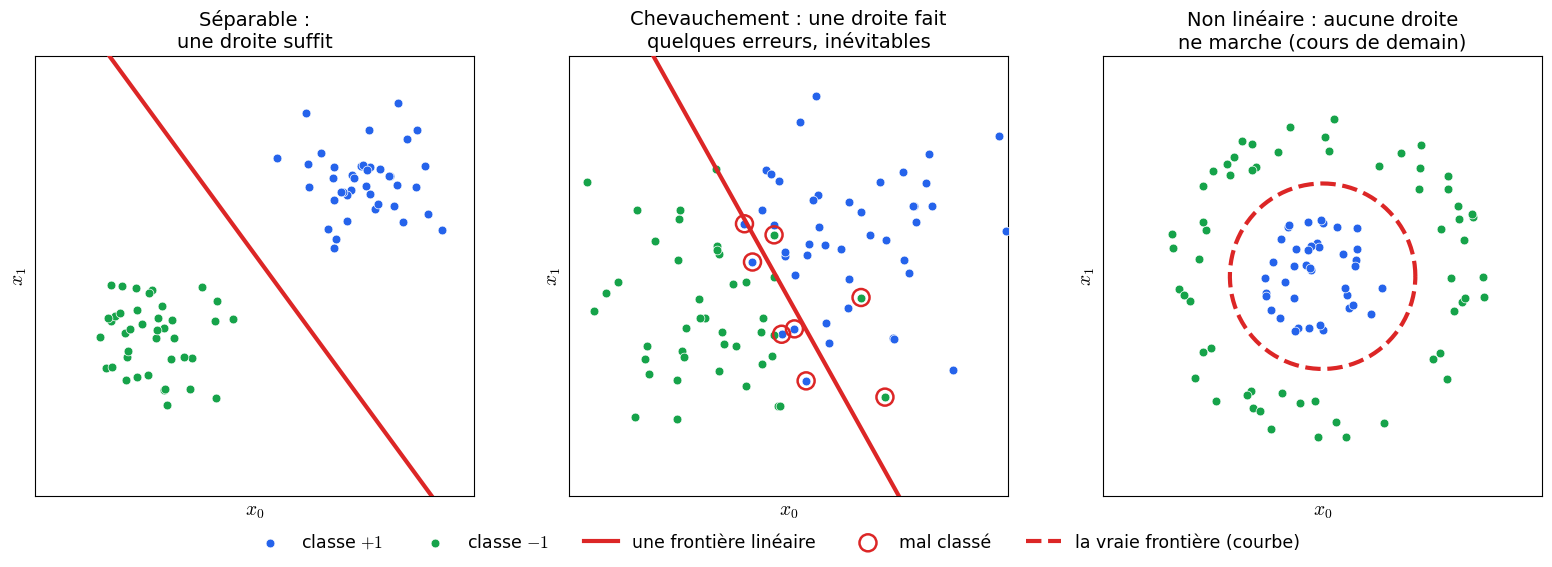

In [2]:
#@title Figure : trois situations (séparable, chevauchement, courbe). Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_situations()  # trois nuages de points jouets : une droite suffit, une droite fait des erreurs, aucune droite ne marche

### À gauche : les deux classes se séparent par une droite. Une droite suffit.

### Au milieu : les classes se chevauchent. Une droite fait quelques erreurs (les cercles rouges), et elles sont inévitables.

### À droite : la vraie frontière est courbe (le tireté rouge). Aucune droite ne marche ; c'est le sujet du cours de demain.

### Bonne nouvelle : le cas « une droite suffit » est fréquent.

### ⏩ Raison géométrique : $n$ points en dimension $d$, pris en position générale (pas de $d + 1$ points sur un même hyperplan), sont séparables par un hyperplan quelle que soit la façon de les étiqueter, dès que $n \le d + 1$ ([Cover, 1965](https://doi.org/10.1109/PGEC.1965.264137)) : avec beaucoup de mesures et peu d'exemples, une droite suffit presque toujours.

### ⏩ Raisons empiriques : sur du texte décrit par ses mots, la plupart des catégories sont linéairement séparables sur les corpus classiques (Reuters, Ohsumed) ([Joachims, 1998](https://doi.org/10.1007/BFb0026683)) ; en médecine, une revue de 71 études n'a trouvé aucun avantage des méthodes complexes sur la régression logistique ([Christodoulou et al., 2019](https://doi.org/10.1016/j.jclinepi.2019.02.004)).

### ⏩ Et un classifieur linéaire se lit comme un jury : chaque poids dit combien une mesure compte ([Hastie, Tibshirani et Friedman, 2009](https://hastie.su.domains/ElemStatLearn/), section 4.4). Donc : toujours l'essayer en premier ; des règles très simples font souvent presque aussi bien que des méthodes élaborées ([Holte, 1993](https://doi.org/10.1023/A:1022631118932)).

### ⏩ Le cas courbe le plus célèbre est le « ou exclusif », qu'aucune droite ne sépare ([Minsky et Papert, 1969](https://mitpress.mit.edu/9780262630221/perceptrons/)).

## 0.3 Comment trouve-t-on les paramètres ?

### Personne ne devine $w$ à la main : il y a une recette en quatre étapes.

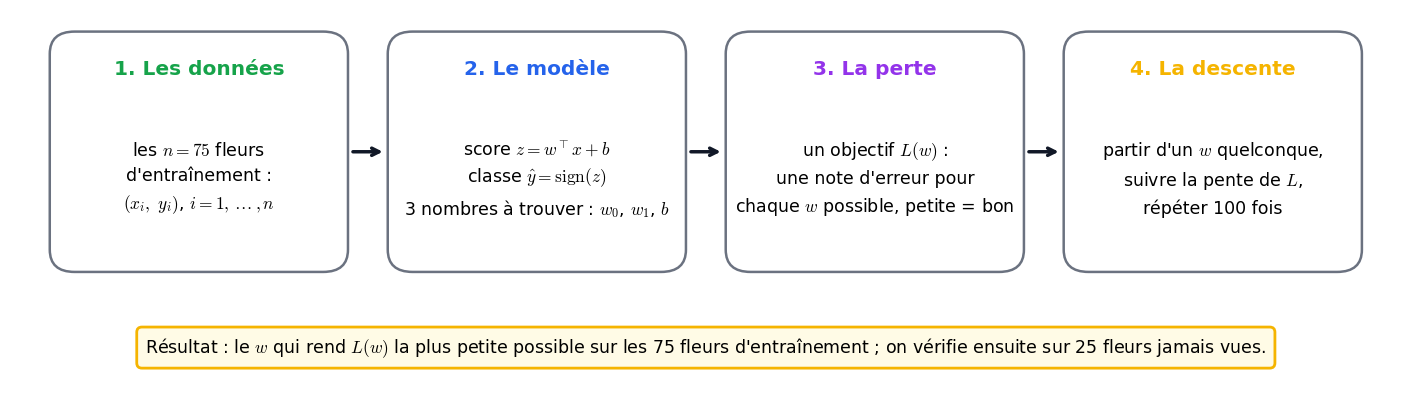

In [3]:
#@title Figure : la recette en quatre étapes. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_recette()  # données, modèle, perte, descente : le schéma de tout le labo

### 1. Les données : $n = 75$ fleurs dont on connaît déjà la classe. La fleur numéro $i$ ($i = 1, \dots, n$) a pour mesures $x_i$ et pour vraie classe $y_i$.

### 2. Le modèle : la règle ci-dessus, $z = w^\top x + b$, avec $w$ et $b$ inconnus.

### 3. La perte : une fonction $L(w)$ qui donne une **note d'erreur** à chaque choix de $w$ ; petite = bon. On la construit à la section 3. ($L$ majuscule : toutes les fleurs ensemble ; on y verra aussi une perte $\ell$ minuscule pour une seule fleur.)

### 4. La descente de gradient : on part d'un $w$ quelconque, on regarde dans quelle direction $L$ baisse le plus vite, on fait un petit pas, on recommence.

### Les quatre classifieurs du labo ont le même modèle et la même descente ; ils ne diffèrent que par la perte de l'étape 3, et par deux réglages, la force de la régularisation $\lambda$ (section 3) et la taille du pas $\eta$ (section 5), qu'on indiquera à chaque fois.

### Les sections 1 à 5 reprennent ces quatre étapes une par une, dans l'ordre : les données (1), la perte (2 et 3), le gradient (4), la descente (5).

## 0.4 Un exemple chiffré, à la main

### Dans tout le labo, les mesures sont standardisées : $x_0 = 1.6$ veut dire « un pétale 1.6 écart-type plus long que la moyenne » (la formule est à la section 1).

### Une valeur négative veut dire « plus court que la moyenne ».

### Prenons $w_0 = 1$, $w_1 = 1$ et $b = -0.4$, c'est-à-dire $w = (1, 1)$ et $b = -0.4$.

### 🌸 Fleur A : mesures $x_A = (1.6,\ 1.2)$, et on sait que c'est une versicolor ($y_A = +1$).

$$z_A = w_0\,x_0 + w_1\,x_1 + b = 1 \times 1.6 + 1 \times 1.2 - 0.4 = 2.4$$

où $z_A$ est le score de la fleur A : on met en indice le nom de la fleur dont on parle.

### Score positif : la règle répond $\hat y_A = +1$, versicolor. Bonne réponse.

### 🌸 Fleur B : mesures $x_B = (-1.3,\ -0.9)$, une setosa ($y_B = -1$).

$$z_B = w_0\,x_0 + w_1\,x_1 + b = 1 \times (-1.3) + 1 \times (-0.9) - 0.4 = -2.6$$

### Score négatif : la règle répond $\hat y_B = -1$, setosa. Bonne réponse aussi.

### 🌸 Fleur C : mesures $x_C = (-1.6,\ 1.3)$, étiquetée versicolor ($y_C = +1$). C est une fleur imaginaire, placée exprès là où notre règle se trompe (un pétale court et large : aucune vraie versicolor ne ressemble à ça) ; elle nous sert de fleur mal classée pour tout le labo.

$$z_C = w_0\,x_0 + w_1\,x_1 + b = 1 \times (-1.6) + 1 \times 1.3 - 0.4 = -0.7$$

### Score négatif, donc la règle répond $\hat y_C = -1$, setosa : c'est une erreur, puisque $y_C = +1$.

## 0.5 Le modèle, en une image

### Les trois fleurs, la frontière et le vecteur $w$.

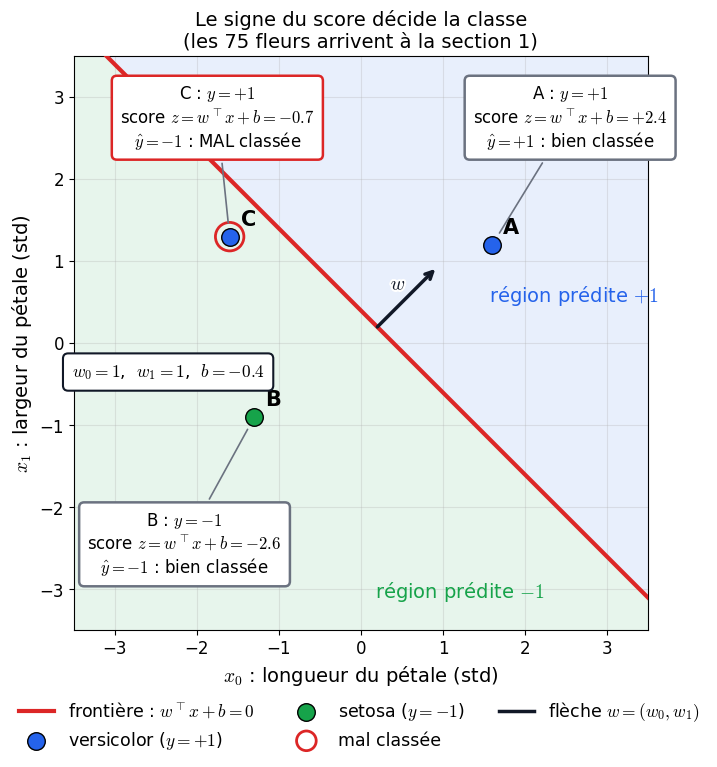

In [4]:
#@title Figure : A, B, C, la frontière et le vecteur w. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_abc()  # les trois fleurs du fil rouge, les régions prédites, la frontière (score nul) et la flèche w

> **📊** Rond bleu = versicolor ($y = +1$), rond vert = setosa ($y = -1$). Le fond bleu est la région où $\hat y = +1$, le fond vert celle où $\hat y = -1$. Le cercle rouge vide entoure la fleur mal classée : c'est la convention de tout le labo.

### A et B sont du bon côté de la frontière ; C est du mauvais côté.

### La flèche $w = (w_0, w_1)$ est perpendiculaire à la frontière et pointe vers la région prédite $+1$. (Sa longueur ne change pas la frontière ; la démo C de la section 1 le montrera.)

### Le classifieur fait exactement deux choses : calculer le score $z = w^\top x + b$, puis prendre son signe, $\hat y = \mathrm{sign}(z)$.

## 0.6 Le score, c'est une hauteur (démo P)

### Posez les fleurs sur une table : le score $z$ est un plan incliné au-dessus de la table.

### Au-dessus de chaque point, la hauteur du plan est son score ; sous la table, le score est négatif.

### La frontière, c'est la ligne où le plan coupe la table.

### À droite de la scène 3D, la même scène vue d'en haut : c'est la figure plate qu'on utilisera dans tout le reste du labo.

### Pour cette démo (et les démos A et R), dix points jouets inventés, ronds $y = +1$ et carrés $y = -1$ : plus simples que les fleurs, et séparables par une droite.

### Dans la démo, le curseur $\theta$ règle l'angle du vecteur $w = (\cos\theta, \sin\theta)$, et le curseur $b$ règle le biais de $z = w^\top x + b$.

> **📊** À gauche : chaque point est relié par une tige à sa hauteur $z$ sur le plan ; bleu = classe $+1$, vert = classe $-1$ ; une croix rouge marque un point du mauvais côté de la table ($z$ et $y$ de signes opposés). Comme la flèche $w = (\cos\theta, \sin\theta)$ a toujours une longueur 1 (notée $\lVert (w_0, w_1)\rVert = \sqrt{w_0^2 + w_1^2} = 1$), le plan a toujours la même pente : seules son orientation et sa hauteur changent.

> **📊** À droite : la ligne rouge est la même que celle où le plan coupe la table ($w^\top x + b = 0$), et la flèche $w$ lui est toujours perpendiculaire. **Cliquez-glissez dans la scène 3D pour la faire tourner, roulette pour zoomer** : elle garde votre point de vue quand vous bougez un curseur, et le survol d'un point affiche ses valeurs.

> **🔮 Avant de bouger le curseur, prédisez :** Si on change seulement $b$, la frontière va-t-elle tourner, ou se déplacer parallèlement à elle-même ?

> **🔮 Avant de bouger le curseur, prédisez :** Peut-on toujours trouver un angle $\theta$ et un biais $b$ qui classent les dix points sans erreur ?

In [5]:
#@title Démo P : le plan incliné (curseurs angle et biais). Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
demo_P()  # le plan incliné du score : l'angle theta de w et le biais b, en 3D et vu d'en haut

> **🧠 Vérifiez votre prédiction :** <details><summary>Cliquez après avoir joué avec les curseurs.</summary>Changer $b$ seul déplace la frontière parallèlement à elle-même : le plan monte ou descend sans s'incliner. C'est l'angle $\theta$ qui la fait tourner. Et oui, plusieurs réglages classent les dix points sans erreur, par exemple $\theta = 45°$ et $b = -0.2$.</details>

## 0.7 La marge : la quantité à retenir pour tout le labo

### La marge d'une fleur, c'est son score multiplié par sa vraie classe.

$$\boxed{\,m = y\,z\,} \tag{2}$$

où $y \in \{-1, +1\}$ est la vraie classe de la fleur et $z = w^\top x + b$ son score ; $y\,z$ est le produit des deux nombres (on l'écrit sans signe de multiplication). C'est l'équation (2) du labo : l'équation (1), le score, prend sa forme définitive à la fin de cette section.

### Si $m > 0$, le score et l'étiquette ont le même signe : la fleur est bien classée.

### Si $m < 0$, ils sont de signes opposés : la fleur est mal classée. (Le cas $m = 0$, fleur exactement sur la frontière, est compté comme bien classée ; il n'arrive jamais en pratique.)

### À $w$ fixé, plus $m$ est grand, plus la fleur est loin du bon côté de la frontière ; la distance exacte est $m / \lVert (w_0, w_1) \rVert$ (on le vérifiera dans la démo C : tripler $w$ triple $m$ sans rien déplacer).

### Attention au mot « marge » : tout seul, il désignera toujours ce nombre $m$. On rencontrera plus tard la « bande de marge » du SVM (section 8) et la distance signée à la frontière $m / \lVert (w_0, w_1)\rVert$ (sa plus petite valeur parmi les fleurs est la « marge géométrique minimale » $\gamma$, démo F), la vraie distance d'une fleur à la frontière (démo C, section 1) : on les nommera toujours en toutes lettres.

### Nos trois fleurs : du score à la marge.

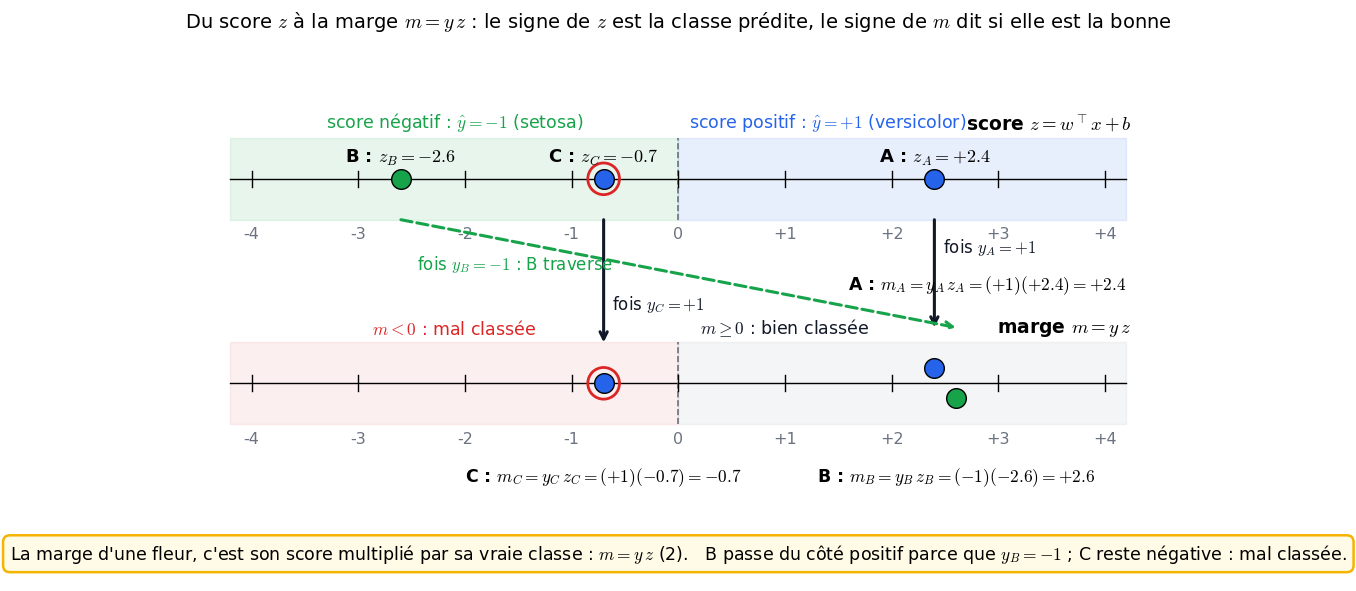

In [6]:
#@title Figure : du score z à la marge m = y z pour A, B et C. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_axe_marge()  # deux droites graduées : le score en haut, la marge en bas ; B change de signe parce que y = -1

> **📊** En haut, le score $z$ de A, B et C ; en bas, leur marge $m = y\,z$. B a un score négatif, mais comme $y_B = -1$, sa marge est positive : elle traverse. C garde une marge négative : elle est mal classée (cercle rouge).

### 🌸 Le code refait le calcul pour A, B et C : score, puis marge.

In [7]:
#@title Fil rouge : score et marge de A, B et C. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
tableau_abc()  # score et marge des trois fleurs du fil rouge, pour le w choisi à la main

w = (w₀, w₁, b) = (1.00, 1.00, -0.40)
fleur      x₀     x₁    y   score z   marge m   verdict  (z = w⊤x, m = y z)
A         1.6    1.2   +1      2.40      2.40   bien classée
B        -1.3   -0.9   -1     -2.60      2.60   bien classée
C        -1.6    1.3   +1     -0.70     -0.70   MAL classée


### Lecture : A et B ont une marge positive ($m_A = +2.4$ et $m_B = +2.6$ : bien classées) ; C a une marge négative ($m_C = -0.7$ : mal classée).

### Retenez $m$ : les quatre pertes de la section 3 sont toutes des fonctions de $m$.

## 0.8 Pourquoi on oublie $b$

### Astuce : on ajoute un 1 à la fin de $x$, et on range $b$ dans $w$.

$$w^\top x + b = w_0\,x_0 + w_1\,x_1 + b = (w_0,\ w_1,\ b)^\top (x_0,\ x_1,\ 1)$$

où le dernier produit scalaire est celui de deux vecteurs à trois composantes, le nouveau $w$ et le nouveau $x$ : sa troisième composante, $b$ fois $1$, vaut $b$.

### À partir d'ici, $x = (x_0, x_1, 1)$ a trois composantes, $w = (w_0, w_1, w_2)$ aussi, avec $w_2 = b$, et le score s'écrit sans le $+\, b$.

$$\boxed{\,z = w^\top x\,} \tag{1} \qquad \text{et} \qquad \hat y = \mathrm{sign}(z)$$

où $w^\top x = w_0\,x_0 + w_1\,x_1 + w_2$, puisque la troisième composante de $x$ vaut 1 : c'est le même score qu'avant. On continuera d'appeler $b$ la troisième composante de $w$ quand on parle du biais, et $w_2$ dans les calculs composante par composante (section 4). La frontière s'écrit désormais $w^\top x = 0$.

### Le schéma qui suit montre la colonne de 1 et, à côté, les lignes de A, B et C telles que le code les rangera.

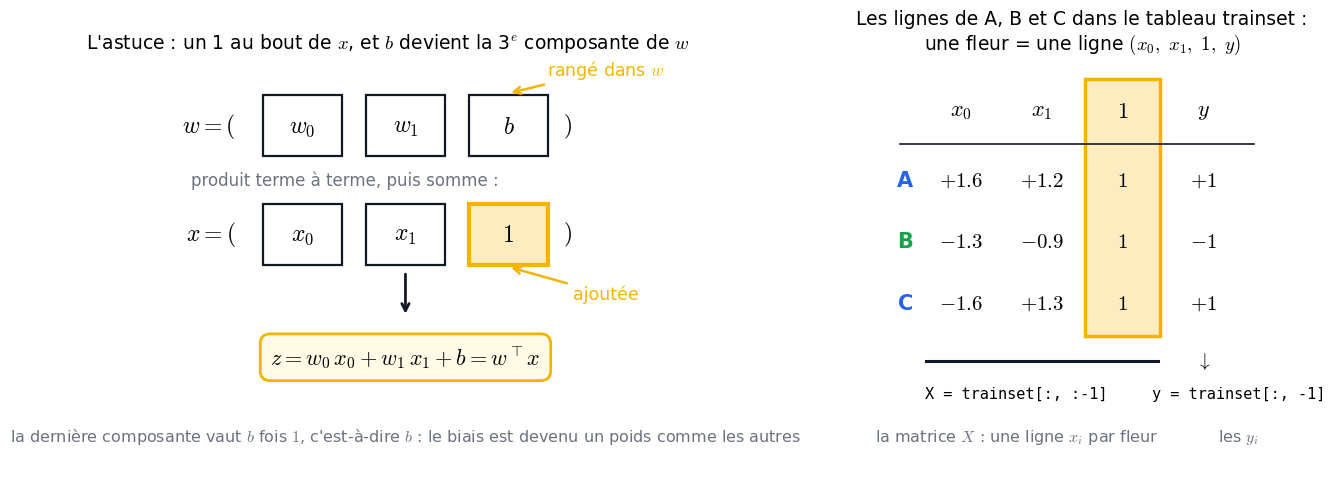

In [8]:
#@title Figure : la colonne de 1. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_colonne_un()  # le 1 ajouté à x, b rangé dans w, et les lignes (x0, x1, 1, y) de A, B, C

### Dans le code : le tableau `trainset` (section 1) a $n = 75$ lignes, une par fleur, et quatre colonnes $(x_0, x_1, 1, y)$. On en tire `X = trainset[:, :-1]`, la matrice $X$ des entrées, de forme $(75, 3)$, une ligne $x_i$ par fleur (la colonne de 1 comprise), et `y = trainset[:, -1]`, le vecteur des $y_i$ ; les poids `self.w` sont trois nombres.

## 0.9 Le lien avec les diapos du cours

### ⏩ Les diapos écrivent la prédiction $f(x) = \mathrm{sign}(w^\top x + b)$ : c'est exactement notre $\hat y = \mathrm{sign}(z)$, sous un autre nom.

Dans le code, la méthode `predict` renverra le score $z$, pas la classe ; la classe prédite est `np.sign(z)`.

### Elles écrivent l'erreur d'une fleur $\mathbb{1}\{y \neq f(x)\}$, avec la fonction indicatrice.

$$\mathbb{1}\{\text{condition}\} = \begin{cases} 1 & \text{si la condition est vraie} \\ 0 & \text{sinon} \end{cases}$$

où la condition est n'importe quelle affirmation ; par exemple $\mathbb{1}\{-0.7 < 0\} = 1$ (fleur C, mal classée) et $\mathbb{1}\{2.4 < 0\} = 0$ (fleur A, bien classée). En numpy : `(condition).astype(float)`.

### C'est la même chose que « $m < 0$ », parce que $y$ vaut $+1$ ou $-1$.

$$y \neq \mathrm{sign}(z) \iff y \text{ et } z \text{ sont de signes opposés} \iff y\,z < 0 \iff m < 0$$

où la deuxième équivalence vient de ce que multiplier par $y = \pm 1$ ne change que le signe de $z$. (Seul le cas limite $z = 0$ sépare les deux écritures : les diapos comptent une erreur si $y = -1$, le code compte $m = 0$ comme bien classée, `marges < 0` ; avec des mesures réelles, ça n'arrive jamais.)

### Notre $m$ s'appelle « marge fonctionnelle » dans la partie SVM des diapos (diapo 38 du cours 10) : c'est le même nombre.

## 0.10 📖 Table de notation et six équations

### 📖 La notation du labo, une fois pour toutes (à garder sous la main).

<table width="100%">
<tr><th align="left" width="24%">symbole</th><th align="left" width="16%">nom en mots</th><th align="left" width="42%">définition</th><th align="left" width="18%">Python</th></tr>
<tr><td valign="top">$x = (x_0, x_1, 1)$</td><td valign="top">entrée d'une fleur</td><td valign="top">$x_0$ longueur du pétale, $x_1$ largeur du pétale (standardisées) ; troisième composante $x_2 = 1$ (l'astuce ci-dessus) ; avant l'astuce, $x = (x_0, x_1)$</td><td valign="top">une ligne de <code>X</code></td></tr>
<tr><td valign="top">$y \in \{-1, +1\}$</td><td valign="top">étiquette (vraie classe)</td><td valign="top">$-1$ setosa, $+1$ versicolor</td><td valign="top"><code>y</code></td></tr>
<tr><td valign="top">$w = (w_0, w_1, b)$, c.-à-d. $w = (w_0, w_1, w_2)$ avec $w_2 = b$</td><td valign="top">poids (3 nombres à apprendre)</td><td valign="top">$w_0$, $w_1$ poids des deux mesures, $b$ biais ; dans les calculs par composante on écrit $w_2$</td><td valign="top"><code>self.w</code>, <code>w[2]</code></td></tr>
<tr><td valign="top">$z = w^\top x$</td><td valign="top">score, équation (1)</td><td valign="top">$= w_0\,x_0 + w_1\,x_1 + b$ (avant l'astuce : $z = w^\top x + b$ avec $x$ à 2 composantes) ; $\top$ = transposé : $w^\top x$ est le produit scalaire, l'ordre des vecteurs ne change pas le nombre</td><td valign="top"><code>self.predict(X)</code></td></tr>
<tr><td valign="top">$\hat y = \mathrm{sign}(z)$</td><td valign="top">classe prédite</td><td valign="top">$+1$ si $z \ge 0$, $-1$ sinon (convention $\mathrm{sign}(0) = +1$) ; les diapos du cours la notent $f(x)$</td><td valign="top"><code>np.sign(z)</code></td></tr>
<tr><td valign="top">$m = y\,z$</td><td valign="top">marge (d'une fleur), équation (2)</td><td valign="top">$m \gt 0$ bien classée, $m \lt 0$ mal classée ; $m = 0$ comptée bien classée</td><td valign="top"><code>marges</code></td></tr>
<tr><td valign="top">$n$, $i$</td><td valign="top">nombre de fleurs d'entraînement, numéro de fleur</td><td valign="top">$n = 75$, $i = 1, \dots, n$ ; $x_i, y_i, z_i, m_i$</td><td valign="top"><code>len(y)</code>, <code>X[i]</code></td></tr>
<tr><td valign="top">$j$</td><td valign="top">numéro de composante</td><td valign="top">$j \in \{0, 1, 2\}$ (convention Python)</td><td valign="top"><code>w[j]</code></td></tr>
<tr><td valign="top">$\mathbb{1}\{\text{condition}\}$</td><td valign="top">indicatrice</td><td valign="top">1 si la condition est vraie, 0 sinon</td><td valign="top"><code>(cond).astype(float)</code></td></tr>
<tr><td valign="top">$\mathrm{Err}(w)$</td><td valign="top">taux d'erreur (section 2)</td><td valign="top">$\frac1n\sum_{i=1}^n \mathbb{1}\{m_i \lt 0\}$ ; $\ell_{0\text{-}1}(m) = \mathbb{1}\{m \lt 0\}$ est l'erreur d'une fleur</td><td valign="top"><code>error_rate</code></td></tr>
<tr><td valign="top">$\ell(m)$</td><td valign="top">perte d'UNE fleur (« petit l », section 3)</td><td valign="top">fonction de sa marge ; quatre choix</td><td valign="top"><code>PERTES[...]</code></td></tr>
<tr><td valign="top">$\ell'(m) = \dfrac{d\ell}{dm}$</td><td valign="top">pente de la perte d'une fleur (section 4)</td><td valign="top">seul endroit où les quatre méthodes diffèrent ; « poussée » = $\ell'(m)\,y$, « force » = $\lvert\ell'(m)\rvert$</td><td valign="top"><code>coef</code></td></tr>
<tr><td valign="top">$L(w)$</td><td valign="top">objectif (perte totale), équation (3) (section 3)</td><td valign="top">$\frac1n\sum_{i=1}^n \ell(m_i) + \frac{\lambda}{2}\lVert w\rVert^2$</td><td valign="top"><code>self.loss(X, y)</code></td></tr>
<tr><td valign="top">$\lambda$</td><td valign="top">force de la régularisation (section 3)</td><td valign="top">$\ge 0$ ; tire $w$ vers 0</td><td valign="top"><code>reg</code></td></tr>
<tr><td valign="top">$\lVert w\rVert^2 = w_0^2 + w_1^2 + b^2$</td><td valign="top">norme de $w$ (3 composantes, biais compris)</td><td valign="top">utilisée dans la régularisation (le code régularise aussi le biais, par simplicité)</td><td valign="top"><code>np.sum(w ** 2)</code></td></tr>
<tr><td valign="top">$\lVert (w_0, w_1)\rVert$</td><td valign="top">norme des deux premières composantes</td><td valign="top">géométrie : distance d'une fleur à la frontière $= \lvert z\rvert / \lVert (w_0, w_1)\rVert$ ; largeur de la bande du SVM $= 2 / \lVert (w_0, w_1)\rVert$ (section 8)</td><td valign="top"><code>np.linalg.norm(w[:2])</code></td></tr>
<tr><td valign="top">$\gamma$</td><td valign="top">marge géométrique minimale (démo F, section 9)</td><td valign="top">$\gamma = \min_i m_i / \lVert (w_0, w_1)\rVert$ : distance entre la frontière et la fleur la plus proche</td><td valign="top"><code>marge</code> dans la démo F</td></tr>
<tr><td valign="top">$\nabla_w \ell$, $\nabla_w L$</td><td valign="top">gradient (par rapport à $w$), équations (4) et (5) (section 4)</td><td valign="top">vecteur des trois dérivées partielles ; $\nabla_w \ell = \ell'(m)\,y\,x$ ; $\nabla_w L = \frac1n\sum_{i=1}^n \ell'(m_i)\,y_i\,x_i + \lambda w$</td><td valign="top"><code>self.gradient(X, y)</code></td></tr>
<tr><td valign="top">$\eta$</td><td valign="top">le pas (sa taille), équation (6) (section 5)</td><td valign="top">$w \leftarrow w - \eta\,\nabla_w L(w)$ ; une mise à jour = une <b>itération</b> (jamais « un pas »)</td><td valign="top"><code>stepsize</code></td></tr>
<tr><td valign="top">$t$, $w^{(t)}$, $T$</td><td valign="top">numéro d'itération, poids à l'itération $t$, nombre d'itérations (section 5)</td><td valign="top">$w^{(0)}$ = point de départ (<code>w0</code> dans le code = $w^{(0)}$, rien à voir avec la composante $w_0$) ; $T = 100$</td><td valign="top"><code>n_steps</code>, <code>self.historique[t]</code></td></tr>
<tr><td valign="top">$\sigma(a) = \dfrac{1}{1 + e^{-a}}$</td><td valign="top">sigmoïde (section 9)</td><td valign="top">$P(y = +1 \mid x) = \sigma(z)$ ; $P(\text{vraie classe}) = \sigma(m)$ ; $\frac{1}{1 + e^{m}} = \sigma(-m) = 1 - \sigma(m)$</td><td valign="top"><code>sigma(a)</code></td></tr>
<tr><td valign="top">$\theta$</td><td valign="top">angle du vecteur $(w_0, w_1)$</td><td valign="top">$w = r(\cos\theta, \sin\theta)$ ; démos A, H, P</td><td valign="top"><code>theta</code>, <code>angle</code></td></tr>
<tr><td valign="top">$k$</td><td valign="top">taille du mini-lot (bonus)</td><td valign="top">pas $B$ : B est une fleur du fil rouge</td><td valign="top"><code>batch_size</code></td></tr>
<tr><td valign="top">$H$, $\mu_{\max}$, $w^*$</td><td valign="top">hessienne de $L$ (régression linéaire, section 6), sa plus grande valeur propre, minimum exact</td><td valign="top">la descente diverge si $\eta \gt 2/\mu_{\max}$ ; $\nabla_w L(w^*) = 0$ (démo E)</td><td valign="top"><code>H</code>, <code>SEUIL_ETA</code>, <code>W_ETOILE</code></td></tr>
<tr><td valign="top">$\mu_j$, $s_j$</td><td valign="top">moyenne et écart-type de la mesure $j$ (entraînement, section 1)</td><td valign="top">standardisation $x_j \leftarrow (x_j - \mu_j)/s_j$ ; on n'écrit pas $\sigma$ pour l'écart-type</td><td valign="top"><code>mu</code>, <code>sigma</code> (code seulement)</td></tr>
</table>

### Les six équations du labo, numérotées (1) à (6) ; chacune sera encadrée à sa place, et on y renverra par son numéro.

<table width="100%">
<tr><th align="left" width="8%">n°</th><th align="left" width="44%">équation</th><th align="left" width="34%">ce qu'elle dit</th><th align="left" width="14%">section</th></tr>
<tr><td valign="top">(1)</td><td valign="top">$z = w^\top x$ et $\hat y = \mathrm{sign}(z)$</td><td valign="top">le score et la classe prédite</td><td valign="top">0 (ci-dessus)</td></tr>
<tr><td valign="top">(2)</td><td valign="top">$m = y\,z$</td><td valign="top">la marge d'une fleur</td><td valign="top">0 (ci-dessus)</td></tr>
<tr><td valign="top">(3)</td><td valign="top">$L(w) = \frac1n\sum_{i=1}^{n} \ell(m_i) + \frac{\lambda}{2}\lVert w\rVert^2$</td><td valign="top">l'objectif : perte moyenne plus régularisation</td><td valign="top">3</td></tr>
<tr><td valign="top">(4)</td><td valign="top">$\nabla_w \ell = \ell'(m)\,y\,x$</td><td valign="top">le gradient de la perte d'une fleur</td><td valign="top">4</td></tr>
<tr><td valign="top">(5)</td><td valign="top">$\nabla_w L = \frac1n\sum_{i=1}^{n} \ell'(m_i)\,y_i\,x_i + \lambda\,w$</td><td valign="top">le gradient de l'objectif</td><td valign="top">4</td></tr>
<tr><td valign="top">(6)</td><td valign="top">$w^{(t+1)} = w^{(t)} - \eta\,\nabla_w L(w^{(t)})$</td><td valign="top">une itération de la descente de gradient</td><td valign="top">5</td></tr>
</table>

## 1. Les fleurs

> **📖 Rappel de notation.** Une fleur, c'est une entrée $x = (x_0, x_1, 1)$ et une étiquette $y \in \{-1, +1\}$ : $x_0$ la longueur du pétale, $x_1$ sa largeur (toutes deux standardisées, voir ci-dessous), puis le $1$ de l'astuce de la section 0 ; $y = -1$ pour setosa, $y = +1$ pour versicolor. Il y a $n = 75$ fleurs d'entraînement, numérotées $i = 1, \dots, n$ : $(x_i, y_i)$.
>
> Dans le code : `trainset` est un tableau de $n = 75$ lignes et 4 colonnes $(x_0, x_1, 1, y)$ ; on en tire `X = trainset[:, :-1]` (la matrice $X$, forme $(75, 3)$, une ligne $x_i$ par fleur) et `y = trainset[:, -1]` (le vecteur des $y_i$).

### Le jeu de données iris ([Fisher, 1936](https://doi.org/10.1111/j.1469-1809.1936.tb02137.x)) : 150 fleurs, trois espèces, quatre mesures chacune.

### On garde deux espèces, setosa ($y = -1$) et versicolor ($y = +1$), et deux mesures : la longueur $x_0$ et la largeur $x_1$ du pétale.

### Standardiser une mesure = lui soustraire sa moyenne et la diviser par son écart-type (diapo 16 du cours 9 ; [Hastie, Tibshirani et Friedman, 2009](https://hastie.su.domains/ElemStatLearn/), section 3.4).

$$x_j \leftarrow \frac{x_j - \mu_j}{s_j}, \qquad j \in \{0, 1\}$$

où $x_j$ est la mesure numéro $j$ d'une fleur (en centimètres avant, sans unité après), $\mu_j$ sa moyenne et $s_j$ son écart-type, tous deux calculés sur les 75 fleurs d'entraînement seulement (dans le code : `mu` et `sigma`). On n'écrit pas $\sigma$ pour l'écart-type : dans ce labo, $\sigma$ est réservé à la sigmoïde (section 9).

### Après ça, 0 veut dire « dans la moyenne » et $+1$ « un écart-type au-dessus » : la fleur A, $x_0 = 1.6$, a un pétale 1.6 écart-type plus long que la moyenne.

### Moyenne $\mu_j$ et écart-type $s_j$ sont calculés sur les 75 fleurs d'entraînement seulement ; les fleurs de test sont transformées avec les mêmes nombres.

### Les 25 fleurs de test ne servent qu'à vérifier, à la fin, sur des fleurs jamais vues.

### Le code qui suit charge le tableau complet et affiche ses trois premières lignes : quatre mesures en centimètres, puis l'espèce.

In [9]:
#@title Code : charger les 150 fleurs d'iris. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
URL_IRIS = 'https://www.iro.umontreal.ca/~dift3395/files/iris.txt'  # copie du jeu de données sur le site du cours


def charger_iris():
    """Renvoie un tableau (150, 5) : 4 mesures puis l'étiquette (1 = setosa, 2 = versicolor, 3 = virginica)."""
    if os.path.exists('iris.txt'):  # le fichier est déjà à côté du notebook
        return np.loadtxt('iris.txt')  # lecture directe
    try:  # sinon, on essaie le site du cours (qui refuse les requêtes sans « User-Agent » de navigateur)
        import io, urllib.request  # lecture d'une adresse web
        requete = urllib.request.Request(URL_IRIS, headers={'User-Agent': 'Mozilla/5.0'})  # on se présente comme un navigateur
        texte = urllib.request.urlopen(requete, timeout=10).read().decode()  # le fichier texte
        return np.loadtxt(io.StringIO(texte))  # 150 lignes, 5 colonnes
    except Exception as erreur:  # pas de réseau, ou site indisponible
        print('Site du cours inaccessible (', erreur, ') : on utilise la copie du même fichier livrée avec scikit-learn.')  # repli
        from sklearn.datasets import load_iris  # copie d'iris de scikit-learn (vérifiée identique, 150 fleurs dans le même ordre)
        donnees = load_iris()  # étiquettes 0, 1, 2
        return np.column_stack([donnees.data, donnees.target + 1])  # étiquettes ramenées à 1, 2, 3


iris = charger_iris()  # le tableau complet
print('Forme du tableau iris :', iris.shape)  # (150, 5)
print('Colonnes : longueur sépale, largeur sépale, longueur pétale, largeur pétale, étiquette')  # rappel des colonnes
print('Trois premières lignes :')  # aperçu
print(iris[:3])  # les trois premières fleurs (des setosa)

Site du cours inaccessible ( could not convert string '<!doctype' to float64 at row 0, column 1. ) : on utilise la copie du même fichier livrée avec scikit-learn.
Forme du tableau iris : (150, 5)
Colonnes : longueur sépale, largeur sépale, longueur pétale, largeur pétale, étiquette
Trois premières lignes :
[[5.1 3.5 1.4 0.2 1. ]
 [4.9 3.  1.4 0.2 1. ]
 [4.7 3.2 1.3 0.2 1. ]]


### Le code qui suit prépare les données : deux espèces, étiquettes $y = \pm 1$, deux mesures $(x_0, x_1)$, colonne de 1, mélange, 75 / 25, standardisation.

> **🔮 Avant d'exécuter la cellule, prédisez :** après standardisation, quelle sera la moyenne de chaque mesure sur les 75 fleurs d'entraînement ? Et sur les 25 fleurs de test ?

In [10]:
#@title Code : préparer les données. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
def preprocess(data, label_subset, feature_subset, n_train):
    """Effectue une partition aléatoire des données en sous-ensembles
    train set et test set avec le sous-ensemble de classes label_subset
    et le sous-ensemble de mesures feature_subset.
    """
    # on extrait seulement les classes de label_subset (l'indexation booléenne crée une copie : iris reste intact)
    data = data[np.isin(data[:, -1], label_subset), :]  # lignes dont l'étiquette est dans label_subset

    # on transforme les classes pour que l'étiquette y vaille -1 ou +1
    if len(label_subset) != 2:  # le labo ne traite que le cas binaire
        raise UserWarning('We are exclusively dealing with binary classification.')  # arrêt explicite
    data[data[:, -1] == label_subset[0], -1] = -1  # première espèce -> y = -1
    data[data[:, -1] == label_subset[1], -1] = 1  # deuxième espèce -> y = +1

    # on extrait les mesures choisies (x0, x1) et l'étiquette y
    data = data[:, feature_subset + [-1]]  # colonnes choisies, puis l'étiquette en dernier

    # on ajoute une colonne de 1 pour le biais (x = (x0, x1, 1)), juste avant l'étiquette
    data = np.insert(data, -1, 1, axis=1)  # forme finale d'une ligne : (x0, x1, 1, y)

    # on sépare en train et test
    inds = np.arange(data.shape[0])  # indices 0, 1, ..., n-1
    np.random.shuffle(inds)  # mélange aléatoire (dépend de la graine)
    train_inds = inds[:n_train]  # les n_train premiers pour l'entraînement
    test_inds = inds[n_train:]  # le reste pour le test
    trainset = data[train_inds]  # ensemble d'entraînement
    testset = data[test_inds]  # ensemble de test

    # on standardise chaque mesure j : x_j <- (x_j - mu_j) / s_j, avec mu_j et s_j calculés sur l'entraînement seulement
    mu = trainset[:, :2].mean(axis=0)  # mu = (mu_0, mu_1) : moyenne des deux mesures (entraînement)
    sigma = trainset[:, :2].std(axis=0)  # s = (s_0, s_1) : écart-type des deux mesures (entraînement)
    trainset[:, :2] = (trainset[:, :2] - mu) / sigma  # entraînement standardisé
    testset[:, :2] = (testset[:, :2] - mu) / sigma  # test transformé avec les MÊMES mu_j et s_j

    return trainset, testset  # deux tableaux de forme (n, 4) : une ligne (x0, x1, 1, y) par fleur


np.random.seed(2)  # même graine que le notebook officiel, juste avant le mélange : découpage identique
trainset, testset = preprocess(iris, label_subset=[1, 2], feature_subset=[2, 3], n_train=75)  # setosa contre versicolor, pétales
NOMS = {-1: 'setosa (y = -1)', 1: 'versicolor (y = +1)'}  # noms affichés dans les légendes

print('trainset :', trainset.shape, '| testset :', testset.shape)  # (75, 4) et (25, 4)
print('Colonnes : x0 = longueur du pétale (standardisée), x1 = largeur du pétale (standardisée), 1 (biais), y')  # rappel
print('Entraînement :', int((trainset[:, -1] < 0).sum()), 'setosa,', int((trainset[:, -1] > 0).sum()), 'versicolor')  # effectifs
print('Test         :', int((testset[:, -1] < 0).sum()), 'setosa,', int((testset[:, -1] > 0).sum()), 'versicolor')  # effectifs
print('Moyennes après standardisation (entraînement) :', trainset[:, :2].mean(axis=0))  # environ 0
print('Écarts-types après standardisation (entraînement) :', trainset[:, :2].std(axis=0))  # exactement 1
print('Trois premières lignes de trainset :')  # aperçu
print(trainset[:3])  # chaque ligne : x0, x1, 1, y

trainset : (75, 4) | testset : (25, 4)
Colonnes : x0 = longueur du pétale (standardisée), x1 = largeur du pétale (standardisée), 1 (biais), y
Entraînement : 34 setosa, 41 versicolor
Test         : 16 setosa, 9 versicolor
Moyennes après standardisation (entraînement) : [-0.  0.]
Écarts-types après standardisation (entraînement) : [1. 1.]
Trois premières lignes de trainset :
[[ 1.48  1.36  1.    1.  ]
 [-0.98 -1.13  1.   -1.  ]
 [ 1.2   1.36  1.    1.  ]]


> **🧠 Vérifiez :** <details><summary>Pourquoi la moyenne des fleurs de test n'est-elle pas exactement 0 après standardisation ?</summary>Parce qu'on standardise le test avec la moyenne et l'écart-type de l'entraînement, pas les siens : le test ne doit jamais servir à régler quoi que ce soit, même une moyenne. <code>testset[:, :2].mean(axis=0)</code> donne environ $(-0.37, -0.36)$.</details>

### Dans les trois lignes affichées, repérez la colonne de 1 (le biais, $x_2 = 1$) et la colonne $y$ (l'étiquette).

### Dans le code : `trainset` a $n = 75$ lignes, une par fleur, et 4 colonnes $(x_0, x_1, 1, y)$.

Les trois premières colonnes forment la matrice $X$ (forme $(75, 3)$, une ligne $x_i$ par fleur), la dernière le vecteur des étiquettes $y$ : `X = trainset[:, :-1]` et `y = trainset[:, -1]`, où `[:, :-1]` veut dire « toutes les lignes, toutes les colonnes sauf la dernière » et `[:, -1]` « la dernière colonne ». Ce découpage revient dans tout le labo (`train`, `verifier_gradient`, les démos).

### La figure qui suit montre les mêmes 100 fleurs avant (en centimètres) et après standardisation.

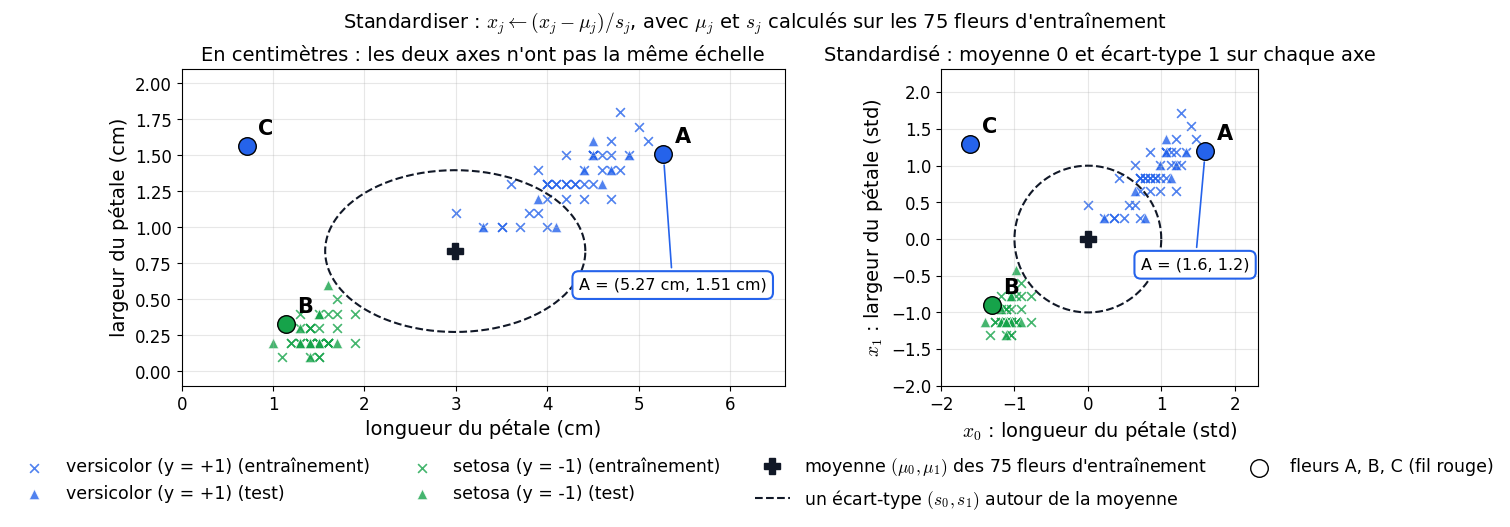

Entraînement (75 fleurs) : mu = (2.99 cm, 0.84 cm), s = (1.42 cm, 0.56 cm)
🌸 A : (5.27 cm, 1.51 cm)  ->  x = (1.6, 1.2, 1), y = +1   🌸 B : (1.14 cm, 0.33 cm)  ->  x = (-1.3, -0.9, 1), y = -1   🌸 C : (0.72 cm, 1.57 cm)  ->  x = (-1.6, 1.3, 1), y = +1   


In [11]:
#@title Figure : avant et après standardisation. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_standardisation()  # les 100 fleurs en cm à gauche, standardisées à droite, avec A, B, C dans les deux repères

> **📊** À gauche, les pétales mesurent de 1 à 5 cm de long mais de 0.1 à 1.8 cm de large : les deux axes n'ont pas la même échelle, et le contour « un écart-type » est une ellipse. À droite, chaque axe a été recentré sur sa moyenne $\mu_j$ (croix, devenue $(0, 0)$) et divisé par son écart-type $s_j$ : l'ellipse devient un cercle de rayon 1, et les deux mesures comptent autant l'une que l'autre.

> **📊 🌸** Les fleurs A, B, C de la section 0 sont placées dans les deux repères ; leurs mesures en centimètres sont imprimées sous la figure. A est une versicolor typique, B une setosa typique. C est une fleur inventée pour le fil rouge : un pétale court mais large, dans une zone où il n'y a aucune vraie fleur.

### La figure qui suit montre les 75 fleurs d'entraînement (croix) et les 25 fleurs de test (triangles), standardisées.

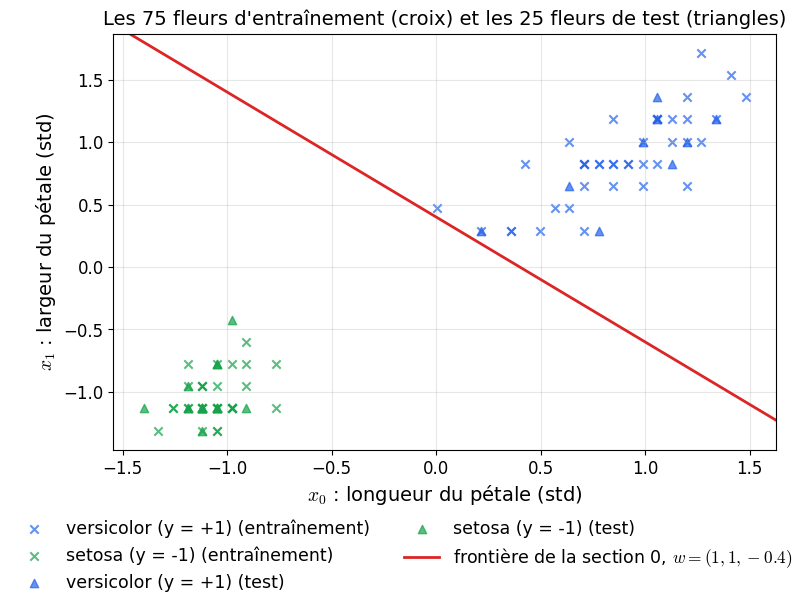

In [12]:
#@title Code : dessiner les fleurs. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
def scatter(theset, marker='o', suffixe=''):
    """Nuage de points d'un ensemble (train ou test), une couleur par classe."""
    d1 = theset[theset[:, -1] > 0]  # fleurs y = +1
    d2 = theset[theset[:, -1] < 0]  # fleurs y = -1
    plt.scatter(d1[:, 0], d1[:, 1], c=BLEU, marker=marker, label=NOMS[1] + suffixe, alpha=.7)  # classe +1
    plt.scatter(d2[:, 0], d2[:, 1], c=VERT, marker=marker, label=NOMS[-1] + suffixe, alpha=.7)  # classe -1
    plt.xlabel(ETIQ_X0)  # axe horizontal : x0, longueur du pétale (standardisée)
    plt.ylabel(ETIQ_X1)  # axe vertical : x1, largeur du pétale (standardisée)


def finalize_plot(title):
    """Titre, grille et légende commune sous la figure."""
    plt.title(title)  # titre
    plt.grid(alpha=.3)  # grille légère
    plt.gcf().set_layout_engine('constrained')  # mise en page constrained : la légende extérieure a sa place
    legende(plt.gcf(), ncol=2)  # légende sous le panneau (boîte à outils), sans cacher les fleurs


def decision_boundary(w):
    """Trace la frontière z = w @ x = 0, c'est-à-dire w[0] x0 + w[1] x1 + w[2] = 0, sans changer les limites des axes."""
    xlim = plt.xlim()  # on mémorise les limites actuelles
    ylim = plt.ylim()  # (astuce pour ne pas changer le cadre)
    if w[1] != 0:  # cas général : on isole x1
        xx = np.linspace(-10, 10, 2)  # deux abscisses suffisent pour une droite
        yy = -(w[2] + w[0] * xx) / w[1]  # x1 = -(b + w0 x0) / w1
        plt.plot(xx, yy, c=ROUGE, lw=2, label='frontière de la section 0, $w = (1, 1, -0.4)$')  # la frontière
    elif w[0] != 0:  # frontière verticale (le notebook officiel levait une erreur ici)
        plt.axvline(-w[2] / w[0], c=ROUGE, lw=2, label='frontière de la section 0, $w = (1, 1, -0.4)$')  # x0 = -b / w0
    else:  # w0 = w1 = 0 : pas de frontière du tout
        print('w0 = w1 = 0 : la frontière n\'est pas définie.')  # message
    plt.xlim(xlim)  # on remet les limites
    plt.ylim(ylim)  # mémorisées


# Les données, comme dans le notebook officiel
figure(1)  # une figure à un panneau (boîte à outils : mise en page constrained)
scatter(trainset, marker='x', suffixe=' (entraînement)')  # entraînement : croix
scatter(testset, marker='^', suffixe=' (test)')
decision_boundary(W_MAIN)  # la frontière « à la main » de la section 0, w = (1, 1, -0.4) : elle coupe le nuage versicolor  # test : triangles
finalize_plot('Les 75 fleurs d\'entraînement (croix) et les 25 fleurs de test (triangles)')  # titre
plt.show()  # affiche

> **📊** Bleu : versicolor ($y = +1$). Vert : setosa ($y = -1$). Mêmes axes $x_0$, $x_1$ et mêmes couleurs dans toutes les figures du labo.

> **📊** Deux nuages séparés par un large couloir vide : ce premier problème est volontairement facile.

### Ce problème est volontairement facile ; on passera au cas difficile (versicolor contre virginica, qui se chevauchent) à la toute fin, dans la démo F.

## 1.1 Démo C : placer une frontière à la main

### Avant d'apprendre $w$ automatiquement, essayons de le régler nous-mêmes avec trois curseurs.

### Les trois curseurs sont les trois composantes de $w = (w_0, w_1, b)$ ; la démo calcule alors, pour chaque fleur, le score (1) et la marge (2).

$$z_i = w^\top x_i, \qquad m_i = y_i\,z_i$$

où $x_i = (x_0, x_1, 1)$ et $y_i$ sont l'entrée et l'étiquette de la fleur $i$, de sorte que $z_i = w_0\,x_0 + w_1\,x_1 + b$ ; $m_i \ge 0$ veut dire « bien classée ». Le quatrième curseur, « échelle », multiplie $w_0$, $w_1$ et $b$ par un même nombre.

### Avec l'image du jury : les curseurs $w_0$ et $w_1$ sont les voix des deux jurés (longueur, largeur), et $b$ le seuil d'admission.

> **📊** À gauche : les 75 fleurs, la frontière $w^\top x = 0$ du $w$ choisi (rouge), la flèche $w$ (noire, toujours dessinée avec une longueur 1), la région prédite versicolor (bleutée), les bords de la bande de marge $w^\top x = \pm 1$ (tiretés noirs : les droites où le score vaut $+1$ et $-1$ ; regardez-les se rapprocher de la frontière quand l'échelle grandit, on en reparlera au SVM, section 8) ; un cercle rouge entoure chaque fleur mal classée ($m_i < 0$). Les fleurs 🌸 A, B, C du fil rouge sont aussi dessinées (gros ronds à bord noir) ; leurs scores $z$ et marges $m$ pour ce $w$ sont imprimés sous la figure.

> **📊** À droite : cinq façons de noter ce même $w$, de 0 (parfait) vers la droite. La barre noire est le taux d'erreur $\mathrm{Err}(w)$, la proportion de fleurs mal classées (défini à la section 2) ; les quatre autres sont les pertes qu'on définira à la section 3, chacune moyennée sur les 75 fleurs, $\frac{1}{n}\sum_{i=1}^{n} \ell(m_i)$, sans régularisation. Retenez seulement : plus la barre est courte, mieux c'est, et elles ne sont pas d'accord entre elles. L'axe s'arrête à 3 pour que les barres restent comparables d'un $w$ à l'autre : une barre qui dépasse est coupée et sa valeur est écrite en blanc dedans (▶).

> **🔮 Avant de bouger le curseur, prédisez :** Combien de droites différentes font 0 % d'erreur sur les fleurs : une seule, quelques-unes, une infinité ?

> **🔮 Avant de bouger le curseur, prédisez :** Si on multiplie $w$ par 3 (curseur « échelle »), est-ce que la frontière bouge ? Et les scores $z_i$ ? Et les barres de droite ?

In [13]:
#@title Démo C : placer une frontière à la main (curseurs). Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
demo_C()  # placer une frontière à la main : w0, w1, b, et une échelle qui multiplie les trois

> **🧠 Et si on multiplie $w$ par 3 ?** <details><summary>Mettez le curseur « échelle » à 3, puis cliquez pour vérifier.</summary>La frontière ne bouge pas : $3\,w^\top x = 0$ exactement quand $w^\top x = 0$, et aucun signe ne change, donc le taux d'erreur reste le même. Mais chaque score est triplé, $z_i \to 3\,z_i$, donc chaque marge aussi, $m_i \to 3\,m_i$, et les barres de droite changent (sauf l'erreur 0-1). La valeur d'une perte dépend de l'échelle de $w$ : c'est une des raisons de la régularisation $\frac{\lambda}{2}\lVert w\rVert^2$, à la section 3. Mais $\lVert (w_0, w_1)\rVert$ triple aussi, donc la distance de chaque fleur à la frontière, $m_i / \lVert (w_0, w_1)\rVert$ (section 0), ne change pas : c'est elle, la géométrie ; $m$ seule dépend de l'échelle de $w$.</details>

> **🧠 Mettez l'échelle à 0.1 : quelle barre s'effondre ?** <details><summary>Cliquez pour vérifier.</summary>Celle du perceptron : sa perte vaut $-m_i$ sur les fleurs mal classées et 0 ailleurs, donc elle rétrécit avec $w$ (ici elle passe de 0.450 à 0.045) alors que le nombre d'erreurs ne change pas ; à $w = 0$ elle vaut exactement 0. On y reviendra à la section 7.</details>

> **🧠 Combien de droites font 0 % d'erreur ?** <details><summary>Cliquez pour vérifier.</summary>Une infinité : toute droite qui passe dans le couloir vide entre les deux espèces. Le taux d'erreur ne dit pas laquelle choisir ; les pertes de la section 3, elles, les départagent.</details>

## 2. Pourquoi on ne minimise pas le taux d'erreur

> **📖 Rappel de notation.** Pour une fleur $x = (x_0, x_1, 1)$ d'étiquette $y \in \{-1, +1\}$ : le score est $z = w^\top x$ (1), la classe prédite $\hat y = \mathrm{sign}(z)$ ($+1$ si $z \ge 0$, $-1$ sinon) et la marge $m = y\,z$ (2) : $m > 0$ bien classée, $m < 0$ mal classée. Les $n = 75$ fleurs d'entraînement sont numérotées $i = 1, \dots, n$ : $x_i$, $y_i$, $z_i = w^\top x_i$, $m_i = y_i\,z_i$. Enfin, $\mathbb{1}\{\text{condition}\}$ vaut 1 si la condition est vraie et 0 sinon : $\mathbb{1}\{-0.7 < 0\} = 1$, $\mathbb{1}\{2.4 < 0\} = 0$.
>
> Dans le code : `self.predict(X)` calcule les $z_i$, `marges` les $m_i$, et `error_rate` le taux d'erreur défini ci-dessous.

## 2.1 Le taux d'erreur : une marche par fleur

### Le taux d'erreur compte les fleurs mal classées, et il se lit sur la marge.

$$\mathrm{Err}(w) = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\{y_i \neq \hat y_i\} = \frac{1}{n}\sum_{i=1}^{n} \underbrace{\mathbb{1}\{m_i < 0\}}_{\ell_{0\text{-}1}(m_i)}$$

où $n = 75$ est le nombre de fleurs d'entraînement, $\hat y_i = \mathrm{sign}(w^\top x_i)$ la classe prédite pour la fleur $i$, $m_i = y_i\,w^\top x_i$ sa marge (2), et $\ell_{0\text{-}1}(m) = \mathbb{1}\{m < 0\}$ l'erreur d'une seule fleur, qu'on appelle « erreur 0-1 ». Les deux sommes sont égales parce que « $y_i \neq \hat y_i$ » et « $m_i < 0$ » disent la même chose (section 0). Dans le code, c'est `error_rate` : `np.mean(self.predict(X) * y < 0)`.

### C'est ce qu'on veut petit. Mais peut-on le faire descendre avec un gradient ?

### Pour une seule fleur, l'erreur vaut 1 si $m < 0$ et 0 sinon : une marche.

$$\ell_{0\text{-}1}(m) = \mathbb{1}\{m < 0\} = \begin{cases} 1 & \text{si } m < 0 \ \text{(mal classée)} \\ 0 & \text{si } m \ge 0 \ \text{(bien classée ; } m = 0 \text{ compte comme bien classée)} \end{cases}$$

où $m = y\,z$ est la marge de la fleur (2). La figure qui suit la trace, avec les fleurs 🌸 A, B et C du fil rouge posées dessus (avec le $w$ choisi à la main à la section 0).

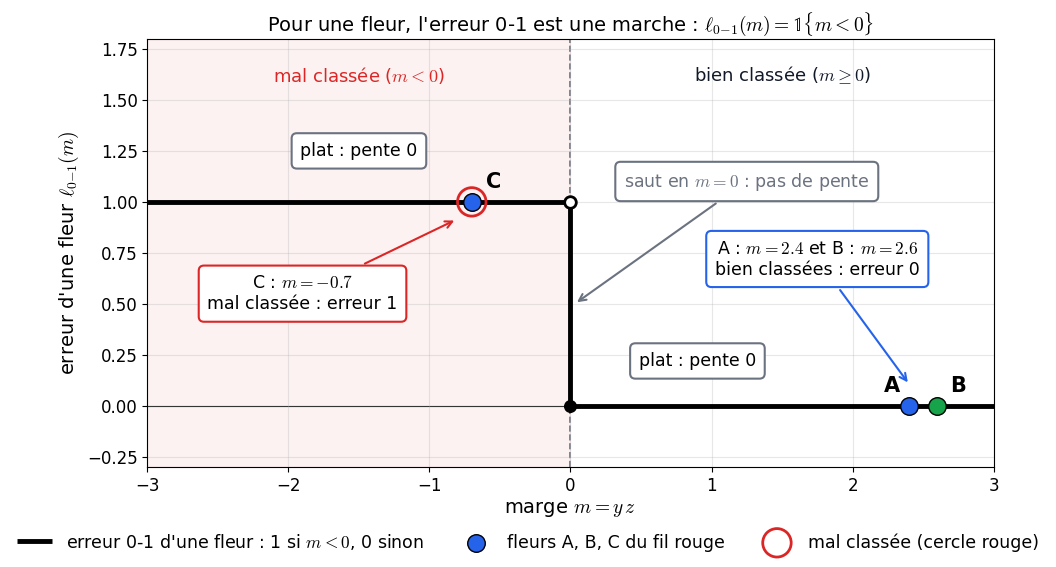

Avec le w de la section 0, w = (1.00, 1.00, -0.40) :  🌸 A : m = +2.4, ℓ0-1(m) = 0 | 🌸 B : m = +2.6, ℓ0-1(m) = 0 | 🌸 C : m = -0.7, ℓ0-1(m) = 1


In [14]:
#@title Figure : l'erreur 0-1 d'une fleur, une marche. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_marche()  # la marche l_{0-1}(m) = 1{m < 0}, avec A, B, C placées dessus

> **📊 🌸** En abscisse la marge $m$, en ordonnée l'erreur de la fleur. A ($m = 2.4$) et B ($m = 2.6$) sont sur le palier de droite : erreur 0. C ($m = -0.7$, entourée de rouge) est sur le palier de gauche : erreur 1. Le point ouvert en $(0, 1)$ et le point plein en $(0, 0)$ rappellent la convention : une marge nulle compte comme bien classée. Pour ces trois fleurs, $\mathrm{Err}(w) = \frac{0 + 0 + 1}{3}$.

### Sur chaque palier, la pente est exactement 0 ; au saut ($m = 0$), elle n'existe pas.

Déplacer un peu $w$ déplace un peu chaque marge $m_i$ ; tant qu'aucune ne change de signe, aucune erreur ne change, et $\mathrm{Err}(w)$ ne bouge pas d'un millième. Quand une marge traverse 0, $\mathrm{Err}(w)$ saute de $\frac{1}{n}$ d'un coup.

### Pente nulle : la descente de gradient (section 5) avance de « $\eta$ fois la pente », donc de $\eta \times 0 = 0$ ; elle ne bouge pas.

Ici $\eta$ (« êta ») est la taille du pas, un nombre positif qu'on règle à la section 5 (équation (6)). Une pente nulle ne dit pas dans quel sens aller, et une pente qui n'existe pas non plus.

## 2.2 Démo A : l'erreur 0-1 quand la frontière tourne

### La démo A le montre sur les dix points jouets de la démo P, en faisant tourner la frontière.

### Pour tourner avec un seul curseur, on écrit $w = r\,(\cos\theta, \sin\theta)$.

$$w = (w_0, w_1) = r\,(\cos\theta, \sin\theta), \qquad b = 0$$

où $\theta$ est l'angle de la flèche $w$ (en degrés, de 0 à 360) et $r = \lVert (w_0, w_1)\rVert = 1.5$ sa longueur, fixée : seul l'angle bouge. Avec $b = 0$, la frontière $w^\top x = 0$ passe par l'origine, et la faire tourner revient à faire tourner $w$.

> **📊** À gauche : les dix points jouets (ronds bleus $y = +1$, carrés verts $y = -1$), la frontière (trait rouge) et la flèche $w$, perpendiculaire à la frontière. Un point du mauvais côté est entouré de rouge ; le titre compte les erreurs et donne $\mathrm{Err}(w)$.

> **📊** À droite : en abscisse l'angle $\theta$ de 0 à 360° ; en ordonnée, en noir, le taux d'erreur $\mathrm{Err}(w)$ sur les dix points ; le point marque l'angle courant, les petits traits au bas du panneau marquent les angles où un point change de côté. Le curseur $\theta$ règle l'angle de $w$ dans (1). La case à cocher ajoute deux courbes de couleur (magenta, sarcelle) : ce sont deux des pertes de remplacement qu'on définit à la section 3 ; ignorez-les pour l'instant, on y reviendra.

> **🔮 Avant de bouger le curseur, prédisez :** À quoi va ressembler la courbe du taux d'erreur en fonction de $\theta$ : une courbe lisse, ou autre chose ? Et que vaut sa pente à l'angle de départ, $\theta = 140°$ ?

In [15]:
#@title Démo A : l'erreur 0-1 quand la frontière tourne (curseur). Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
demo_A()  # l'erreur 0-1 quand on fait tourner la frontière

> **🧠 Vérifiez votre prédiction :** <details><summary>Cliquez après avoir joué avec le curseur.</summary>Un escalier : entre deux sauts, aucune prédiction ne change, donc la pente est exactement 0 (à 140°, on est sur le palier de 129.5° à 162.6°, six erreurs sur dix) ; à un saut, un point change de côté et la pente n'existe pas. Une descente de gradient sur $\mathrm{Err}(w)$ ne bougerait donc jamais.</details>

> **🧠 Vérifiez :** <details><summary>Entre $\theta = 100°$ et $\theta = 120°$, le taux d'erreur ne change pas (deux erreurs sur dix). Que vaut le gradient de $\mathrm{Err}(w)$ là ? Et que fait la descente ?</summary>Zéro, exactement : la descente reste sur place, même si une frontière sans aucune erreur existe à 40° de là (entre 56.3° et 83.7°, le taux d'erreur vaut 0).</details>

### D'où l'idée de la section 3 : remplacer la marche par une courbe convexe qui a une pente, et qui est grande là où la marche vaut 1.

## 3. Les quatre pertes de remplacement

> **📖 Rappel de notation.** Une fleur a une marge $m = y\,z$ (équation (2)), où $z = w^\top x$ est son score (1) et $y \in \{-1, +1\}$ sa vraie classe : $m > 0$ bien classée, $m < 0$ mal classée. L'indicatrice $\mathbb{1}\{\text{condition}\}$ vaut 1 si la condition est vraie, 0 sinon ; l'erreur d'une fleur est la marche $\ell_{0\text{-}1}(m) = \mathbb{1}\{m < 0\}$ (section 2).
>
> Dans cette section apparaissent deux lettres : $\ell(m)$ (« petit l ») est ce que paie **une** fleur de marge $m$ ; $L(w)$ (« grand L »), l'objectif complet, est la moyenne des $\ell(m_i)$ des $n = 75$ fleurs plus une régularisation : il arrive à la fin de la section (équation (3)).

### Promis à la section 0 : les quatre pertes sont des fonctions de la marge $m$ seulement.

### Une perte de remplacement est une fonction **convexe** de la marge, notée $\ell(m)$, qui a une pente presque partout et qui pénalise d'autant plus que $m$ est négatif ([Bartlett, Jordan et McAuliffe, 2006](https://doi.org/10.1198/016214505000000907)). Convexe : sa courbe est un bol, tout segment qui joint deux points de la courbe passe au-dessus d'elle (on y reviendra à la démo S).

### Grande quand $m$ est très négatif : faire baisser la perte moyenne force les marges très négatives à se faire rares. C'est ce qu'on veut.

### Une seule des quatre, la charnière du SVM (perte 3, ci-dessous), reste partout au-dessus de la marche $\ell_{0\text{-}1}(m) = \mathbb{1}\{m < 0\}$ : le taux d'erreur est alors au plus sa perte moyenne. Les trois autres passent sous la marche juste à gauche de $m = 0$ : pas de garantie, mais le même effet.

### Avec une pente presque partout : la descente de gradient sait dans quel sens aller.

### Quatre choix classiques, et chacun a sa propre idée de qui punir.

## 3.1 Perte 1 : la régression linéaire

### Idée : on voudrait que le score vaille exactement l'étiquette, $+1$ ou $-1$. Donc on punit l'écart au carré.

$$\ell(m) = \tfrac12\,(z - y)^2 = \tfrac12\,(m - 1)^2$$

où $z = w^\top x$ est le score de la fleur, $y = \pm 1$ sa vraie classe et $m = y\,z$ sa marge. Le $\tfrac12$ est là pour que la dérivée soit propre (section 4).

### Pourquoi les deux formes sont égales ? Parce que $y^2 = 1$.

$$y\,(m - 1) = y\,(y\,z - 1) = y^2 z - y = z - y \quad\Rightarrow\quad (z - y)^2 = y^2\,(m - 1)^2 = (m - 1)^2$$

où l'on a utilisé $y^2 = 1$ deux fois : une fois pour faire disparaître $y^2 z$ en $z$, une fois pour faire disparaître le $y^2$ devant le carré. L'écart au carré entre le score et l'étiquette ne dépend donc que de la marge, comme promis.

### Ce que paie une fleur, selon sa marge : la figure place aussi les fleurs 🌸 A, B et C du fil rouge, avec le $w$ de la section 0.

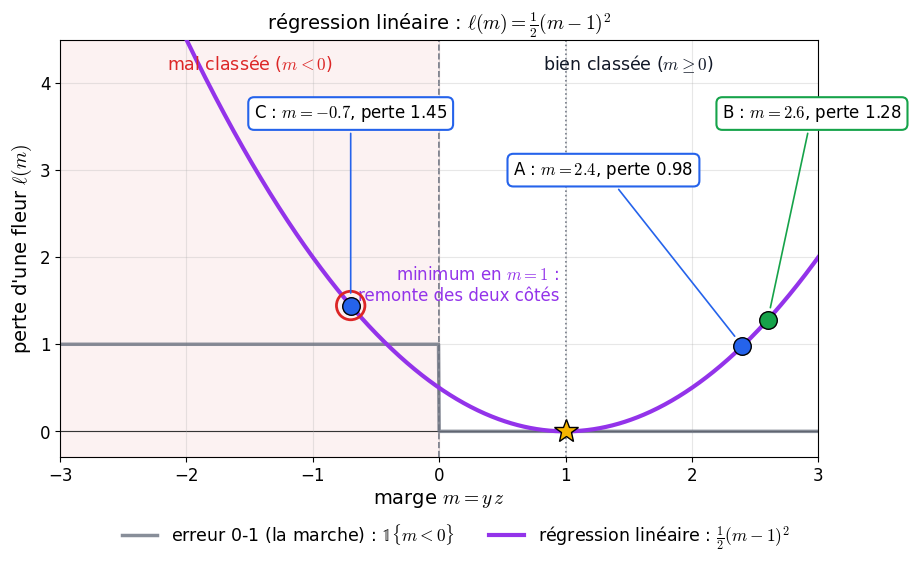

In [16]:
#@title Figure : la perte de la régression linéaire. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_perte('régression linéaire')  # la parabole 1/2 (m - 1)^2, la marche en fond, A, B, C sur la courbe

> **📊** La parabole est nulle en $m = 1$ exactement (l'étoile) et remonte des deux côtés. La marche grise est l'erreur 0-1 : la parabole est au-dessus, sauf juste à gauche de 0 (entre $m = -0.41$ et $0$, elle vaut moins de 1). 🌸 C, mal classée ($m = -0.7$), paie 1.45 ; mais A et B, bien classées, paient 0.98 et 1.28 : être trop bien classé coûte aussi.

### Surprise : une fleur très bien classée ($m = 2$) paie 0.5, autant qu'une fleur pile sur la frontière ($m = 0$).

## 3.2 Perte 2 : le perceptron

### Idée : on ne punit que les erreurs. La perte vaut $-m$ si $m$ est négatif, et 0 sinon.

$$\ell(m) = \max(0, -m) = \begin{cases} -m & \text{si } m < 0 \ (\text{erreur}) \\ 0 & \text{si } m \ge 0 \end{cases}$$

où $m = y\,z$ est la marge de la fleur ; les deux écritures (le $\max$ et la forme par cas) sont la même fonction, et c'est la forme par cas qu'on dérivera à la section 4.

### Ce que paie une fleur, selon sa marge.

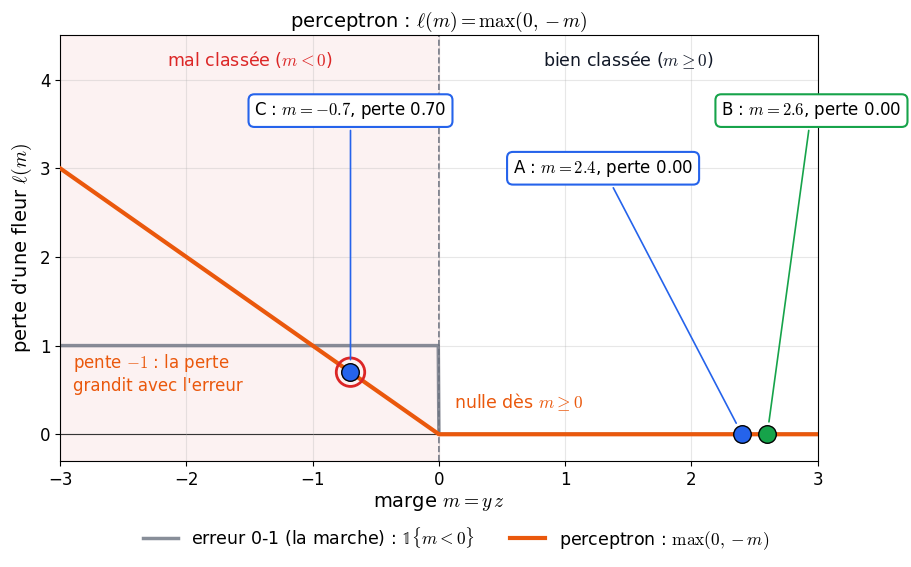

In [17]:
#@title Figure : la perte du perceptron. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_perte('perceptron')  # max(0, -m) : nulle dès que m >= 0

> **📊** Nulle dès que $m \ge 0$ ; sinon, elle grandit avec la taille de l'erreur (pente $-1$). Entre $m = -1$ et $0$, elle vaut moins de 1 : sous la marche grise. 🌸 A et B ne paient rien ; C paie $0.70 = -m_C$, moins que l'erreur 0-1.

### Une fleur bien classée de justesse ($m = 0.01$) ne paie rien : le perceptron s'en contente.

## 3.3 Perte 3 : le SVM

### Idée : on punit les erreurs, et aussi les fleurs trop près de la frontière. La perte vaut $1 - m$ si $m < 1$, et 0 sinon.

$$\ell(m) = \max(0, 1 - m) = \begin{cases} 1 - m & \text{si } m < 1 \\ 0 & \text{si } m \ge 1 \end{cases}$$

où $m = y\,z$ est la marge de la fleur. On l'appelle la perte **charnière** (*hinge loss*) : sa courbe est pliée en $m = 1$, comme une charnière de porte.

### Ce que paie une fleur, selon sa marge.

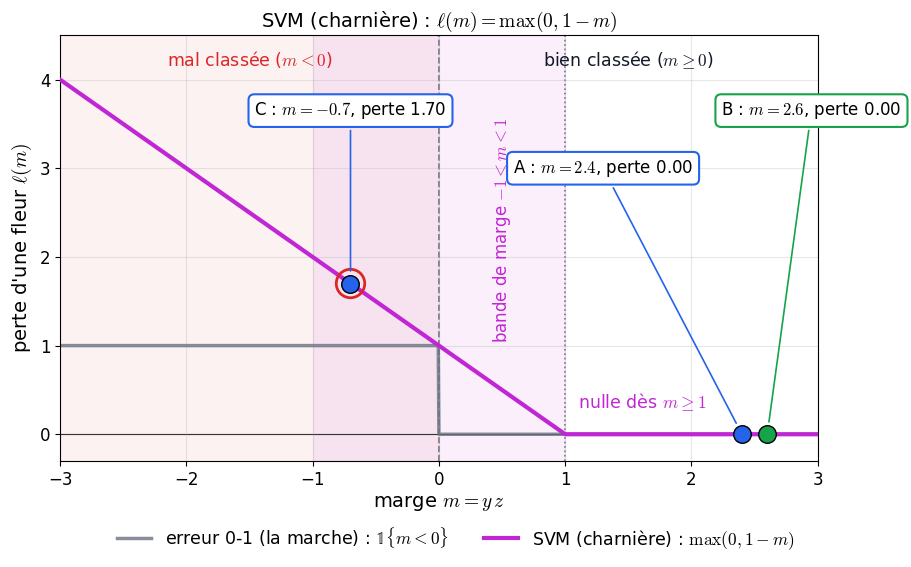

In [18]:
#@title Figure : la perte charnière du SVM. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_perte('SVM (charnière)')  # max(0, 1 - m) : nulle seulement à partir de m = 1

> **📊** C'est le perceptron décalé de 1 : nulle seulement à partir de $m = 1$. Ce décalage la met partout au-dessus de la marche grise : la seule des quatre. 🌸 C paie $1.70 = 1 - m_C$ ; A et B, avec $m \ge 1$, ne paient rien.

### Rappel des mots (section 0.7) : « la marge » tout court, c'est le nombre $m$ ; la **bande de marge** est la zone $-1 < w^\top x < 1$, c'est-à-dire $-1 < m < 1$. Le SVM veut que personne n'y soit et que toutes les fleurs soient du bon côté : $m \ge 1$ pour toutes.

## 3.4 Perte 4 : la régression logistique

### Idée : on punit tout le monde, mais de moins en moins à mesure que $m$ grandit. Une courbe lisse qui descend sans jamais toucher zéro.

$$\ell(m) = \log\!\left(1 + e^{-m}\right) = -\log \sigma(m), \qquad \text{où } \sigma(a) = \frac{1}{1 + e^{-a}}$$

où $m = y\,z$ est la marge, $\log$ est le logarithme naturel et $\sigma$ (« sigma ») est la **sigmoïde** : une fonction en forme de S, qui transforme n'importe quel nombre $a$ en un nombre entre 0 et 1 (on la tracera à la section 9).

### Pourquoi les deux formes sont égales ? Parce que $\dfrac{1}{\sigma(m)} = 1 + e^{-m}$.

$$-\log \sigma(m) = \log \frac{1}{\sigma(m)} = \log\!\left(1 + e^{-m}\right)$$

où l'on a utilisé $-\log a = \log(1/a)$. Dans le code, cette perte s'écrit `np.logaddexp(0, -m)` $= \log(e^0 + e^{-m}) = \log(1 + e^{-m})$ : même formule, calculée sans débordement quand $m$ est très négatif.

### Ce que paie une fleur, selon sa marge.

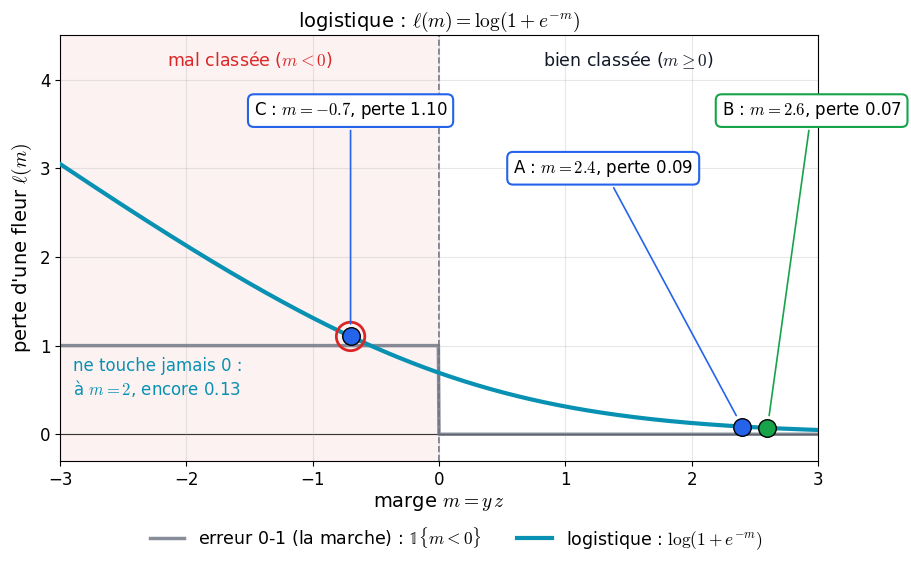

In [19]:
#@title Figure : la perte logistique. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_perte('logistique')  # log(1 + e^{-m}) : ne touche jamais 0

> **📊** Même à $m = 2$, elle paie encore 0.13 ; à $m = 5$, 0.007 ; elle ne vaut jamais exactement 0. En $m = 0$, elle vaut $\log 2 \approx 0.69$ : sous la marche grise entre $m = -0.54$ et $0$. 🌸 A et B paient 0.09 et 0.07 ; C paie 1.10.

### Cette perte a un sens de probabilité : on verra à la section 9 que $\sigma(m)$ est la probabilité que le modèle donne à la vraie classe de la fleur. Sa perte, c'est $-\log$ de cette probabilité : grande quand le modèle se trompe avec assurance, presque nulle quand il a raison avec assurance.

## 3.5 Les cinq courbes sur un même axe

### La marche et les quatre pertes, superposées : on voit d'un coup d'œil laquelle reste au-dessus de la marche, et où les autres passent dessous.

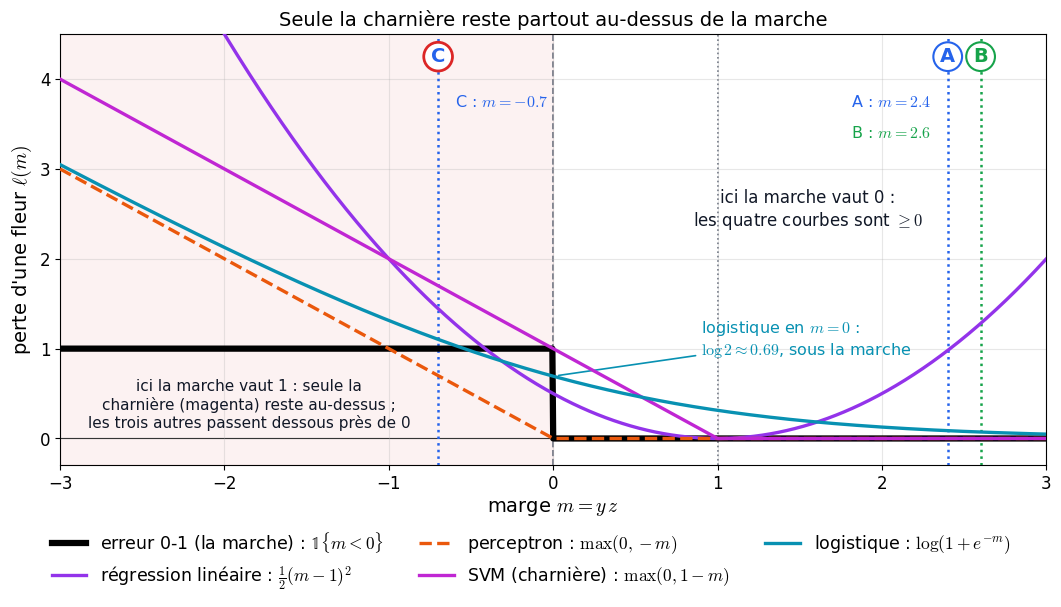

In [20]:
#@title Figure : les cinq pertes superposées. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_cinq_pertes()  # la marche noire épaisse et les quatre pertes de remplacement, A, B, C en repères

> **📊** À droite de $m = 0$, la marche vaut 0 et les quatre courbes sont $\ge 0$. À gauche, la marche vaut 1 : seule la charnière (magenta) reste au-dessus partout ; la parabole, le perceptron et la logistique passent sous la marche juste à gauche de 0 (la logistique vaut $\log 2 \approx 0.69$ en $m = 0$), puis repassent au-dessus et grandissent sans fin quand $m$ devient très négatif. Régression linéaire (violet) : une parabole, fond en $m = 1$. Perceptron (orange, tireté) : pente $-1$ puis zéro dès $m = 0$. SVM (magenta) : pareil, mais zéro seulement à partir de $m = 1$. Logistique (sarcelle) : descend sans toucher zéro. Les pointillés verticaux sont 🌸 A, B et C.

### ↩️ Retour à la démo A : les deux courbes lisses du panneau de droite étaient la perte du SVM (magenta) et la logistique (sarcelle), moyennées sur les dix points. Elles ont une pente là où l'escalier n'en a pas.

### ⏩ ↩️ Retour à la démo C : les quatre barres de couleur du panneau de droite étaient ces quatre pertes, moyennées sur les 75 fleurs (la barre noire était le taux d'erreur).

### Le code qui suit écrit les cinq pertes en Python, en fonction de la marge `m` : c'est la « Question 1 » du devoir (le premier des cinq morceaux de code à écrire soi-même ; ici, il est fourni). Il les trace une par une, puis superposées.

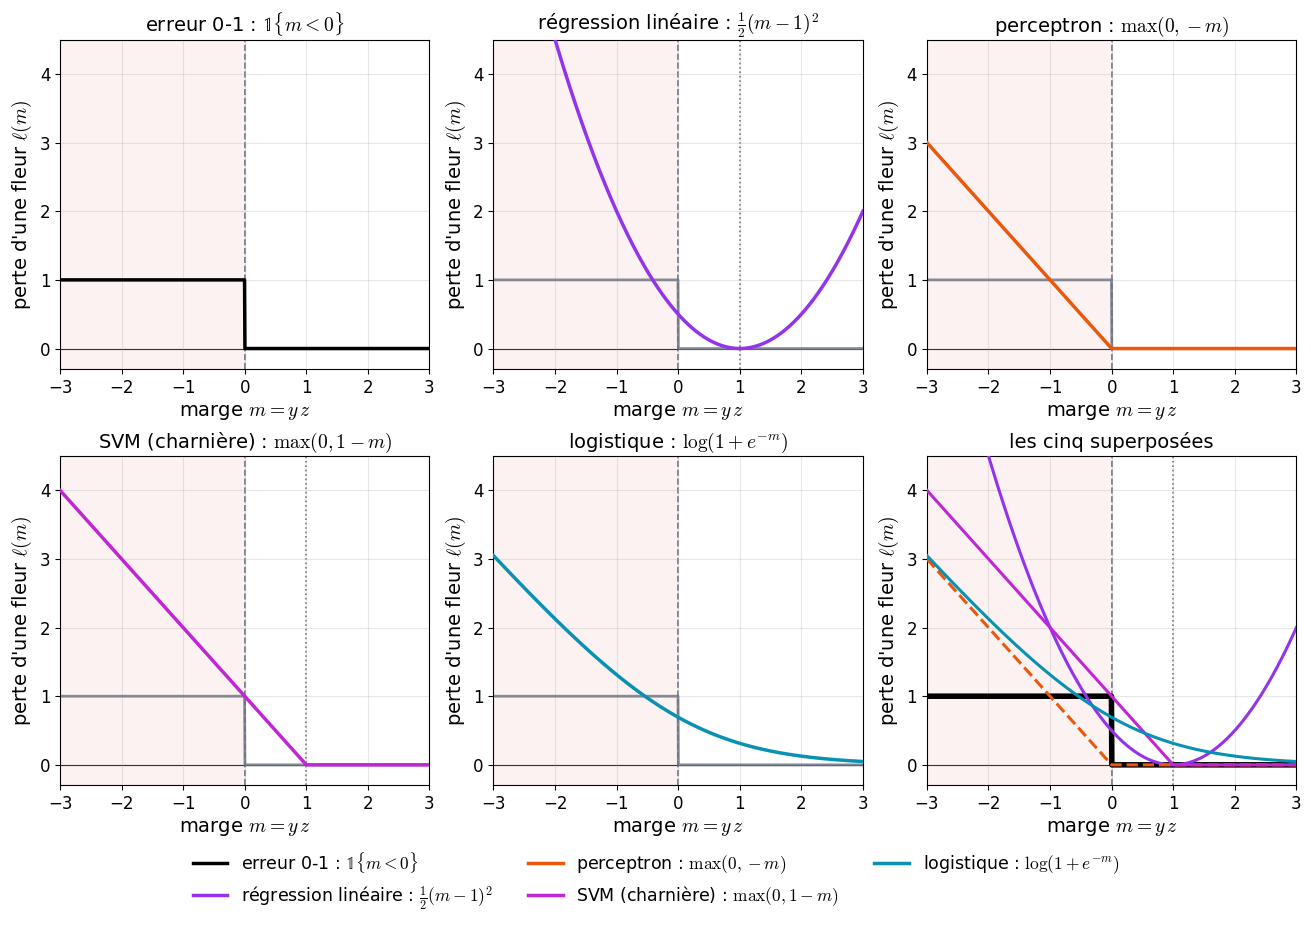

In [21]:
#@title Code : les cinq pertes (« Question 1 ») et leur figure. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
# Question 1 : les cinq pertes, en fonction de la marge m = y z (un tableau de marges ; une valeur par fleur)

def error_counter(m):
    """Erreur 0-1 : 1 si la fleur est mal classée (m < 0), 0 sinon ; c'est la marche."""
    return (m < 0).astype(float)  # booléens changés en 0.0 / 1.0, même forme que m

def linearloss(m):
    """Perte de la régression linéaire : 1/2 (m - 1)^2, égale à 1/2 (z - y)^2 puisque y^2 = 1."""
    return 0.5 * (m - 1) ** 2  # élément par élément

def logisticloss(m):
    """Perte logistique : log(1 + e^{-m}) = -log sigma(m)."""
    return np.logaddexp(0, -m)  # log(e^0 + e^{-m}) = log(1 + e^{-m}), sans débordement si m est très négatif

def perceptronloss(m):
    """Perte du perceptron : max(0, -m)."""
    return np.maximum(0, -m)  # np.maximum compare élément par élément

def svmloss(m):
    """Perte charnière (SVM) : max(0, 1 - m)."""
    return np.maximum(0, 1 - m)  # nulle dès que m >= 1

# ----- Tracé : un panneau par perte (la marche 0-1 en gris en fond), puis un sixième panneau qui les superpose -----
mm = np.linspace(-3, 3, 1000)  # 1000 valeurs de la marge m entre -3 et 3
pertes_q1 = [('erreur 0-1', error_counter), ('régression linéaire', linearloss), ('perceptron', perceptronloss),
             ('SVM (charnière)', svmloss), ('logistique', logisticloss)]  # dans l'ordre du texte

fig, axes = figure(3, nrows=2)  # grille 2 x 3 de panneaux (mise en page constrained, légende commune en bas)
for ax, (nom, perte) in zip(axes, pertes_q1):  # un panneau par perte
    valeurs = perte(mm)  # la perte sur toute la grille
    if valeurs is None:  # fonction pas encore écrite
        continue  # panneau laissé vide
    if nom != 'erreur 0-1':  # la marche en fond, pour voir que la courbe reste au-dessus
        ax.plot(mm, error_counter(mm), c=GRIS, lw=2, alpha=.8, zorder=2)  # la marche, en gris
    ax.plot(mm, valeurs, lw=2.5, c=COULEURS_PERTES[nom], zorder=3, label=f'{nom} : {FORMULES_PERTES[nom]}')  # la courbe, en sa couleur
    preparer_axe_marge(ax, titre=f'{nom} : {FORMULES_PERTES[nom]}', marge_svm=nom in ('régression linéaire', 'SVM (charnière)'))  # cadre commun (zone m < 0, repères)
for nom, perte in pertes_q1:  # sixième panneau : les cinq courbes superposées
    valeurs = perte(mm)  # la perte sur toute la grille
    if valeurs is None:  # fonction pas encore écrite
        continue  # on la saute
    axes[5].plot(mm, valeurs, lw=4 if nom == 'erreur 0-1' else 2.2, ls='--' if nom == 'perceptron' else '-', c=COULEURS_PERTES[nom], zorder=3)  # la marche épaisse, le perceptron tireté
preparer_axe_marge(axes[5], titre='les cinq superposées')  # même cadre
legende(fig, ncol=3)  # légende commune, en bas
plt.show()  # affiche

> **📊** Le trait pointillé, là où il est utile (régression linéaire, SVM, superposition), marque $m = 1$ : le minimum de la parabole et le coin de la charnière. Le sixième panneau est la figure précédente, sans les fleurs.

## 3.6 Démo B : une seule fleur, quatre pertes

### La pente de $\ell$ au point $m$ se note $\ell'(m)$ : c'est sa dérivée, qu'on calculera à la section 4. Pente négative = la fleur voudrait une marge plus grande ; pente nulle = la fleur ne demande plus rien.

> **📊** À gauche : en abscisse la marge $m$ d'une seule fleur ; en ordonnée ce que chaque perte lui fait payer, $\ell(m)$ ; le curseur règle $m$ et déplace un point sur chaque courbe. Les lettres 🌸 A, B, C en haut rappellent les marges des trois fleurs du fil rouge.

> **📊** À droite : la pente $\ell'(m)$ de chaque courbe, au même $m$. Zéro veut dire « cette fleur ne demande plus rien ». La marche 0-1 (noir) a une pente nulle partout, et pas de pente du tout en $m = 0$ (point vide) : c'est pour ça qu'on l'a remplacée. Aux coins du perceptron ($m = 0$) et du SVM ($m = 1$), le point plein est la valeur que prend le code (0), le point vide l'autre pente ($-1$). À la section 4, cette pente deviendra une force ; pour l'instant, retenez le signe.

> **🔮 Avant de bouger le curseur, prédisez :** Une fleur a une marge $m = 2$ : bien classée, loin de la frontière. Laquelle des quatre pertes la pénalise encore ? Et dans quel sens est sa pente ?

> **🔮 Avant de bouger le curseur, prédisez :** Et une fleur à $m = 0.5$, bien classée de justesse ?

In [22]:
#@title Démo B : la perte et la pente d'une seule fleur (curseur). Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
demo_B()  # la perte l(m) et sa pente l'(m) pour une seule fleur, selon sa marge m

> **🧠 Vérifiez votre prédiction :** <details><summary>Cliquez pour la réponse courte.</summary>$m = 2$ : le perceptron et le SVM font payer 0, la logistique 0.13, mais la régression linéaire fait payer 0.5, et sa pente $\ell'(2) = +1$ est positive : elle voudrait une marge plus PETITE. $m = 0.5$ : le perceptron est satisfait (0, pente 0), le SVM fait payer 0.5 avec une pente $-1$ : il exige $m \ge 1$.</details>

## 3.7 🌸 Fil rouge : A, B et C dans les quatre pertes

### Le code passe A, B et C dans les quatre pertes, avec le même $w = (1, 1, -0.4)$ qu'à la section 0 : ce sont les nombres écrits sur les quatre figures de cette section.

In [23]:
#@title Fil rouge : les quatre pertes de A, B et C. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
tableau_pertes_abc()  # ce que chaque perte fait payer à A, B et C

w = (w₀, w₁, b) = (1.00, 1.00, -0.40)   perte ℓ(m) de chaque fleur, selon la perte choisie
fleur   marge m            erreur 0-1   régression linéaire            perceptron       SVM (charnière)            logistique
A          2.40                 0.000                 0.980                 0.000                 0.000                 0.087
B          2.60                 0.000                 1.280                 0.000                 0.000                 0.072
C         -0.70                 1.000                 1.445                 0.700                 1.700                 1.103
Lecture : ℓ(m) = 0 veut dire « cette fleur ne coûte rien à cette perte ».


### Lecture : A et B ne paient rien au perceptron ni au SVM, presque rien à la logistique (0.09 et 0.07), mais 0.98 et 1.28 à la régression linéaire.

### C, mal classée ($m = -0.7$), paie partout : le plus cher au SVM (1.70) et le moins cher au perceptron (0.70).

> **🧠 Vérifiez :** <details><summary>Pourquoi la régression linéaire fait-elle payer 0.98 à A, qui est pourtant bien classée avec une marge de 2.4 ?</summary>Parce qu'elle veut une marge <b>exactement</b> égale à 1 : $\ell(2.4) = \tfrac12 (2.4 - 1)^2 = \tfrac12 \times 1.96 = 0.98$. Être trop bien classé lui coûte autant qu'être trop peu.</details>

> **🧠 Vérifiez :** <details><summary>Le perceptron et le SVM font tous deux payer 0 à A. En quoi diffèrent-ils alors ?</summary>Sur les fleurs avec $0 \le m \lt 1$ (dans la bande de marge) : le perceptron est satisfait dès que $m \ge 0$, le SVM exige $m \ge 1$. Pour C ($m = -0.7$), la différence est le décalage de 1 : $0.70$ contre $1.70$.</details>

## 3.8 L'objectif complet

### Jusqu'ici, une fleur à la fois. Pour les 75 fleurs, on fait la moyenne, et on ajoute un élastique.

### La perte moyenne (sans régularisation) : chaque fleur $i$ paie $\ell(m_i)$, et on fait la moyenne.

$$\frac{1}{n}\sum_{i=1}^{n} \ell(m_i)$$

où $m_i = y_i\,z_i = y_i\,w^\top x_i$ est la marge de la fleur numéro $i$ et $n = 75$ le nombre de fleurs d'entraînement. C'est ce que montraient les barres de la démo C.

### Pourquoi ne pas s'arrêter là ? Dans la démo C, multiplier $w$ par 3 ne change pas la frontière mais multiplie toutes les marges par 3, donc change toutes les pertes.

### Conséquence : sur des fleurs séparables comme les nôtres, grossir $w$ fait baisser la perte logistique sans jamais s'arrêter : elle n'a pas de minimum, et la descente partirait à l'infini sans que la frontière s'améliore. La charnière du SVM, elle, tombe à 0 dès que toutes les marges dépassent 1, mais elle ne départage pas les frontières qui y parviennent : il y en a une infinité.

### Le remède : un élastique accroché à $w = 0$, le terme $\frac{\lambda}{2}\lVert w\rVert^2$. Plus $w$ grossit, plus il tire fort ; $\lambda$ (« lambda ») règle sa raideur, et fixe donc l'échelle de $w$.

$$\boxed{\,L(w) = \frac{1}{n}\sum_{i=1}^{n} \ell(m_i) + \frac{\lambda}{2}\,\lVert w\rVert^2\,} \tag{3}$$

où $m_i = y_i\,w^\top x_i$ est la marge de la fleur $i$, $n = 75$, $\lambda \ge 0$ est la force de la régularisation (`reg` dans le code) et $\lVert w\rVert^2 = w_0^2 + w_1^2 + b^2$ est la norme au carré de $w$, biais compris (le code régularise aussi le biais, par simplicité ; en pratique on l'exclut souvent). En code : `np.mean(pertes) + 0.5 * reg * np.sum(w ** 2)`.

### $L(w)$ est l'objectif : la note d'erreur de la section 0, qu'on va faire descendre. C'est ce que calcule la méthode `loss` des classes de la section 5.

### Ce que change $\lambda$, vu d'en haut : les lignes de niveau de $L$ sur le plan $(w_0, w_1)$, pour la perte logistique, à biais fixé.

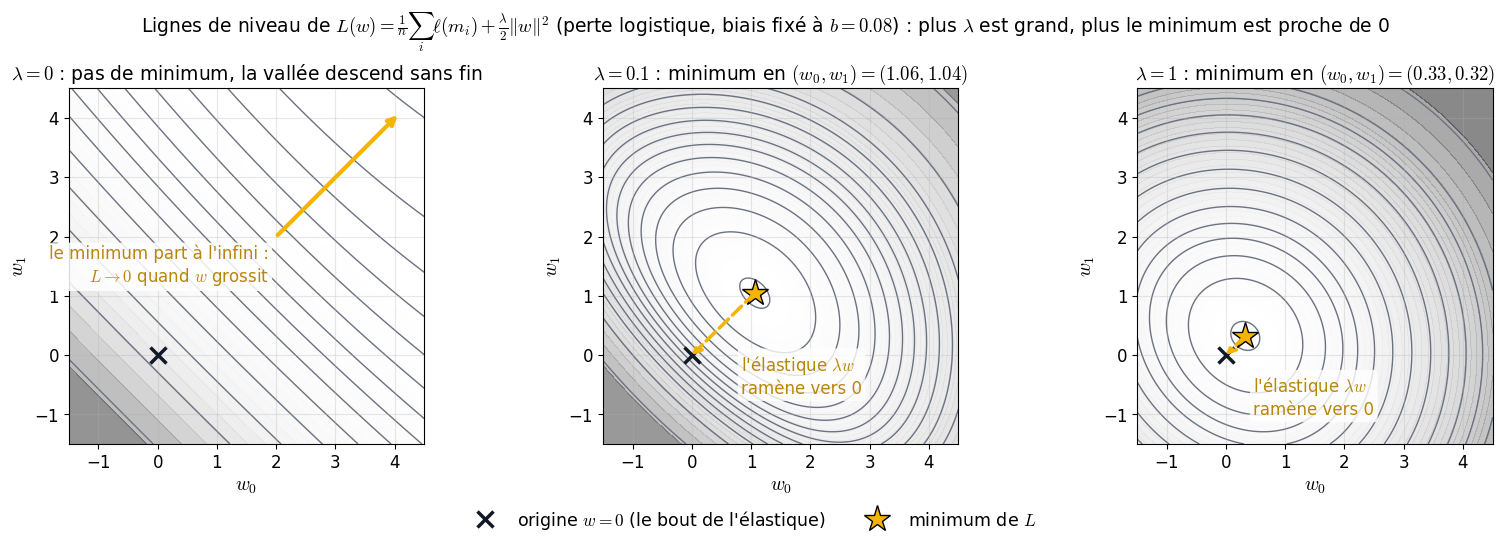

λ = 0.1 : minimum en (w0, w1) = (1.06, 1.04), ‖(w0, w1)‖ = 1.49
λ = 1 : minimum en (w0, w1) = (0.33, 0.32), ‖(w0, w1)‖ = 0.46


In [24]:
#@title Figure : l'effet de λ sur la surface de L. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_effet_lambda()  # lignes de niveau de L(w0, w1) pour lambda = 0, 0.1 et 1 (perte logistique, biais fixé)

> **📊** Clair = $L$ petit, foncé = $L$ grand ; la croix est $w = 0$, le bout de l'élastique. À gauche, $\lambda = 0$ : pas d'élastique, les lignes de niveau sont des droites et la vallée descend sans fin vers le haut à droite (la flèche) : le minimum part à l'infini. Au milieu, $\lambda = 0.1$ : la vallée se referme en bol, le minimum (l'étoile) existe. À droite, $\lambda = 1$ : l'élastique est raide, le minimum est tout près de 0.

### Dans le labo, $\lambda$ = `reg` vaut 0.1 pour trois méthodes et 0 pour le perceptron (dont la perte, nulle dès que tout est bien classé, n'a pas besoin d'élastique). On verra ce qu'il change sur la frontière à la section 8 (démo G).

### ↩️ Retour à la démo C : les barres de droite étaient $\frac{1}{n}\sum_{i=1}^{n} \ell(m_i)$, la perte moyenne sans l'élastique ; c'est pour ça qu'elles bougeaient quand on multipliait $w$ par 3.

### Il reste à faire descendre $L(w)$. Pour ça, il faut sa pente par rapport à $w$ : le gradient, section 4.

## 4. Le gradient, une étape à la fois

> **📖 Rappel de notation.** Une fleur a une entrée $x = (x_0, x_1, 1)$, une étiquette $y \in \{-1, +1\}$, un score $z = w^\top x$ (1) et une marge $m = y\,z$ (2) ; les poids sont $w = (w_0, w_1, w_2)$ avec $w_2 = b$ le biais. La perte d'une fleur est $\ell(m)$ (section 3 : quatre choix) et l'objectif de tout le jeu de données est $L(w) = \frac1n\sum_{i=1}^{n} \ell(m_i) + \frac{\lambda}{2}\lVert w\rVert^2$ (3). Nouveaux dans cette section : $\ell'(m) = \dfrac{d\ell}{dm}$, la pente de $\ell$, et $\nabla_w$, le gradient par rapport à $w$.
>
> Dans le code : `marges` contient les $m_i$, `coef` les $\ell'(m_i)$, et `self.gradient(X, y)` calcule $\nabla_w L$.

### Le gradient dit comment la perte change quand on bouge chaque poids.

$$\nabla_w \ell = \left(\frac{\partial \ell}{\partial w_0},\ \frac{\partial \ell}{\partial w_1},\ \frac{\partial \ell}{\partial w_2}\right)$$

où $\nabla_w \ell$ (lire « nabla », ou « gradient de $\ell$ par rapport à $w$ ») est le vecteur des trois dérivées partielles de la perte $\ell$ d'une fleur : $\partial \ell / \partial w_j$ dit de combien $\ell$ change quand on bouge le seul poids $w_j$ d'un tout petit peu ($j \in \{0, 1, 2\}$). Le gradient a donc la même taille que $w$ : trois nombres.

### On le calcule en suivant une chaîne de trois maillons.

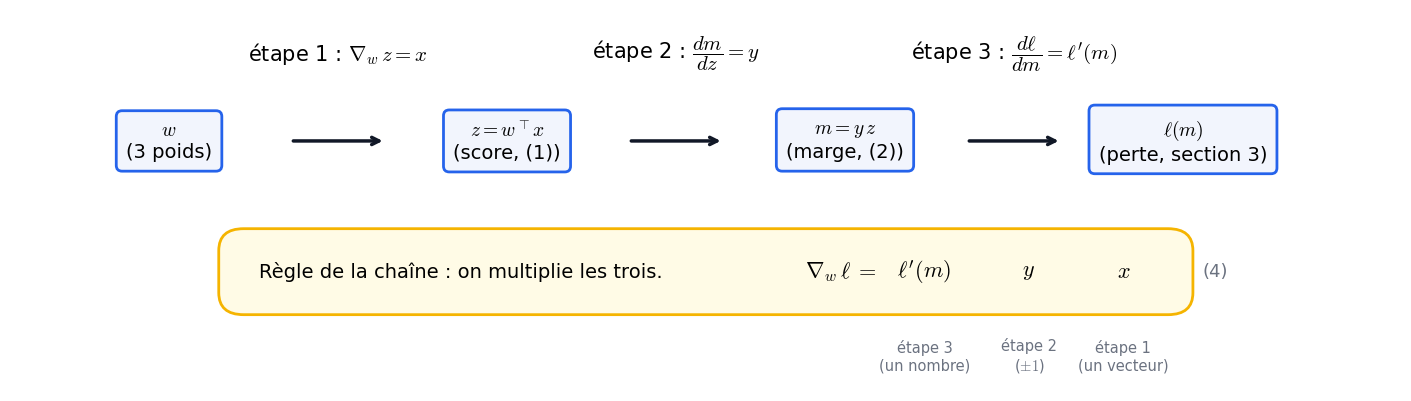

In [25]:
#@title Figure : la chaîne w → z → m → ℓ et ses trois dérivées. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_chaine()  # les trois maillons, leurs dérivées (étapes 1 à 3) et la règle de la chaîne (équation (4))

### Les trois boîtes : les poids $w$ donnent le score $z$, le score donne la marge $m$, la marge donne la perte $\ell$.

### On dérive chaque maillon séparément, puis on multiplie les trois.

## 4.1 Étape 1 : le maillon $w \to z$

### Promis à la section 0 : voici le calcul composante par composante, où le biais $b$ s'appelle $w_2$.

### Le score est une somme pondérée.

$$z = w_0\,x_0 + w_1\,x_1 + w_2\,x_2$$

où $x_2 = 1$ (la colonne de 1 de la section 0) et $w_2 = b$ : c'est l'équation (1), $z = w^\top x$, écrite terme à terme.

### Si on bouge $w_0$ d'un petit peu, $z$ bouge de $x_0$ fois ce petit peu.

### Pareil pour les deux autres poids.

$$\frac{\partial z}{\partial w_0} = x_0, \qquad \frac{\partial z}{\partial w_1} = x_1, \qquad \frac{\partial z}{\partial w_2} = x_2 = 1$$

où la dernière vaut 1 parce que $x_2 = 1$ : bouger le biais bouge le score d'autant, quelle que soit la fleur.

### En vecteur : le gradient du score, c'est l'entrée.

$$\nabla_w z = \left(\frac{\partial z}{\partial w_0},\ \frac{\partial z}{\partial w_1},\ \frac{\partial z}{\partial w_2}\right) = (x_0,\ x_1,\ 1) = x$$

## 4.2 Étape 2 : le maillon $z \to m$

### La marge est $m = y\,z$ (2), et l'étiquette $y$ est une constante ($+1$ ou $-1$).

### Donc la dérivée est simplement $y$.

$$\frac{dm}{dz} = y$$

## 4.3 Étape 3 : le maillon $m \to \ell$

### C'est la dérivée ordinaire d'une fonction d'une seule variable : la pente des courbes de la section 3.

### On la note $\ell'(m)$.

$$\ell'(m) = \frac{d\ell}{dm}$$

où le prime signale une fonction d'une seule variable ($m$), par opposition aux dérivées partielles de l'étape 1.

### C'est le seul endroit où les quatre méthodes diffèrent.

## 4.4 Étape 4 : on multiplie les trois maillons

### Règle de la chaîne : le gradient de la perte d'une fleur, c'est le produit des trois dérivées.

$$\boxed{\,\nabla_w \ell = \underbrace{\ell'(m)}_{\text{étape 3 : un nombre}}\ \underbrace{y}_{\text{étape 2 : } \pm 1}\ \underbrace{x}_{\text{étape 1 : un vecteur}}\,} \tag{4}$$

où $m = y\,w^\top x$ est la marge de la fleur ; $\ell'(m)$ et $y$ sont des nombres, $x = (x_0, x_1, 1)$ un vecteur à trois composantes, et le produit $\ell'(m)\,y\,x$ est ce vecteur multiplié par un nombre.

### Le gradient d'une fleur est toujours un nombre fois $x$.

### Le nombre $\ell'(m)\,y$ dit avec quelle force la fleur pousse $w$, et dans quel sens : on l'appelle la **poussée** ; sa valeur absolue $\lvert \ell'(m) \rvert$ est la **force**.

### Vocabulaire du tir à la corde, une fois pour toutes : chaque fleur **tire** sur $w$ ; sa **traction** est le vecteur $-\ell'(m)\,y\,x$ (l'opposé de son gradient (4)) ; sa **poussée** est le nombre $\ell'(m)\,y$ ; sa **force** est $\lvert\ell'(m)\rvert$. Elle tire **en avant** (vers une marge plus grande) si $\ell'(m) < 0$, **en arrière** si $\ell'(m) > 0$.

### Le vecteur $x$ dit dans quelle direction.

### Pourquoi « pente négative = pousse en avant » : une itération sur une seule fleur.

$$w_{\text{après}} = w - \eta\,\ell'(m)\,y\,x \quad\Rightarrow\quad m_{\text{après}} - m = y\,(w_{\text{après}} - w)^\top x = -\eta\,\ell'(m)\,\underbrace{y^2}_{= 1}\,\lVert x\rVert^2 = -\eta\,\ell'(m)\,\lVert x\rVert^2$$

où $\eta$ (« êta ») est la taille du pas, un nombre positif qu'on règle à la section 5, et $\lVert x\rVert^2 = x_0^2 + x_1^2 + 1 > 0$. La deuxième égalité vient de $m = y\,w^\top x$ : seul $w$ a changé, et $x^\top x = \lVert x\rVert^2$. Conclusion : si $\ell'(m) < 0$, la marge de cette fleur **monte** (on la pousse « en avant », vers « mieux classée ») ; si $\ell'(m) > 0$, elle **baisse** (on la tire « en arrière »).

> **🧠 Vérifiez :** <details><summary>Pourquoi le gradient d'une fleur est-il toujours parallèle à son entrée, quelle que soit la perte ?</summary>Parce que $w$ n'entre dans la perte que par le score $z = w^\top x$, dont le gradient est $x$ (étape 1) ; les étapes 2 et 3 multiplient ensuite par des nombres ($y$ puis $\ell'(m)$), pas par des vecteurs.</details>

### ↩️ Le panneau de droite de la démo B était déjà $\ell'(m)$ : relisez-le maintenant comme une poussée. Pente négative = la fleur pousse $w$ pour augmenter sa marge ; pente nulle = elle ne compte plus.

## 4.5 Les quatre $\ell'(m)$, une à la fois

### Régression linéaire : à gauche la perte, à droite sa pente.

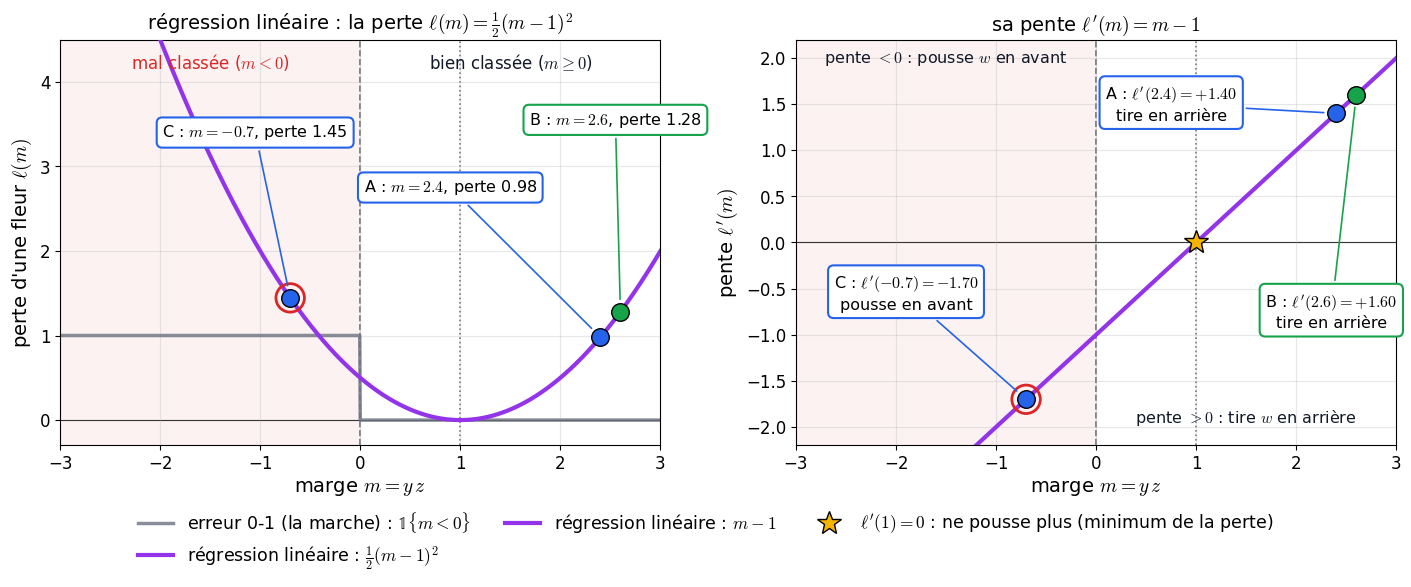

In [26]:
#@title Figure : régression linéaire, la perte et sa pente. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_pente('régression linéaire')  # perte 1/2 (m - 1)^2 à gauche, pente m - 1 à droite, avec A, B, C

> **📊 🌸** À gauche, la perte $\ell(m)$ ; à droite, sa pente $\ell'(m)$, avec le même axe $m$. La fleur C ($m = -0.7$, entourée de rouge) a une pente $\ell'(-0.7) = -1.7$ : négative, elle pousse $w$ en avant. A ($m = 2.4$) a une pente $+1.4$ et B ($m = 2.6$) une pente $+1.6$ : positives, elles tirent $w$ en arrière alors qu'elles sont bien classées. L'étoile en $m = 1$ : pente nulle, la fleur ne pousse plus.

### Dérivée d'un carré.

$$\ell(m) = \tfrac12 (m - 1)^2 \quad\Rightarrow\quad \ell'(m) = m - 1$$

### Pente négative avant $m = 1$ : la fleur pousse $w$ en avant.

### Pente positive après $m = 1$ : la fleur tire $w$ en arrière.

### Avec $y^2 = 1$, on retrouve la forme habituelle, celle du code.

$$\nabla_w \ell = (m - 1)\,y\,x = (y\,z - 1)\,y\,x = (\underbrace{y^2}_{= 1}\,z - y)\,x = (z - y)\,x = (w^\top x - y)\,x$$

où $z = w^\top x$ est le score (1). Le nombre $z - y = \ell'(m)\,y$ est la poussée de cette fleur : dans la classe de la section 6, c'est `coef * y` avec `coef = marges - 1`, et le gradient de la fleur $i$ s'écrit `(coef[i] * y[i]) * X[i]`.

### Perceptron : à gauche la perte, à droite sa pente.

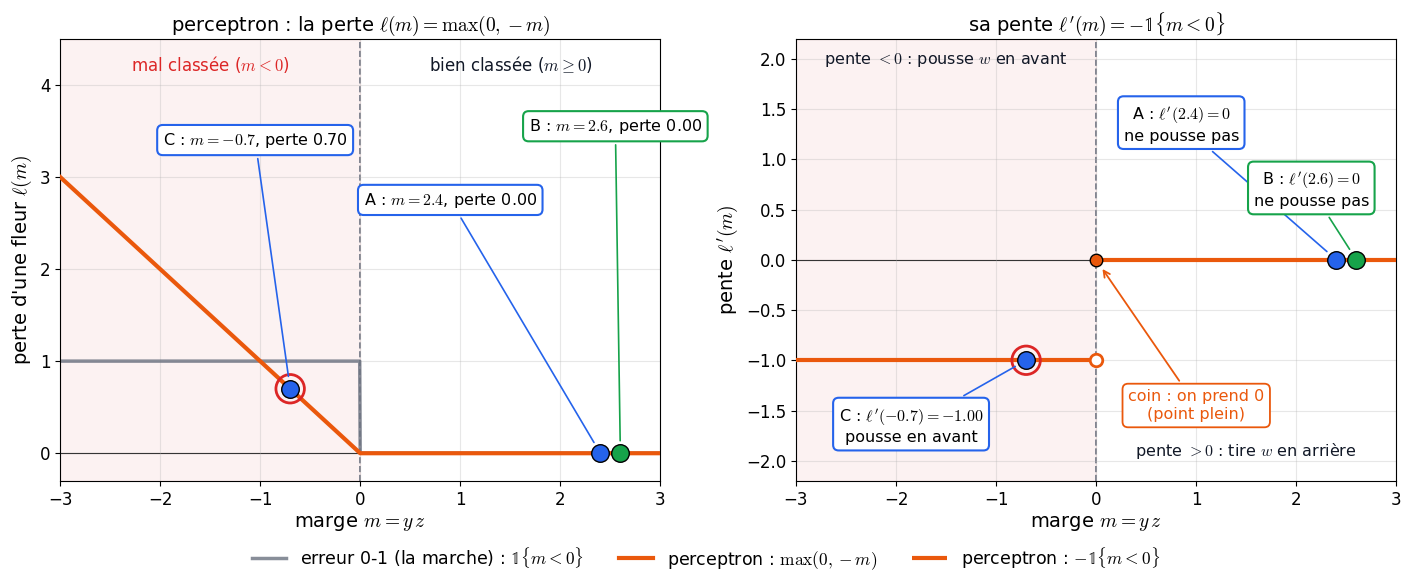

In [27]:
#@title Figure : perceptron, la perte et sa pente. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_pente('perceptron')  # perte max(0, -m) à gauche, pente -1{m < 0} à droite, avec A, B, C et le coin en m = 0

> **📊 🌸** À droite, la pente vaut $-1$ pour C (mal classée) et $0$ pour A et B : seule C pousse. Au coin $m = 0$, le point plein en 0 est la valeur que prend le code, le point vide en $-1$ l'autre pente (sous-section 4.6).

### Un $\max$ se dérive en séparant les deux cas.

$$\ell(m) = \max(0, -m) = \begin{cases} -m & \text{si } m < 0 \ (\text{erreur}) \\ 0 & \text{si } m \ge 0 \end{cases} \quad\Rightarrow\quad \ell'(m) = \begin{cases} -1 & \text{si } m < 0 \\ 0 & \text{si } m > 0 \end{cases}$$

### En une ligne, avec la fonction indicatrice.

$$\ell'(m) = -\mathbb{1}\{m < 0\}$$

où $\mathbb{1}\{m < 0\}$ vaut 1 si la fleur est mal classée et 0 sinon (section 2).

### Donc $\nabla_w \ell = -y\,x$ pour les erreurs, et $0$ pour toutes les autres fleurs.

$$\nabla_w \ell = -\mathbb{1}\{m < 0\}\,y\,x = \begin{cases} -y\,x & \text{si } m < 0 \ (\text{erreur}) \\ 0 & \text{sinon} \end{cases}$$

où la première forme vient de (4) avec $\ell'(m) = -\mathbb{1}\{m < 0\}$. Dans la classe de la section 7, cette pente s'écrit `coef = -(marges < 0)`.

### SVM : à gauche la perte, à droite sa pente.

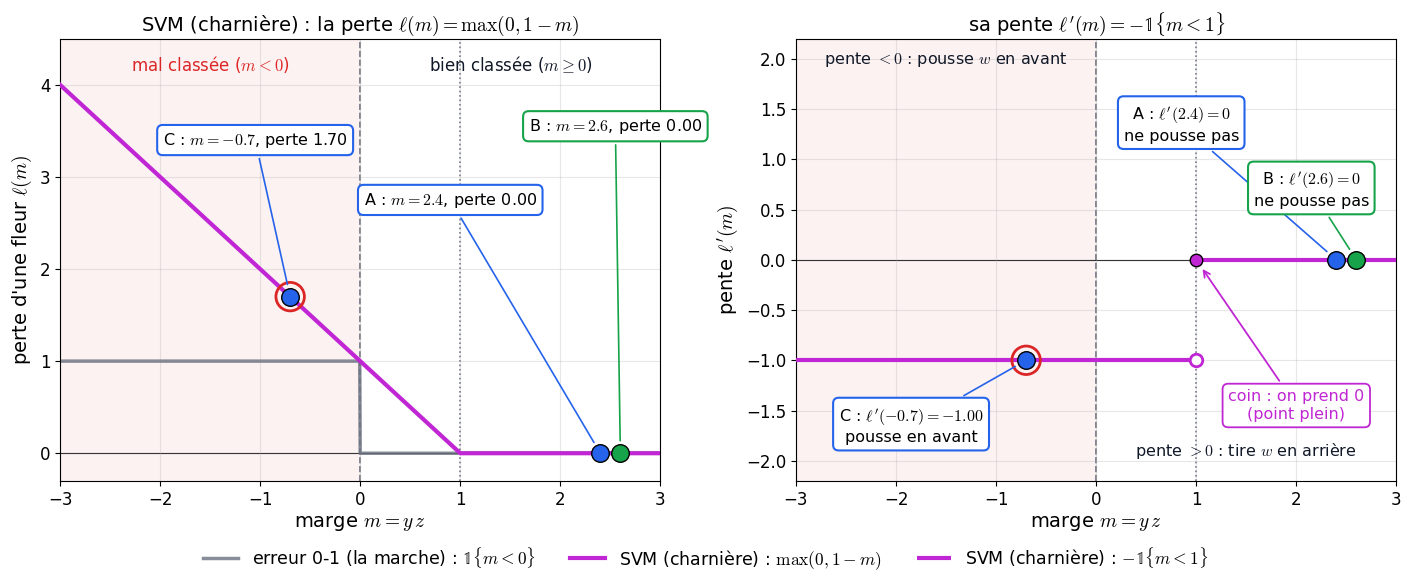

In [28]:
#@title Figure : SVM, la perte et sa pente. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_pente('SVM (charnière)')  # perte max(0, 1 - m) à gauche, pente -1{m < 1} à droite, avec A, B, C et le coin en m = 1

> **📊 🌸** Même escalier que le perceptron, mais le coin est en $m = 1$ : la pente vaut $-1$ aussi pour une fleur bien classée de justesse ($0 \le m < 1$). Pour A, B et C rien ne change par rapport au perceptron : C pousse, A et B non.

### Mêmes deux cas, mais le seuil est en $m = 1$ au lieu de $0$.

$$\ell(m) = \max(0, 1 - m) = \begin{cases} 1 - m & \text{si } m < 1 \\ 0 & \text{si } m \ge 1 \end{cases} \quad\Rightarrow\quad \ell'(m) = -\mathbb{1}\{m < 1\}$$

### Donc le gradient est $-y\,x$ pour les erreurs et pour les fleurs dans la bande de marge, $0$ ailleurs.

$$\nabla_w \ell = -\mathbb{1}\{m < 1\}\,y\,x = \begin{cases} -y\,x & \text{si } m < 1 \ (\text{erreur, ou dans la bande de marge}) \\ 0 & \text{sinon} \end{cases}$$

où « dans la bande de marge » désigne ici la moitié de la bande du bon côté, $0 \le m < 1$ : bien classée, mais trop près de la frontière (l'autre moitié, $-1 < m < 0$, est déjà comptée dans les erreurs). Dans la classe de la section 8, `coef = -(marges < 1)`.

### Une fleur bien classée mais dans la bande de marge pousse encore : c'est ce qui vide la bande, de largeur $2 / \lVert (w_0, w_1)\rVert$, et éloigne la frontière des fleurs les plus proches (section 8).

### Régression logistique : à gauche la perte, à droite sa pente.

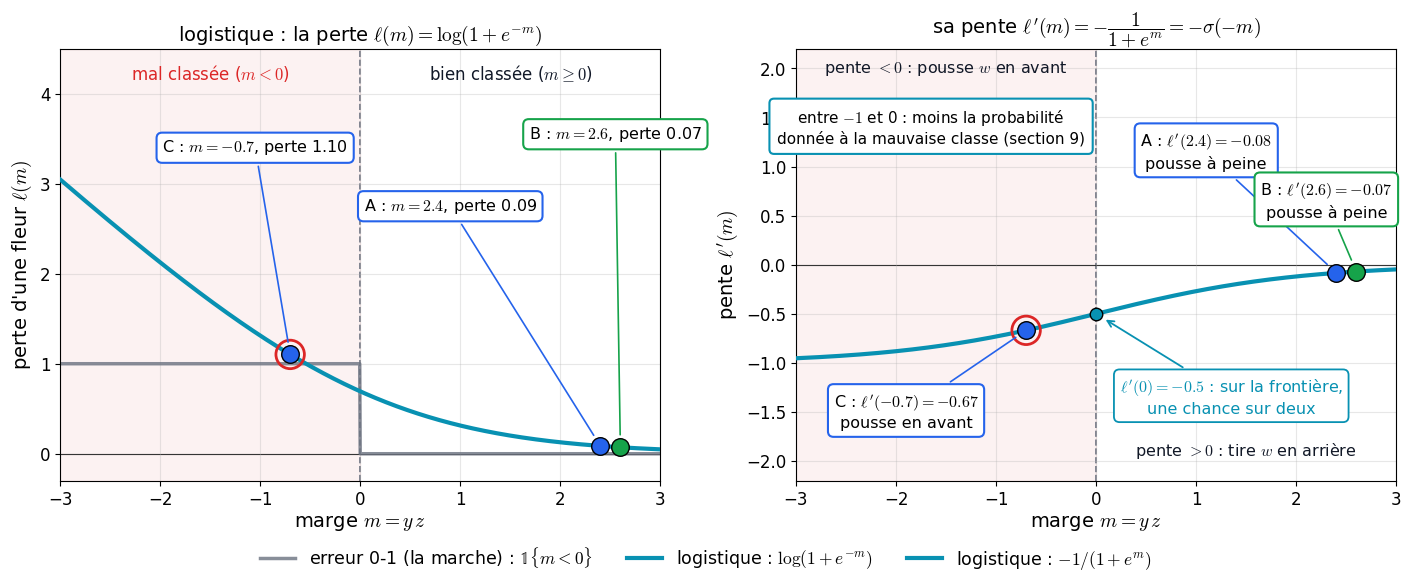

In [29]:
#@title Figure : régression logistique, la perte et sa pente. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_pente('logistique')  # perte log(1 + e^{-m}) à gauche, pente -1 / (1 + e^m) à droite, avec A, B, C

> **📊 🌸** La pente est une courbe lisse, toujours entre $-1$ et $0$ : $-0.67$ pour C, $-0.08$ pour A et $-0.07$ pour B. Tout le monde pousse en avant, mais les fleurs bien classées à peine. Sur la frontière ($m = 0$), $\ell'(0) = -0.5$.

### Dérivée d'un $\log$ : un sur l'intérieur, fois la dérivée de l'intérieur.

$$\ell(m) = \log(1 + e^{-m}) \quad\Rightarrow\quad \ell'(m) = \frac{1}{1 + e^{-m}} \times (-e^{-m}) = \frac{-e^{-m}}{1 + e^{-m}}$$

où l'intérieur est $1 + e^{-m}$, de dérivée $-e^{-m}$.

### On multiplie le haut et le bas par $e^{m}$ pour simplifier.

$$\ell'(m) = -\frac{1}{1 + e^{m}} = -\sigma(-m) = -\big(1 - \sigma(m)\big), \qquad \text{où } \sigma(a) = \frac{1}{1 + e^{-a}}$$

où $\sigma$ est la **sigmoïde**, une courbe en S qui va de 0 à 1 (on la tracera à la section 9). Vérifiez : $\sigma(-m) = \dfrac{1}{1 + e^{m}}$ par définition, et $1 - \sigma(m) = \dfrac{e^{-m}}{1 + e^{-m}} = \dfrac{1}{e^{m} + 1}$ en multipliant haut et bas par $e^{m}$. C'est la forme $-\dfrac{1}{1 + e^{m}}$ qu'on garde partout : dans le code, `-exp(-logaddexp(0, m))`.

### Ce nombre est entre $-1$ et $0$ ; à la section 9, on verra que c'est moins la probabilité que le modèle donne à la mauvaise classe.

### Une fleur pousse d'autant plus fort que le modèle se trompe sur elle.

## 4.6 Au point anguleux

### Pour le perceptron en $m = 0$ et pour le SVM en $m = 1$, la courbe fait un coin : la dérivée n'existe pas.

### On pose $\ell'(0) := 0$ pour le perceptron et $\ell'(1) := 0$ pour le SVM.

N'importe quelle valeur entre les deux pentes, $-1$ et $0$, serait acceptable : on appelle ça un **sous-gradient**. Le code choisit 0 avec une inégalité stricte : `marges < 0` pour le perceptron, `marges < 1` pour le SVM (une fleur pile au coin ne pousse pas).

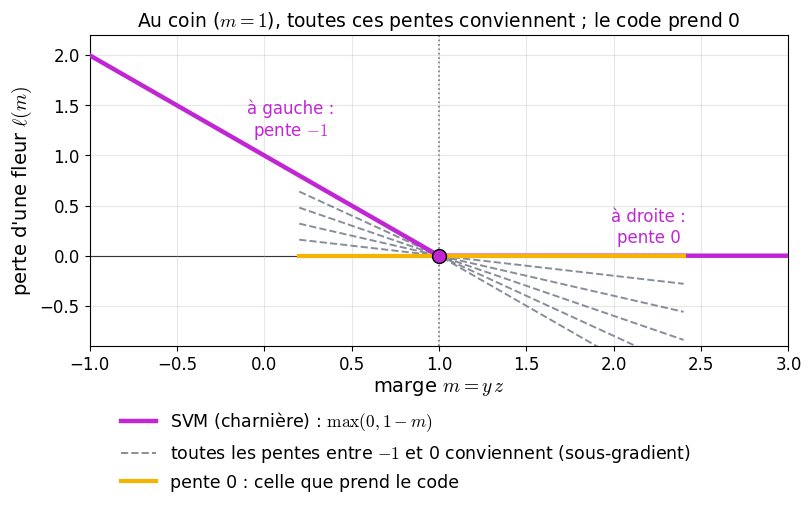

In [30]:
#@title Figure : au coin, toutes les pentes entre −1 et 0 conviennent. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_sous_gradient()  # la charnière en m = 1 et l'éventail des pentes acceptables (sous-gradient) ; le code prend 0

> **📊** La charnière du SVM en magenta ; au coin $m = 1$, chaque droite grise tirée passe sous la courbe sans la couper : toutes ces pentes « conviennent ». La droite dorée est la pente 0, celle du code.

### Les quatre pentes superposées, pour les comparer d'un coup d'œil.

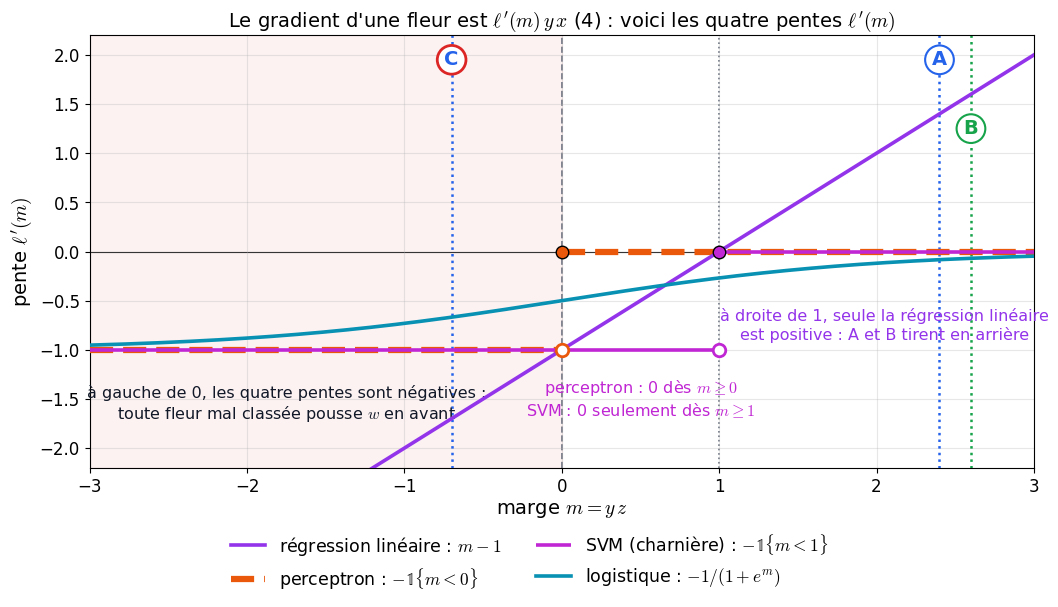

In [31]:
#@title Figure : les quatre pentes ℓ'(m) superposées. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_pentes_superposees()  # les quatre l'(m) sur le même axe m, avec A, B, C en repères

> **📊** Une pente négative veut dire que la fleur pousse $w$ dans le sens qui augmente sa marge ; zéro veut dire qu'elle ne pousse plus. Perceptron (orange, tireté) : $-1$ pour les erreurs, 0 sinon. SVM (magenta) : la même marche, décalée en $m = 1$ ; à gauche de 0 les deux se superposent. Logistique (sarcelle) : une pente douce, jamais tout à fait nulle. Régression linéaire (violet) : traverse zéro en $m = 1$ et devient positive après, là où sont A et B.

## 4.7 🌸 Le gradient en chiffres, pour A, B et C

### Pour chaque perte, le code calcule $\ell'(m)$, puis la poussée $\ell'(m)\,y$, puis le gradient de la fleur $\ell'(m)\,y\,x$ (4), avec le même $w = (1, 1, -0.4)$ qu'à la section 0.

> **🔮 Avant d'exécuter la cellule, prédisez :** Pour le perceptron, lequel des trois vecteurs $\ell'(m)\,y\,x$ de A, B et C sera non nul ? Et pour la régression linéaire ?

In [32]:
#@title Fil rouge : la poussée de A, B et C sur w. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
tableau_poussees_abc()  # la poussée l'(m) y et le gradient l'(m) y x de A, B et C, pour chaque perte

w = (w₀, w₁, b) = (1.00, 1.00, -0.40)   gradient d'une fleur (4) : ∇_w ℓ = ℓ'(m) y x   (un nombre, fois x)

régression linéaire
fleur       m     ℓ(m)    ℓ'(m)   ℓ'(m) y   ℓ'(m) y x = gradient de la fleur, composantes (w₀, w₁, b)
A        2.40    0.980     1.40      1.40   (+2.24, +1.68, +1.40)
B        2.60    1.280     1.60     -1.60   (+2.08, +1.44, -1.60)
C       -0.70    1.445    -1.70     -1.70   (+2.72, -2.21, -1.70)

perceptron
fleur       m     ℓ(m)    ℓ'(m)   ℓ'(m) y   ℓ'(m) y x = gradient de la fleur, composantes (w₀, w₁, b)
A        2.40    0.000     0.00      0.00   (+0.00, +0.00, +0.00)
B        2.60    0.000     0.00      0.00   (+0.00, +0.00, +0.00)
C       -0.70    0.700    -1.00     -1.00   (+1.60, -1.30, -1.00)

SVM (charnière)
fleur       m     ℓ(m)    ℓ'(m)   ℓ'(m) y   ℓ'(m) y x = gradient de la fleur, composantes (w₀, w₁, b)
A        2.40    0.000     0.00      0.00   (+0.00, +0.00, +0.00)
B        2.60    0.000     0.00      0.00   (+0.00, +0.00, +0.00)
C       -

> **🧠 Vérifiez votre prédiction :** <details><summary>Qui pousse, pour le perceptron et pour la régression linéaire ?</summary>Perceptron : seule C (marge $-0.7 \lt 0$) a un vecteur non nul, $(+1.60, -1.30, -1.00)$ ; A et B donnent $(0, 0, 0)$. Régression linéaire : les trois, avec $\ell'(m)\,y = +1.4$ pour A, $-1.6$ pour B et $-1.7$ pour C.</details>

### Lecture 1 : le vecteur de C a la même direction pour les quatre pertes ; c'est $x_C$, à un signe et une force près.

### Lecture 2 : pour A et B, seules la régression linéaire et la logistique donnent un vecteur non nul.

### 🌸 La régression linéaire donne à A le gradient $(+2.24, +1.68, +1.40)$, et la descente (section 5) fera $w \leftarrow w - \eta\,\nabla_w L$ : elle soustrait $\eta$ fois ce vecteur.

> **🧠 Vérifiez :** <details><summary>A pousse-t-elle les poids vers elle ou loin d'elle ?</summary>Loin d'elle : on soustrait $\eta$ fois un vecteur positif fois $x_A$, donc le score de A diminue. D'après le calcul de 4.4, sa marge baisse de $1.4\,\eta\,\lVert x_A\rVert^2 = 1.4 \times 5.0\,\eta = 7\,\eta$. La régression linéaire ramène les scores trop grands vers $+1$.</details>

## 4.8 Le tir à la corde

### Une image pour y penser : un tir à la corde.

### Chaque fleur tient une corde attachée à $w$ et tire dans la direction de $x$ (ou de $-x$), avec une force $\lvert\ell'(m)\rvert$.

Précisément, la fleur $i$ tire $w$ dans la direction $-\ell'(m_i)\,y_i\,x_i$, l'opposé de son gradient (4) : c'est le sens dans lequel la descente de gradient (section 5) va déplacer $w$ pour faire baisser sa perte.

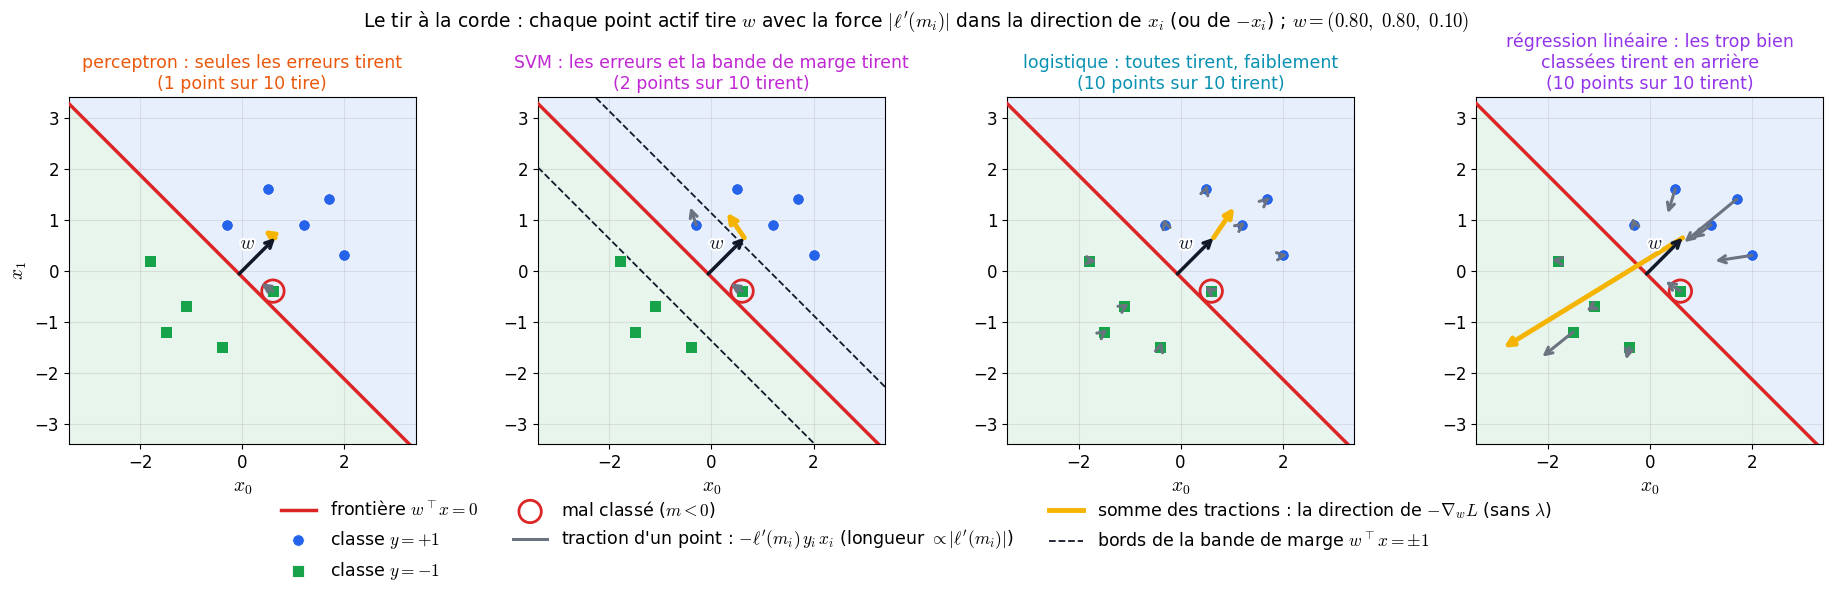

Dix points jouets, w = (0.80, 0.80, 0.10) : marges m_i = +1.78, +1.94, +1.78, +2.58, +0.58, +1.34, +1.18, +1.42, +2.06, -0.26  (1 erreur, 1 point dans la bande 0 ≤ m < 1)
Somme des tractions, composantes (w0, w1), avant division par n = 10 : perceptron (-0.60, +0.40) ; SVM (charnière) (-0.90, +1.30) ; logistique (+1.07, +1.57) ; régression linéaire (-9.23, -5.67)
-∇_w L (sans λ) = (somme des tractions) / n : même direction, dix fois plus court. Il dit où w va bouger à la prochaine itération (section 5).


In [33]:
#@title Figure : le tir à la corde, une perte par panneau. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_tir_corde()  # les dix points jouets, w = (0.8, 0.8, 0.1), la traction -l'(m_i) y_i x_i de chaque point actif et leur somme

> **📊** Les dix points jouets de la démo A, la frontière de $w = (0.8, 0.8, 0.1)$ et la flèche $w$. Chaque flèche grise part d'un point actif : sa direction est $-\ell'(m_i)\,y_i\,x_i$ (projetée sur $(x_0, x_1)$), sa longueur est proportionnelle à la force $\lvert\ell'(m_i)\rvert$, à la même échelle dans les quatre panneaux. La flèche dorée, qui part de la pointe de $w$, est la somme des tractions : la direction de $-\nabla_w L$ (sans $\lambda$), donc celle du prochain déplacement de $w$. Perceptron : un seul point tire, le point mal classé (cercle rouge) ; SVM : lui et le point dans la bande de marge (entre les tiretés noirs) ; logistique : tous, mais les mieux classés à peine ; régression linéaire : tous, et les points avec $m > 1$ tirent **en arrière** (vers l'origine), si fort que la somme dorée recule.

### Le gradient de $L$, c'est la somme de toutes les tractions, divisée par $n$ ; on l'écrit à la sous-section 4.9.

### La régularisation est un élastique qui ramène $w$ vers zéro avec une force $\lambda\,\lVert w\rVert$ (biais compris : le code régularise aussi $w_2 = b$, ce qui tire légèrement la frontière vers l'origine).

### Les quatre méthodes diffèrent seulement sur qui a le droit de tirer, et avec quelle force. Le tableau à emporter :

<table width="100%">
<tr><th align="left" width="9%">méthode</th><th align="left" width="13%">$\ell(m)$</th><th align="left" width="16%">$\ell'(m)$</th><th align="left" width="17%">qui tire</th><th align="left" width="20%"><code>coef</code> $= \ell'(m_i)$ dans le code</th><th align="left" width="9%">réglages $(\lambda, \eta)$</th><th align="left" width="16%">classe Python</th></tr>
<tr><td valign="top">régression linéaire</td><td valign="top">$\tfrac12 (m - 1)^2$</td><td valign="top">$m - 1$</td><td valign="top">toutes les fleurs, dans les deux sens : force $\lvert m - 1\rvert$</td><td valign="top"><code>coef = marges - 1</code></td><td valign="top">$(0.1,\ 0.2)$</td><td valign="top"><code>LinearRegression</code> (section 6)</td></tr>
<tr><td valign="top">perceptron</td><td valign="top">$\max(0, -m)$</td><td valign="top">$-\mathbb{1}\{m \lt 0\}$</td><td valign="top">les mal classées seulement, force 1</td><td valign="top"><code>coef = -(marges &lt; 0)</code></td><td valign="top">$(0,\ 1)$</td><td valign="top"><code>Perceptron</code> (section 7)</td></tr>
<tr><td valign="top">SVM (charnière)</td><td valign="top">$\max(0, 1 - m)$</td><td valign="top">$-\mathbb{1}\{m \lt 1\}$</td><td valign="top">les mal classées et celles de la bande de marge ($m \lt 1$), force 1</td><td valign="top"><code>coef = -(marges &lt; 1)</code></td><td valign="top">$(0.1,\ 1)$</td><td valign="top"><code>SVM</code> (section 8)</td></tr>
<tr><td valign="top">logistique</td><td valign="top">$\log(1 + e^{-m})$</td><td valign="top">$-\dfrac{1}{1 + e^{m}} = -\sigma(-m)$</td><td valign="top">toutes les fleurs, force = probabilité donnée à la mauvaise classe, de 1 à presque 0</td><td valign="top"><code>coef = -np.exp(-np.logaddexp(0, marges))</code></td><td valign="top">$(0.1,\ 0.2)$</td><td valign="top"><code>LogisticRegression</code> (section 9)</td></tr>
</table>

où $\lambda$ est la force de la régularisation (`reg` dans le code) et $\eta$ le pas de la descente (`stepsize`, section 5) ; les réglages sont ceux du labo, repris aux sections 6 à 9.

## 4.9 L'objectif complet $L(w)$

### Rappel de (3) : l'objectif est la perte moyenne des $n$ fleurs, plus la régularisation.

$$L(w) = \frac{1}{n}\sum_{i=1}^{n} \ell(m_i) + \frac{\lambda}{2}\lVert w\rVert^2$$

où $m_i = y_i\,w^\top x_i$ est la marge de la fleur $i$, $n = 75$, et $\lVert w\rVert^2 = w_0^2 + w_1^2 + w_2^2$.

### Le gradient d'une moyenne est la moyenne des gradients ; celui de la régularisation est $\lambda\,w$.

$$\nabla_w L = \nabla_w\!\left[\frac{1}{n}\sum_{i=1}^{n} \ell(m_i)\right] + \nabla_w\!\left[\frac{\lambda}{2}\lVert w\rVert^2\right] = \frac{1}{n}\sum_{i=1}^{n} \underbrace{\nabla_w \ell(m_i)}_{= \ell'(m_i)\,y_i\,x_i \text{ d'après (4)}} + \lambda\,w$$

où la première égalité dit que dériver une somme, c'est sommer les dérivées (et le $\frac1n$ sort devant), et où, pour la régularisation, $\dfrac{\partial}{\partial w_j}\,\dfrac{\lambda}{2}\,(w_0^2 + w_1^2 + w_2^2) = \lambda\,w_j$ pour chaque $j$ : en vecteur, $\lambda\,w$ (oui, le biais $w_2 = b$ aussi : c'est un choix de simplicité du labo, pas la règle générale ; le SVM de la section 8 en reparle).

### Donc, pour les quatre méthodes :

$$\boxed{\,\nabla_w L = \frac{1}{n}\sum_{i=1}^{n} \ell'(m_i)\,y_i\,x_i + \lambda\,w\,} \tag{5}$$

où $\ell'(m_i)\,y_i$ est la poussée de la fleur $i$ et $x_i$ sa direction : la somme des tractions du tir à la corde, divisée par $n$, plus l'élastique $\lambda\,w$.

### En code, une seule ligne, la même dans les quatre classes, où `coef` est le vecteur des $\ell'(m_i)$ :

```python
((coef * y)[:, np.newaxis] * X).mean(axis=0) + self.reg * self.w
```

<table width="100%">
<tr><th align="left" width="27%">formule</th><th align="left" width="33%">code</th><th align="left" width="40%">forme</th></tr>
<tr><td valign="top">$\ell'(m_i)$</td><td valign="top"><code>coef</code></td><td valign="top">vecteur de taille $n$ (un nombre par fleur)</td></tr>
<tr><td valign="top">$y_i$</td><td valign="top"><code>y</code></td><td valign="top">vecteur de taille $n$</td></tr>
<tr><td valign="top">$x_i$</td><td valign="top"><code>X[i]</code></td><td valign="top">ligne $i$ de la matrice <code>X</code>, de forme $(n, 3)$</td></tr>
<tr><td valign="top">$\ell'(m_i)\,y_i\,x_i$</td><td valign="top"><code>(coef * y)[:, np.newaxis] * X</code></td><td valign="top">matrice $(n, 3)$ : une ligne par fleur, son gradient (4)</td></tr>
<tr><td valign="top">$\frac{1}{n}\sum_{i=1}^{n}$</td><td valign="top"><code>.mean(axis=0)</code></td><td valign="top">moyenne des lignes : un vecteur de taille 3</td></tr>
<tr><td valign="top">$\lambda\,w$</td><td valign="top"><code>self.reg * self.w</code></td><td valign="top">vecteur de taille 3 (<code>reg</code> $= \lambda$, <code>self.w</code> $= w$)</td></tr>
</table>

où `[:, np.newaxis]` transforme le vecteur `coef * y` (taille $n$) en colonne $(n, 1)$, pour qu'il multiplie chaque ligne de `X` par son nombre.

### Dans les classes des sections 6 à 9, seule la ligne qui calcule `coef` change d'une méthode à l'autre (colonne `coef` du tableau) ; la ligne qui suit, celle de (5), est identique dans les quatre.

### La carte du labo jusqu'ici : de l'entrée $x$ à la mise à jour de $w$, avec le nom Python de chaque étape.

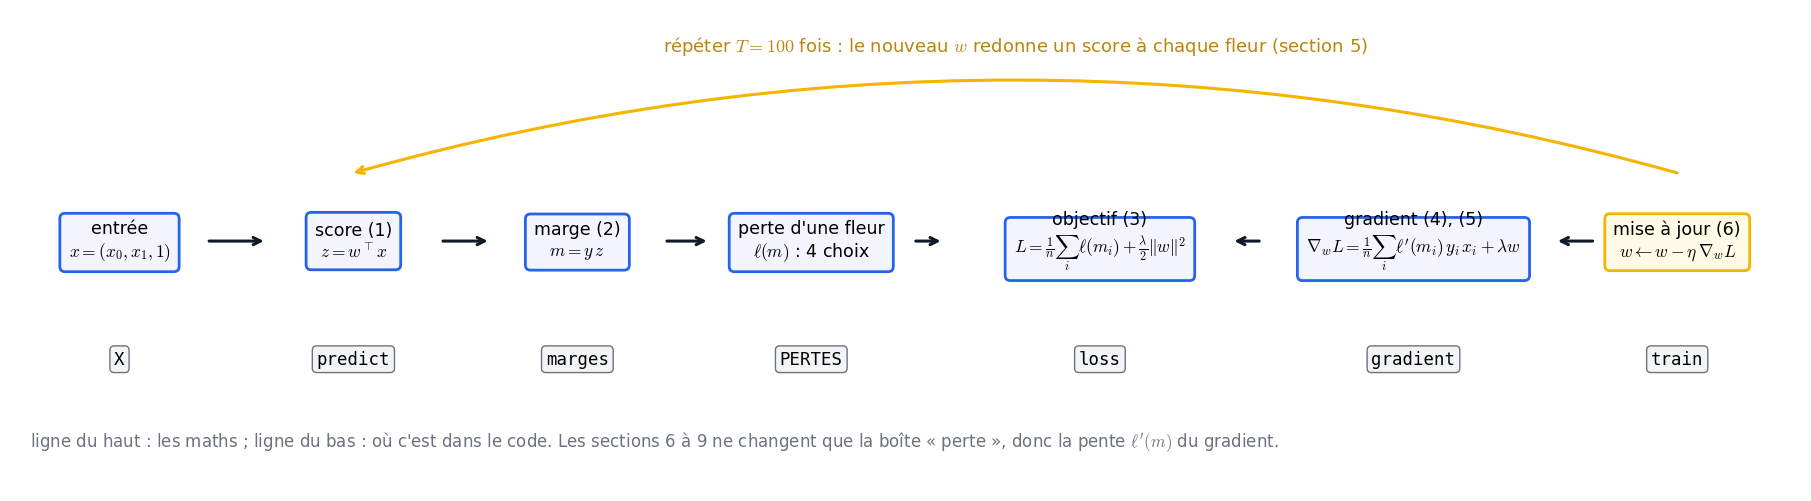

In [34]:
#@title Figure : la carte du labo, des maths au code. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_carte()  # x -> z -> m -> l(m) -> L(w) -> grad L -> mise à jour de w, et le nom Python de chaque boîte

> **📊** Ligne du haut : les six équations (1) à (6), dans l'ordre où le code les calcule. Ligne du bas : le nom Python de chaque étape (`X` et `PERTES` viennent de la boîte à outils, `predict`, `loss`, `gradient` et `train` de la classe de la section 5). La flèche dorée est la boucle de la descente de gradient, qu'on écrit à la section 5 : la mise à jour (6) donne un nouveau $w$, qui redonne un score à chaque fleur, $T = 100$ fois.

## 5. La descente de gradient

> **📖 Rappel de notation.** L'objectif est $L(w) = \frac{1}{n}\sum_{i=1}^{n} \ell(m_i) + \frac{\lambda}{2}\lVert w\rVert^2$, équation (3), et son gradient est $\nabla_w L = \frac{1}{n}\sum_{i=1}^{n} \ell'(m_i)\,y_i\,x_i + \lambda\,w$, équation (5) : un vecteur de trois nombres, comme $w = (w_0, w_1, b)$. Cette section ajoute quatre symboles : $\eta$ (« êta »), le pas ; $t$, le numéro d'itération ; $w^{(t)}$, les poids après $t$ itérations ; $T = 100$, le nombre d'itérations.
>
> Dans le code : $L(w)$ = `loss`, $\nabla_w L$ = `gradient`, $\lambda$ = `reg`, $\eta$ = `stepsize`, $T$ = `n_steps`, $w^{(0)}$ = `w0`.

### Où en est-on : données ✔ (section 1), modèle ✔ (section 0), perte ✔ (section 3), gradient ✔ (section 4). Il reste à écrire la descente, une fois pour toutes.

## 5.1 Une seule règle, répétée

### Une seule règle, répétée $T$ fois : on part de $w^{(0)}$ et, à chaque itération, on retranche à $w$ son gradient multiplié par le pas $\eta$.

$$\boxed{\,w^{(t+1)} = w^{(t)} - \eta\,\nabla_w L(w^{(t)})\,} \tag{6}$$

où $t = 0, 1, \dots, T - 1$ est le numéro de l'itération, $w^{(t)}$ le vecteur des trois poids après $t$ itérations, $w^{(0)}$ le point de départ (`w0` dans le code : rien à voir avec la composante $w_0$), $\eta > 0$ le pas (`stepsize`), $\nabla_w L(w^{(t)})$ le gradient (5) calculé aux poids courants, et $T$ = `n_steps` = 100 le nombre d'itérations.

### En code, on écrase $w$ à chaque tour : la même règle s'écrit avec une flèche, et c'est une seule ligne Python.

$$w \leftarrow w - \eta\,\nabla_w L(w)$$

où la flèche veut dire « le nouveau $w$ remplace l'ancien ». En Python : `self.w = self.w - stepsize * self.gradient(X, y)`, où `self.w` est $w$, `stepsize` est $\eta$ et `self.gradient(X, y)` calcule $\nabla_w L(w)$ sur les 75 fleurs d'entraînement. C'est cette forme en flèche qu'on utilisera dans la suite ; (6) et elle disent la même chose.

### Vocabulaire : $\eta$ (« êta ») est **le pas**, c'est-à-dire sa taille, de combien on avance à chaque fois. Une mise à jour de $w$ par (6) est **une itération** ; on en fait $T = 100$.

### Le gradient pointe dans la direction où $L$ monte le plus vite ; le signe moins de (6) nous fait descendre.

### En une dimension (un seul poids $w$) : on est au point noir, la pente $L'(w)$ est négative, donc on avance vers la droite, d'une longueur $\eta\,\lvert L'(w)\rvert$.

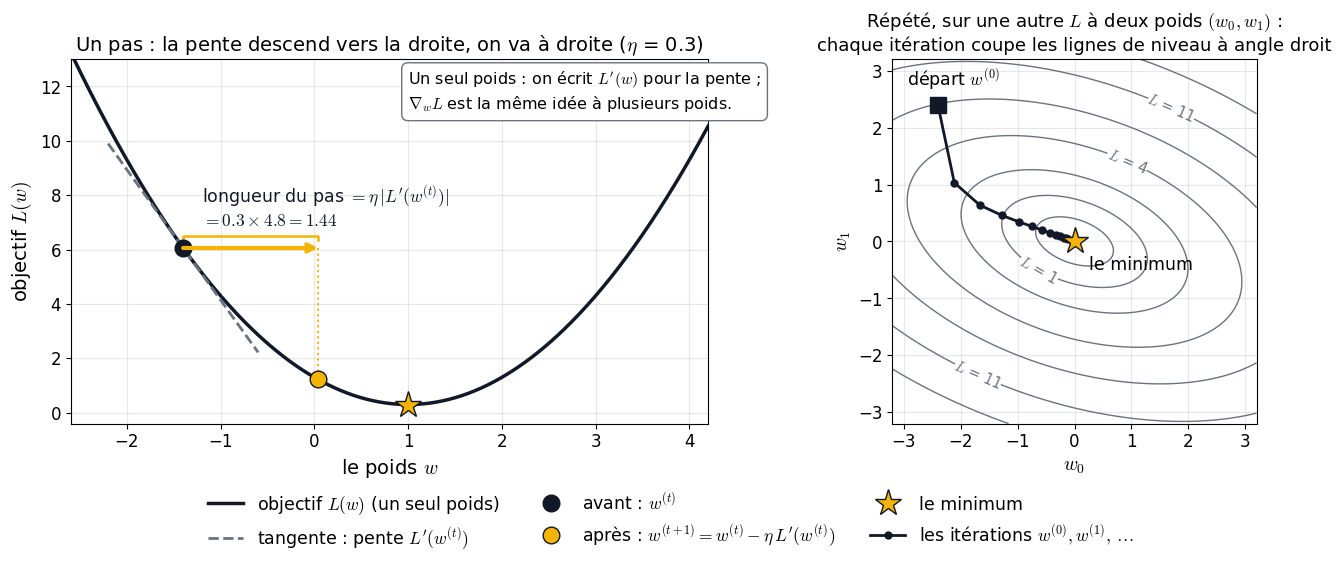

In [35]:
#@title Figure : un pas de descente, à un poids puis à deux poids. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_un_pas()  # à gauche : un pas sur une parabole L(w) ; à droite : une autre L, à deux poids, descendue jusqu'au fond

> **📊** À gauche, $L$ n'a qu'un poids : la pente $L'(w^{(t)}) = -4.8$ est négative, le pas $-\eta\,L'(w^{(t)}) = 0.3 \times 4.8 = 1.44$ est donc positif, et le point or est à droite du point noir, plus bas sur la courbe. Avec un seul poids on écrit $L'(w)$ pour la pente ; $\nabla_w L$ est la même idée quand il y a plusieurs poids. À droite, une **autre** fonction $L$, à deux poids $(w_0, w_1)$ : répétée, la règle (6) descend jusqu'à l'étoile, et chaque itération coupe les lignes de niveau à angle droit.

### Répété, on finit au fond de la vallée (l'étoile) ; à deux poids, chaque itération descend perpendiculairement aux lignes de niveau.

### Et sur nos fleurs ? Une itération sur $w$, c'est un petit mouvement de la frontière. Voici dix itérations de (6) avec la perte de la régression linéaire (celle de la section 6), calculées à la main.

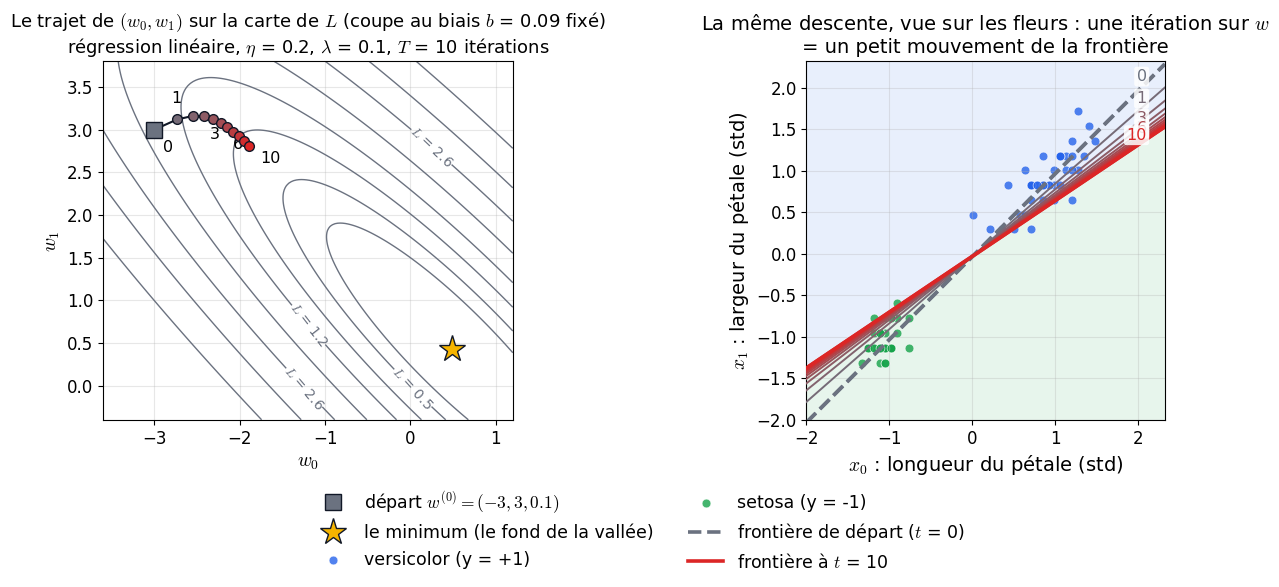

w(0) = (-3.00, 3.00, 0.10) : erreur d'entraînement 52%   ->   w(10) = (-1.89, 2.81, 0.09) : erreur 7% ; l'étoile w* = (0.49, 0.43, 0.08) est encore loin


In [36]:
#@title Figure : dix itérations, vues sur la carte de L et sur les fleurs. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_descente_fleurs()  # régression linéaire, eta = 0.2, lambda = 0.1, départ (-3, 3, 0.1) : trajet de (w0, w1) à gauche, frontières à droite

> **📊** À gauche : le trajet de $(w_0, w_1)$ sur les lignes de niveau de $L$ (une coupe au biais $b$ fixé, comme dans la démo S), du carré gris ($t = 0$) au point rouge ($t = 10$) ; l'étoile est le fond de la vallée. À droite : les frontières correspondantes, du gris tireté ($t = 0$) au rouge ($t = 10$), avec les mêmes numéros. En dix itérations à $\eta = 0.2$, l'erreur d'entraînement passe de 52 % à 7 %, mais l'étoile est encore loin : c'est pour ça qu'on fera $T = 100$ itérations, et la démo E (section 6) montrera ce que $\eta$ y change.

## 5.2 Le pas $\eta$ : trop petit, convenable, trop grand

### Le pas, trois cas : même départ $w^{(0)} = -2$, mêmes $T = 8$ itérations ; seul $\eta$ change.

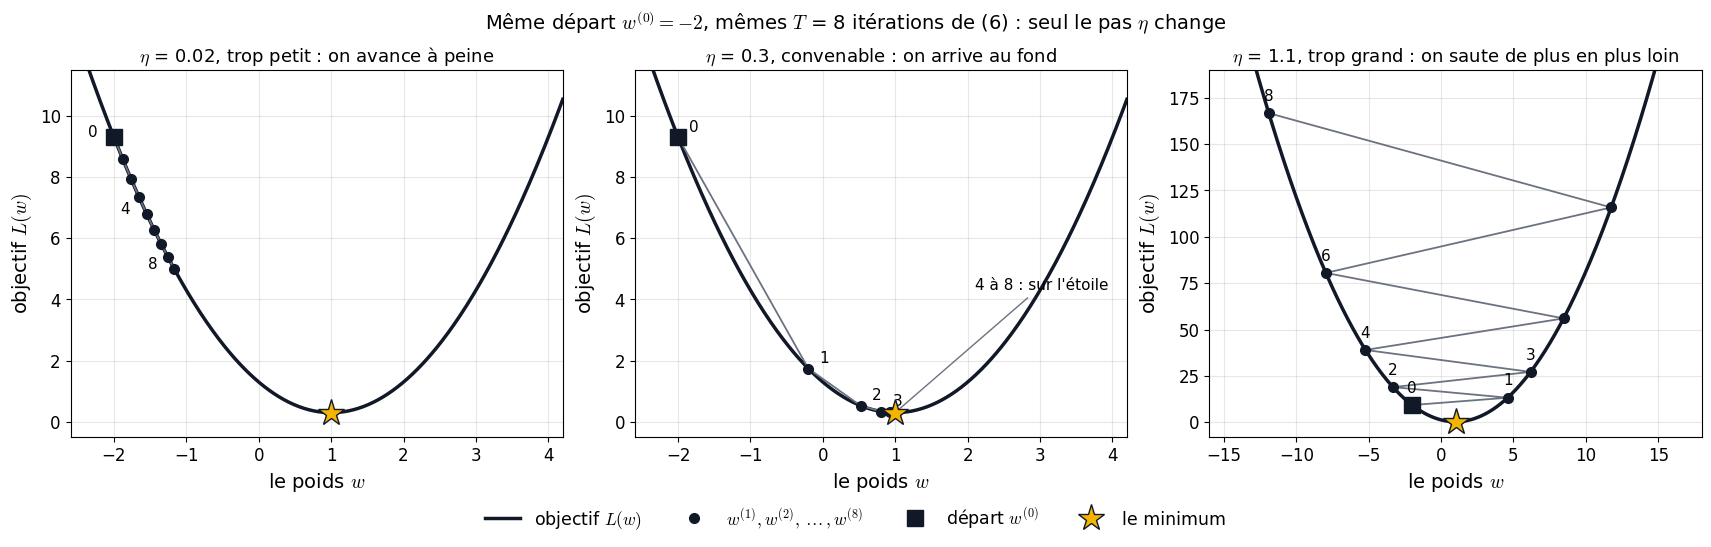

In [37]:
#@title Figure : le pas, trois cas. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_trois_pas()  # huit itérations de (6) sur la même parabole, avec eta = 0.02, 0.3 et 1.1

### Trop petit ($\eta = 0.02$) : on avance à peine ; après huit itérations on est encore sur le flanc.

### Convenable ($\eta = 0.3$) : on arrive au fond en trois ou quatre itérations, et on y reste.

### Trop grand ($\eta = 1.1$) : on saute par-dessus le fond, de plus en plus loin, et la descente diverge ([Boyd et Vandenberghe, 2004](https://web.stanford.edu/~boyd/cvxbook/), section 9.3).

> **🧠 Pourquoi « de plus en plus loin » ?** <details><summary>Cliquez pour le calcul, sur la parabole de la figure.</summary>Sur $L(w) = (w - 1)^2 + 0.3$, la pente est $L'(w) = 2\,(w - 1)$ et la règle (6) donne $w^{(t+1)} - 1 = (1 - 2\eta)\,(w^{(t)} - 1)$ : l'écart au minimum est multiplié par $1 - 2\eta$ à chaque itération. Avec $\eta = 0.02$, c'est $0.96$ (l'écart fond lentement) ; avec $\eta = 0.3$, c'est $0.4$ (il fond vite) ; avec $\eta = 1.1$, c'est $-1.2$ : le signe change, on saute de l'autre côté du fond, et l'écart grandit de 20 % par itération. La démo E (section 6) retrouvera ce seuil sur les fleurs.</details>

### Une image pour y penser : un randonneur dans le brouillard.

### Il ne voit pas la carte, mais il sent la pente sous ses pieds : c'est le gradient. La longueur de son pas, c'est $\eta$. La bille de la démo S (section 6) est ce randonneur, vu en 3D.

### Chaque itération de la version d'aujourd'hui utilise toutes les 75 fleurs (on dit « par lot complet »). Le bonus, après le récap, regarde la version par mini-lots : le randonneur n'y tâte la pente que d'un pied.

## 5.3 Écrite une seule fois : la classe parent

### En Python, une « classe parent » est un modèle commun ; chaque « enfant » le reprend tel quel et ne réécrit que ce qui change. Ici, ce qui change d'une méthode à l'autre, c'est $\ell$ et $\ell'$ : donc `loss` et `gradient`.

### Une classe parent fait la descente ; les quatre classifieurs en héritent et ne fournissent que `loss` et `gradient`.

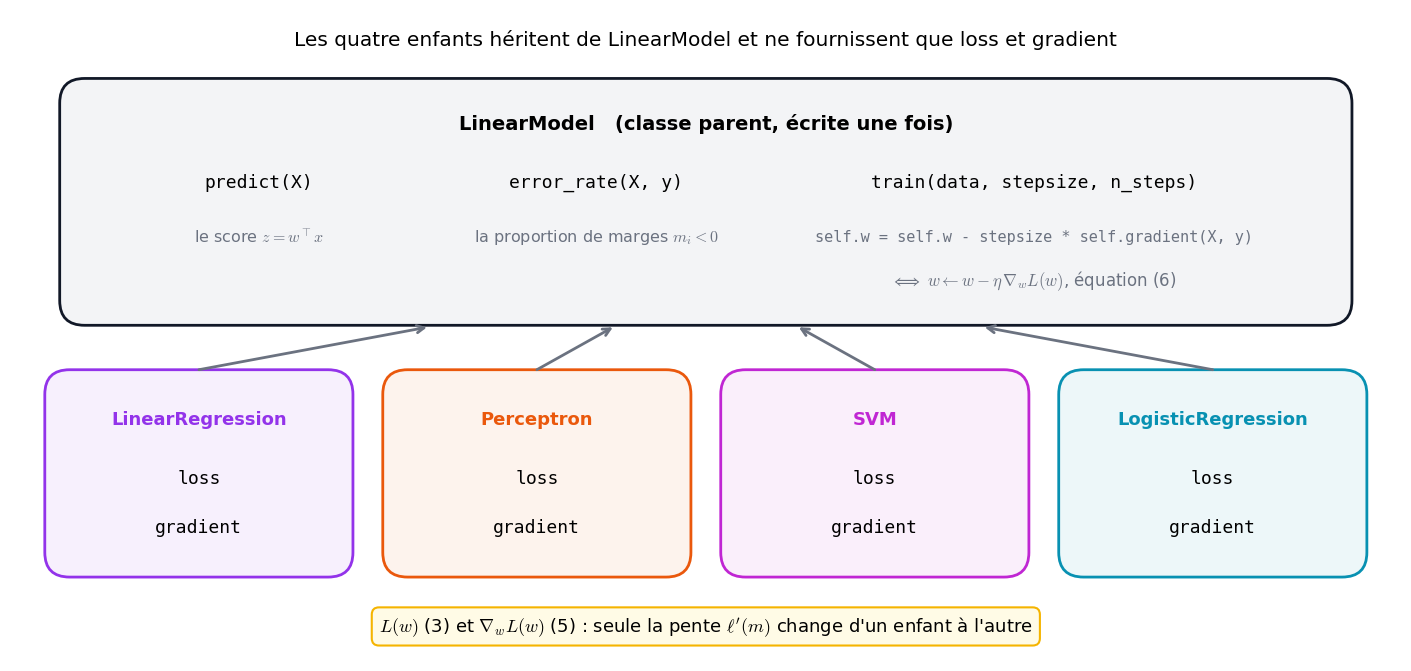

In [38]:
#@title Figure : la classe parent et ses quatre enfants. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_classes()  # LinearModel (predict, error_rate, train) et les quatre enfants (loss, gradient), aux couleurs de leur perte

### C'est pour ça que chaque classifieur du labo tient en une dizaine de lignes.

### Ce que contient le parent : `w` (les trois poids, $w = (w_0, w_1, b)$), `predict` (le score $z = w^\top x$ de chaque fleur), `error_rate` (la proportion de marges $m_i < 0$, c'est-à-dire $\mathrm{Err}(w)$).

### Et `train` : la boucle des $T$ itérations de (6), dont la ligne qui compte est `self.w = self.w - stepsize * self.gradient(X, y)`.

In [39]:
#@title Code : la classe parent LinearModel (la descente de gradient, écrite une fois). Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
class LinearModel:
    """Classe parent pour tous les modèles linéaires : w, predict, error_rate et la descente de gradient (train).
    Les enfants ne redéfinissent que loss (l'objectif L(w)) et gradient (son gradient en w)."""

    def __init__(self, w0, reg):
        """w0 = point de départ w^(0) de la descente (3 nombres : w0, w1, b ; rien à voir avec la composante w_0).
        reg = lambda, la force de la régularisation."""
        self.w = np.array(w0, dtype=float)  # copie en nombres réels : on pourra modifier self.w sans toucher à w0
        self.reg = reg  # lambda
        self.historique = [self.w.copy()]  # liste des poids successifs w^(0), w^(1), ... (sert à rejouer l'entraînement, démo D)

    def predict(self, X):
        """Retourne le score z = w^⊤ x pour chaque ligne x de X (tableau de taille n).
        La classe prédite est le signe de ce score."""
        return X @ self.w  # (n, 3) @ (3,) -> (n,) : un score par fleur

    def error_rate(self, X, y):
        """Retourne la proportion de fleurs mal classées (un nombre entre 0 et 1) : Err(w)."""
        return np.mean(self.predict(X) * y < 0)  # mal classée <=> marge m_i = y_i w^⊤ x_i < 0 (m_i = 0 : comptée bien classée)

    # les méthodes loss et gradient seront redéfinies dans les classes enfants
    def loss(self, X, y):  # objectif L(w) : un seul nombre
        return 0  # valeur provisoire, remplacée dans chaque classe enfant

    def gradient(self, X, y):  # gradient de L en w : vecteur de même forme que w
        return self.w  # valeur provisoire : comme si L(w) = 1/2 ||w||^2 ; la descente fait alors w <- w - eta w = (1 - eta) w, qui rétrécit sans tourner

    def train(self, data, stepsize, n_steps, plot=False, verbose=True):
        """Descente de gradient par lot complet (toutes les fleurs à chaque itération), n_steps itérations, pas fixe.
        stepsize = eta, n_steps = T. Retourne les tableaux de l'objectif et du taux d'erreur observés après chaque itération."""
        X = data[:, :-1]  # entrées (avec la colonne de 1), forme (n, 3)
        y = data[:, -1]  # étiquettes -1 / +1, forme (n,)
        losses = []  # objectif L(w) après chaque itération
        errors = []  # taux d'erreur après chaque itération
        self.historique = [self.w.copy()]  # on repart d'un historique qui contient seulement le point de départ w^(0)

        for t in range(n_steps):  # t = numéro d'itération (w^(t) dans les formules) ; une itération = une mise à jour de w
            # Descente de gradient : équation (6)
            self.w = self.w - stepsize * self.gradient(X, y)  # w <- w - eta * gradient de L en w

            # Mise à jour des pertes
            losses.append(self.loss(X, y))  # objectif avec les nouveaux poids

            # Mise à jour des erreurs
            errors.append(self.error_rate(X, y))  # taux d'erreur avec les nouveaux poids
            self.historique.append(self.w.copy())  # on garde une copie de w^(t+1) (fourni)

            # Figure (facultatif, lent : seulement si plot=True ; les démos D et S font mieux)
            if plot and t % 10 == 0:  # une image toutes les 10 itérations
                clear_output(wait=True)  # efface l'image précédente
                fig, ax = figure(1, figsize=(5.5, 5))  # nouvelle figure
                dessiner_donnees(ax, trainset, marker='x', suffixe=' (entraînement)')  # entraînement
                dessiner_donnees(ax, testset, marker='^', suffixe=' (test)')  # test
                dessiner_droite(ax, self.w, 0, c=ROUGE, lw=2.5)  # frontière courante
                preparer_axes(ax, f'itération $t$ = {t + 1}')  # titre
                plt.show()  # affiche

        if verbose:  # message de fin (désactivé dans les démos)
            if len(errors) == 0:  # la boucle n'a rien ajouté
                print('La liste errors est vide : complétez la boucle de train.')  # au lieu de planter sur errors[-1]
            else:  # cas normal
                print('Entraînement terminé : erreur d\'entraînement = {:.2f} %'.format(errors[-1] * 100))  # message
        return np.array(losses), np.array(errors)  # deux tableaux de longueur n_steps

### Les maths et le code, côte à côte.

<table width="100%">
<tr><th align="left" width="27%">maths</th><th align="left" width="33%">code</th><th align="left" width="40%">ce que c'est</th></tr>
<tr><td valign="top">$X$</td><td valign="top"><code>X</code></td><td valign="top">la matrice $(n, 3)$ des entrées, une ligne $x_i = (x_{i0}, x_{i1}, 1)$ par fleur</td></tr>
<tr><td valign="top">$y$</td><td valign="top"><code>y</code></td><td valign="top">le vecteur des $n$ étiquettes $y_i = \pm 1$</td></tr>
<tr><td valign="top">$w = (w_0, w_1, b)$</td><td valign="top"><code>self.w</code></td><td valign="top">les trois poids</td></tr>
<tr><td valign="top">$z_i = w^\top x_i$</td><td valign="top"><code>self.predict(X)</code></td><td valign="top">les $n$ scores</td></tr>
<tr><td valign="top">$m_i = y_i\,z_i$</td><td valign="top"><code>marges</code></td><td valign="top">les $n$ marges (dans les classes enfants)</td></tr>
<tr><td valign="top">$\ell'(m_i)$</td><td valign="top"><code>coef</code></td><td valign="top">la pente de la perte de la fleur $i$ : la seule ligne qui change d'un enfant à l'autre</td></tr>
<tr><td valign="top">$\frac{1}{n}\sum_{i=1}^{n}$</td><td valign="top"><code>.mean(axis=0)</code></td><td valign="top">la moyenne sur les fleurs</td></tr>
<tr><td valign="top">$\lambda$</td><td valign="top"><code>reg</code></td><td valign="top">la force de la régularisation</td></tr>
<tr><td valign="top">$\eta$</td><td valign="top"><code>stepsize</code></td><td valign="top">le pas</td></tr>
<tr><td valign="top">$T$</td><td valign="top"><code>n_steps</code></td><td valign="top">le nombre d'itérations</td></tr>
<tr><td valign="top">$w^{(0)}$</td><td valign="top"><code>w0</code></td><td valign="top">le point de départ</td></tr>
<tr><td valign="top">$w^{(t)}$</td><td valign="top"><code>self.historique[t]</code></td><td valign="top">les poids après $t$ itérations</td></tr>
</table>

### Même point de départ $w^{(0)} = (-3, 3, 0.1)$ et mêmes $T = 100$ itérations pour les quatre classifieurs : seuls $\lambda$ et $\eta$ changent, et on les affichera à chaque fois.

### `test_model` entraîne un classifieur ($T = 100$ itérations) et trace trois panneaux : l'objectif $L(w^{(t)})$, le taux d'erreur d'entraînement, la frontière finale.

### `verifier_gradient` compare le gradient de la formule (5) à une approximation numérique : s'ils coïncident, la dérivation est juste.

In [40]:
#@title Code : test_model et verifier_gradient. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
def test_model(modelclass, w0=[-3.0, 3.0, 0.1], reg=.1, stepsize=.2, plot=False):
    """Crée une instance de modelclass (départ w^(0) = w0, lambda = reg), l'entraîne T = 100 itérations avec le pas eta = stepsize,
    calcule le taux d'erreur sur le test, trace les courbes d'apprentissage et la frontière de décision."""
    model = modelclass(w0, reg)  # nouveau modèle
    training_loss, training_error = model.train(trainset, stepsize, 100, plot=plot)  # T = 100 itérations
    erreur_test = model.error_rate(testset[:, :-1], testset[:, -1])  # taux d'erreur sur le test
    print('Erreur de test : {:.2f} %'.format(erreur_test * 100))  # message
    print('Point de départ   ', txt_w(np.array(w0, dtype=float), 'w⁽⁰⁾'), ' | λ =', reg, ' | η =', stepsize)  # réglages
    print("Point d'arrivée   ", txt_w(model.w, 'w⁽¹⁰⁰⁾'))  # point d'arrivée (sans « -0.00 »)
    MODELES[modelclass.__name__] = model  # on garde le modèle pour la suite
    if len(training_loss) == 0 or any(v is None for v in training_loss):  # boucle vide ou loss pas écrite
        print('Pas de courbe à tracer : complétez train, puis loss.')  # message
        return  # on s'arrête là
    fig, (ax0, ax1, ax2) = figure(3, figsize=(16.5, 5.6), width_ratios=[1, 1, 1.1])  # trois panneaux
    it = np.arange(1, len(training_loss) + 1)  # itérations 1..T (après chaque mise à jour)
    ax0.plot(it, training_loss.astype(float), c=NOIR, lw=2.2)  # courbe de l'objectif
    if np.ptp(training_loss.astype(float)) == 0:  # courbe plate (parent seul : loss vaut 0)
        ax0.set_ylim(-0.05, 1.0)  # un axe lisible, sans valeurs négatives trompeuses
    ax0.set_title('objectif $L(w^{(t)})$ (entraînement)')  # titre
    ax0.set_xlabel(ETIQ_T); ax0.set_ylabel(ETIQ_L)  # axes
    ax0.grid(alpha=.3)  # grille
    ax1.plot(it, 100 * training_error, c=GRIS, lw=2.5, ls=':')  # courbe d'erreur en pourcentage
    ax1.set_title("erreur d'entraînement $\\mathrm{Err}(w^{(t)})$ (%)")  # titre
    ax1.set_xlabel(ETIQ_T); ax1.set_ylabel("erreur d'entraînement (%)")  # axes
    ax1.set_ylim(-3, 103)  # de 0 à 100 %
    ax1.grid(alpha=.3)  # grille
    dessiner_regions(ax2, model.w)  # régions du modèle final
    dessiner_donnees(ax2, trainset, marker='x', suffixe=' (entraînement)')  # entraînement
    dessiner_donnees(ax2, testset, marker='^', suffixe=' (test)')  # test
    dessiner_droite(ax2, model.w, 0, c=ROUGE, lw=2.5, label='frontière finale ($t$ = 100)')  # arrivée
    dessiner_droite(ax2, np.array(w0, dtype=float), 0, c=GRIS, ls='--', lw=1.5, label='frontière de départ ($t$ = 0)')  # départ, dessinée par-dessus : visible même si les deux coïncident
    preparer_axes(ax2, f'{modelclass.__name__} : erreur de test {erreur_test:.0%}'.replace('%', ' %'))  # titre
    legende(fig, ncol=3)  # légende commune, sous les panneaux
    plt.show()  # affiche

## 5.4 Premier essai : le parent tout seul

### Le gradient provisoire du parent vaut $w$ ; avec $\eta = 0.2$ (réglage par défaut de `test_model`), chaque itération fait $w \leftarrow w - 0.2\,w = 0.8\,w$.

> **🔮 Avant d'exécuter la cellule, prédisez :** $w$ rétrécit sans changer de direction : la frontière va-t-elle bouger ? Et l'erreur ?

Entraînement terminé : erreur d'entraînement = 52.00 %
Erreur de test : 60.00 %
Point de départ    w⁽⁰⁾ = (-3.00, 3.00, 0.10)  | λ = 0.1  | η = 0.2
Point d'arrivée    w⁽¹⁰⁰⁾ = (0.00, 0.00, 0.00)


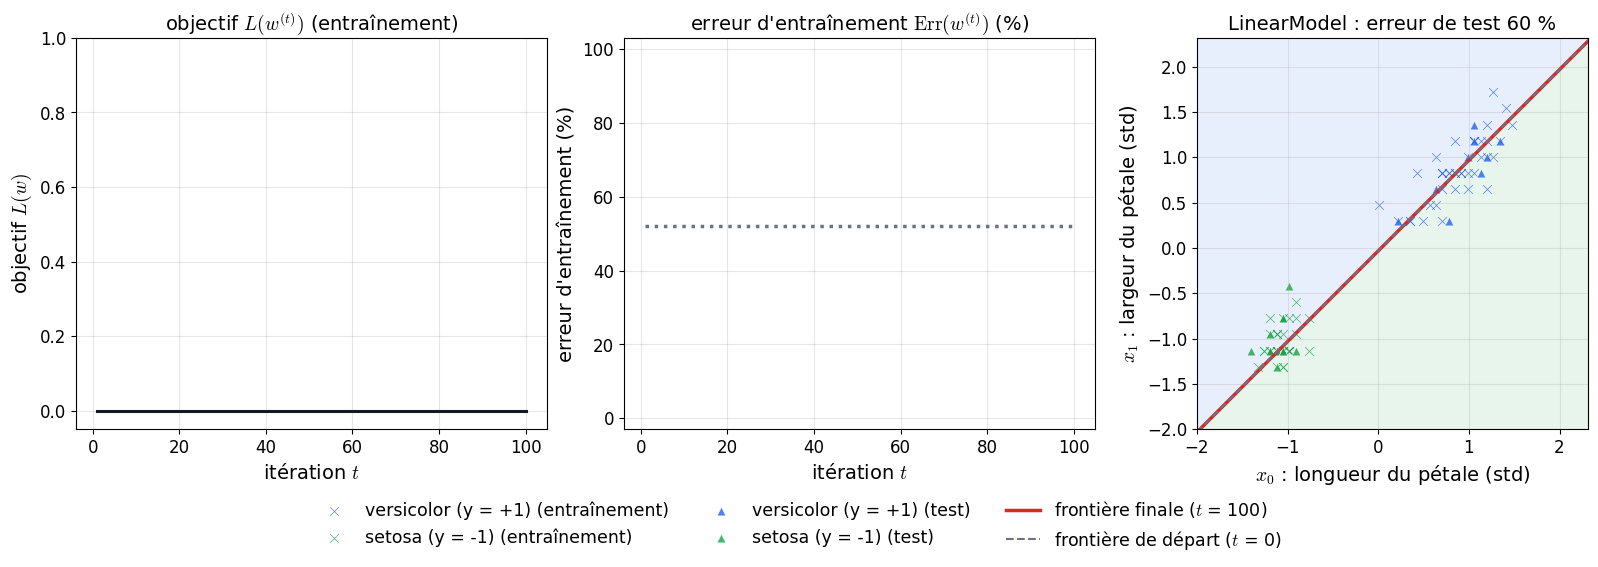

In [41]:
#@title Essai : la classe parent toute seule. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
test_model(LinearModel)  # la classe parent seule : loss vaut 0, gradient vaut w ; lambda = 0.1 et eta = 0.2 par défaut

> **🧠 Vérifiez votre prédiction.** <details><summary>Cliquez pour la réponse.</summary>La frontière ne bouge pas : $0.8\,w$ définit la même droite que $w$ ($0.8\,w^\top x = 0$ exactement quand $w^\top x = 0$), et aucun signe ne change. L'erreur reste donc constante, 52 % en entraînement et 60 % en test, tout au long des 100 itérations ; l'objectif vaut 0 parce que `loss` n'est pas encore écrite. Les poids affichés à l'arrivée valent 0.00, mais ce sont $0.8^{100} \approx 2 \times 10^{-10}$ fois ceux du départ : même direction, donc même frontière et même erreur. Sans perte, pas de direction.</details>

### Sans perte, pas de direction : il faut une vraie perte. C'est la section 6, avec la première des quatre, la régression linéaire.

## 6. Régression linéaire

> **📖 Rappel de notation.** $z_i = w^\top x_i$ est le score de la fleur $i$ (1) et $m_i = y_i\,z_i$ sa marge (2). Pour la régression linéaire, la perte d'une fleur est $\ell(m) = \tfrac12 (m - 1)^2$ et sa pente $\ell'(m) = m - 1$ (sections 3 et 4). L'objectif est $L(w) = \frac1n\sum_{i=1}^{n} \ell(m_i) + \frac{\lambda}{2}\lVert w\rVert^2$ (3), son gradient $\nabla_w L = \frac1n\sum_{i=1}^{n} \ell'(m_i)\,y_i\,x_i + \lambda\,w$ (5), et la descente fait $w^{(t+1)} = w^{(t)} - \eta\,\nabla_w L(w^{(t)})$ (6). Dans le code : $\lambda$ = `reg`, $\eta$ = `stepsize`, $T$ = `n_steps`, $w^{(0)}$ = `w0`.

## 6.1 La perte, le gradient et le code

### D'abord la perte : on met $\ell(m) = \tfrac12 (m - 1)^2$ dans l'objectif (3).

$$L(w) = \frac{1}{n}\sum_{i=1}^{n} \tfrac12\,(m_i - 1)^2 + \frac{\lambda}{2}\lVert w\rVert^2 = \frac{1}{2n}\sum_{i=1}^{n} (w^\top x_i - y_i)^2 + \frac{\lambda}{2}\lVert w\rVert^2$$

où $m_i = y_i\,w^\top x_i$ est la marge de la fleur $i$, $n = 75$ le nombre de fleurs d'entraînement et $\lambda$ la force de la régularisation. La seconde forme vient de $(m_i - 1)^2 = (y_i z_i - 1)^2 = (y_i z_i - y_i^2)^2 = y_i^2\,(z_i - y_i)^2 = (z_i - y_i)^2$, car $y_i^2 = 1$ : punir l'écart de la marge à 1, c'est punir l'écart du score à l'étiquette.

### Puis le gradient : on branche $\ell'(m) = m - 1$ dans la formule (5).

$$\nabla_w L = \frac{1}{n}\sum_{i=1}^{n} \underbrace{(m_i - 1)\,y_i}_{=\ z_i - y_i}\,x_i + \lambda\,w = \frac{1}{n}\sum_{i=1}^{n} (w^\top x_i - y_i)\,x_i + \lambda\,w$$

où l'étape du milieu est $(m_i - 1)\,y_i = y_i^2\,z_i - y_i = z_i - y_i$ (encore $y_i^2 = 1$) : la poussée $\ell'(m_i)\,y_i$ de la fleur $i$ (section 4) est son **résidu** $z_i - y_i$, l'écart entre son score et son étiquette.

### Réglages : $\lambda$ = `reg` = 0.1, $\eta$ = `stepsize` = 0.2, $T = 100$ itérations, $w^{(0)} = (-3, 3, 0.1)$.

### Le code : `loss` calcule $L(w)$ et `gradient` calcule $\nabla_w L$ ; les deux passent par le vecteur des marges, et `gradient` par la pente `coef` $= \ell'(m_i) = m_i - 1$.

### Puis deux appels : `verifier_gradient` (le contrôle du gradient) et `test_model` (l'entraînement, avec ses trois panneaux).

> **📊** Le texte imprimé : d'abord le gradient codé et son approximation numérique, qui coïncident (écart relatif de l'ordre de $10^{-11}$) ; puis l'erreur d'entraînement, l'erreur de test, et les poids de départ $w^{(0)}$ et d'arrivée $w^{(100)}$.

> **📊** Les trois panneaux : l'objectif $L(w^{(t)})$ descend ; l'erreur d'entraînement tombe à 0 % ; la frontière finale (rouge) sépare les deux nuages, loin de la frontière initiale (gris tireté).

> **🔮 Avant d'exécuter la cellule, prédisez :** Après 100 itérations, combien d'erreurs attendez-vous sur les 75 fleurs d'entraînement ? Et sur les 25 de test ?

LinearRegression | gradient (votre code) : [1.37 1.21 0.98] | différences finies : [1.37 1.21 0.98] | écart relatif : 2.8e-11
  => gradient correct ✅
Entraînement terminé : erreur d'entraînement = 0.00 %
Erreur de test : 0.00 %
Point de départ    w⁽⁰⁾ = (-3.00, 3.00, 0.10)  | λ = 0.1  | η = 0.2
Point d'arrivée    w⁽¹⁰⁰⁾ = (0.22, 0.70, 0.08)


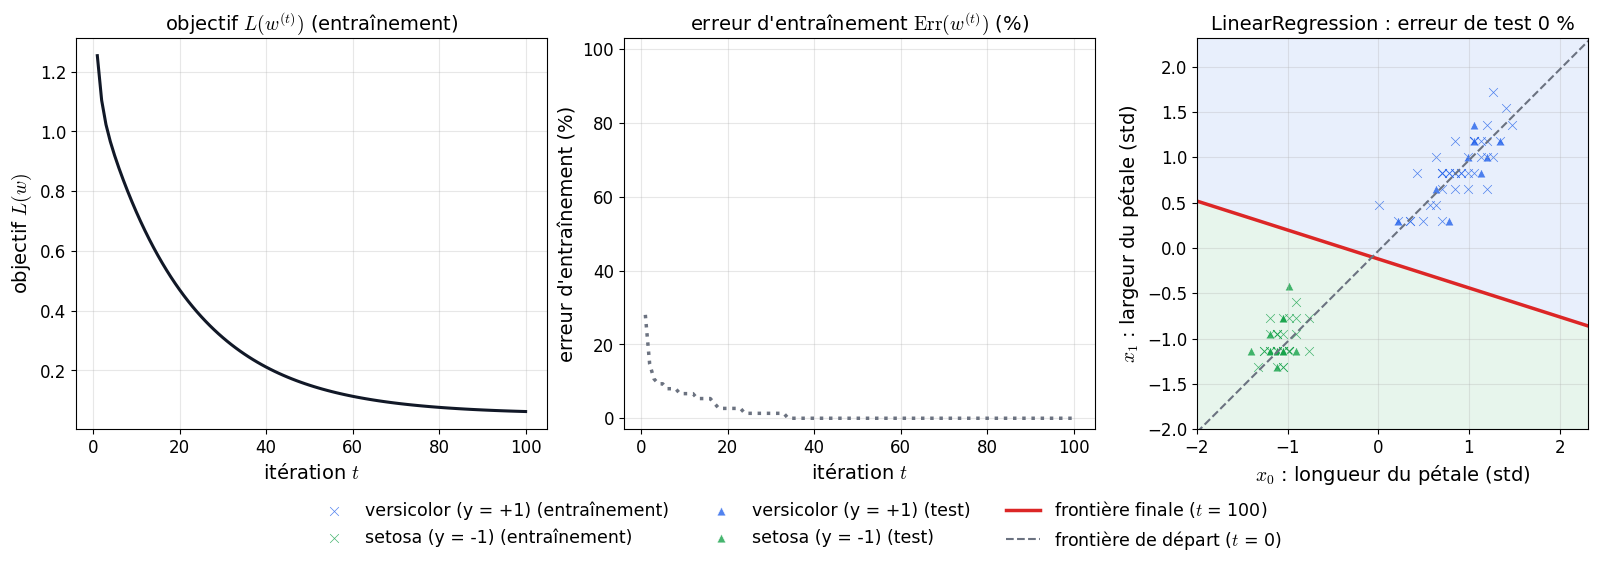

In [42]:
#@title Code : LinearRegression (loss, gradient), contrôle du gradient, entraînement. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
# Question 2

class LinearRegression(LinearModel):

    def __init__(self, w0, reg):  # constructeur : appelle celui de la classe parent
        super().__init__(w0, reg)  # tout est hérité de LinearModel

    def loss(self, X, y):  # objectif L(w), équation (3) : un seul nombre
        marges = y * self.predict(X)  # m_i = y_i w^⊤ x_i, forme (n,)
        return np.mean(0.5 * (marges - 1) ** 2) + 0.5 * self.reg * np.sum(self.w ** 2)  # moyenne des 1/2 (m_i - 1)^2 = 1/2 (z_i - y_i)^2, plus lambda/2 ||w||^2

    def gradient(self, X, y):  # gradient de L en w, équation (5) : vecteur de même forme que w
        marges = y * self.predict(X)  # m_i = y_i w^⊤ x_i, forme (n,)
        coef = marges - 1  # l'(m_i) = m_i - 1 : la pente de la perte de chaque fleur (section 4) ; (m_i - 1) y_i = z_i - y_i, le « résidu »
        return ((coef * y)[:, np.newaxis] * X).mean(axis=0) + self.reg * self.w  # (1/n) somme des l'(m_i) y_i x_i, plus lambda w : la même ligne pour les quatre classes


verifier_gradient(LinearRegression)  # contrôle automatique du gradient
test_model(LinearRegression, plot=False)  # entraînement (lambda = 0.1, eta = 0.2, T = 100) et figures

### Maths ↔ code de la classe `LinearRegression`.

<table width="100%">
<tr><th align="left" width="27%">maths</th><th align="left" width="33%">code</th><th align="left" width="40%">ce que c'est</th></tr>
<tr><td valign="top">$m_i = y_i\,w^\top x_i$</td><td valign="top"><code>marges = y * self.predict(X)</code></td><td valign="top">la marge de chaque fleur (2), un tableau de $n = 75$ nombres</td></tr>
<tr><td valign="top">$\tfrac12 (m_i - 1)^2 = \tfrac12 (z_i - y_i)^2$</td><td valign="top"><code>0.5 * (marges - 1) ** 2</code></td><td valign="top">la perte $\ell(m_i)$ de chaque fleur</td></tr>
<tr><td valign="top">$\ell'(m_i) = m_i - 1$</td><td valign="top"><code>coef = marges - 1</code></td><td valign="top">la pente de la perte de chaque fleur (section 4) ; $(m_i - 1)\,y_i = z_i - y_i$ est le « résidu », score moins étiquette</td></tr>
<tr><td valign="top">$\frac{1}{n}\sum_{i=1}^{n} \ell'(m_i)\,y_i\,x_i$</td><td valign="top"><code>((coef * y)[:, np.newaxis] * X).mean(axis=0)</code></td><td valign="top">la moyenne des gradients des fleurs, équation (5) : la même ligne dans les quatre classes</td></tr>
<tr><td valign="top">$\lambda\,w$</td><td valign="top"><code>self.reg * self.w</code></td><td valign="top">le gradient de l'élastique $\frac{\lambda}{2}\lVert w\rVert^2$</td></tr>
</table>

> **🧠 Vérifiez votre prédiction :** <details><summary>Cliquez après avoir exécuté la cellule.</summary>0 % d'erreur en entraînement et 0 % en test, avec $w \approx (0.22,\ 0.70,\ 0.08)$ à l'arrivée. Mais 0 % d'erreur ne veut pas dire que la descente est finie : la démo E le montrera.</details>

### Lecture du jury (section 0) : $w \approx (0.22, 0.70, 0.08)$, la largeur du pétale pèse trois fois plus que sa longueur dans la décision, et le seuil $b$ est presque nul.

## 6.2 Démo S : la descente, une itération à la fois, en 3D

> **📖 Rappel de notation.** $w^{(t)}$ est le vecteur de poids après $t$ itérations de (6) et $\eta$ le pas ; $w^*$ est le minimum de $L$, le point où $\nabla_w L(w^*) = 0$. La surface dessinée est la **coupe** $L(w_0, w_1, b)$ de l'objectif à biais $b$ fixé : $L$ dépend de trois poids, on n'en dessine que deux.

### À gauche, la coupe $L(w_0, w_1, b = 0.08)$ : on fixe le biais $b$ à sa valeur finale pour pouvoir dessiner les deux autres poids. C'est un bol allongé.

### Ce bol est **convexe** : une seule vallée, un seul fond. Avec $\lambda > 0$, le fond est un point unique, $w^*$ (l'étoile dorée), quel que soit le point de départ.

### La bille dorée est le randonneur de la section 5 ; le carré gris est son point de départ $w^{(0)}$ ; les cercles gris au sol sont les courbes de niveau de sa carte.

### À droite, la frontière correspondante sur les fleurs ; en dessous, son altitude $L(w^{(t)})$ à chaque itération.

> **📊** À $t = 0$, la flèche noire au sol est le premier pas $-\eta\,\nabla_w L(w^{(0)})$ de (6). Ensuite, le trajet noir porte un point par itération : l'écart entre deux points est le déplacement $\lVert w^{(t)} - w^{(t-1)}\rVert = \eta\,\lVert\nabla_w L(w^{(t-1)})\rVert$ : $\eta$ est fixe, c'est le gradient qui rapetisse ; la ligne $\lVert w^{(t)} - w^{(t-1)}\rVert$ (la ligne imprimée sous la figure) sous la figure la chiffre. **Cliquez-glissez dans la scène 3D pour la faire tourner, roulette pour zoomer** : elle garde votre point de vue quand vous bougez un curseur, et le survol d'un point affiche ses valeurs.

### Les curseurs : « modèle » choisit la classe ; $\eta$ règle le pas de (6) ; $t$ avance d'une itération. Laissez $\eta$ à 0.5 pour l'instant : la démo E s'occupe de $\eta$.

> **🔮 Avant de bouger le curseur, prédisez :** Les premiers déplacements seront-ils plus grands ou plus petits que les derniers ?

In [43]:
#@title Démo S : la bille sur la surface de l'objectif (curseurs modèle, pas, itération). Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
demo_S()  # la bille sur la coupe de L, une itération à la fois ; le pas eta se règle aussi (code : fonction demo_S de la boîte à outils)

Modèles disponibles : régression linéaire ; réexécutez cette cellule après la section 8 pour ajouter : SVM, régression logistique.


> **🧠 Vérifiez votre prédiction :** <details><summary>Cliquez après avoir joué avec le curseur.</summary>Plus grands : la pente est forte au départ et presque nulle au fond. Avec $\eta = 0.5$, la bille avance de 0.73 à la première itération et de 0.001 à la centième (ligne $\lVert w^{(t)} - w^{(t-1)}\rVert$ (la ligne imprimée sous la figure) sous la figure).</details>

### La bille nous a montré UN trajet. Quand on change $\eta$, le trajet change de forme : c'est plus lisible vu d'en haut.

## 6.3 Démo E : le pas $\eta$, la même descente vue d'en haut

> **📖** Pour la régression linéaire, $L$ est une parabole (un bol exact). Sa courbure est la matrice $H = \frac1n X^\top X + \lambda\,I$, la **hessienne** de $L$, où $X$ est la matrice $(n, 3)$ des entrées et $I$ la matrice identité ; en effet $\nabla_w L = \frac1n X^\top (X w - y) + \lambda\,w = H\,w - \frac1n X^\top y$. Le minimum exact est donc $w^* = H^{-1}\,\frac1n X^\top y$, le point où $\nabla_w L(w^*) = 0$. La descente converge si $\eta < 2/\mu_{\max}$, où $\mu_{\max}$ est la plus grande valeur propre de $H$ : ici $\mu_{\max} \approx 2.08$, donc $\eta_{\max} = 2/\mu_{\max} \approx 0.96$. Ce seuil ne vaut que pour la régression linéaire ; pour la régression logistique, la courbure dépend de $w$ et il n'y a pas de seuil aussi net.

> **📊** À gauche : $L(w^{(t)})$ à chaque itération, en échelle logarithmique quand $L$ varie beaucoup : plus la courbe plonge vite, plus la descente est rapide ; elle s'aplatit en approchant du fond parce que $L$ ne tend pas vers 0 mais vers $L(w^*) \approx 0.054$ (la régularisation et les résidus restants). Si la descente diverge, la courbe s'arrête à la première itération où $L$ dépasse $10^3$, et une boîte le dit.

> **📊** À droite, la carte du randonneur : le chemin de $(w_0, w_1)$ sur les lignes de niveau de $L$ (coupe à $b$ fixé). Le carré gris est le départ $w^{(0)}$, le rond doré l'arrivée $w^{(100)}$ et l'étoile dorée le minimum exact $w^*$, qu'on ne sait calculer que pour la régression linéaire (pour la régression logistique, une étoile creuse marque $w^{(100)}$).

### Le curseur $\eta$ règle le pas de (6) : mêmes valeurs que dans la démo S, et toujours 100 itérations. Le titre de gauche dit si $\eta$ dépasse $\eta_{\max}$.

> **🔮 Avant de bouger le curseur, prédisez :** Que se passe-t-il avec un pas très petit ? Très grand ? Y a-t-il un seuil précis ?

In [44]:
#@title Démo E : le pas eta, vu d'en haut (curseurs modèle, pas). Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
demo_E()  # le pas eta : trajet sur les lignes de niveau de L, convergence et divergence (code : fonction demo_E de la boîte à outils)

Modèles disponibles : régression linéaire ; réexécutez cette cellule après la section 9 pour ajouter : régression logistique.


> **🧠 Vérifiez votre prédiction :** <details><summary>Cliquez après avoir joué avec le curseur.</summary>Oui, un seuil précis : $\eta \lt \eta_{\max} = 2/\mu_{\max} \approx 0.96$. En dessous, la descente converge, d'autant plus vite que $\eta$ est grand (au-dessus de $1/\mu_{\max} \approx 0.48$, elle zigzague d'un bord à l'autre de la vallée) ; au-dessus, elle diverge ($\eta = 1.0$ : $L \gt 10^3$ dès $t = 51$). Avec $\eta = 0.2$, notre réglage, on s'arrête avant l'étoile après 100 itérations.</details>

### À retenir : avec $\eta = 0.2$ et 100 itérations, la régression linéaire fait 0 % d'erreur mais n'est **pas** au minimum (l'étoile). 0 % d'erreur ne veut pas dire « fini » : seules les méthodes qui ne punissent que les erreurs (le perceptron, section 7) s'arrêtent alors.

## 6.4 Démo D : le tir à la corde en direct

### Le tir à la corde de la section 4, image par image : chaque fleur tient une corde attachée à $w$ et tire avec la force $\lvert \ell'(m_i)\rvert$ dans la direction de $x_i$ (ou de $-x_i$).

> **📊** À gauche, une flèche par fleur : $-\ell'(m_i)\,y_i\,(x_{i0}, x_{i1})$, les deux premières composantes de ce que la fleur $i$ retire à $w$ dans (6) (son gradient (4), signe moins compris). C'est la **traction** de la section 4 (grise, comme sur le tir à la corde) : la fleur tire la frontière vers elle si $\ell'(m_i) < 0$ ; en noir, une fleur trop bien classée ($m_i > 1$, régression linéaire seulement, $\ell'(m_i) > 0$) la repousse. La flèche-étalon du coin donne l'échelle, fixe pour tout l'entraînement.

> **📊** La flèche dorée épaisse, au pied de la frontière, est la somme des tractions : la moyenne des 75 flèches, c'est-à-dire la direction de $-\nabla_w L$ sans le terme $\lambda\,w$ de (5). Elle est dessinée agrandie d'un facteur rond (écrit dans la légende, il change avec $t$) pour rester visible, car les tractions se compensent en grande partie.

> **📊** À droite, les courbes d'apprentissage : l'objectif $L(w^{(t)})$ (noir) et l'erreur d'entraînement (gris pointillé) ; les deux points marquent l'itération courante $t$.

### Les curseurs : « modèle » (la régression linéaire pour l'instant ; les autres s'ajoutent aux sections 7, 8 et 9, en réexécutant la cellule) et $t$, l'itération de (6).

> **🔮 Avant de bouger le curseur, prédisez :** Pendant l'entraînement, quelles fleurs tirent sur $w$ : toutes, ou seulement les mal classées ? Et laquelle tire le plus fort ?

> **🔮 Avant de bouger le curseur, prédisez :** Quand l'erreur atteint 0 %, est-ce que l'apprentissage s'arrête ?

In [45]:
#@title Démo D : le tir à la corde en direct (curseurs modèle, itération). Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
demo_D()  # rejouer l'entraînement : une flèche par fleur = sa traction -l'(m_i) y_i x_i sur w, et leur résultante (code : fonction demo_D de la boîte à outils)

Modèles disponibles : régression linéaire ; réexécutez cette cellule après la section 7 pour ajouter : perceptron, SVM, régression logistique.


> **🧠 Vérifiez votre prédiction :** <details><summary>Cliquez après avoir joué avec le curseur.</summary>Régression linéaire : les 75 fleurs tirent jusqu'au bout, même les bien classées, car $\ell'(m) = m - 1$ n'est nulle qu'en $m = 1$ exactement. Au départ, la plus forte est la plus mal classée ($m \approx -1.6$) ; dès $t = 5$, c'est une fleur trop bien classée ($m \approx 2.6$, flèche violette) qui tire le plus fort, en arrière. Non, l'apprentissage ne s'arrête pas à 0 % d'erreur : l'erreur touche 0 % à $t = 34$, mais la résultante vaut encore 0.07 à $t = 100$ (contre 1.36 au départ) et $w$ continue de bouger.</details>

## 7. Perceptron

> **📖 Rappel de notation.** Marge $m_i = y_i\,w^\top x_i$ (2) ; perte du perceptron $\ell(m) = \max(0, -m)$, pente $\ell'(m) = -\mathbb{1}\{m < 0\}$ (sections 3 et 4) ; objectif $L(w)$ (3), gradient $\nabla_w L$ (5), descente (6). Dans le code : $\lambda$ = `reg` = 0, $\eta$ = `stepsize` = 1, $T$ = `n_steps` = 100 itérations, $w^{(0)}$ = `w0` (table complète : section 0.10).

## 7.1 La perte du perceptron et son gradient

### La perte du perceptron est $\ell(m) = \max(0, -m)$ : une fleur bien classée ne coûte rien, une fleur mal classée coûte $-m = \lvert m\rvert$ (section 3, perte 2).

### L'objectif (3) avec cette perte : la moyenne des $\max(0, -m_i)$, plus l'élastique.

$$L(w) = \frac{1}{n}\sum_{i=1}^{n} \max(0, -m_i) + \frac{\lambda}{2}\lVert w\rVert^2$$

où $m_i = y_i\,w^\top x_i$ est la marge de la fleur $i$, $n = 75$ le nombre de fleurs d'entraînement et $\lambda$ la force de la régularisation (ici $\lambda = 0$ : on verra pourquoi trois cellules plus bas). Dans le code : `np.mean(np.maximum(0, -marges)) + 0.5 * self.reg * np.sum(self.w ** 2)`.

### On branche $\ell'(m) = -\mathbb{1}\{m < 0\}$ dans (5) : seules les erreurs poussent.

$$\nabla_w L = \frac{1}{n}\sum_{i=1}^{n} \big(-\mathbb{1}\{m_i < 0\}\big)\,y_i\,x_i + \lambda\,w = -\frac{1}{n}\sum_{i\,:\,m_i < 0} y_i\,x_i + \lambda\,w$$

où $\mathbb{1}\{m_i < 0\}$ vaut 1 si la fleur $i$ est mal classée et 0 sinon : dans la première somme, chaque fleur bien classée apporte un terme nul ; dans la deuxième écriture, on ne garde donc que les fleurs mal classées (« somme sur les $i$ tels que $m_i < 0$ »). Ici $\lambda = 0$ : le dernier terme disparaît.

Au coin $m = 0$, la pente saute de $-1$ à $0$ ; on pose $\ell'(0) := 0$, comme l'inégalité stricte `marges < 0` du code (une fleur pile sur la frontière compte comme bien classée, convention du labo) : c'est un *sous-gradient*, comme à la section 4.

### C'est la règle d'apprentissage du perceptron de [Rosenblatt (1958)](https://doi.org/10.1037/h0042519), le premier neurone artificiel capable d'apprendre ses poids à partir d'exemples.

### Pourquoi $\lambda = 0$ ici ? Parce que $w = 0$ est un minimum de la perte du perceptron.

### Le calcul : avec $w = 0$, tous les scores valent $z_i = 0^\top x_i = 0$, toutes les marges $m_i = y_i\,z_i = 0$, et la perte moyenne vaut $0$, le plus bas possible.

$$\frac{1}{n}\sum_{i=1}^{n} \max(0, -m_i) \;\ge\; 0 \qquad \text{et, pour } w = 0 : \qquad \frac{1}{n}\sum_{i=1}^{n} \max(0, -0) = 0$$

où $m_i = y_i\,w^\top x_i$ est la marge de la fleur $i$. La perte moyenne du perceptron n'est jamais négative et vaut 0 en $w = 0$ : $w = 0$ est un minimum global, au même titre que n'importe quelle frontière sans erreur. Avec $\lambda > 0$, l'élastique $\frac{\lambda}{2}\lVert w\rVert^2$ vaut 0 en $w = 0$ et plus que 0 partout ailleurs : $w = 0$ deviendrait l'**unique** minimum de $L$, et la descente rendrait un classifieur dont tous les scores valent 0, qui ne classe rien. (Dans la démo C, section 1, mettez l'échelle à 0.1 : la barre du perceptron fond, même avec des erreurs.)

### Réglages : $\lambda$ = `reg` = 0, $\eta$ = `stepsize` = 1, $T = 100$ itérations, $w^{(0)} = (-3, 3, 0.1)$.

### Le code qui suit : même squelette que la régression linéaire, seule la ligne de `gradient` change (on ne garde que les marges négatives, force 1).

### Maths ↔ code de la classe `Perceptron`.

<table width="100%">
<tr><th align="left" width="27%">maths</th><th align="left" width="33%">code</th><th align="left" width="40%">ce que c'est</th></tr>
<tr><td valign="top">$m_i = y_i\,w^\top x_i$</td><td valign="top"><code>marges = y * self.predict(X)</code></td><td valign="top">la marge de chaque fleur (2), un tableau de $n = 75$ nombres</td></tr>
<tr><td valign="top">$\max(0, -m_i)$</td><td valign="top"><code>np.maximum(0, -marges)</code></td><td valign="top">la perte $\ell(m_i)$ de chaque fleur</td></tr>
<tr><td valign="top">$\ell'(m_i) = -\mathbb{1}\{m_i \lt 0\}$</td><td valign="top"><code>coef = -(marges &lt; 0).astype(float)</code></td><td valign="top">la pente de la perte de chaque fleur (section 4) : $-1$ pour les fleurs mal classées, 0 pour les autres</td></tr>
<tr><td valign="top">$\frac{1}{n}\sum_{i=1}^{n} \ell'(m_i)\,y_i\,x_i$</td><td valign="top"><code>((coef * y)[:, np.newaxis] * X).mean(axis=0)</code></td><td valign="top">la moyenne des gradients des fleurs, équation (5) : la même ligne dans les quatre classes</td></tr>
<tr><td valign="top">$\lambda\,w$</td><td valign="top"><code>self.reg * self.w</code></td><td valign="top">le gradient de l'élastique, nul ici puisque <code>reg</code> $= \lambda = 0$</td></tr>
</table>

> **📊** Les deux lignes de texte : le gradient codé et son approximation numérique coïncident ; puis l'erreur de test et les poids de départ et d'arrivée.

> **📊** Les trois panneaux : l'objectif $L(w^{(t)})$ tombe à 0 exactement quand l'erreur d'entraînement tombe à 0 % (pour le perceptron, perte nulle = aucune erreur) ; la frontière finale (rouge) passe tout près des fleurs d'entraînement.

> **🔮 Avant d'exécuter la cellule, prédisez :** 0 % d'erreur en entraînement est acquis (les données sont séparables) ; et en test ?

Perceptron | gradient (votre code) : [0.18 0.04 0.1 ] | différences finies : [0.18 0.04 0.1 ] | écart relatif : 6.2e-11
  => gradient correct ✅
Entraînement terminé : erreur d'entraînement = 0.00 %
Erreur de test : 8.00 %
Point de départ    w⁽⁰⁾ = (-3.00, 3.00, 0.10)  | λ = 0  | η = 1
Point d'arrivée    w⁽¹⁰⁰⁾ = (-2.02, 3.69, 0.37)


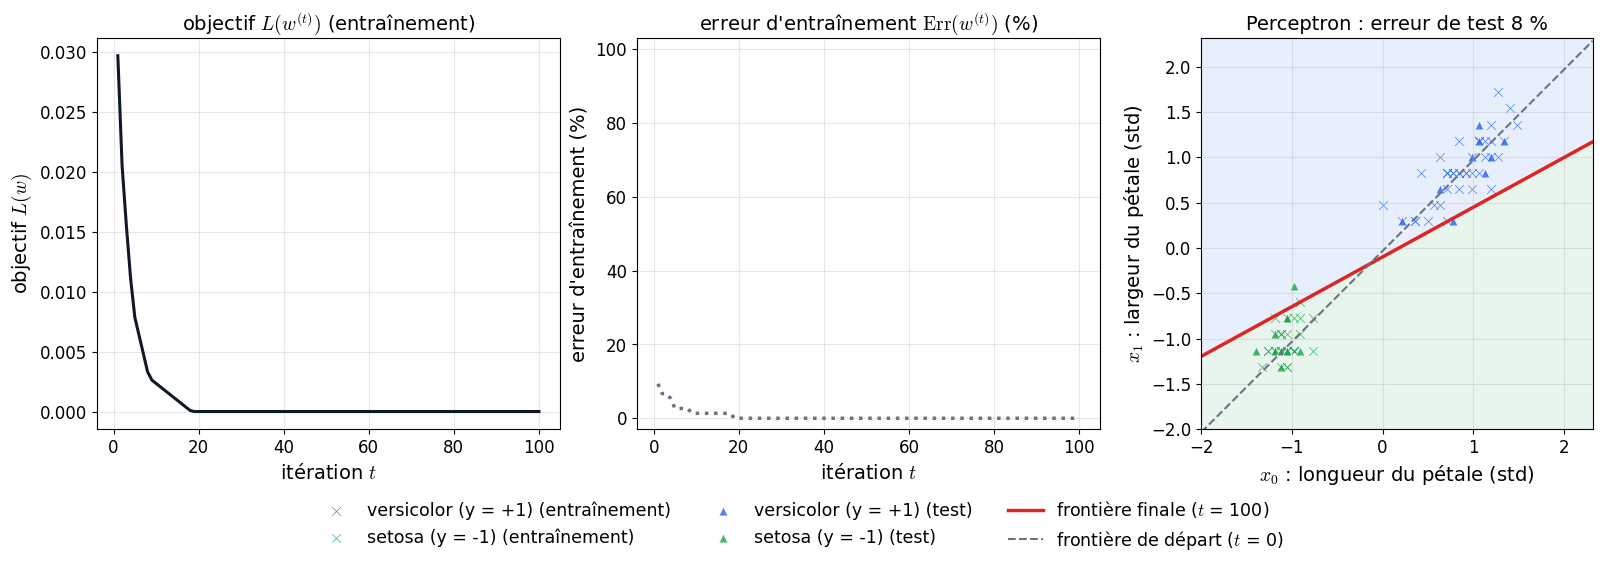

In [46]:
#@title Code : Perceptron (loss, gradient), contrôle du gradient, entraînement. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
# Question 3

class Perceptron(LinearModel):

    def __init__(self, w0, reg):  # constructeur : appelle celui de la classe parent
        super().__init__(w0, reg)  # tout est hérité de LinearModel

    def loss(self, X, y):  # objectif L(w), équation (3) : un seul nombre
        marges = y * self.predict(X)  # m_i = y_i w^⊤ x_i, forme (n,)
        return np.mean(np.maximum(0, -marges)) + 0.5 * self.reg * np.sum(self.w ** 2)  # moyenne des max(0, -m_i), plus lambda/2 ||w||^2

    def gradient(self, X, y):  # gradient de L en w, équation (5) : vecteur de même forme que w
        marges = y * self.predict(X)  # m_i = y_i w^⊤ x_i, forme (n,)
        coef = -(marges < 0).astype(float)  # l'(m_i) = -1{m_i < 0} : -1 pour les fleurs mal classées, 0 sinon (section 4)
        return ((coef * y)[:, np.newaxis] * X).mean(axis=0) + self.reg * self.w  # (1/n) somme des l'(m_i) y_i x_i, plus lambda w : la même ligne pour les quatre classes


verifier_gradient(Perceptron)  # contrôle automatique du gradient
test_model(Perceptron, reg=0, stepsize=1)  # réglages du labo (lambda = 0, eta = 1, T = 100)

> **🧠 Vérifiez votre prédiction :** <details><summary>Cliquez après avoir exécuté la cellule.</summary>0 % en entraînement (dès $t = 19$) mais **8 % en test** : 2 fleurs sur 25, avec $w \approx (-2.02,\ 3.69,\ 0.37)$ à l'arrivée. La frontière finale est collée aux fleurs d'entraînement (la plus proche est à 0.001 de la frontière) : le perceptron s'arrête à la première frontière sans erreur, pas à la meilleure, et deux fleurs de test tombent du mauvais côté.</details>

### ↩️ La démo D (section 6), rejouée ici avec le perceptron : son menu propose maintenant « perceptron ». Avec la régression linéaire, les 75 fleurs tiraient jusqu'au bout ; cette fois, seules les mal classées tirent.

> **🔮 Avant de bouger le curseur, prédisez :** Choisissez « perceptron » : quelles fleurs tirent encore quand l'erreur d'entraînement est à 0 % ? Et la frontière, bouge-t-elle encore ?

In [47]:
#@title Démo D, rejouée avec le perceptron (curseurs modèle, itération). Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
demo_D()  # la même démo qu'à la section 6 ; le menu contient maintenant le perceptron (code : fonction _demo_D de la boîte à outils)

Modèles disponibles : régression linéaire, perceptron ; réexécutez cette cellule après la section 8 pour ajouter : SVM, régression logistique.


> **🧠 Vérifiez votre prédiction :** <details><summary>Cliquez après avoir joué avec le curseur.</summary>Aucune : dès que l'erreur touche 0 % (à $t = 19$), $\ell'(m_i) = 0$ pour les 75 fleurs, plus aucune flèche, la résultante est nulle et $w$ ne bouge plus (de $t = 10$ à $t = 18$, une seule fleur tirait encore). L'apprentissage s'arrête net, sur la première frontière sans erreur.</details>

## 7.2 Démo R : le perceptron, une correction à la fois

### La règle historique de Rosenblatt, sur dix points jouets : on parcourt les points un par un ; si le point $(x, y)$ est mal classé ($m = y\,w^\top x < 0$), on fait $w \leftarrow w + \eta\,y\,x$ ; sinon on ne touche à rien.

Ici $w$ a trois composantes et $x = (x_0, x_1, 1)$, comme dans tout le reste du labo ; $(x, y)$ désigne le point fautif, et le pas vaut $\eta = 0.5$ dans la démo.

### Ajouter $y\,x$, c'est ajouter le point lui-même s'il est de classe $+1$, ou son opposé s'il est de classe $-1$ : $w$ bascule vers le point (ou s'en écarte), et la frontière, perpendiculaire à $w$, pivote.

### C'est exactement une itération de la descente (6) sur la perte du perceptron d'une seule fleur, sans régularisation.

$$w \;\leftarrow\; w - \eta\,\nabla_w \ell \;=\; w - \eta\,\underbrace{(-1)}_{\ell'(m),\ m < 0}\,y\,x \;=\; w + \eta\,y\,x$$

où $\nabla_w \ell = \ell'(m)\,y\,x$ est le gradient d'une fleur (4) et $\ell'(m) = -\mathbb{1}\{m < 0\} = -1$ pour une fleur mal classée : le signe moins de la descente et le signe moins de la pente s'annulent, d'où le $+$ de la règle de Rosenblatt. Pour une fleur bien classée, $\ell'(m) = 0$ et la mise à jour est nulle : « on ne touche à rien ».

### Une fleur à la fois au lieu de 75 : c'est la descente « stochastique » du bonus (un mini-lot de taille $k = 1$), découverte soixante ans avant son nom.

### Le curseur « étape » avance d'une étape à la fois ; chaque correction en prend trois, et il en faut quatre ici (avec $\eta = 0.5$) avant que le perceptron s'arrête. Le pas $\eta$ de (6) est fixé à 0.5.

> **📊** Étape 1 : le point fautif est entouré de noir. À gauche, sa tige rouge le relie au sol : un point de classe $+1$ sous la table, ou un point de classe $-1$ au-dessus ; à droite, il est du mauvais côté de la ligne rouge. Le titre donne sa marge $m$. **Cliquez-glissez dans la scène 3D pour la faire tourner, roulette pour zoomer** : elle garde votre point de vue quand vous bougez un curseur, et le survol d'un point affiche ses valeurs.

> **📊** Étape 2 : la somme de vecteurs, vue d'en haut, au pied de la frontière : $w$ (noir, ses deux premières composantes $(w_0, w_1)$), puis $\eta\,y\,x$ ajouté au bout (doré : le point lui-même ou son opposé, réduit de moitié ; le pointillé doré depuis l'origine montre le point comme vecteur $x$), et le nouveau $w$ (noir tireté). La troisième composante, $b \leftarrow b + \eta\,y$, ne se voit pas sur ce dessin.

> **📊** Étape 3 : le plan a pivoté et la frontière avec lui ; le point, toujours entouré, est passé du bon côté… ou pas : le titre le dit, avec sa nouvelle marge.

> **🔮 Avant de bouger le curseur, prédisez :** Après une correction, le point fautif sera-t-il forcément bien classé ?

> **🔮 Avant de bouger le curseur, prédisez :** Quand il n'y a plus d'erreur, où la frontière s'arrête-t-elle : au milieu du couloir, ou n'importe où ?

In [48]:
#@title Démo R : le perceptron, une correction à la fois (curseur étape). Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
demo_R()  # règle de Rosenblatt : w <- w + eta y x sur chaque point mal classé, étape par étape, eta = 0.5 (code : fonction _demo_R de la boîte à outils)

> **🧠 Vérifiez votre prédiction :** <details><summary>Cliquez après avoir joué avec le curseur.</summary>Pas forcément. Avant la correction, $m = y\,w^\top x$ ; après, $m' = y\,(w + \eta\,y\,x)^\top x = m + \eta\,y^2\,\lVert x\rVert^2 = m + \eta\,\lVert x\rVert^2$, car $y^2 = 1$. La marge monte de $\eta\,\lVert x\rVert^2$, qui peut être plus petit que $\lvert m\rvert$ : à la correction 1, $m = -1.85$ et $\eta\,\lVert x\rVert^2 = 0.5 \times 3.25 = 1.625$, donc $m' = -0.225$, le point reste mal classé (à la correction 2, $m' = +1.03$). Le théorème de Novikoff garantit seulement que le nombre total de corrections est fini si les données sont séparables. Et la frontière finale s'arrête n'importe où : à la première droite sans erreur, ici à 0.27 d'un point (pointillé de la dernière étape), pas au milieu du couloir.</details>

### Où s'arrête le perceptron ? À la première droite sans erreur, n'importe où dans le couloir. On le vérifiera à la démo H (fin de la section 8), dès qu'on aura le SVM pour comparer.

## 8. SVM

> **📖 Rappel de notation.** Marge $m_i = y_i\,w^\top x_i$ (2) ; objectif $L(w)$ (3) et son gradient $\nabla_w L$ (5) ; $\lambda$ = `reg` (force de la régularisation), $\eta$ = `stepsize` (le pas de (6)), $T$ = `n_steps` = 100 itérations. Deux normes : $\lVert w\rVert^2 = w_0^2 + w_1^2 + b^2$ (biais compris, pour la régularisation) et $\lVert (w_0, w_1)\rVert = \sqrt{w_0^2 + w_1^2}$ (sans le biais, pour la géométrie) : la distinction compte dans cette section (table complète : section 0.10).

## 8.1 La perte charnière et son gradient

### La perte du SVM est la **charnière** : $\ell(m) = \max(0, 1 - m)$, plate pour $m \ge 1$, puis une pente de $-1$.

On l'appelle charnière parce que sa courbe est pliée en $m = 1$, comme une charnière de porte (section 3, perte 3). Une fleur ne coûte rien dès que sa marge atteint 1 ; en dessous, elle paie $1 - m$, même si elle est bien classée.

### L'objectif (3) avec la charnière : la moyenne des $\max(0, 1 - m_i)$, plus l'élastique.

$$L(w) = \frac{1}{n}\sum_{i=1}^{n} \max(0, 1 - m_i) + \frac{\lambda}{2}\lVert w\rVert^2$$

où $m_i = y_i\,w^\top x_i$ est la marge de la fleur $i$, $n = 75$, $\lambda$ la force de la régularisation et $\lVert w\rVert^2 = w_0^2 + w_1^2 + b^2$ (le biais est régularisé lui aussi, par simplicité : c'est ce que fait `np.sum(self.w ** 2)`). Dans le code : `np.mean(np.maximum(0, 1 - marges)) + 0.5 * self.reg * np.sum(self.w ** 2)`.

### On branche $\ell'(m) = -\mathbb{1}\{m \lt 1\}$ dans (5) : les erreurs **et** les fleurs dans la bande de marge poussent.

$$\nabla_w L = \frac{1}{n}\sum_{i=1}^{n} \big(-\mathbb{1}\{m_i < 1\}\big)\,y_i\,x_i + \lambda\,w = -\frac{1}{n}\sum_{i\,:\,m_i < 1} y_i\,x_i + \lambda\,w$$

où $\mathbb{1}\{m_i < 1\}$ vaut 1 si la marge de la fleur $i$ est strictement inférieure à 1 et 0 sinon : dans la deuxième écriture, la somme ne porte plus que sur les fleurs mal classées ($m_i < 0$) ou dans la bande ($0 \le m_i < 1$). Ici $\lambda = 0.1$, le terme $\lambda\,w$ reste.

### C'est le perceptron décalé de 1 : une fleur pousse tant que sa marge est inférieure à 1, même si elle est déjà bien classée.

Au point anguleux $m = 1$, la pente saute de $-1$ à $0$ ; on pose $\ell'(1) := 0$, comme le fait l'inégalité stricte `marges < 1` du code (n'importe quelle valeur entre $-1$ et $0$ serait acceptable : c'est un *sous-gradient*, section 4).

### Maths ↔ code de la classe `SVM`.

<table width="100%">
<tr><th align="left" width="27%">maths</th><th align="left" width="33%">code</th><th align="left" width="40%">ce que c'est</th></tr>
<tr><td valign="top">$m_i = y_i\,w^\top x_i$</td><td valign="top"><code>marges = y * self.predict(X)</code></td><td valign="top">la marge de chaque fleur (2), un tableau de $n = 75$ nombres</td></tr>
<tr><td valign="top">$\max(0, 1 - m_i)$</td><td valign="top"><code>np.maximum(0, 1 - marges)</code></td><td valign="top">la charnière $\ell(m_i)$ de chaque fleur</td></tr>
<tr><td valign="top">$\ell'(m_i) = -\mathbb{1}\{m_i \lt 1\}$</td><td valign="top"><code>coef = -(marges &lt; 1).astype(float)</code></td><td valign="top">la pente de la perte de chaque fleur (section 4) : $-1$ pour les fleurs qui poussent encore (mal classées ou dans la bande de marge), 0 pour les autres</td></tr>
<tr><td valign="top">$\frac{1}{n}\sum_{i=1}^{n} \ell'(m_i)\,y_i\,x_i$</td><td valign="top"><code>((coef * y)[:, np.newaxis] * X).mean(axis=0)</code></td><td valign="top">la moyenne des gradients des fleurs, équation (5) : la même ligne dans les quatre classes</td></tr>
<tr><td valign="top">$\lambda\,w$</td><td valign="top"><code>self.reg * self.w</code></td><td valign="top">le gradient de l'élastique $\frac{\lambda}{2}\lVert w\rVert^2$</td></tr>
</table>

## 8.2 La bande de marge et sa largeur

### Distance d'une fleur à la frontière : $\dfrac{\lvert z\rvert}{\lVert (w_0, w_1)\rVert}$.

$$\text{distance de } x \text{ à la droite } w_0 x_0 + w_1 x_1 + b = 0 \;=\; \frac{\lvert w_0 x_0 + w_1 x_1 + b\rvert}{\sqrt{w_0^2 + w_1^2}} \;=\; \frac{\lvert z\rvert}{\lVert (w_0, w_1)\rVert}$$

où $z = w^\top x$ est le score de la fleur et $\lVert (w_0, w_1)\rVert = \sqrt{w_0^2 + w_1^2}$ la norme des deux premières composantes de $w$. C'est la formule de la distance d'un point à une droite. Le biais $b$ n'est pas dans la norme : il déplace la droite sans changer son angle. La *marge géométrique* d'une fleur est $m / \lVert (w_0, w_1)\rVert$ : sa distance signée à la frontière (négative si elle est mal classée).

### Les droites $z = +1$ et $z = -1$ sont donc chacune à $\dfrac{1}{\lVert (w_0, w_1)\rVert}$ de la frontière, une de chaque côté.

Entre les deux, c'est la **bande de marge** $-1 < w^\top x < 1$ (section 3) : les fleurs qui s'y trouvent ont $m < 1$ et poussent encore $w$.

### Largeur totale de la bande de marge.

$$\text{largeur de la bande} = \frac{2}{\lVert (w_0, w_1)\rVert}$$

où $\lVert (w_0, w_1)\rVert = \sqrt{w_0^2 + w_1^2}$, sans le biais (⏩ [Cortes et Vapnik, 1995](https://doi.org/10.1007/BF00994018) ; démonstration dans [Burges, 1998](https://doi.org/10.1023/A:1009715923555), section 3). Multiplier $w$ par 3 ne bouge pas la frontière (démo C), mais divise la largeur par 3 : la figure qui suit le montre.

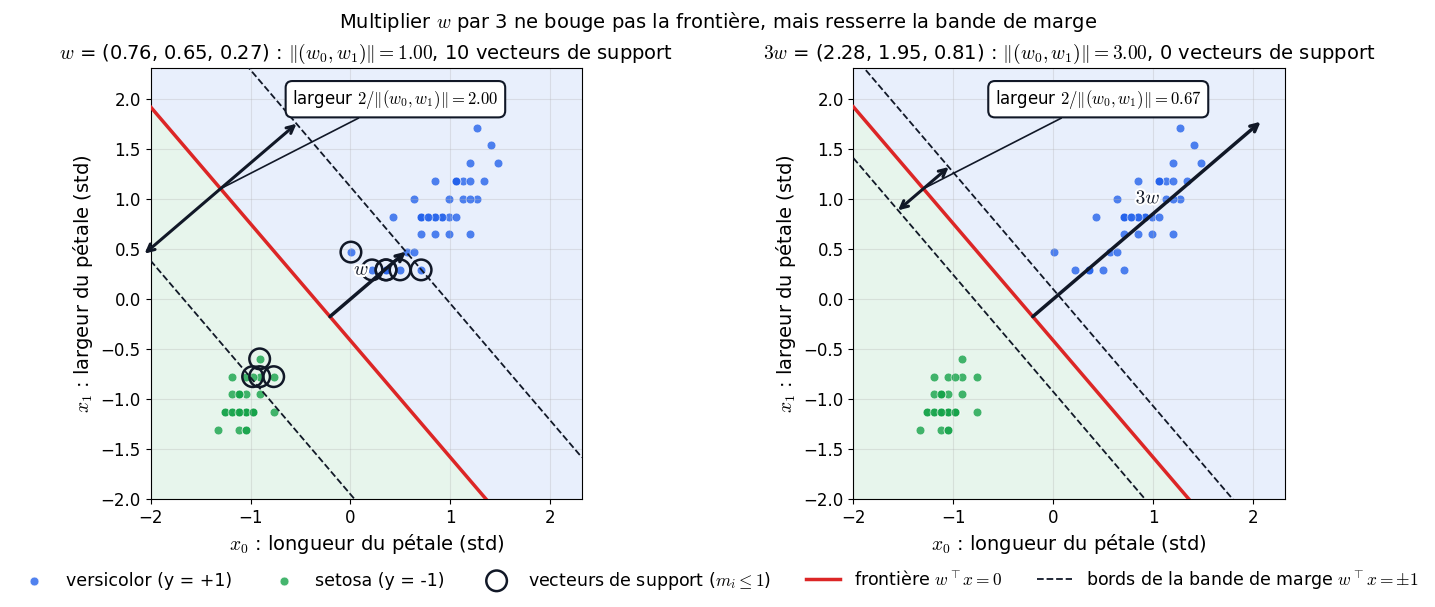

In [49]:
#@title Figure : la largeur de la bande de marge, pour w et pour 3w. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_largeur_bande()  # même frontière, bords z = ±1, double flèche cotée 2/||(w0, w1)||, vecteurs de support entourés

> **📊** Même frontière (rouge) dans les deux panneaux ; les tiretés noirs sont les droites $w^\top x = \pm 1$, les bords de la bande de marge ; la double flèche, perpendiculaire à la frontière, mesure sa largeur $2 / \lVert (w_0, w_1)\rVert$ : 2.00 pour $w$, 0.67 pour $3w$. La flèche noire est $w$ (ou $3w$, trois fois plus longue) ; les fleurs entourées de noir sont celles avec $m_i \le 1$ : dix avec $w$, aucune avec $3w$, la bande resserrée ne contient plus personne.

### Petit $(w_0, w_1)$ = bande large : c'est ce que fait l'élastique $\frac{\lambda}{2}\lVert w\rVert^2$ de (3).

La charnière veut toutes les fleurs hors de la bande ($m_i \ge 1$) ; l'élastique veut $w$ petit, donc la bande large. Le SVM cherche le compromis : la bande la plus large qui ne laisse pas trop de fleurs dedans. Voilà pourquoi le SVM s'entraîne avec $\lambda > 0$ et le perceptron avec $\lambda = 0$. Par simplicité, le labo pénalise les trois composantes, $b$ compris ($\lVert w\rVert^2 = w_0^2 + w_1^2 + b^2$) ; le SVM de Cortes et Vapnik ne pénalise que $(w_0, w_1)$. La différence est petite ici mais réelle : pénaliser $b$ tire aussi la frontière vers l'origine, sans changer la largeur de la bande.

### Les **vecteurs de support** sont les fleurs avec $m_i \le 1$ : sur un bord de la bande, dedans, ou mal classées.

Ce sont exactement celles dont la pente n'est pas nulle, $\ell'(m_i) \ne 0$ : les fleurs qui poussaient encore $w$ dans la démo D. Les autres pourraient disparaître sans changer la frontière ; c'est de là que vient le nom « machine à vecteurs de support ».

## 8.3 Le code et l'entraînement

### Le code qui suit : celui du perceptron avec `marges < 1` à la place de `marges < 0`.

### Réglages : $\lambda$ = `reg` = 0.1, $\eta$ = `stepsize` = 1, $T = 100$ itérations, $w^{(0)} = (-3, 3, 0.1)$.

> **🔮 Avant d'exécuter la cellule, prédisez :** La frontière du SVM sera-t-elle collée aux fleurs, comme celle du perceptron, ou au milieu du couloir ?

SVM | gradient (votre code) : [ 0.13 -0.    0.15] | différences finies : [ 0.13 -0.    0.15] | écart relatif : 5.8e-11
  => gradient correct ✅
Entraînement terminé : erreur d'entraînement = 0.00 %
Erreur de test : 0.00 %
Point de départ    w⁽⁰⁾ = (-3.00, 3.00, 0.10)  | λ = 0.1  | η = 1
Point d'arrivée    w⁽¹⁰⁰⁾ = (0.76, 0.65, 0.27)


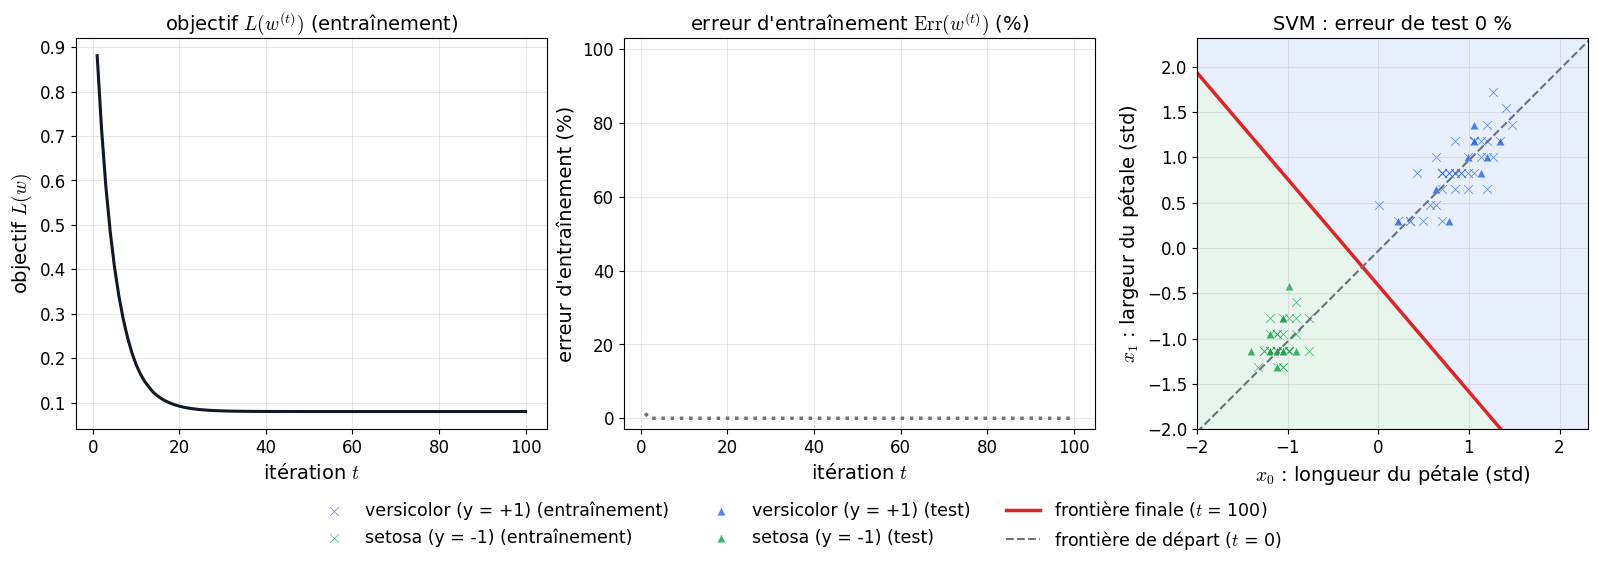

In [50]:
#@title Code : SVM (loss, gradient), contrôle du gradient, entraînement. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
# Question 4

class SVM(LinearModel):

    def __init__(self, w0, reg):  # constructeur : appelle celui de la classe parent
        super().__init__(w0, reg)  # tout est hérité de LinearModel

    def loss(self, X, y):  # objectif L(w), équation (3) : un seul nombre
        marges = y * self.predict(X)  # m_i = y_i w^⊤ x_i, forme (n,)
        return np.mean(np.maximum(0, 1 - marges)) + 0.5 * self.reg * np.sum(self.w ** 2)  # charnière moyenne, plus lambda/2 ||w||^2

    def gradient(self, X, y):  # gradient de L en w, équation (5) : vecteur de même forme que w
        marges = y * self.predict(X)  # m_i = y_i w^⊤ x_i, forme (n,)
        coef = -(marges < 1).astype(float)  # l'(m_i) = -1{m_i < 1} : -1 pour les fleurs mal classées OU dans la bande de marge, 0 sinon
        return ((coef * y)[:, np.newaxis] * X).mean(axis=0) + self.reg * self.w  # (1/n) somme des l'(m_i) y_i x_i, plus lambda w : la même ligne pour les quatre classes


verifier_gradient(SVM)  # contrôle automatique du gradient
test_model(SVM, reg=.1, stepsize=1)  # réglages du labo : lambda = 0.1, eta = 1, T = 100

> **🧠 Vérifiez votre prédiction :** <details><summary>Cliquez après avoir exécuté la cellule.</summary>Au milieu du couloir : 0 % d'erreur en entraînement et 0 % en test, $w \approx (0.76,\ 0.65,\ 0.27)$, donc $\lVert (w_0, w_1)\rVert \approx 1$ et une bande de marge large de $2 / \lVert (w_0, w_1)\rVert \approx 2.0$ ; le perceptron, lui, s'arrêtait collé aux fleurs avec 8 % d'erreur en test.</details>

### ↩️ Remontez à la démo D (section 6) et choisissez SVM : les flèches survivent après 0 % d'erreur, ce sont les fleurs avec $m \lt 1$, les vecteurs de support. Démo S avec SVM : le bol a des arêtes (la charnière n'est pas dérivable en $m = 1$).

## 8.4 Démo G : $\lambda$, la bande de marge et les vecteurs de support

### Promis à la section 3 : voici ce que $\lambda$ change sur la frontière.

### Le curseur $\lambda$ règle la raideur de l'élastique $\frac{\lambda}{2}\lVert w\rVert^2$ de (3) ; le menu « modèle » propose le SVM (la régression logistique s'y ajoutera à la section 9).

> **📊** Pour le SVM : la frontière (rouge) et les deux droites tiretées noires où le score vaut $+1$ et $-1$ ; l'espace entre elles est la bande de marge, et la double flèche mesure sa largeur $2 / \lVert (w_0, w_1)\rVert$ (écrite dans le titre). Les fleurs entourées de noir sont les vecteurs de support ($m_i \le 1$) : exactement celles qui poussaient encore $w$ dans la démo D. Le modèle est entraîné 1000 itérations ($\eta = 1$ pour le SVM, $0.5$ pour la logistique) pour être sûr d'avoir convergé ; c'est pour cela que $w$ diffère un peu de celui de `test_model` (100 itérations).

> **📊** Sous la figure : $\lambda$, $w$, $\lVert (w_0, w_1)\rVert$ et l'erreur d'entraînement, puis les deux termes de (3), la perte moyenne $\frac{1}{n}\sum_{i=1}^{n} \ell(m_i)$ et l'élastique $\frac{\lambda}{2}\lVert w\rVert^2$, leur somme $L(w)$ et le nombre de vecteurs de support.

> **🔮 Avant de bouger le curseur, prédisez :** Si on augmente $\lambda$ de 0.01 à 1, la bande de marge va-t-elle s'élargir ou se rétrécir ? Et le nombre de vecteurs de support ?

In [51]:
#@title Démo G : lambda, la bande de marge et les vecteurs de support (curseur). Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
demo_G()  # lambda, largeur de la bande 2/||(w0, w1)|| et vecteurs de support ; pour la logistique (section 9), la carte des probabilités

> **🧠 Vérifiez votre prédiction :** <details><summary>Cliquez après avoir joué avec le curseur.</summary>La bande s'élargit et les vecteurs de support se multiplient : $\lambda = 0.01$, largeur 1.42 et 2 vecteurs de support ; $\lambda = 0.1$, largeur 2.00 et 10 ; $\lambda = 1$, $w \approx (0.02, 0.02, 0.07)$ écrasé vers 0, bande large de 69 (bien plus que le cadre), les 75 fleurs dedans et 45 % d'erreur : trop d'élastique.</details>

### On a maintenant les deux cousins, perceptron et SVM : même code à un chiffre près (`marges < 0` contre `marges < 1`). La démo H les fait partir seize fois du même endroit.

## 8.5 Démo H : seize points de départ, perceptron contre SVM

> **📊** Deux panneaux, perceptron à gauche, SVM à droite, mêmes fleurs (croix : entraînement, triangles : test). Les seize points de départ sont $w^{(0)} = (3\cos\theta^{(0)},\ 3\sin\theta^{(0)},\ 0.1)$, sur un cercle de rayon 3 ; chaque trait fin est la frontière finale obtenue depuis l'un d'eux, grise si son erreur de test est 0 %, rouge sinon.

> **📊** Le trait rouge épais est la frontière finale du départ choisi par le curseur ; la flèche grise est $w^{(0)}$ (son angle est $\theta^{(0)}$) et les pointillés gris sa frontière initiale ; les croix rouges sont les fleurs de test mal classées par la frontière épaisse.

### Le curseur $\theta^{(0)}$ règle l'angle de $(w_0, w_1)$ au départ ; le reste est aux réglages du labo : perceptron $\lambda = 0$, SVM $\lambda = 0.1$, $\eta = 1$ et $T = 100$ itérations pour les deux.

> **🔮 Avant de bouger le curseur, prédisez :** Depuis 16 points de départ, combien de frontières finales différentes pour le perceptron ? Et pour le SVM ?

> **🔮 Avant de bouger le curseur, prédisez :** $\theta^{(0)} = 0°$ et $\theta^{(0)} = 180°$ donnent la même droite initiale, avec les classes inversées. Les frontières finales seront-elles les mêmes ?

In [52]:
#@title Démo H : seize points de départ, perceptron contre SVM (curseur). Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
demo_H()  # seize points de départ w^(0) = (3 cos theta^(0), 3 sin theta^(0), 0.1) : perceptron contre SVM

> **🧠 Vérifiez votre prédiction :** <details><summary>Cliquez après avoir joué avec le curseur.</summary>Perceptron : un éventail de frontières, avec une erreur de test de 0 % à 8 % selon le départ ; SVM : une seule frontière, à un cheveu près, $w \approx (0.76, 0.65, 0.27)$ pour les seize départs. À $\theta^{(0)} = 0°$, le perceptron part sans erreur et ne bouge pas (frontière verticale) ; à $\theta^{(0)} = 180°$, il part avec 100 % d'erreur et s'arrête sur une frontière à 8 % d'erreur de test : deux résultats différents pour la même droite initiale. Le SVM arrive au même endroit dans les deux cas.</details>

## 9. Régression logistique

> **📖 Rappel de notation.** Score $z = w^\top x$ (1), marge $m = y\,z$ (2) ; pour la fleur $i$ : $m_i = y_i\,w^\top x_i$. $\ell(m)$ est la perte d'une fleur et $\ell'(m)$ sa pente ; $L(w)$ est l'objectif (3) et $\nabla_w L$ son gradient (5), avec $\lambda$ = `reg` la force de la régularisation. La descente (6) fait $T$ = `n_steps` itérations de pas $\eta$ = `stepsize` depuis $w^{(0)}$ = `w0`. Nouveau dans cette section : la **sigmoïde** $\sigma(a) = \dfrac{1}{1 + e^{-a}}$.

## 9.1 Le sens probabiliste de la perte logistique

### Promis à la section 3 : voici le sens de probabilité de la perte logistique.

### Ce modèle lit le score comme une probabilité, grâce à la sigmoïde (une courbe « en S », qui va de 0 à 1).

$$\sigma(a) = \frac{1}{1 + e^{-a}}, \qquad P(y = +1 \mid x) = \sigma(z) = \sigma(w^\top x)$$

où $a$ est n'importe quel nombre réel, $z = w^\top x$ est le score (1) et $P(y = +1 \mid x)$ se lit « la probabilité que la fleur $x$ soit versicolor, selon le modèle » ([Hastie, Tibshirani et Friedman, 2009](https://hastie.su.domains/ElemStatLearn/), section 4.4).

### La classe $-1$ reçoit le reste, et ce reste est encore une sigmoïde : on multiplie le haut et le bas par $e^{z}$.

$$P(y = -1 \mid x) = 1 - \sigma(z) = 1 - \frac{1}{1 + e^{-z}} = \frac{e^{-z}}{1 + e^{-z}} = \frac{1}{e^{z} + 1} = \sigma(-z)$$

où $\sigma(-z)$ est la sigmoïde évaluée en $-z$ : retourner le score, c'est échanger les deux classes.

### À $z = 0$, la probabilité vaut $\sigma(0) = \tfrac12$ : la frontière $w^\top x = 0$ est la ligne des 50 %. Loin de la frontière, le modèle est presque sûr de lui.

### Pour une fleur d'étiquette $y$, les deux formules n'en font plus qu'une, grâce à la marge $m = y\,z$ (2).

$$P(\text{vraie classe}) = \begin{cases} \sigma(z) & \text{si } y = +1 \\ \sigma(-z) & \text{si } y = -1 \end{cases} = \sigma(y\,z) = \sigma(m), \qquad P(\text{mauvaise classe}) = 1 - \sigma(m) = \frac{1}{1 + e^{m}} = \sigma(-m)$$

où $m$ est la marge de la fleur ; la dernière égalité est le calcul de la cellule précédente, avec $m$ à la place de $z$.

### La perte logistique de la section 3 est moins le logarithme de la probabilité de la vraie classe.

$$\ell(m) = -\log \sigma(m) = \log \frac{1}{\sigma(m)} = \log\left(1 + e^{-m}\right)$$

où $\sigma(m) = P(\text{vraie classe})$ : une fleur coûte 0 quand le modèle est sûr de sa vraie classe ($\sigma(m) \to 1$), et de plus en plus cher quand il parie sur l'autre ($\sigma(m) \to 0$).

### ⏩ Minimiser $L(w)$, c'est donc maximiser la probabilité que le modèle donne aux vraies classes des 75 fleurs à la fois (leur produit, qu'on appelle la **vraisemblance**) ; le $\log$ transforme ce produit en somme, et la régularisation $\frac{\lambda}{2}\lVert w\rVert^2$ s'ajoute comme pour les trois autres.

### Et sa pente, calculée à la section 4, est moins la probabilité de la mauvaise classe.

$$\ell'(m) = -\frac{1}{1 + e^{m}} = -\sigma(-m) = -\big(1 - \sigma(m)\big) = -P(\text{mauvaise classe})$$

où $\sigma(-m)$ est entre 0 et 1 : une fleur pousse $w$ avec une force égale à l'erreur que le modèle croit faire sur elle.

> **📊** À gauche : la sigmoïde $\sigma(z)$, et le fond de couleur du modèle, de 0 (vert : « setosa, sûr ») à 1 (bleu : « versicolor, sûr ») en passant par le blanc à $z = 0$ : la frontière est la ligne des 50 %, et $z = \pm 2.2$ donne 90 % et 10 %. À droite : la perte logistique $\ell(m) = -\log \sigma(m)$ (sarcelle) au-dessus de la marche de l'erreur 0-1 (noir), avec les trois fleurs 🌸 du fil rouge pour le $w$ « à la main » de la section 0.

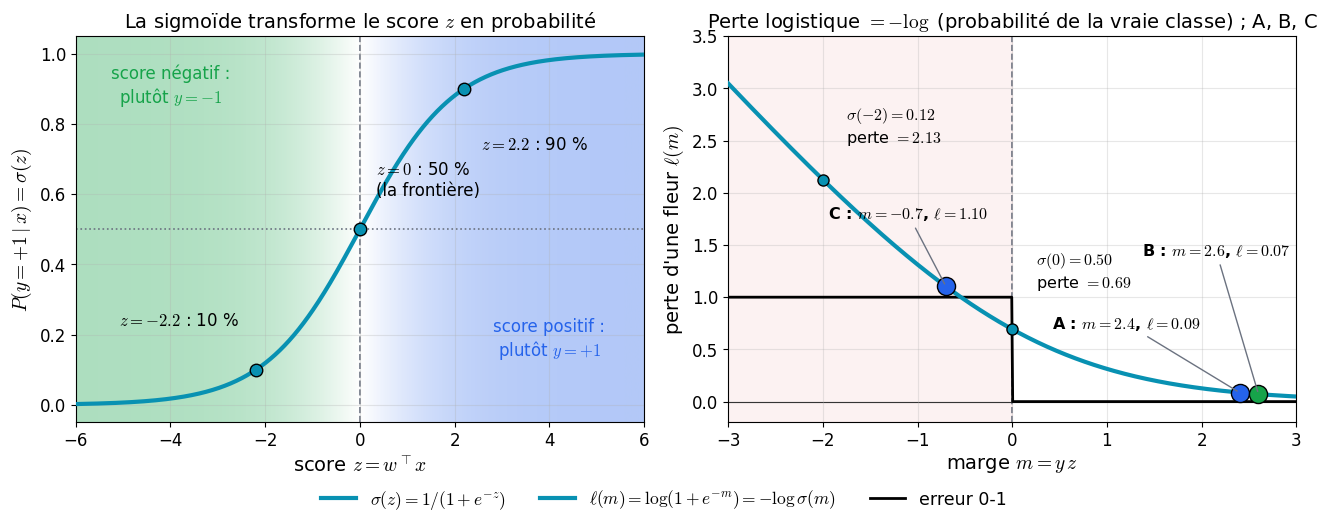

In [53]:
#@title Figure : la sigmoïde, et la perte logistique comme moins le log d'une probabilité. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_sigmoide()  # à gauche sigma(z) sur fond vert -> blanc -> bleu ; à droite l(m) = -log sigma(m) avec A, B, C

### 🌸 Sur la courbe de droite : la fleur A ($m = 2.4$) paie $\ell = 0.09$, B ($m = 2.6$) paie $0.07$, C ($m = -0.7$, mal classée) paie $1.10$. Ce sont les nombres de la colonne « logistique » du tableau de la section 3 ; en probabilités : $\sigma(2.4) = 0.92$, $\sigma(2.6) = 0.93$, $\sigma(-0.7) = 0.33$.

## 9.2 L'objectif, le gradient et le code

### L'objectif (3) avec cette perte : la moyenne des $\log(1 + e^{-m_i})$ plus la régularisation.

$$L(w) = \frac{1}{n}\sum_{i=1}^{n} \log\left(1 + e^{-m_i}\right) + \frac{\lambda}{2}\lVert w\rVert^2, \qquad m_i = y_i\,w^\top x_i$$

où $n = 75$ est le nombre de fleurs d'entraînement, $\lambda$ la force de la régularisation et $\lVert w\rVert^2 = w_0^2 + w_1^2 + b^2$ ; dans le code, c'est la méthode `loss`.

### On branche $\ell'(m) = -\dfrac{1}{1 + e^{m}}$ dans la formule du gradient (5) : la pente de chaque fleur apparaît en facteur devant $y_i\,x_i$.

$$\nabla_w L = -\frac{1}{n}\sum_{i=1}^{n} \frac{1}{1 + e^{m_i}}\;y_i\,x_i + \lambda\,w, \qquad m_i = y_i\,w^\top x_i$$

où $\dfrac{1}{1 + e^{m_i}} = \sigma(-m_i)$ est la probabilité que le modèle donne à la mauvaise classe de la fleur $i$ ; dans le code, c'est la méthode `gradient`.

### Qui pousse ? Toutes les fleurs, chacune proportionnellement à l'erreur que le modèle croit faire sur elle : les mal classées fort (force proche de 1), les bien classées de moins en moins (force proche de 0), mais jamais exactement 0. Comparez : perceptron = les erreurs seules, SVM = les fleurs avec $m_i \lt 1$, régression linéaire = toutes, même en sens inverse.

### Maths ↔ code de la classe `LogisticRegression`.

<table width="100%">
<tr><th align="left" width="27%">maths</th><th align="left" width="33%">code</th><th align="left" width="40%">ce que c'est</th></tr>
<tr><td valign="top">$m_i = y_i\,w^\top x_i$</td><td valign="top"><code>marges = y * self.predict(X)</code></td><td valign="top">la marge de chaque fleur (2), un tableau de $n = 75$ nombres</td></tr>
<tr><td valign="top">$\log(1 + e^{-m_i})$</td><td valign="top"><code>np.logaddexp(0, -marges)</code></td><td valign="top">la perte $\ell(m_i)$ de chaque fleur, calculée comme $\log(e^{0} + e^{-m_i})$ sans débordement</td></tr>
<tr><td valign="top">$\ell'(m_i) = -\dfrac{1}{1 + e^{m_i}} = -\sigma(-m_i)$</td><td valign="top"><code>coef = -np.exp(-np.logaddexp(0, marges))</code></td><td valign="top">la pente de la perte de chaque fleur (section 4) : moins la probabilité que le modèle donne à la mauvaise classe</td></tr>
<tr><td valign="top">$\frac{1}{n}\sum_{i=1}^{n} \ell'(m_i)\,y_i\,x_i$</td><td valign="top"><code>((coef * y)[:, np.newaxis] * X).mean(axis=0)</code></td><td valign="top">la moyenne des gradients des fleurs, équation (5) : la même ligne dans les quatre classes</td></tr>
<tr><td valign="top">$\lambda\,w$</td><td valign="top"><code>self.reg * self.w</code></td><td valign="top">le gradient de l'élastique $\frac{\lambda}{2}\lVert w\rVert^2$</td></tr>
</table>

### Pourquoi `np.logaddexp` ? Parce que $e^{800}$ dépasse le plus grand nombre que l'ordinateur sait écrire : `np.log(1 + np.exp(800))` donne `inf`, alors que `np.logaddexp(0, 800)` donne `800.0`, la bonne réponse.

### Réglages : $\lambda$ = `reg` = 0.1, $\eta$ = `stepsize` = 0.2, $T$ = `n_steps` = 100 itérations, $w^{(0)}$ = `w0` = $(-3, 3, 0.1)$. Les mêmes que pour la régression linéaire (section 6).

> **🔮 Avant d'exécuter la cellule, prédisez :** 0 % d'erreur en entraînement est acquis (les fleurs sont séparables) ; et en test ? Et la courbe de $L(w)$ : va-t-elle tomber à 0 comme celle du perceptron, ou rester au-dessus ?

LogisticRegression | gradient (votre code) : [ 0.05 -0.08  0.16] | différences finies : [ 0.05 -0.08  0.16] | écart relatif : 9.8e-11
  => gradient correct ✅
Entraînement terminé : erreur d'entraînement = 0.00 %
Erreur de test : 0.00 %
Point de départ    w⁽⁰⁾ = (-3.00, 3.00, 0.10)  | λ = 0.1  | η = 0.2
Point d'arrivée    w⁽¹⁰⁰⁾ = (0.69, 1.42, 0.19)


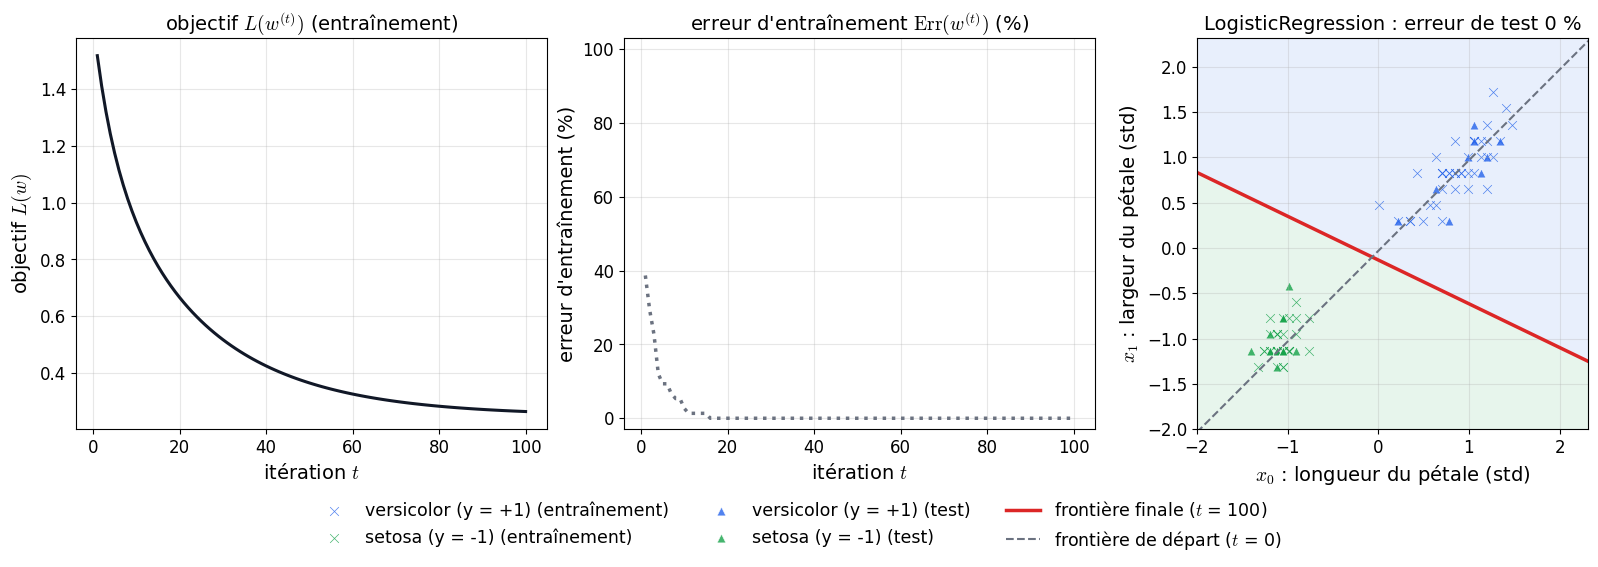

In [54]:
#@title Code : LogisticRegression (loss, gradient), contrôle du gradient, entraînement. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
# Question 5

class LogisticRegression(LinearModel):

    def __init__(self, w0, reg):  # constructeur : appelle celui de la classe parent
        super().__init__(w0, reg)  # tout est hérité de LinearModel

    def loss(self, X, y):  # objectif L(w), équation (3) : un seul nombre
        marges = y * self.predict(X)  # m_i = y_i w^⊤ x_i, forme (n,)
        return np.mean(np.logaddexp(0, -marges)) + 0.5 * self.reg * np.sum(self.w ** 2)  # moyenne des log(1 + e^{-m_i}) (sans débordement), plus lambda/2 ||w||^2

    def gradient(self, X, y):  # gradient de L en w, équation (5) : vecteur de même forme que w
        marges = y * self.predict(X)  # m_i = y_i w^⊤ x_i, forme (n,)
        coef = -np.exp(-np.logaddexp(0, marges))  # l'(m_i) = -1 / (1 + e^{m_i}) = -sigma(-m_i) : moins la probabilité donnée à la mauvaise classe
        return ((coef * y)[:, np.newaxis] * X).mean(axis=0) + self.reg * self.w  # (1/n) somme des l'(m_i) y_i x_i, plus lambda w : la même ligne pour les quatre classes


verifier_gradient(LogisticRegression)  # contrôle automatique du gradient
test_model(LogisticRegression)  # réglages du labo : lambda = reg = 0.1, eta = stepsize = 0.2, T = 100 itérations

> **🧠 Vérifiez votre prédiction :** <details><summary>Cliquez après avoir exécuté la cellule.</summary>0 % en entraînement et 0 % en test, $w \approx (0.69,\ 1.42,\ 0.19)$. La courbe de $L(w)$ reste au-dessus de 0 (elle finit vers 0.26) : chaque fleur paie encore $-\log\sigma(m_i) \gt 0$, même bien classée, et la régularisation s'ajoute.</details>

### ↩️ Retour à la démo G (section 8) : remontez-y et choisissez maintenant `LogisticRegression` dans le menu « modèle » (réexécutez la cellule de la démo si le menu ne le propose pas encore).

> **📊** Pour la logistique, la couleur de fond est $P(y = +1 \mid x) = \sigma(w^\top x)$, de 0 (vert : setosa sûre) à 1 (bleu : versicolor sûre) ; le blanc est le 50 %, c'est-à-dire la frontière. Les trois courbes sont les niveaux 10 %, 50 % et 90 % : entre 10 % et 90 %, le modèle hésite.

> **🔮 Avant de bouger le curseur, prédisez :** Si on augmente $\lambda$ de 0.01 à 1, la bande entre 10 % et 90 % va-t-elle s'élargir ou se resserrer ?

> **🧠 Vérifiez votre prédiction :** <details><summary>Cliquez après avoir joué avec le curseur.</summary>S'élargir : la bande entre 10 % et 90 % a une largeur $2\log 9 / \lVert (w_0, w_1)\rVert$, et un grand $\lambda$ rapetisse $w$ ; les scores se rapprochent de 0 et les probabilités de 50 %. Avec les réglages de la démo G (1000 itérations), la largeur passe d'environ 1.5 ($\lambda = 0.01$) à 2.9 ($\lambda = 0.1$) puis 9.6 ($\lambda = 1$).</details>

### ↩️ Démo D (section 6) avec `LogisticRegression` : les marques de force restent sur toutes les fleurs jusqu'au bout, mais rapetissent (à la fin, la force $\sigma(-m_i)$ vaut entre 0.03 et 0.32). Démo E avec `LogisticRegression` : pas d'étoile, car le minimum de cette $L$ n'a pas de formule ; il existe pourtant, grâce à $\lambda \gt 0$, et la descente s'en approche.

## 9.3 Démo I : des fleurs trop bien classées

### Souvenez-vous de la surprise de la section 3 : pour la régression linéaire, une fleur trop bien classée paie encore ($m = 2$ coûte 0.5), et à la section 4 on a vu que la fleur 🌸 A tire $w$ en arrière. Voici ce que ça fait sur une frontière entière.

> **📊** Les fleurs d'origine, plus un groupe d'étoiles bleues ajoutées loin à droite (versicolor, $y = +1$, position réglable). Pour chaque méthode, la frontière sans les points ajoutés (tiretée) et avec (trait plein) : violet pour la régression linéaire, sarcelle pour la logistique ; l'arc d'angle mesure la rotation de $(w_0, w_1)$. Avec 0 point ajouté, les deux droites de chaque méthode se superposent.

> **📊** Les dix étoiles sont des fleurs qui, pour la régression linéaire, tirent la corde en arrière : leur marge est bien plus grande que 1, donc leur pente $\ell'(m) = m - 1$ est positive. Pour la logistique, leur force $\sigma(-m)$ est quasi nulle.

### Les curseurs : le nombre de points ajoutés et la position $(x_0, x_1)$ du groupe. Réglages de cette démo : les deux modèles sont réentraînés à chaque fois avec $\lambda = 0.01$, $\eta = 0.2$ et $T = 1000$ itérations ($\lambda$ plus petit que dans les sections 6 et 9, pour que les points ajoutés pèsent vraiment, et plus d'itérations pour être sûr d'avoir convergé : avec les réglages de `test_model`, on n'obtiendrait pas les mêmes angles).

> **🔮 Avant de bouger le curseur, prédisez :** On ajoute 10 fleurs versicolor très loin de la frontière, du bon côté, parfaitement bien classées. La frontière de la régression linéaire va-t-elle bouger ? Et celle de la logistique ?

In [55]:
#@title Démo I : des fleurs trop bien classées (curseurs). Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
demo_I()  # des points trop bien classés : régression linéaire contre logistique

> **🧠 Vérifiez votre prédiction :** <details><summary>Cliquez après avoir joué avec le curseur.</summary>La régression linéaire pivote de $+68°$ ; la logistique d'à peine $1°$. Avant l'ajout, les dix étoiles ont une marge $m \approx 4$ pour la régression linéaire : c'est la fleur A de la section 4 ($m = 2.4$, qui tire $w$ en arrière), en dix exemplaires et encore plus loin. Pour la logistique, elles ont déjà une probabilité d'erreur quasi nulle et ne poussent presque plus.</details>

## 9.4 🌸 Retour aux trois fleurs

### 🌸 Retour aux trois fleurs : avec les quatre $w$ appris (sections 6 à 9), la fleur C est-elle enfin bien classée ? Quelle méthode lui donne la plus grande marge ?

> **🔮 Avant d'exécuter la cellule, prédisez :** Le $w$ « à la main » de la section 0 classait mal C ($m = -0.7$). Combien des quatre méthodes la classent bien ?

In [56]:
#@title Fil rouge : A, B et C avec les quatre w appris (score, marge, verdict). Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
for nom_classe, nom in NOMS_MODELES.items():  # les quatre classes, dans l'ordre des sections 6 à 9
    if nom_classe in MODELES:  # entraînée par test_model (sinon : la cellule de code de sa section n'a pas été exécutée)
        print(f'--- {nom} : ‖(w₀, w₁)‖ = {np.linalg.norm(MODELES[nom_classe].w[:2]):.2f}')  # nom et norme de (w0, w1), pour comparer les marges
        tableau_abc(MODELES[nom_classe].w)  # score z, marge m et verdict de A, B, C pour ce w
        print()  # ligne vide entre deux méthodes

--- régression linéaire : ‖(w₀, w₁)‖ = 0.73
w = (w₀, w₁, b) = (0.22, 0.70, 0.08)
fleur      x₀     x₁    y   score z   marge m   verdict  (z = w⊤x, m = y z)
A         1.6    1.2   +1      1.28      1.28   bien classée
B        -1.3   -0.9   -1     -0.83      0.83   bien classée
C        -1.6    1.3   +1      0.64      0.64   bien classée

--- perceptron : ‖(w₀, w₁)‖ = 4.20
w = (w₀, w₁, b) = (-2.02, 3.69, 0.37)
fleur      x₀     x₁    y   score z   marge m   verdict  (z = w⊤x, m = y z)
A         1.6    1.2   +1      1.56      1.56   bien classée
B        -1.3   -0.9   -1     -0.32      0.32   bien classée
C        -1.6    1.3   +1      8.39      8.39   bien classée

--- SVM : ‖(w₀, w₁)‖ = 1.00
w = (w₀, w₁, b) = (0.76, 0.65, 0.27)
fleur      x₀     x₁    y   score z   marge m   verdict  (z = w⊤x, m = y z)
A         1.6    1.2   +1      2.26      2.26   bien classée
B        -1.3   -0.9   -1     -1.30      1.30   bien classée
C        -1.6    1.3   +1     -0.11     -0.11   MAL classée

--

> **🧠 Vérifiez votre prédiction :** <details><summary>Cliquez après avoir exécuté la cellule.</summary>Trois sur quatre : la régression linéaire ($m = 0.64$), le perceptron ($m = 8.39$) et la logistique ($m = 0.94$) classent bien C ; le SVM la classe mal, de justesse ($m = -0.11$). A et B sont bien classées par les quatre.</details>

### Lecture : la marge $m$ dépend de l'échelle de $w$ (démo C), donc pour comparer des méthodes on divise par $\lVert (w_0, w_1)\rVert$. Distance de C à la frontière : perceptron $8.39 / 4.20 = 2.0$, régression linéaire $0.64 / 0.73 = 0.9$, logistique $0.94 / 1.58 = 0.6$, SVM $-0.11$. C est une fleur atypique (pétale court mais large) : aucune fleur d'entraînement ne lui ressemble, et les quatre frontières, toutes à 0 % d'erreur, ne sont pas d'accord sur elle.

## 9.5 Démo F : les quatre méthodes côte à côte

### Depuis la section 1, le problème est volontairement facile : un couloir vide entre les deux nuages. Le menu « paire d'espèces » ouvre enfin le cas du milieu de la section 0 : versicolor contre virginica se chevauchent, et aucune droite ne fait 0 %.

> **📊** Quatre panneaux, un par méthode, mêmes fleurs (croix : entraînement, triangles : test). La frontière de chaque méthode est dans sa couleur (violet, orange, magenta, sarcelle) avec un liseré rouge ; pour le SVM, les tirets noirs sont les bords de la bande de marge $w^\top x = \pm 1$.

> **📊** Sous chaque titre : l'erreur d'entraînement, l'erreur de test et la **marge géométrique minimale** $\gamma = \min_i m_i / \lVert (w_0, w_1)\rVert$ : la distance entre la frontière et la fleur d'entraînement la plus proche (négative s'il y a une erreur). On divise par $\lVert (w_0, w_1)\rVert$ pour comparer des méthodes dont les $w$ n'ont pas la même taille (le perceptron a $\min_i m_i = 0.003$ mais $\lVert (w_0, w_1)\rVert = 4.2$). Le tableau sous la figure reprend ces nombres.

### Les curseurs : la paire d'espèces, et $T$ = `n_steps` (100, 300 ou 1000 itérations). Chaque méthode garde ses réglages $(\lambda, \eta)$ de sa section et part de $w^{(0)} = (-3, 3, 0.1)$.

> **🔮 Avant de bouger le curseur, prédisez :** Laquelle aura la plus grande marge géométrique minimale $\gamma$ ? La plus petite ?

> **🔮 Avant de bouger le curseur, prédisez :** Puis on passe à versicolor contre virginica, qui se chevauchent : laquelle va souffrir le plus ?

In [57]:
#@title Démo F : les quatre méthodes côte à côte (curseurs). Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
demo_F()  # les quatre méthodes côte à côte, et la paire versicolor contre virginica

> **🧠 Vérifiez votre prédiction :** <details><summary>Cliquez après avoir joué avec le curseur.</summary>Setosa contre versicolor : $\gamma$ = 0.58 pour le SVM, 0.48 pour la logistique, 0.46 pour la régression linéaire et 0.001 pour le perceptron, le seul à se tromper en test (8 %). Versicolor contre virginica : 5 à 7 % d'erreur d'entraînement et 8 % en test pour les quatre, $\gamma \lt 0$ partout ; le perceptron ne se stabilise pas, sa frontière change encore entre 100 et 1000 itérations.</details>

## 10. Récap : le labo en six phrases

> **📖 Rappel de notation.** Une fleur est $x = (x_0, x_1, 1)$, sa vraie classe $y \in \{-1, +1\}$, les poids $w = (w_0, w_1, b)$. Son score est $z = w^\top x$ (1), sa marge $m = y\,z$ (2), sa perte $\ell(m)$ et le gradient de cette perte $\nabla_w \ell$ (4) ; l'objectif sur les $n = 75$ fleurs est $L(w)$ (3), son gradient $\nabla_w L$ (5) ; la descente répète (6) pendant $T = 100$ itérations avec le pas $\eta$, et $\lambda$ (sections 3 et 8) est la force de la régularisation. Dans le code : $\lambda$ = `reg`, $\eta$ = `stepsize`, $T$ = `n_steps`, $w^{(0)}$ = `w0`.

### 1. Un classifieur linéaire calcule le score $z = w^\top x$ et prédit $\hat y = \mathrm{sign}(z)$ ; sa frontière est la droite $w^\top x = 0$, perpendiculaire à $(w_0, w_1)$ (section 0).

### 2. La marge $m = y\,z$ résume tout : $m > 0$ bien classée, $m < 0$ mal classée, $m$ grand = loin de la frontière, du bon côté (section 0).

### 3. Le taux d'erreur $\mathrm{Err}(w)$ est une marche sans pente : on minimise à la place une perte de remplacement $\ell(m)$, convexe, fonction de la marge seulement (sections 2 et 3).

### 4. Le gradient d'une fleur est $\nabla_w \ell = \ell'(m)\,y\,x$ : un nombre fois $x$ ; les quatre méthodes ne diffèrent que par ce nombre, la pente $\ell'(m)$ (section 4).

### 5. La descente répète $w^{(t+1)} = w^{(t)} - \eta\,\nabla_w L(w^{(t)})$ ; un pas $\eta$ trop grand fait diverger, et $\lambda$ garde $w$ petit (section 5).

### 6. Régression linéaire : pénalise aussi les fleurs trop bien classées. Perceptron : s'arrête sur la première frontière sans erreur. SVM : bande de marge la plus large possible, un seul minimum. Logistique : des probabilités (sections 6 à 9).

### Les six équations du labo

(1) le score et la classe prédite : $z = w^\top x$, $\hat y = \mathrm{sign}(z)$

(2) la marge : $m = y\,z$

(3) l'objectif : $L(w) = \dfrac{1}{n}\sum_{i=1}^{n} \ell(m_i) + \dfrac{\lambda}{2}\lVert w\rVert^2$

(4) le gradient d'une fleur : $\nabla_w \ell = \ell'(m)\,y\,x$

(5) le gradient de l'objectif : $\nabla_w L = \dfrac{1}{n}\sum_{i=1}^{n} \ell'(m_i)\,y_i\,x_i + \lambda\,w$

(6) une itération de la descente : $w^{(t+1)} = w^{(t)} - \eta\,\nabla_w L(w^{(t)})$, qu'on écrit aussi $w \leftarrow w - \eta\,\nabla_w L(w)$

où $x_i$, $y_i$, $m_i$ sont l'entrée, l'étiquette et la marge de la fleur $i$ ($i = 1, \dots, n$), $\lVert w\rVert^2 = w_0^2 + w_1^2 + b^2$ (biais compris), $\ell'(m) = d\ell/dm$ est la pente de la perte, et $w^{(t)}$ le vecteur de poids après $t$ itérations ($w^{(0)} = (-3, 3, 0.1)$ dans tout le labo).

### Le tableau à emporter : les quatre pertes, leurs pentes et leur code.

<table width="100%">
<tr><th align="left" width="9%">méthode</th><th align="left" width="13%">$\ell(m)$</th><th align="left" width="16%">$\ell'(m)$</th><th align="left" width="17%">qui tire</th><th align="left" width="20%">$\ell'(m_i)\,y_i$ dans le code</th><th align="left" width="9%">$(\lambda, \eta)$</th><th align="left" width="16%">classe</th></tr>
<tr><td valign="top">régression linéaire</td><td valign="top">$\tfrac12 (m - 1)^2$</td><td valign="top">$m - 1$</td><td valign="top">toutes les fleurs, dans les deux sens (force $\lvert m - 1\rvert$)</td><td valign="top"><code>coef = marges - 1</code></td><td valign="top">$(0.1,\ 0.2)$</td><td valign="top"><code>LinearRegression</code></td></tr>
<tr><td valign="top">perceptron</td><td valign="top">$\max(0, -m)$</td><td valign="top">$-\mathbb{1}\{m \lt 0\}$</td><td valign="top">les mal classées seulement, force 1</td><td valign="top"><code>coef = -(marges &lt; 0)</code></td><td valign="top">$(0,\ 1)$</td><td valign="top"><code>Perceptron</code></td></tr>
<tr><td valign="top">SVM</td><td valign="top">$\max(0, 1 - m)$</td><td valign="top">$-\mathbb{1}\{m \lt 1\}$</td><td valign="top">les mal classées et la bande $m \lt 1$, force 1</td><td valign="top"><code>coef = -(marges &lt; 1)</code></td><td valign="top">$(0.1,\ 1)$</td><td valign="top"><code>SVM</code></td></tr>
<tr><td valign="top">logistique</td><td valign="top">$\log(1 + e^{-m})$</td><td valign="top">$-\dfrac{1}{1 + e^{m}} = -\sigma(-m)$</td><td valign="top">toutes, force = probabilité donnée à la mauvaise classe</td><td valign="top"><code>coef = -np.exp(-np.logaddexp(0, marges))</code></td><td valign="top">$(0.1,\ 0.2)$</td><td valign="top"><code>LogisticRegression</code></td></tr>
</table>

où « qui tire » se lit sur la pente : $\ell'(m) < 0$ pousse $w$ vers la fleur, $\ell'(m) > 0$ la repousse, $\ell'(m) = 0$ ne fait rien (section 4), et $(\lambda, \eta)$ sont les réglages de `test_model` dans chaque section, avec $T = 100$ et $w^{(0)} = (-3, 3, 0.1)$.

### La carte du labo, en une image : chaque boîte est une équation, et sous chaque boîte, son nom dans le code.

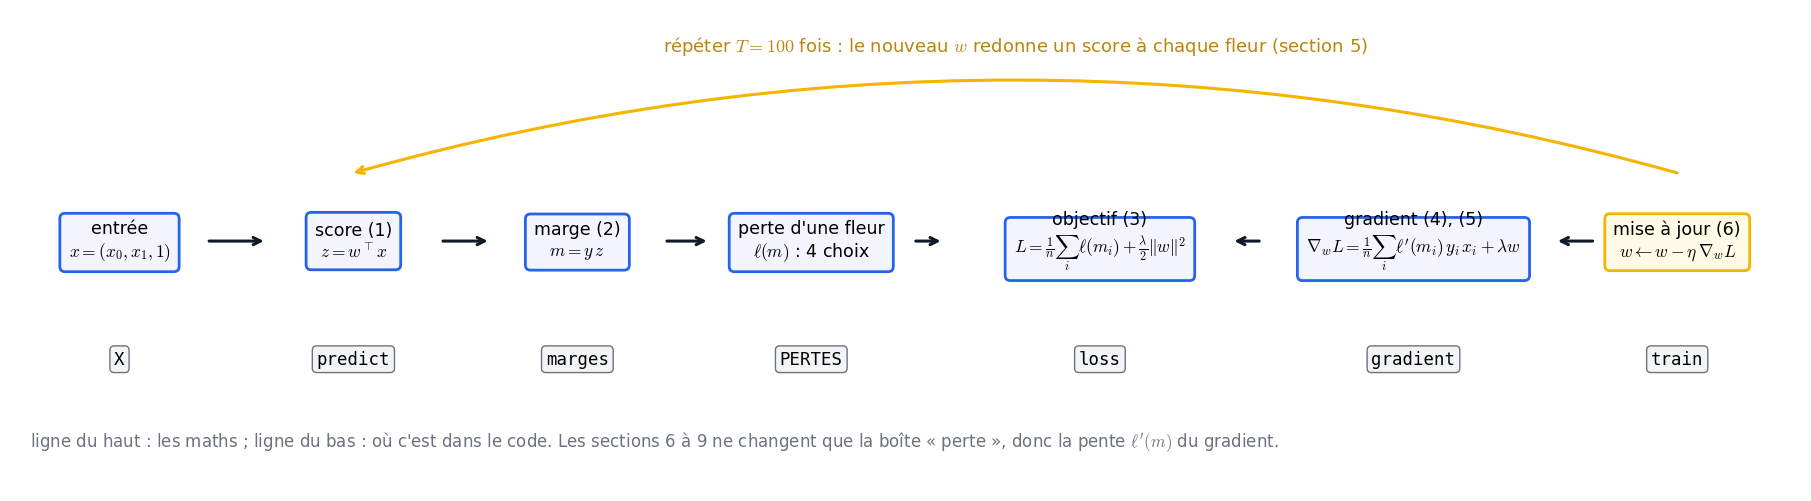

In [58]:
#@title Figure : la carte du labo, des entrées à la mise à jour de w. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
fig_carte()  # x -> z -> m -> l(m) -> L(w) -> grad L -> w <- w - eta grad L, avec le nom Python sous chaque boîte

### Retour aux quatre questions de l'orientation.

<table width="100%">
<tr><th align="left" width="28%">question</th><th align="left" width="72%">réponse en une phrase</th></tr>
<tr><td valign="top">1. Quel problème, quel modèle ?</td><td valign="top">Séparer deux catégories par une droite : trois nombres $w = (w_0, w_1, b)$, un score $z = w^\top x$ et son signe (section 0) ; le bon outil dès que les classes sont à peu près séparables par une droite, et toujours le premier à essayer (section 0.2).</td></tr>
<tr><td valign="top">2. Comment trouve-t-on $w$ ?</td><td valign="top">On remplace le taux d'erreur, sans pente, par une perte de remplacement $\ell(m)$, puis on descend l'objectif $L(w)$ par $w \leftarrow w - \eta\,\nabla_w L(w)$ (sections 2, 3, 5).</td></tr>
<tr><td valign="top">3. Pourquoi les quatre gradients ont la même forme ?</td><td valign="top">Parce que $w$ n'entre dans la perte que par $z = w^\top x$ : la règle de la chaîne donne $\nabla_w \ell = \ell'(m)\,y\,x$, un nombre fois $x$, quelle que soit $\ell$ (section 4).</td></tr>
<tr><td valign="top">4. Pourquoi quatre frontières différentes ?</td><td valign="top">Parce que ce nombre $\ell'(m)$ décide <i>qui</i> tire sur $w$ et avec quelle force : toutes les fleurs, les erreurs seules, la bande $m \lt 1$, ou chacune selon sa probabilité d'erreur (sections 6 à 9, démo F).</td></tr>
</table>

> **🧠 Vérifiez :** <details><summary>Deux étudiants entraînent un perceptron sur les mêmes fleurs depuis des points de départ différents. Même frontière ? Et avec un SVM ?</summary>Perceptron : non, chacun part de son $w^{(0)}$ et s'arrête sur la première droite sans erreur qu'il rencontre (démo H : un éventail de seize frontières). SVM avec $\lambda \gt 0$ : oui, à un demi-degré près. Son objectif est un bol à fond unique (convexe, démo S) : il n'a qu'un minimum, tous les chemins y mènent.</details>

> **🧠 Vérifiez :** <details><summary>Les quatre méthodes `gradient` ont la même forme : un nombre fois l'étiquette, fois l'entrée, moyenne sur les fleurs, plus la régularisation. Qu'est-ce qui change de l'une à l'autre ?</summary>Seulement le nombre, c'est-à-dire la pente $\ell'(m_i)$, la ligne `coef = …` : $m_i - 1$, $-\mathbb{1}\{m_i \lt 0\}$, $-\mathbb{1}\{m_i \lt 1\}$ ou $-\dfrac{1}{1 + e^{m_i}}$. La ligne suivante, celle de (5), est identique dans les quatre classes.</details>

## 11. Bonus : descente stochastique par mini-lots

### Promis à la section 5 : la version par petits lots, où le randonneur ne tâte la pente que d'un pied.

> **📖 Rappel de notation.** Jusqu'ici, chaque itération de (6), $w \leftarrow w - \eta\,\nabla_w L(w)$, utilise le gradient (5) calculé sur les $n = 75$ fleurs d'entraînement : $\nabla_w L = \frac1n\sum_{i=1}^{n} \ell'(m_i)\,y_i\,x_i + \lambda\,w$. On dit « par lot complet ». Nouveau symbole : $k$, la taille du mini-lot (`batch_size`).

### Vocabulaire : une **époque** est un passage complet sur les 75 fleurs d'entraînement. Jusqu'ici, une époque = une itération.

### Vocabulaire : « **stochastique** » veut dire que le gradient est calculé sur un échantillon tiré au hasard, le **mini-lot** $\mathcal{B}$ de $k$ fleurs, et non sur les 75.

### À chaque époque, on mélange les fleurs, on les découpe en mini-lots de $k$ fleurs, et on fait une itération par mini-lot.

$$w \leftarrow w - \eta\,\nabla_w L_{\mathcal{B}}(w), \qquad \nabla_w L_{\mathcal{B}}(w) = \frac{1}{k}\sum_{i \in \mathcal{B}} \ell'(m_i)\,y_i\,x_i + \lambda\,w$$

où $\mathcal{B}$ est le mini-lot courant ($k$ numéros de fleurs tirés au hasard), $\ell'(m_i)\,y_i\,x_i$ le gradient (4) de la fleur $i$, $\eta$ le pas et $\lambda$ la régularisation. C'est la formule (5) avec $k$ fleurs à la place de $n$ : en moyenne sur les tirages, $\nabla_w L_{\mathcal{B}}$ vaut $\nabla_w L$. Dans le code, c'est `model.gradient(X[lot], y[lot])` : la même méthode `gradient` qu'avant, appelée sur les $k$ lignes du mini-lot.

### Avec $k = 75$, une époque = une itération : c'est la descente de la section 5. Avec $k = 1$, une époque = 75 itérations. Même nombre de fleurs vues, beaucoup plus d'itérations.

### Le randonneur ne tâte plus la pente des deux pieds sur tout le versant : il la devine d'un pied, sur $k$ fleurs, et repart aussitôt. Chaque itération est moins sûre, mais il en fait 75 fois plus par époque.

### Le code qui suit : la même boucle que `train`, mais le gradient de chaque itération est calculé sur `batch_size` $= k$ fleurs tirées au hasard, et $L(w)$ et $\mathrm{Err}(w)$ sont mesurés sur les 75 fleurs à la fin de chaque époque.

In [59]:
#@title Code : la descente par mini-lots. Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
def train_sgd(model, data, stepsize, n_epochs, batch_size, graine=0):
    """Descente de gradient par mini-lots de taille batch_size = k. Retourne les objectifs L(w) et les erreurs Err(w)
    mesurés sur toutes les données à la fin de chaque époque."""
    rng = np.random.RandomState(graine)  # générateur local (ne touche pas la graine globale)
    X, y = data[:, :-1], data[:, -1]  # entrées (avec la colonne de 1) et étiquettes
    n = len(y)  # nombre de fleurs
    losses, errors = [], []  # mesures par époque
    for epoque in range(n_epochs):  # une époque = un passage complet sur les n fleurs
        ordre = rng.permutation(n)  # nouvel ordre aléatoire à chaque époque
        for debut in range(0, n, batch_size):  # on parcourt les fleurs par tranches de k
            lot = ordre[debut:debut + batch_size]  # numéros des fleurs du mini-lot (l'ensemble B de la formule)
            model.w = model.w - stepsize * model.gradient(X[lot], y[lot])  # une itération : w <- w - eta grad L_B(w)
        losses.append(model.loss(X, y))  # objectif L(w) sur les n fleurs, en fin d'époque
        errors.append(model.error_rate(X, y))  # erreur Err(w) sur les n fleurs, en fin d'époque
    return np.array(losses), np.array(errors)  # deux tableaux de longueur n_epochs

## 11.1 Démo K : la taille du mini-lot

> **📊** À gauche : l'objectif $L(w)$ sur les 75 fleurs (échelle log) à la fin de chaque époque, une courbe par taille de mini-lot $k$ : violet ($k = 1$), sarcelle ($k = 5$), vert ($k = 25$) et noir ($k = 75$, la descente par lot complet de la section 5). Pour la régression linéaire, le pointillé or est le minimum exact $L(w^*)$ de la démo E. Une courbe qui dépasse $10^3$ est coupée : la descente diverge.

> **📊** À droite : le taux d'erreur d'entraînement $\mathrm{Err}(w)$ à la fin de chaque époque, mêmes couleurs. Les quatre courbes ont vu les mêmes fleurs le même nombre de fois ; seul le nombre d'itérations par époque change.

### Les curseurs : le menu « modèle » choisit la perte $\ell$ (et ses réglages $\lambda$ de sa section) ; $k$ est la taille du mini-lot mise en évidence (trait épais, les trois autres restent tracées) ; $\eta$ règle le pas de (6), le même pour les quatre $k$. (Le code de la démo : la fonction `demo_K` de la boîte à outils ; l'entraînement lui-même est `train_sgd`, ci-dessus.)

> **🔮 Avant de bouger le curseur, prédisez :** À nombre d'époques égal, un mini-lot de $k = 1$ fleur descendra-t-il plus vite ou moins vite qu'un lot de $k = 75$ ? Sa courbe sera-t-elle aussi lisse ? Et si on monte le pas $\eta$ à 0.5, puis à 1 ?

In [60]:
#@title Démo K : la taille du mini-lot (curseurs). Cliquez sur « Afficher le code » pour le lire. { display-mode: "form" }
demo_K()  # la taille du mini-lot k

Modèles disponibles : régression linéaire, SVM, régression logistique.


> **🧠 Vérifiez votre prédiction :** <details><summary>Cliquez après avoir joué avec le curseur.</summary>Beaucoup plus vite : à $\eta = 0.05$, $k = 1$ est à $L = 0.06$ dès la sixième époque, alors que $k = 75$ est encore à $L = 0.82$ après trente. Mais sa courbe est bruitée (elle tremble), et si le pas reste fixe elle plafonne au-dessus du minimum : à $\eta = 0.5$, $k = 1$ oscille entre $0.06$ et $0.7$, autour de $0.10$, alors que $L(w^*) = 0.054$. À $\eta = 1$ (au-delà du seuil $2/\mu_{\max} \approx 0.96$ de la démo E), $k = 1$ diverge dès la première époque et $k = 75$ monte lentement ($L = 45$ après trente époques).</details>

## 12. Conclusion : trois questions

### 1. La perte du perceptron n'est presque plus utilisée. Pourquoi ?

> **🧠 Indice :** <details><summary>Trois défauts, un par démo.</summary>Démo C (échelle 0.1) : sa perte vaut 0 en $w = 0$, donc on ne peut pas la régulariser sans tout écraser. Démo H : elle s'arrête sur n'importe quelle frontière sans erreur, sans chercher de bande de marge. Démo F (versicolor contre virginica) : sans séparabilité, elle ne converge pas. Et elle ne donne pas de probabilités.</details>

### 2. SVM contre perceptron : que change la régularisation ? Que change le point de départ $w^{(0)}$ ?

> **🧠 Indice :** <details><summary>Regardez qui tire, et combien de minimums.</summary>La charnière tire tant que $m \lt 1$ et l'élastique $\lambda$ empêche $w$ de grandir : la bande de marge la plus large possible, un seul minimum (démo G), donc le même point d'arrivée quel que soit $w^{(0)}$ (démo H). Le perceptron ne tire que sur les erreurs : dès 0 % d'erreur il s'arrête, où qu'il soit, et chaque $w^{(0)}$ donne sa frontière.</details>

### 3. Pourquoi préférer des mini-lots à un lot complet ?

> **🧠 Indice :** <details><summary>Comptez les itérations par époque dans la démo K.</summary>Une itération par lot complet coûte un passage sur toutes les données ; avec $k$ fleurs, elle coûte $k/n$ fois moins et donne, en moyenne, la bonne direction : pour le même calcul, on fait $n/k$ fois plus d'itérations et on descend bien plus vite, au prix d'une courbe bruitée (démo K).</details>

### Pont vers demain : tout était linéaire en $x$. Demain, on remplace $x$ par $\phi(x)$, qu'on choisit (polynômes), qu'on apprend (réseaux de neurones) ou qu'on ne calcule jamais (noyau). Les vecteurs de support de la démo G sont la porte d'entrée du noyau.

## Sources

Toute affirmation de ce notebook qui n'est pas une définition ou un calcul fait ici renvoie à l'une des références suivantes. Les chiffres (taux d'erreur, poids, marges) viennent des cellules de code.

**Données**
* Fisher, R. A. (1936). The use of multiple measurements in taxonomic problems. *Annals of Eugenics*, 7(2), 179-188. https://doi.org/10.1111/j.1469-1809.1936.tb02137.x

**Quand un classifieur linéaire convient**
* Cover, T. M. (1965). Geometrical and statistical properties of systems of linear inequalities with applications in pattern recognition. *IEEE Transactions on Electronic Computers*, EC-14(3), 326-334. https://doi.org/10.1109/PGEC.1965.264137
* Joachims, T. (1998). Text categorization with support vector machines: learning with many relevant features. *ECML-98*, LNCS 1398, 137-142. https://doi.org/10.1007/BFb0026683 (version de l'auteur : https://www.cs.cornell.edu/~tj/publications/joachims_98a.pdf)
* Sahami, M., Dumais, S., Heckerman, D. et Horvitz, E. (1998). A Bayesian approach to filtering junk e-mail. *AAAI Workshop on Learning for Text Categorization*, WS-98-05. https://cdn.aaai.org/Workshops/1998/WS-98-05/WS98-05-009.pdf
* Christodoulou, E., Ma, J., Collins, G. S., Steyerberg, E. W., Verbakel, J. Y. et Van Calster, B. (2019). A systematic review shows no performance benefit of machine learning over logistic regression for clinical prediction models. *Journal of Clinical Epidemiology*, 110, 12-22. https://doi.org/10.1016/j.jclinepi.2019.02.004
* Holte, R. C. (1993). Very simple classification rules perform well on most commonly used datasets. *Machine Learning*, 11, 63-91. https://doi.org/10.1023/A:1022631118932
* Minsky, M. et Papert, S. (1969). *Perceptrons*. MIT Press. https://mitpress.mit.edu/9780262630221/perceptrons/

**Pertes, gradients, optimisation**
* Bartlett, P. L., Jordan, M. I. et McAuliffe, J. D. (2006). Convexity, classification, and risk bounds. *Journal of the American Statistical Association*, 101(473), 138-156. https://doi.org/10.1198/016214505000000907
* Ben-David, S., Eiron, N. et Long, P. M. (2003). On the difficulty of approximately maximizing agreements. *Journal of Computer and System Sciences*, 66(3), 496-514. Version COLT 2000 : https://www.learningtheory.org/colt2000/papers/BenDavidEironLong.pdf
* Boyd, S. et Vandenberghe, L. (2004). *Convex Optimization*. Cambridge University Press, sections 4.2 et 9.3. https://web.stanford.edu/~boyd/cvxbook/
* Bottou, L. (2010). Large-scale machine learning with stochastic gradient descent. *COMPSTAT 2010*, 177-186. https://doi.org/10.1007/978-3-7908-2604-3_16

**Les quatre modèles**
* Rosenblatt, F. (1958). The perceptron: a probabilistic model for information storage and organization in the brain. *Psychological Review*, 65(6), 386-408. https://doi.org/10.1037/h0042519
* Novikoff, A. B. J. (1962). On convergence proofs for perceptrons. *Symposium on the Mathematical Theory of Automata*, 12, 615-622. Exposé dans Bishop (2006), section 4.1.7.
* Cortes, C. et Vapnik, V. (1995). Support-vector networks. *Machine Learning*, 20, 273-297. https://doi.org/10.1007/BF00994018
* Burges, C. J. C. (1998). A tutorial on support vector machines for pattern recognition. *Data Mining and Knowledge Discovery*, 2, 121-167. https://doi.org/10.1023/A:1009715923555
* Bishop, C. M. (2006). *Pattern Recognition and Machine Learning*. Springer, sections 4.1.3, 4.1.7 et figure 4.4. https://www.microsoft.com/en-us/research/publication/pattern-recognition-machine-learning/
* Hastie, T., Tibshirani, R. et Friedman, J. (2009). *The Elements of Statistical Learning*, 2e éd. Springer, sections 3.4 et 4.4. https://hastie.su.domains/ElemStatLearn/

**Outils**
* ipywidgets : https://ipywidgets.readthedocs.io ; `numpy.logaddexp` : https://numpy.org/doc/stable/reference/generated/numpy.logaddexp.html